In [86]:
# !wget https://github.com/rdfia/rdfia.github.io/raw/master/data/2-ab.zip
# !unzip -j 2-ab.zip
# !wget https://github.com/rdfia/rdfia.github.io/raw/master/code/2-ab/utils-data.py

In [87]:
import matplotlib.pyplot as plt
import numpy as np
import torch

%run 'utils-data.py'

# Part 1 : Forward and backward passes "by hands"

In [88]:
def init_params(nx, nh, ny):
    """
    nx, nh, ny: integers
    out params: dictionnary
    """
    params = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for Wh, Wy, bh, by

    params["Wh"] = torch.randn(nh, nx) * 0.3
    params["Wy"] = torch.randn(ny, nh) * 0.3
    params["bh"] = torch.zeros(nh)
    params["by"] = torch.zeros(ny)

    ####################
    ##      END        #
    ####################
    return params

In [89]:
def forward(params, X):
    """
    params: dictionnary
    X: (n_batch, dimension)
    """
    bsize = X.size(0)
    nh = params["Wh"].size(0)
    ny = params["Wy"].size(0)
    outputs = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for X, htilde, h, ytilde, yhat

    outputs["X"] = X
    outputs["htilde"] = torch.mm(X, params["Wh"].t()) + params["bh"]
    outputs["h"] = torch.tanh(outputs["htilde"])
    outputs["ytilde"] = torch.mm(outputs["h"], params["Wy"].t()) + params["by"]
    outputs["yhat"] = torch.softmax(outputs["ytilde"], dim=1)

    ####################
    ##      END        #
    ####################

    return outputs["yhat"], outputs

In [90]:
def loss_accuracy(Yhat, Y):

    #####################
    ## Your code here  ##
    #####################

    L = 0
    acc = 0

    L = -torch.mean(torch.sum(Y * torch.log(Yhat), dim=1))  # cross-entropy

    _, indsY = torch.max(Y, 1)
    _, indsYhat = torch.max(Yhat, 1)

    acc = torch.mean((indsYhat == indsY).float())

    ####################
    ##      END        #
    ####################

    return L, acc

In [91]:
def backward(params, outputs, Y):
    bsize = Y.shape[0]
    grads = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for Wy, Wh, by, bh

    grads["Wy"] = None
    grads["Wh"] = None
    grads["by"] = None
    grads["bh"] = None

    grad_ytilde = (outputs["yhat"] - Y) / bsize

    grads["Wy"] = torch.mm(grad_ytilde.t(), outputs["h"])
    grads["by"] = torch.sum(grad_ytilde, dim=0)

    grad_h = torch.mm(grad_ytilde, params["Wy"])
    grad_htilde = grad_h * (1 - outputs["h"] ** 2)

    grads["Wh"] = torch.mm(grad_htilde.t(), outputs["X"])
    grads["bh"] = torch.sum(grad_htilde, dim=0)

    ####################
    ##      END        #
    ####################
    return grads

In [92]:
def sgd(params, grads, eta):

    #####################
    ## Your code here  ##
    #####################
    # update the params values

    params["Wh"] = params["Wh"] - eta * grads["Wh"]
    params["Wy"] = params["Wy"] - eta * grads["Wy"]
    params["bh"] = params["bh"] - eta * grads["bh"]
    params["by"] = params["by"] - eta * grads["by"]

    ####################
    ##      END        #
    ####################
    return params

## Global learning procedure "by hands"

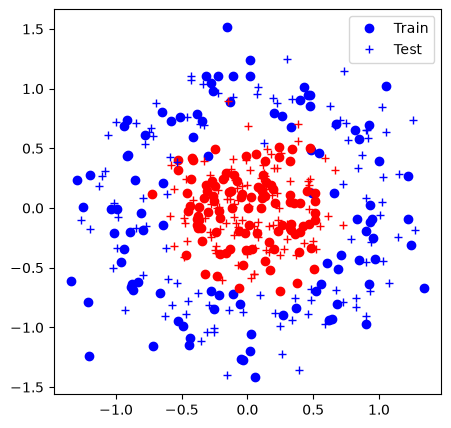

Iter 0: Acc train 0.5% (0.70), acc test 0.5% (0.71)


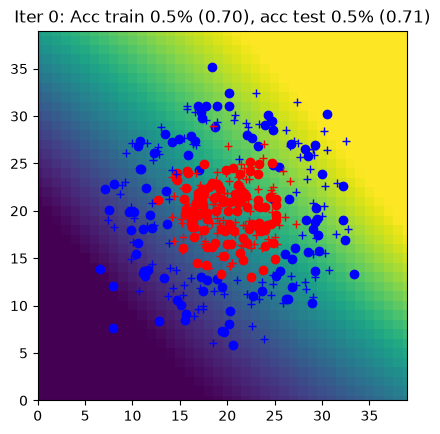

Iter 1: Acc train 0.5% (0.70), acc test 0.5% (0.70)


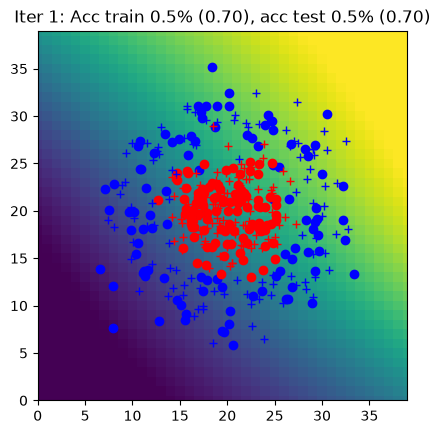

Iter 2: Acc train 0.5% (0.70), acc test 0.6% (0.70)


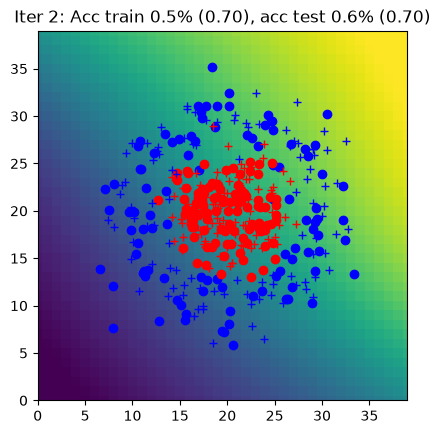

Iter 3: Acc train 0.6% (0.69), acc test 0.6% (0.70)


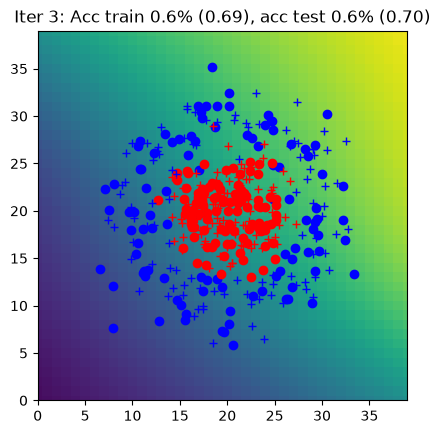

Iter 4: Acc train 0.6% (0.69), acc test 0.6% (0.69)


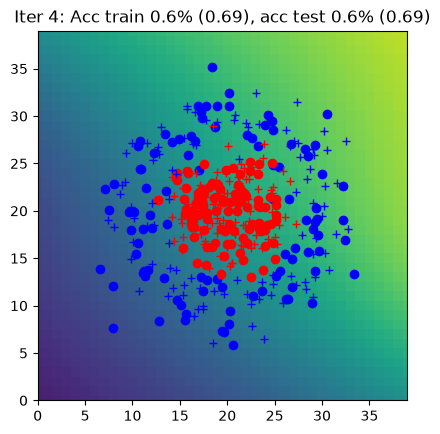

Iter 5: Acc train 0.5% (0.69), acc test 0.5% (0.69)


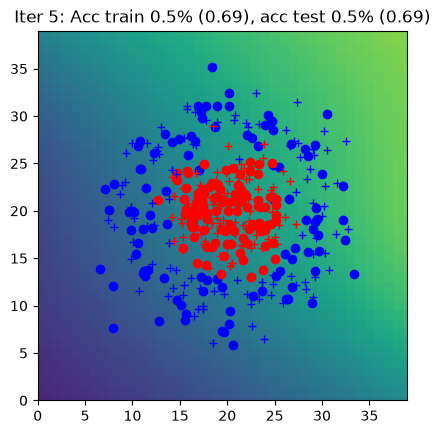

Iter 6: Acc train 0.5% (0.69), acc test 0.6% (0.69)


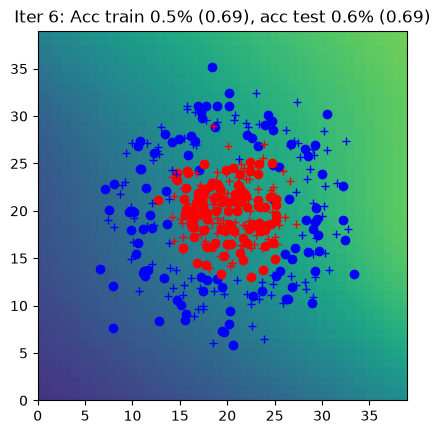

Iter 7: Acc train 0.6% (0.69), acc test 0.6% (0.69)


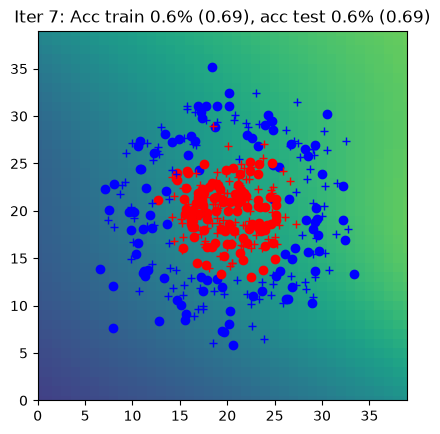

Iter 8: Acc train 0.6% (0.69), acc test 0.6% (0.69)


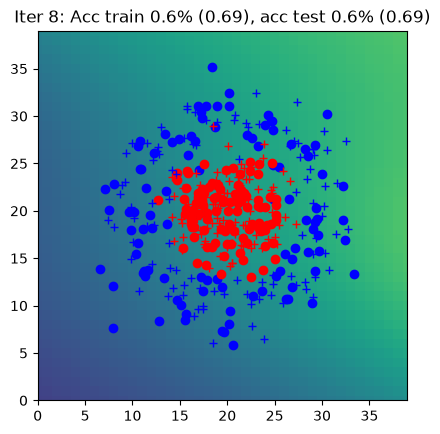

Iter 9: Acc train 0.6% (0.69), acc test 0.7% (0.69)


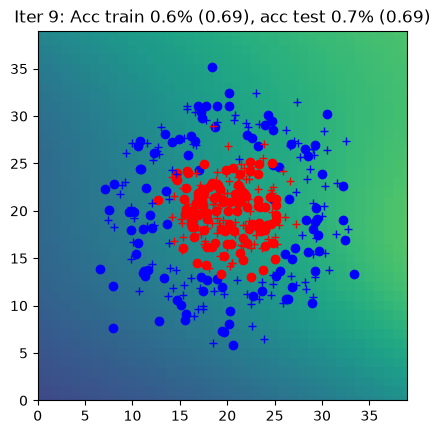

Iter 10: Acc train 0.7% (0.69), acc test 0.7% (0.69)


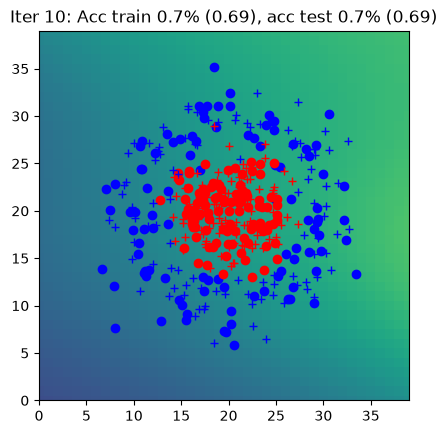

Iter 11: Acc train 0.7% (0.69), acc test 0.7% (0.69)


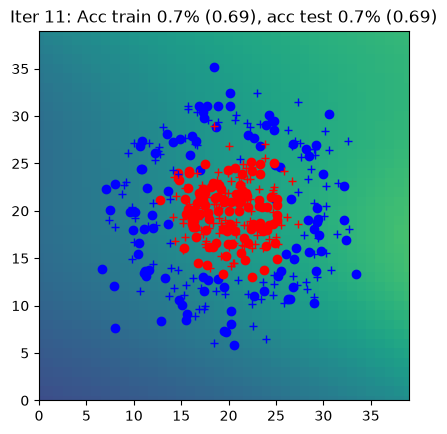

Iter 12: Acc train 0.6% (0.69), acc test 0.6% (0.69)


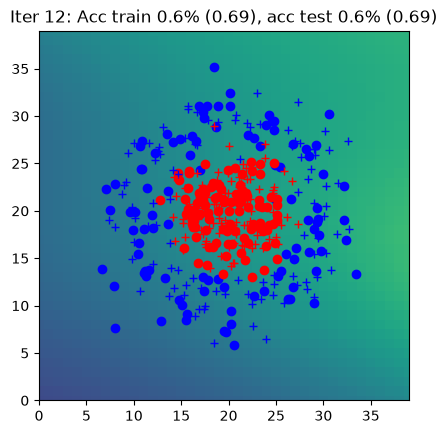

Iter 13: Acc train 0.6% (0.69), acc test 0.6% (0.69)


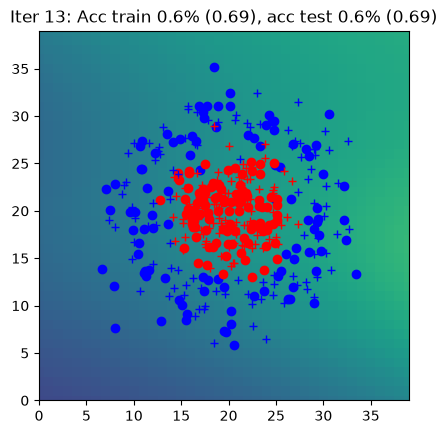

Iter 14: Acc train 0.6% (0.69), acc test 0.6% (0.69)


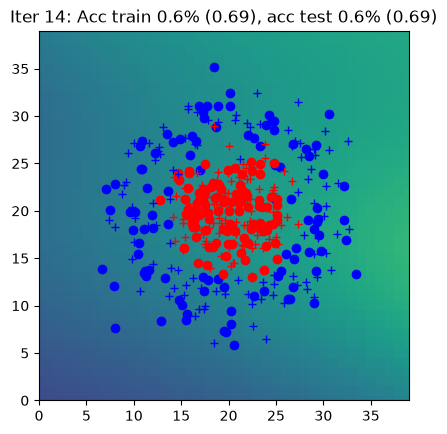

Iter 15: Acc train 0.7% (0.68), acc test 0.7% (0.69)


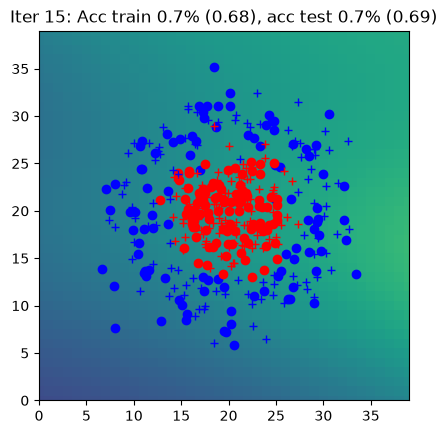

Iter 16: Acc train 0.7% (0.68), acc test 0.7% (0.69)


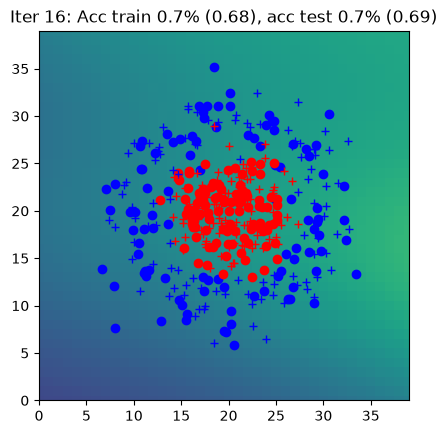

Iter 17: Acc train 0.7% (0.68), acc test 0.7% (0.68)


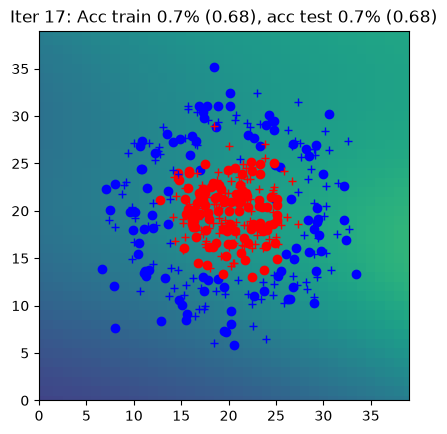

Iter 18: Acc train 0.7% (0.68), acc test 0.7% (0.68)


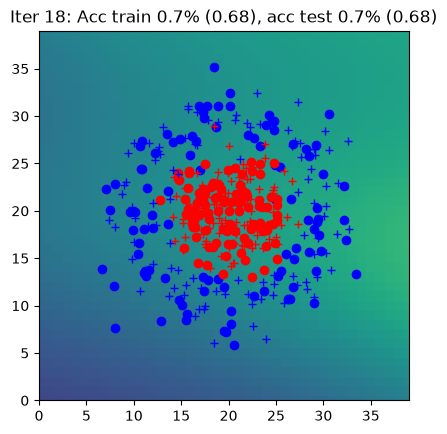

Iter 19: Acc train 0.7% (0.68), acc test 0.7% (0.68)


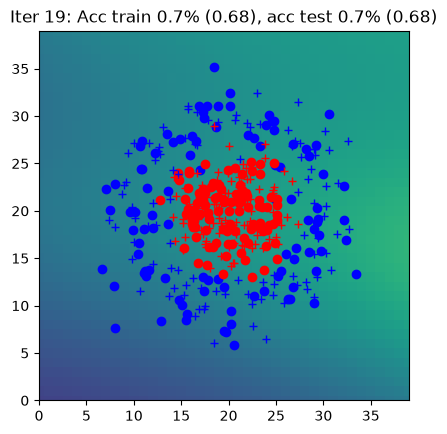

Iter 20: Acc train 0.7% (0.68), acc test 0.7% (0.68)


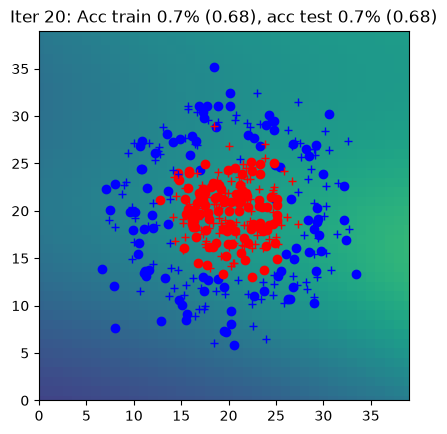

Iter 21: Acc train 0.8% (0.68), acc test 0.8% (0.68)


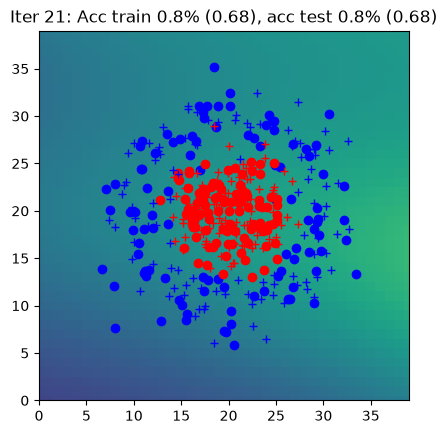

Iter 22: Acc train 0.8% (0.68), acc test 0.8% (0.68)


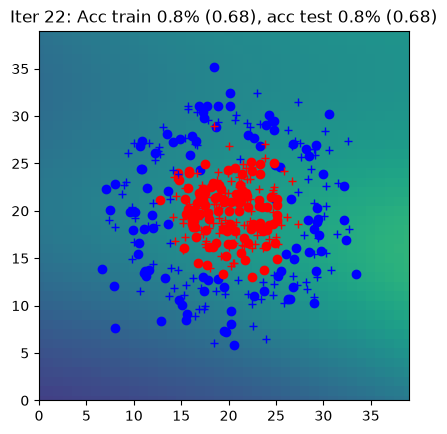

Iter 23: Acc train 0.8% (0.68), acc test 0.8% (0.68)


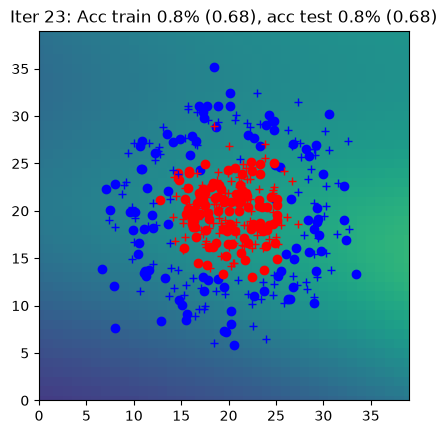

Iter 24: Acc train 0.7% (0.68), acc test 0.7% (0.68)


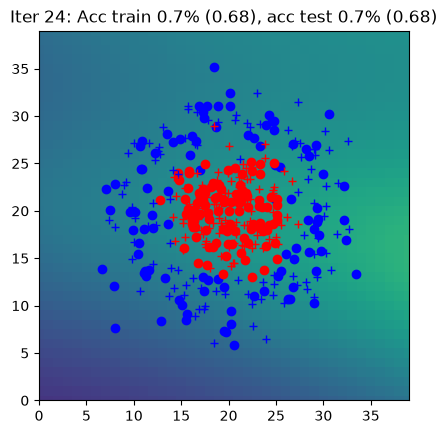

Iter 25: Acc train 0.8% (0.68), acc test 0.8% (0.68)


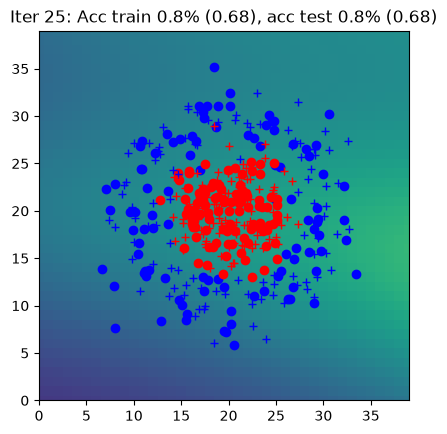

Iter 26: Acc train 0.8% (0.67), acc test 0.8% (0.68)


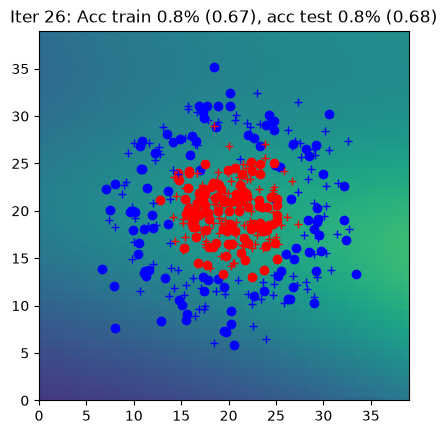

Iter 27: Acc train 0.8% (0.67), acc test 0.7% (0.67)


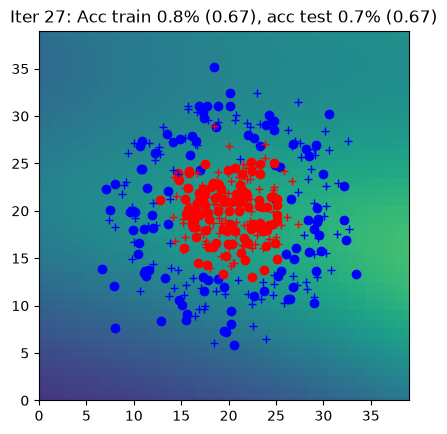

Iter 28: Acc train 0.8% (0.67), acc test 0.8% (0.67)


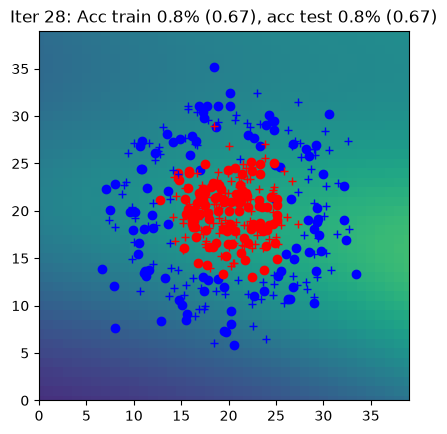

Iter 29: Acc train 0.8% (0.67), acc test 0.7% (0.67)


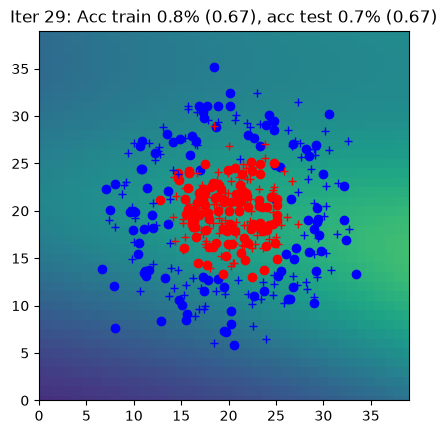

Iter 30: Acc train 0.8% (0.67), acc test 0.8% (0.67)


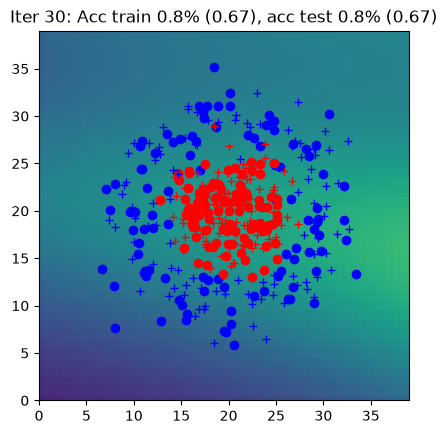

Iter 31: Acc train 0.8% (0.67), acc test 0.8% (0.67)


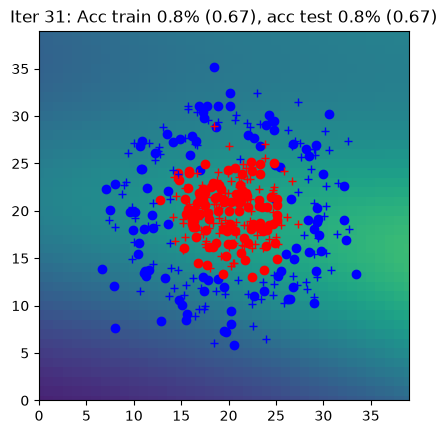

Iter 32: Acc train 0.8% (0.67), acc test 0.8% (0.67)


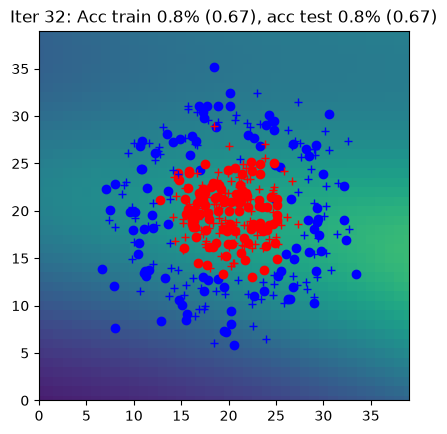

Iter 33: Acc train 0.8% (0.66), acc test 0.7% (0.67)


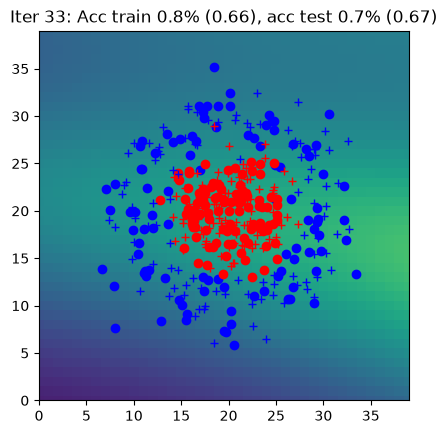

Iter 34: Acc train 0.8% (0.66), acc test 0.8% (0.66)


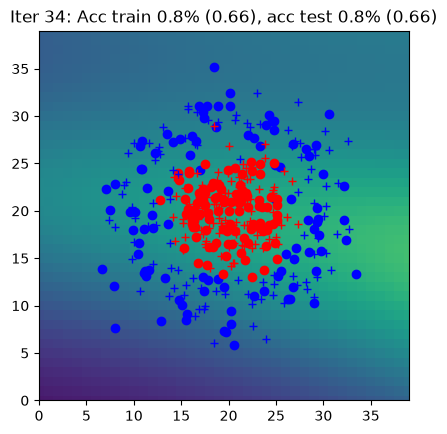

Iter 35: Acc train 0.8% (0.66), acc test 0.8% (0.66)


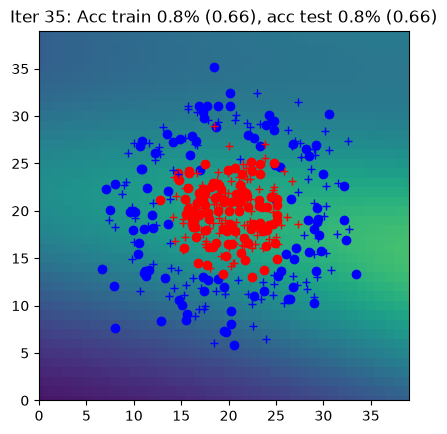

Iter 36: Acc train 0.8% (0.66), acc test 0.8% (0.66)


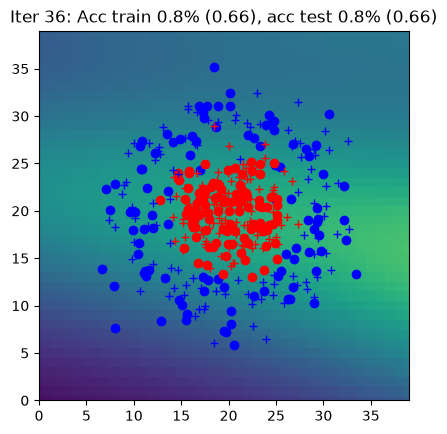

Iter 37: Acc train 0.8% (0.66), acc test 0.8% (0.66)


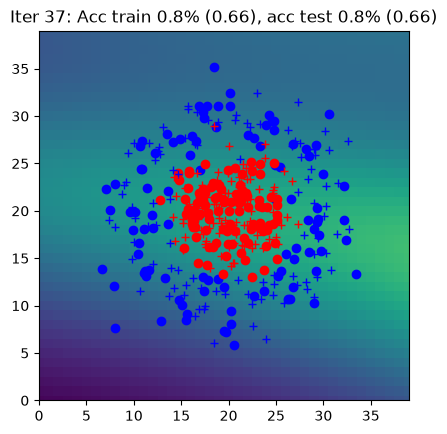

Iter 38: Acc train 0.8% (0.65), acc test 0.8% (0.66)


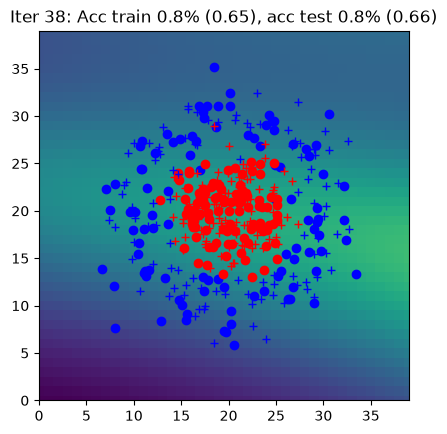

Iter 39: Acc train 0.8% (0.65), acc test 0.8% (0.65)


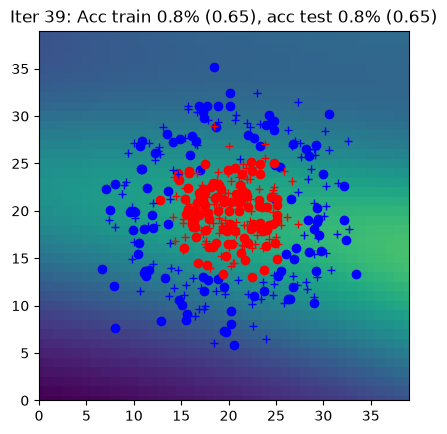

Iter 40: Acc train 0.8% (0.65), acc test 0.8% (0.65)


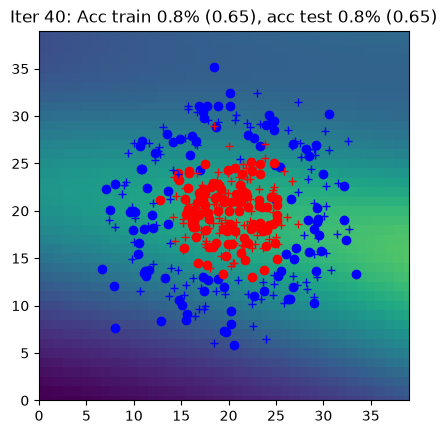

Iter 41: Acc train 0.8% (0.65), acc test 0.8% (0.65)


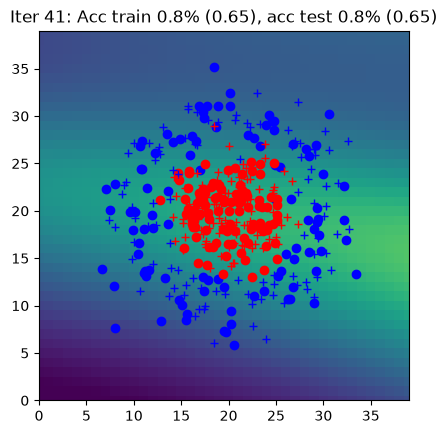

Iter 42: Acc train 0.8% (0.64), acc test 0.8% (0.65)


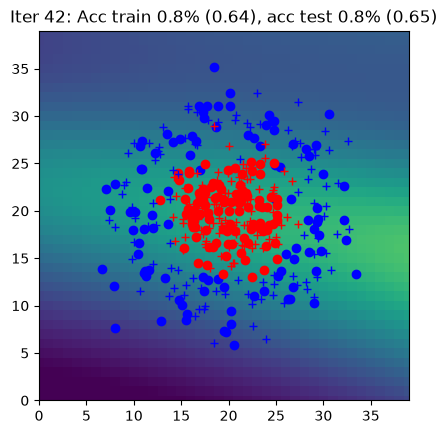

Iter 43: Acc train 0.8% (0.64), acc test 0.8% (0.64)


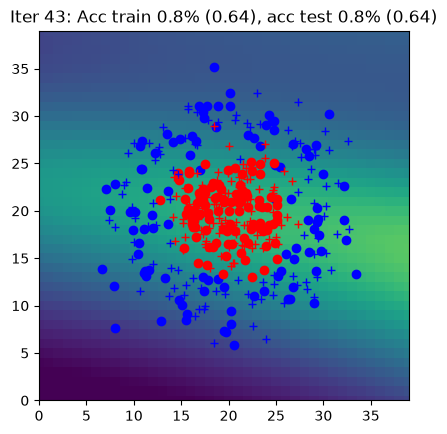

Iter 44: Acc train 0.8% (0.64), acc test 0.8% (0.64)


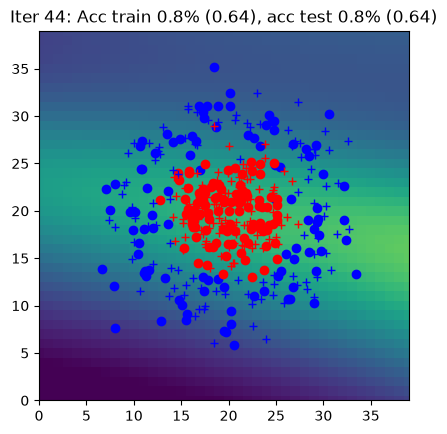

Iter 45: Acc train 0.8% (0.64), acc test 0.8% (0.64)


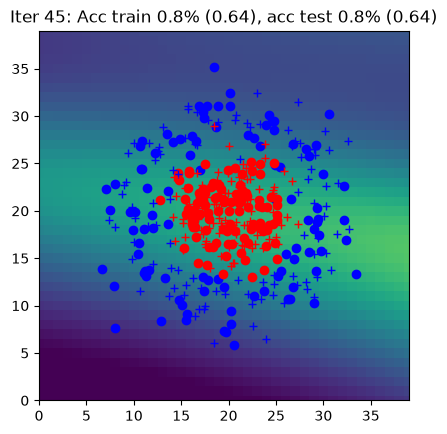

Iter 46: Acc train 0.8% (0.63), acc test 0.8% (0.64)


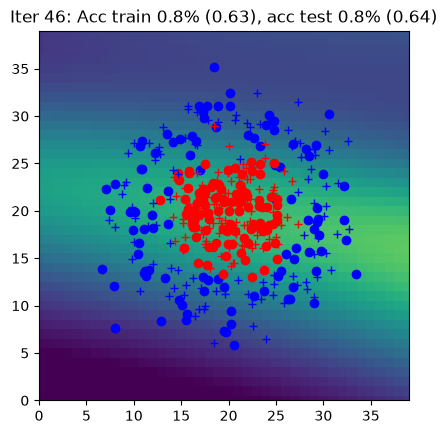

Iter 47: Acc train 0.8% (0.63), acc test 0.8% (0.63)


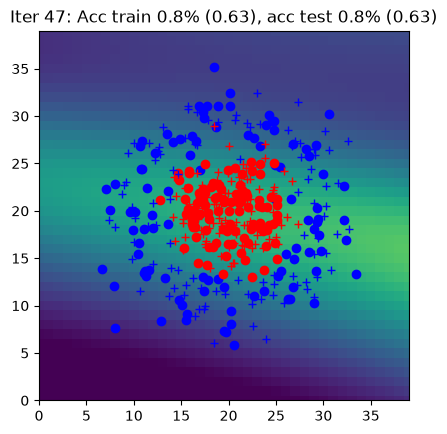

Iter 48: Acc train 0.8% (0.63), acc test 0.8% (0.63)


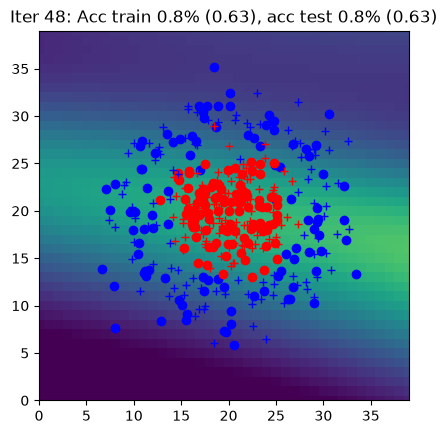

Iter 49: Acc train 0.8% (0.62), acc test 0.8% (0.63)


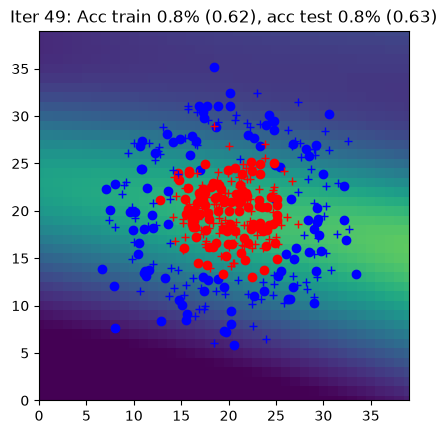

Iter 50: Acc train 0.8% (0.62), acc test 0.8% (0.62)


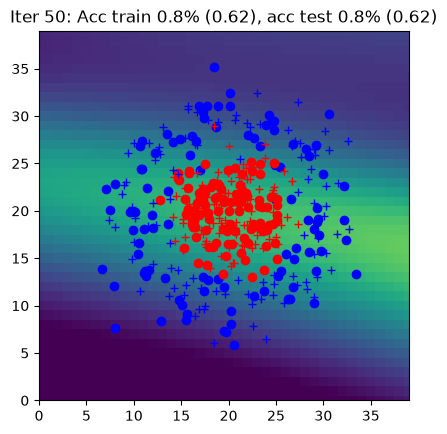

Iter 51: Acc train 0.8% (0.62), acc test 0.8% (0.62)


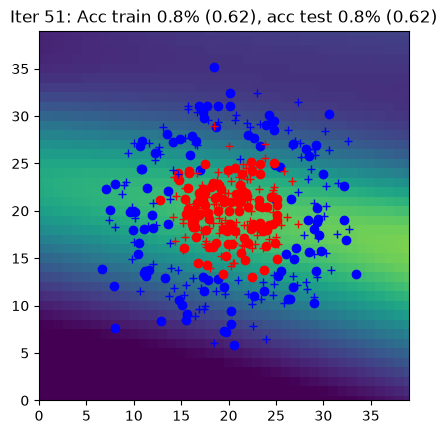

Iter 52: Acc train 0.8% (0.61), acc test 0.8% (0.62)


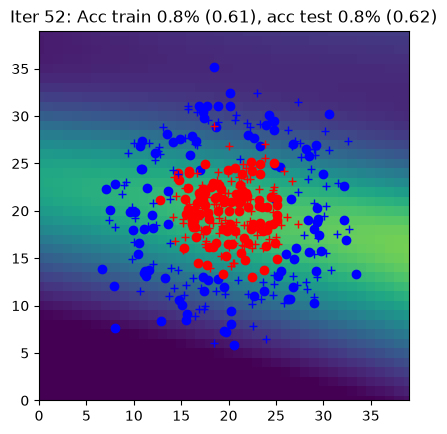

Iter 53: Acc train 0.8% (0.61), acc test 0.8% (0.61)


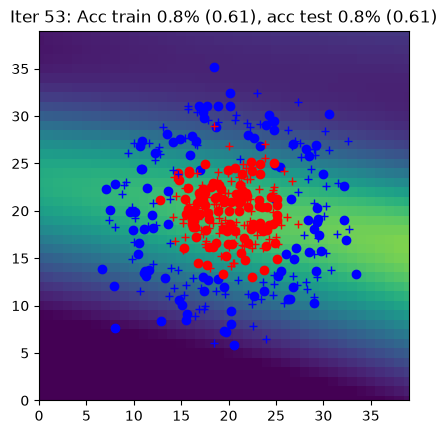

Iter 54: Acc train 0.8% (0.61), acc test 0.8% (0.61)


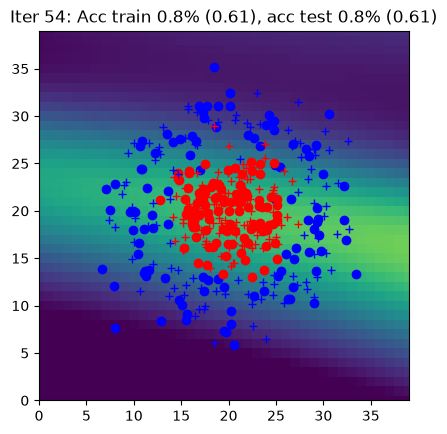

Iter 55: Acc train 0.8% (0.60), acc test 0.8% (0.61)


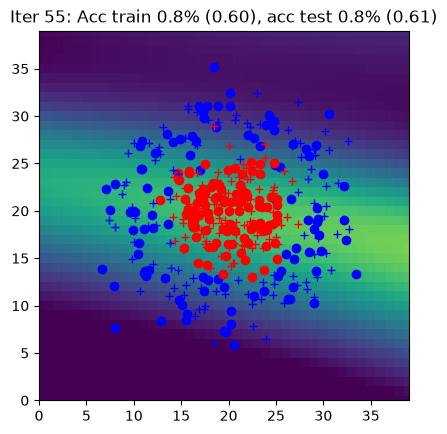

Iter 56: Acc train 0.8% (0.60), acc test 0.8% (0.61)


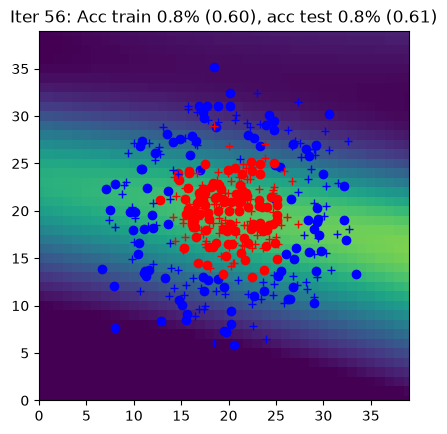

Iter 57: Acc train 0.8% (0.60), acc test 0.8% (0.60)


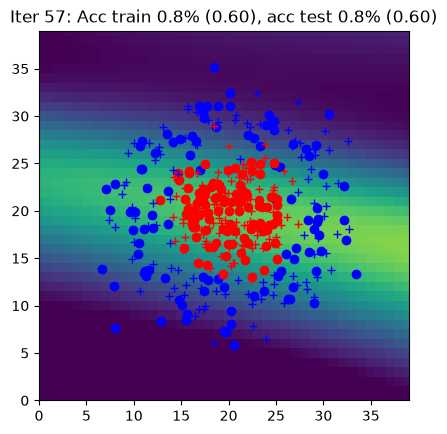

Iter 58: Acc train 0.8% (0.59), acc test 0.8% (0.60)


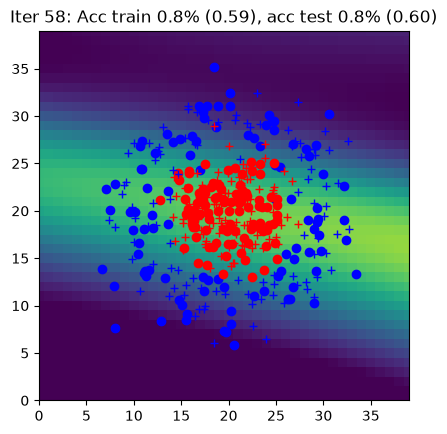

Iter 59: Acc train 0.8% (0.59), acc test 0.8% (0.59)


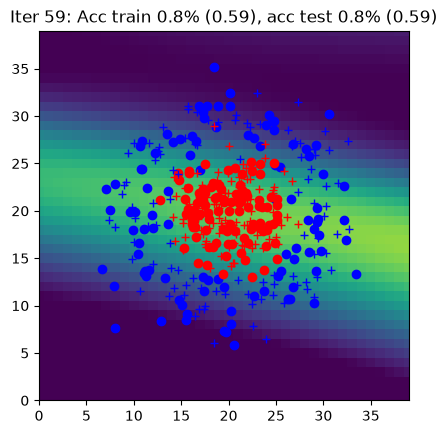

Iter 60: Acc train 0.8% (0.59), acc test 0.8% (0.59)


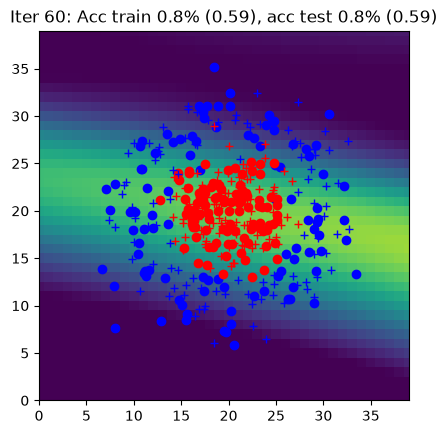

Iter 61: Acc train 0.8% (0.58), acc test 0.8% (0.59)


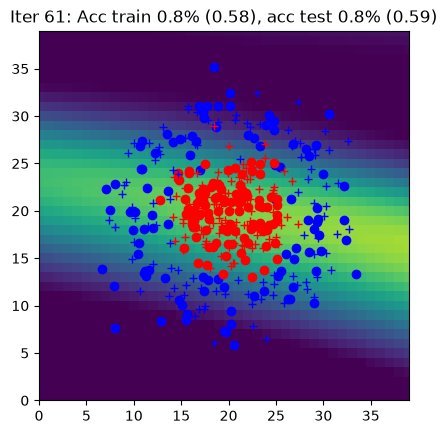

Iter 62: Acc train 0.8% (0.58), acc test 0.8% (0.58)


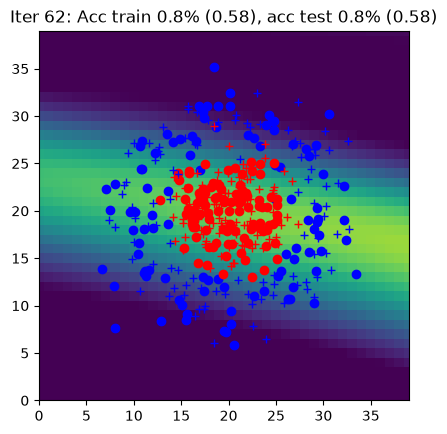

Iter 63: Acc train 0.8% (0.58), acc test 0.8% (0.58)


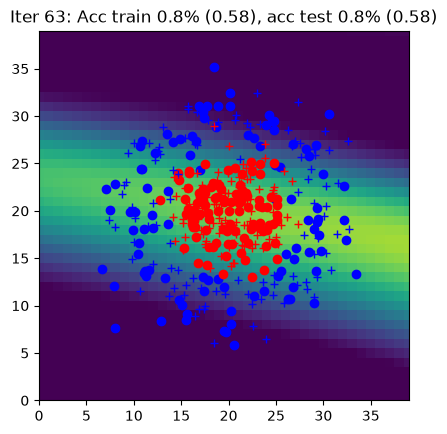

Iter 64: Acc train 0.8% (0.57), acc test 0.8% (0.58)


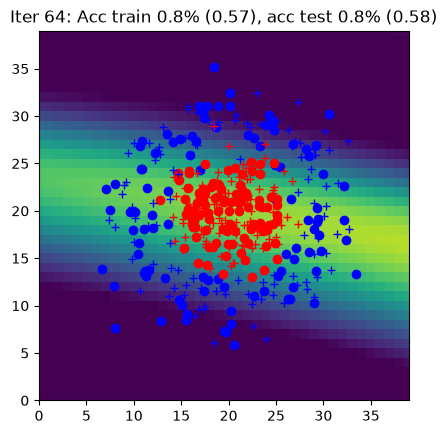

Iter 65: Acc train 0.8% (0.57), acc test 0.8% (0.57)


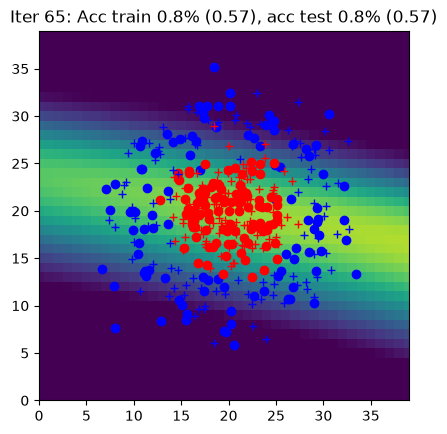

Iter 66: Acc train 0.8% (0.57), acc test 0.8% (0.57)


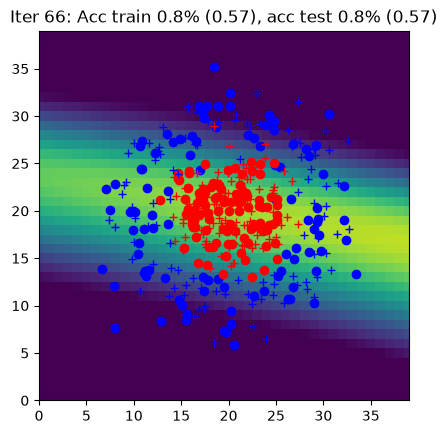

Iter 67: Acc train 0.8% (0.56), acc test 0.8% (0.57)


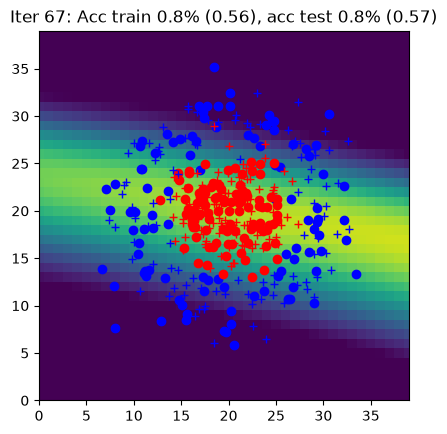

Iter 68: Acc train 0.8% (0.56), acc test 0.8% (0.56)


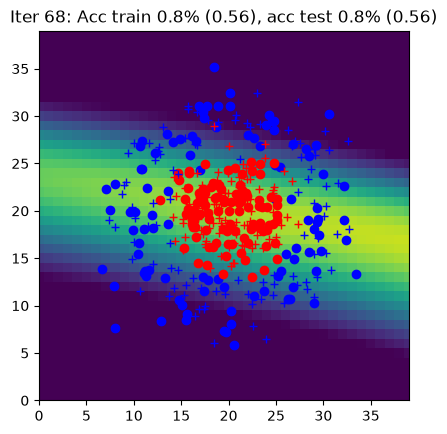

Iter 69: Acc train 0.8% (0.56), acc test 0.8% (0.56)


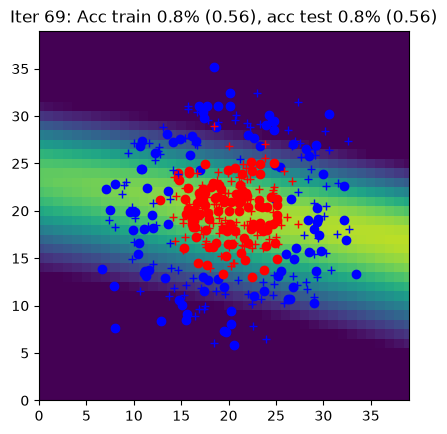

Iter 70: Acc train 0.8% (0.55), acc test 0.8% (0.56)


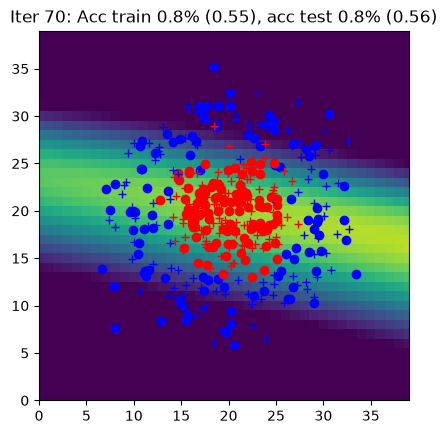

Iter 71: Acc train 0.8% (0.55), acc test 0.8% (0.56)


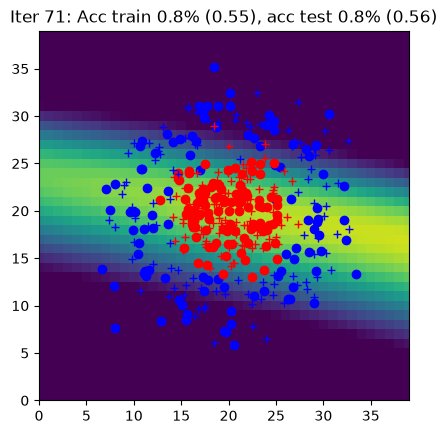

Iter 72: Acc train 0.8% (0.55), acc test 0.8% (0.55)


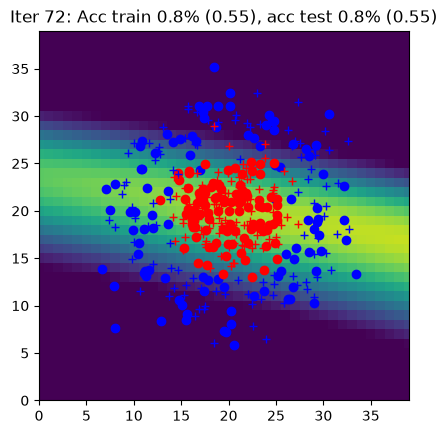

Iter 73: Acc train 0.8% (0.54), acc test 0.8% (0.55)


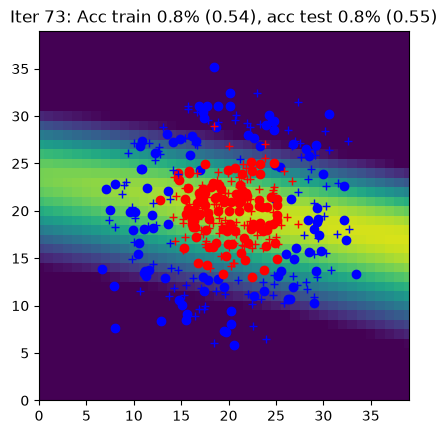

Iter 74: Acc train 0.8% (0.54), acc test 0.8% (0.55)


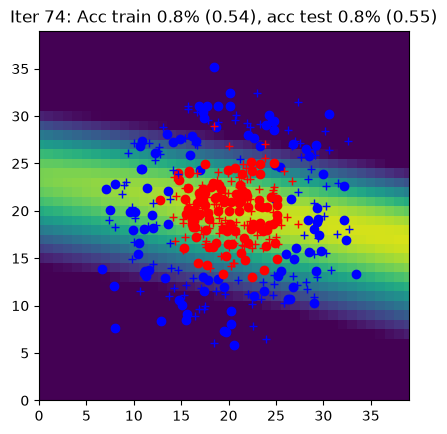

Iter 75: Acc train 0.8% (0.54), acc test 0.8% (0.54)


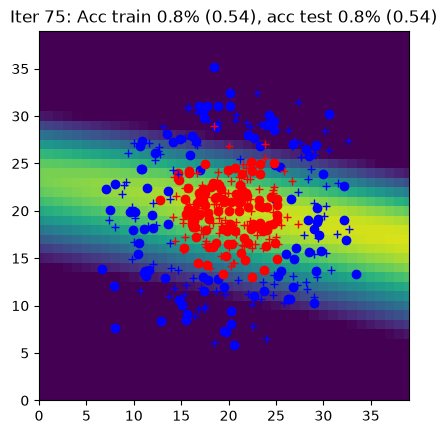

Iter 76: Acc train 0.8% (0.54), acc test 0.8% (0.54)


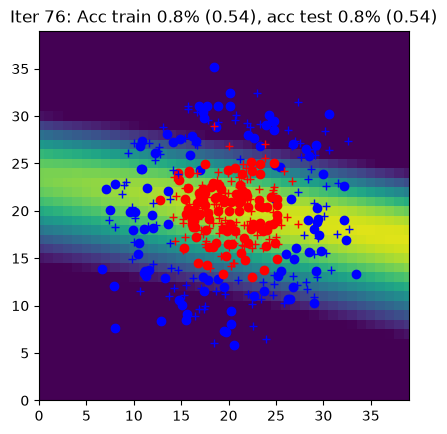

Iter 77: Acc train 0.8% (0.53), acc test 0.8% (0.54)


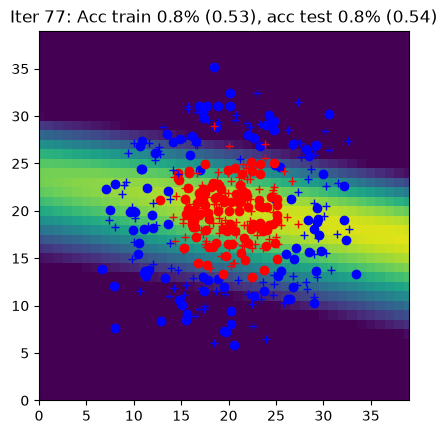

Iter 78: Acc train 0.8% (0.53), acc test 0.8% (0.54)


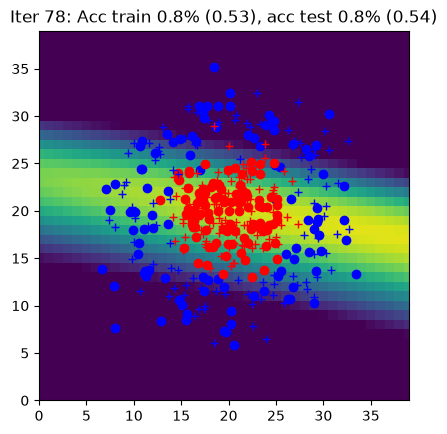

Iter 79: Acc train 0.8% (0.53), acc test 0.8% (0.53)


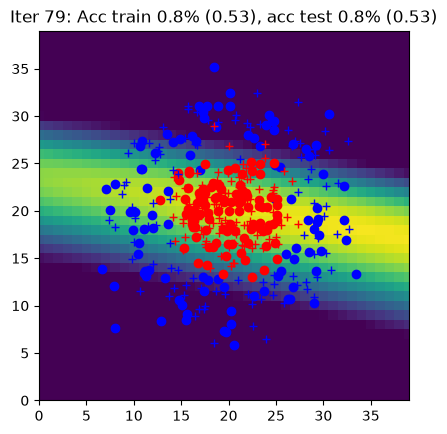

Iter 80: Acc train 0.8% (0.53), acc test 0.8% (0.53)


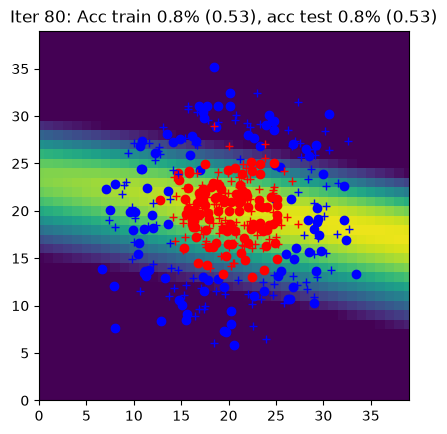

Iter 81: Acc train 0.8% (0.52), acc test 0.8% (0.53)


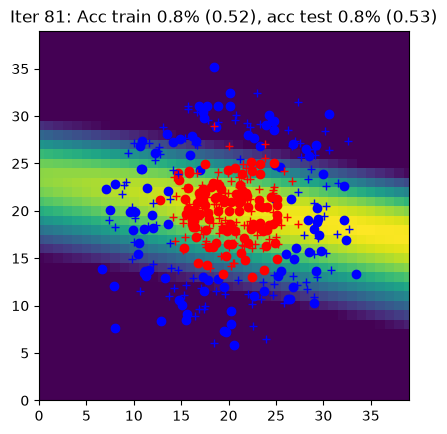

Iter 82: Acc train 0.8% (0.52), acc test 0.8% (0.53)


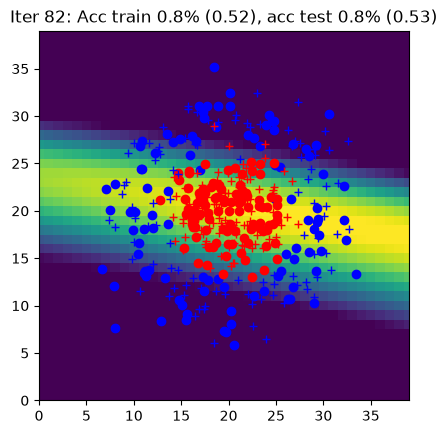

Iter 83: Acc train 0.8% (0.52), acc test 0.8% (0.52)


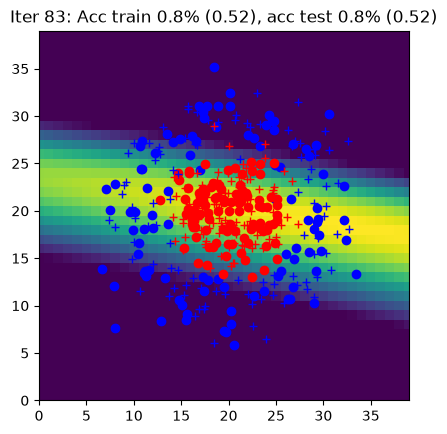

Iter 84: Acc train 0.8% (0.52), acc test 0.8% (0.52)


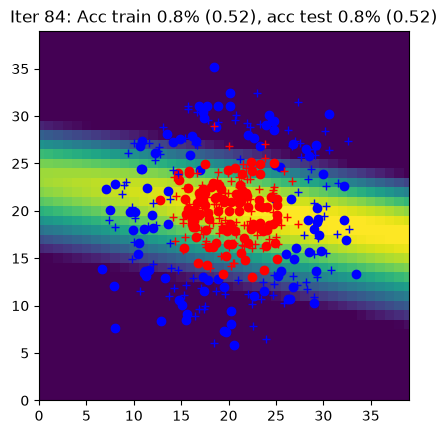

Iter 85: Acc train 0.8% (0.51), acc test 0.8% (0.52)


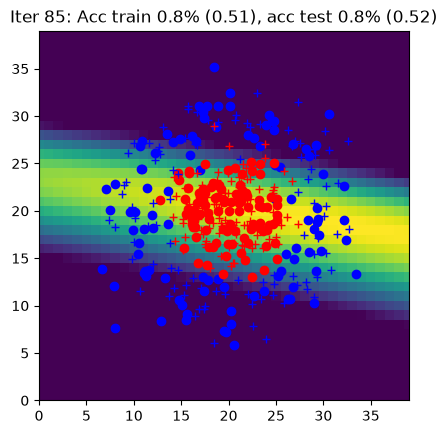

Iter 86: Acc train 0.8% (0.51), acc test 0.8% (0.52)


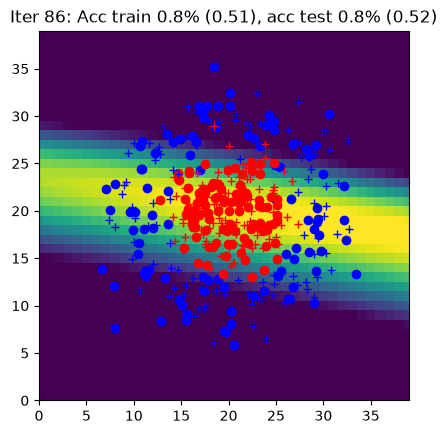

Iter 87: Acc train 0.8% (0.51), acc test 0.8% (0.51)


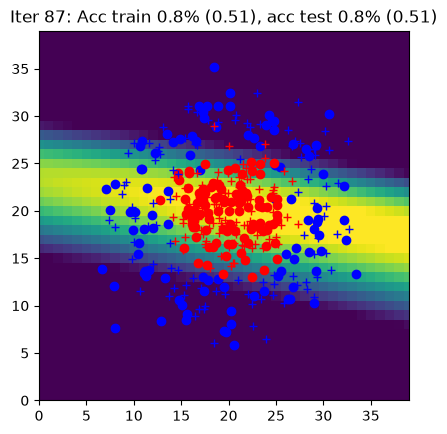

Iter 88: Acc train 0.8% (0.51), acc test 0.8% (0.51)


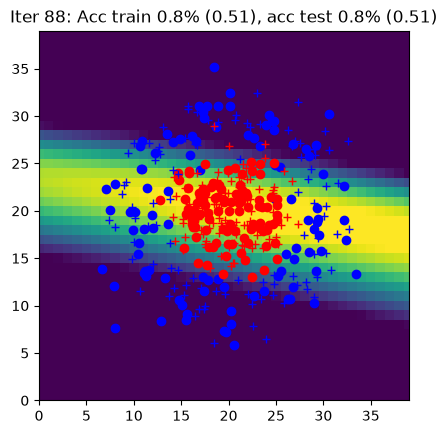

Iter 89: Acc train 0.8% (0.51), acc test 0.8% (0.51)


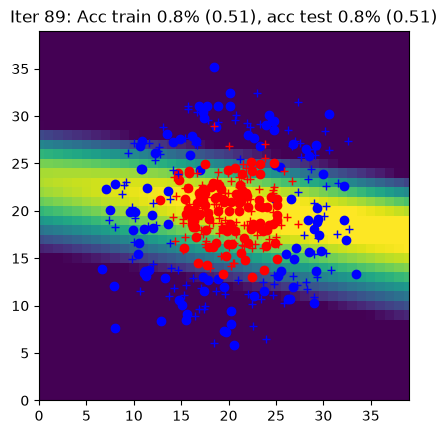

Iter 90: Acc train 0.8% (0.50), acc test 0.8% (0.51)


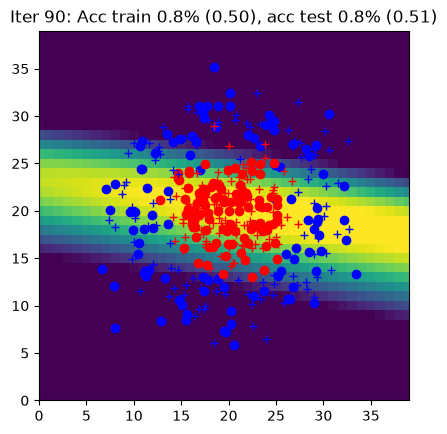

Iter 91: Acc train 0.8% (0.50), acc test 0.8% (0.51)


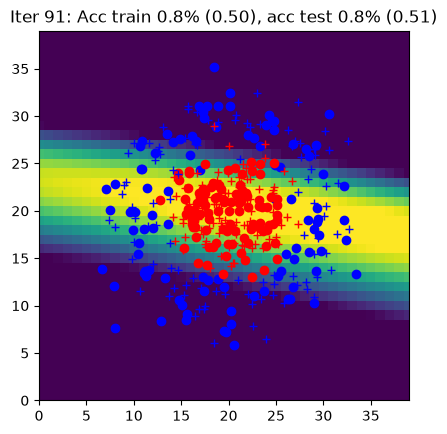

Iter 92: Acc train 0.8% (0.50), acc test 0.8% (0.50)


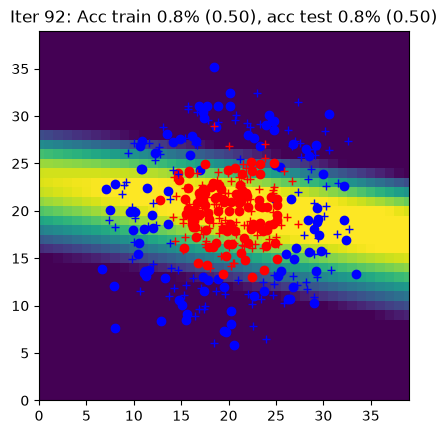

Iter 93: Acc train 0.8% (0.50), acc test 0.8% (0.50)


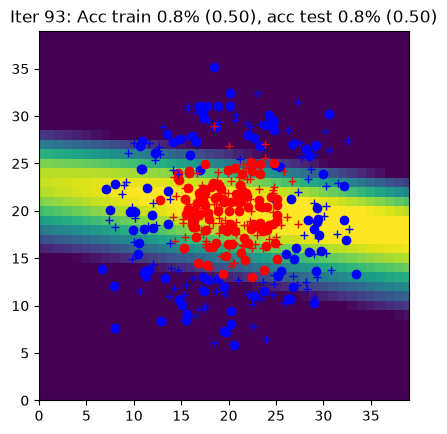

Iter 94: Acc train 0.8% (0.50), acc test 0.8% (0.50)


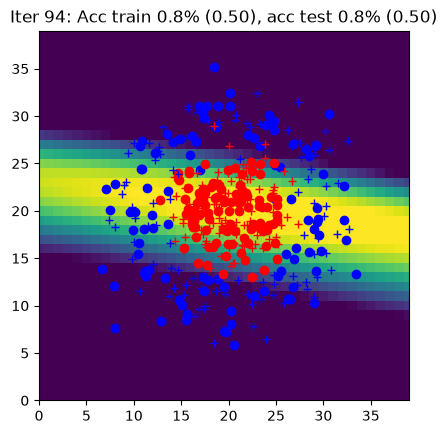

Iter 95: Acc train 0.8% (0.49), acc test 0.8% (0.50)


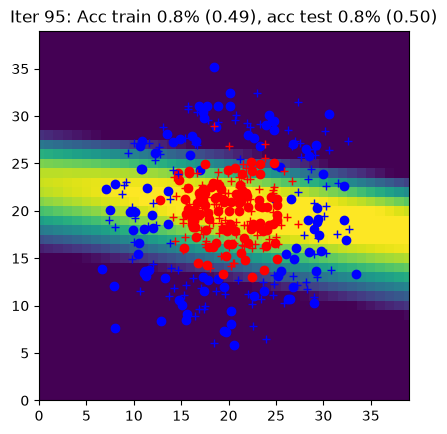

Iter 96: Acc train 0.8% (0.49), acc test 0.8% (0.50)


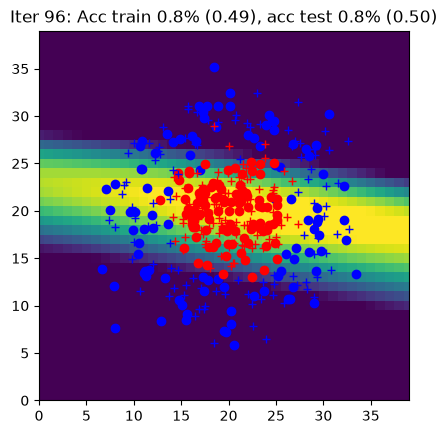

Iter 97: Acc train 0.8% (0.49), acc test 0.8% (0.50)


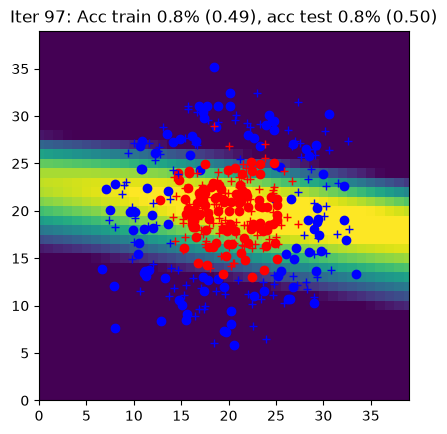

Iter 98: Acc train 0.8% (0.49), acc test 0.8% (0.50)


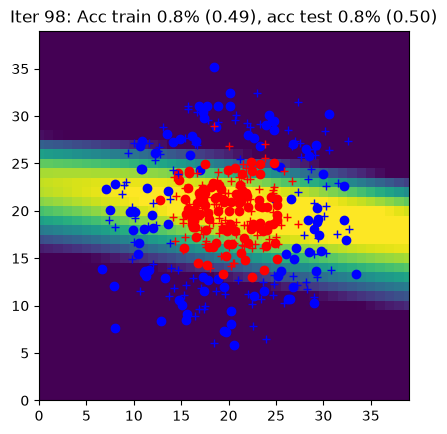

Iter 99: Acc train 0.8% (0.49), acc test 0.8% (0.49)


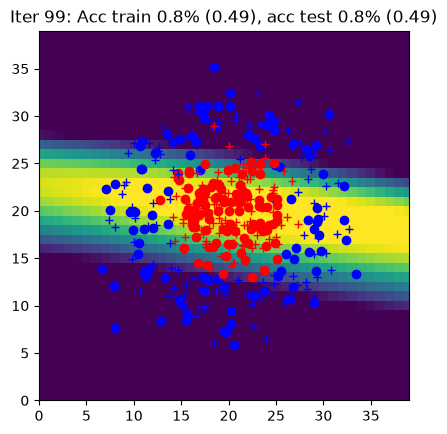

Iter 100: Acc train 0.8% (0.49), acc test 0.8% (0.49)


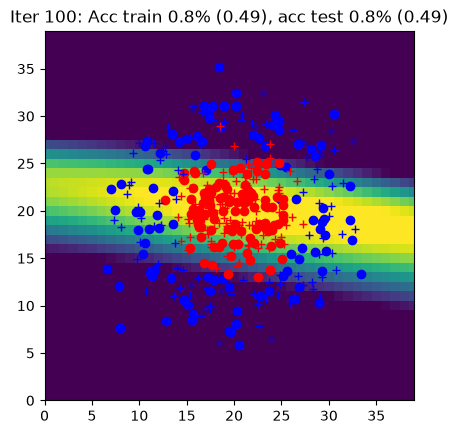

Iter 101: Acc train 0.8% (0.49), acc test 0.8% (0.49)


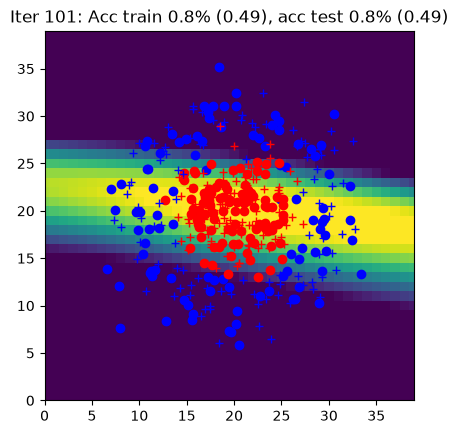

Iter 102: Acc train 0.8% (0.48), acc test 0.8% (0.49)


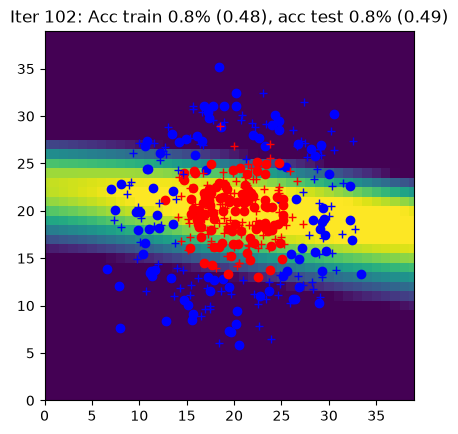

Iter 103: Acc train 0.8% (0.48), acc test 0.8% (0.49)


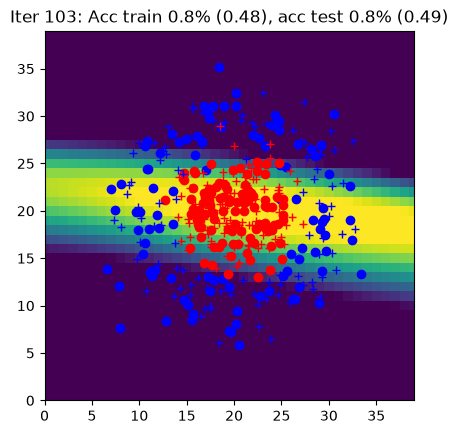

Iter 104: Acc train 0.8% (0.48), acc test 0.8% (0.48)


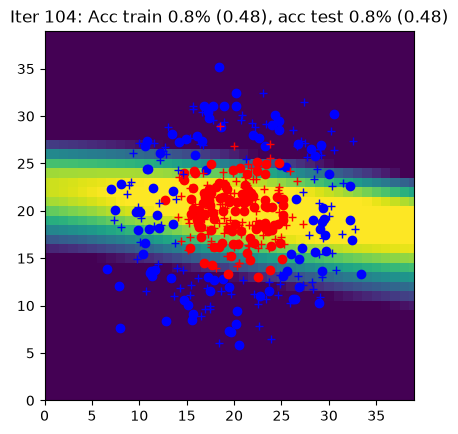

Iter 105: Acc train 0.8% (0.48), acc test 0.8% (0.48)


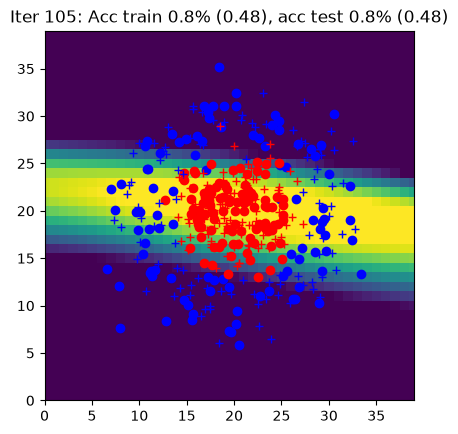

Iter 106: Acc train 0.8% (0.48), acc test 0.8% (0.48)


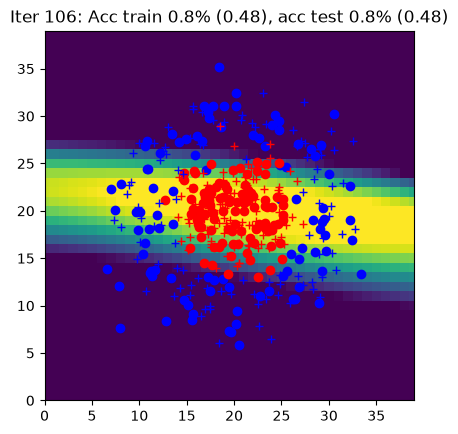

Iter 107: Acc train 0.8% (0.48), acc test 0.8% (0.48)


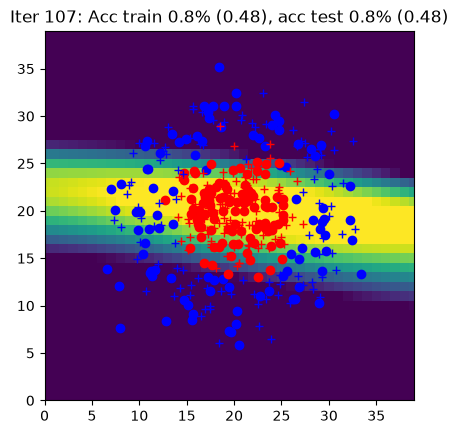

Iter 108: Acc train 0.8% (0.47), acc test 0.8% (0.48)


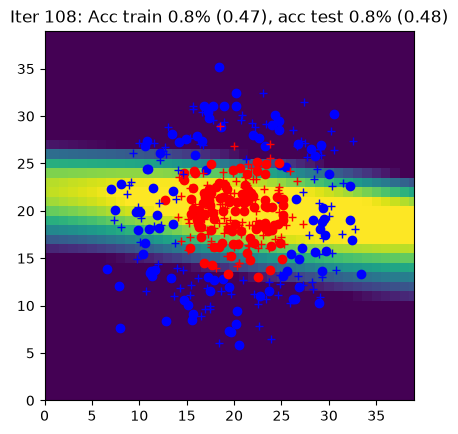

Iter 109: Acc train 0.8% (0.47), acc test 0.8% (0.48)


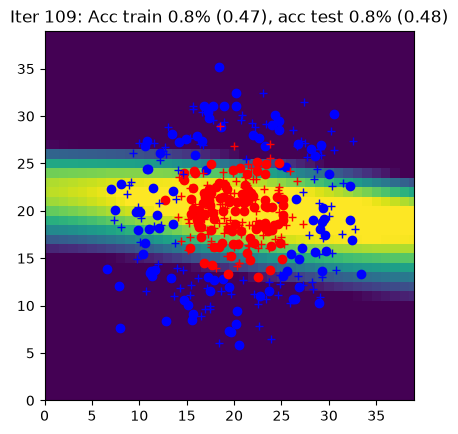

Iter 110: Acc train 0.8% (0.47), acc test 0.8% (0.48)


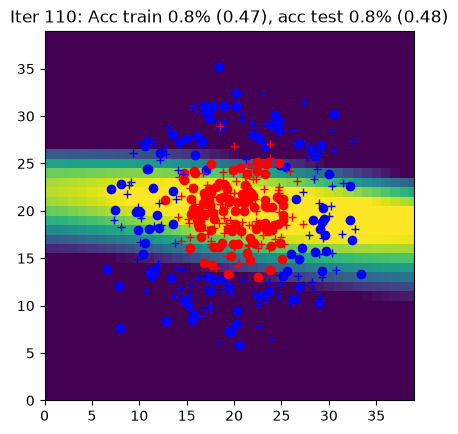

Iter 111: Acc train 0.8% (0.47), acc test 0.8% (0.47)


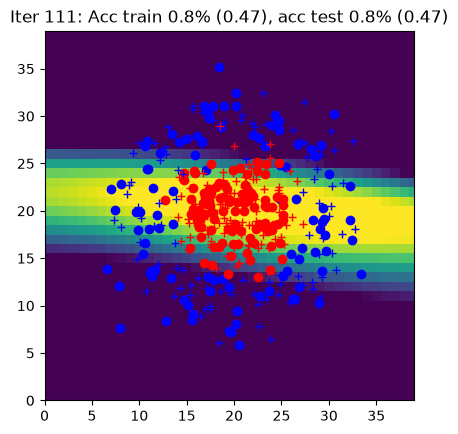

Iter 112: Acc train 0.8% (0.47), acc test 0.8% (0.47)


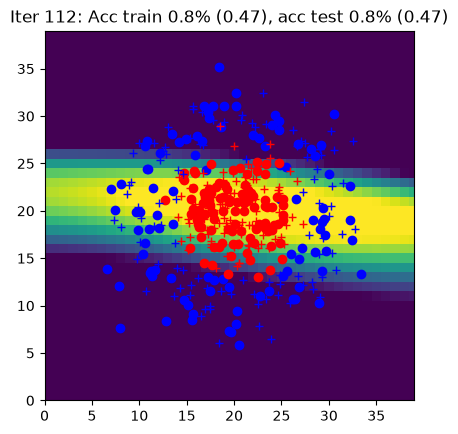

Iter 113: Acc train 0.8% (0.47), acc test 0.8% (0.47)


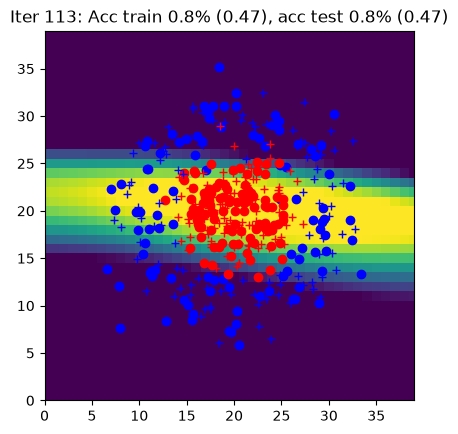

Iter 114: Acc train 0.8% (0.47), acc test 0.8% (0.47)


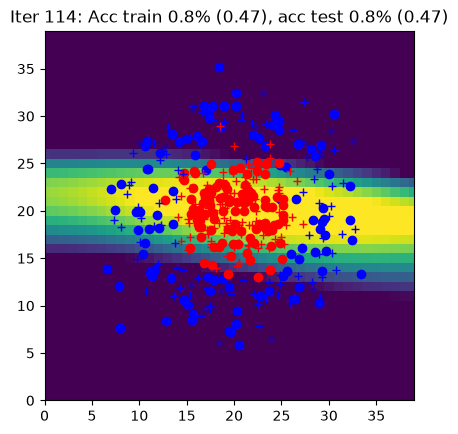

Iter 115: Acc train 0.8% (0.46), acc test 0.8% (0.47)


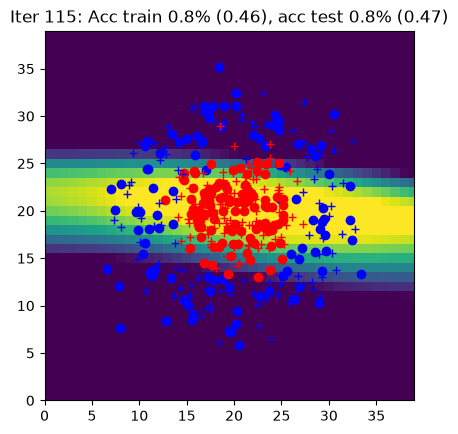

Iter 116: Acc train 0.8% (0.46), acc test 0.8% (0.47)


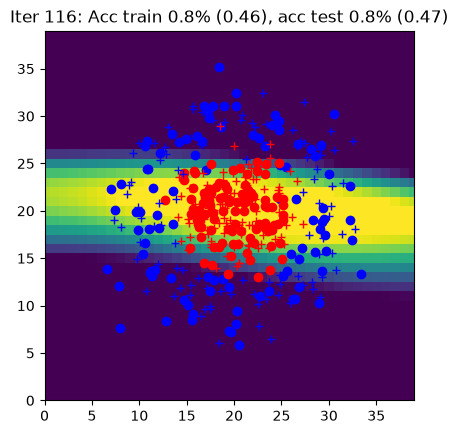

Iter 117: Acc train 0.8% (0.46), acc test 0.8% (0.46)


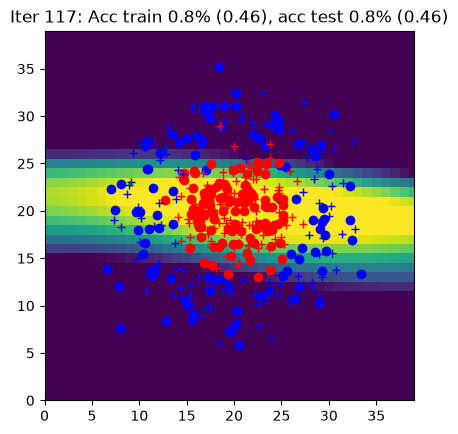

Iter 118: Acc train 0.8% (0.46), acc test 0.8% (0.46)


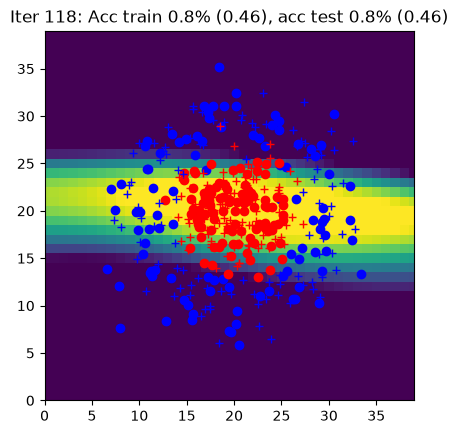

Iter 119: Acc train 0.8% (0.46), acc test 0.8% (0.46)


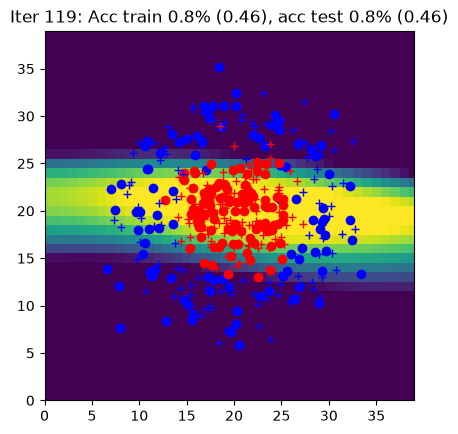

Iter 120: Acc train 0.8% (0.45), acc test 0.8% (0.46)


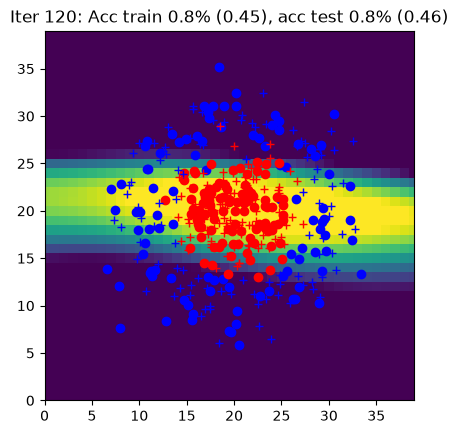

Iter 121: Acc train 0.8% (0.45), acc test 0.8% (0.46)


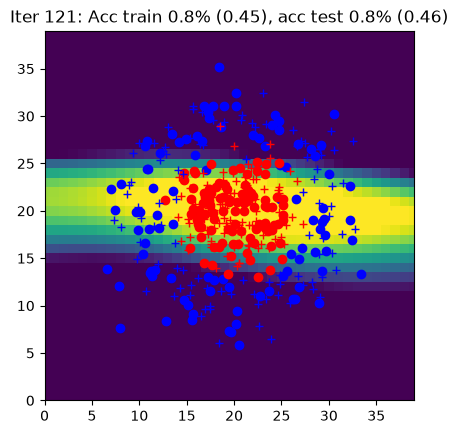

Iter 122: Acc train 0.8% (0.45), acc test 0.8% (0.45)


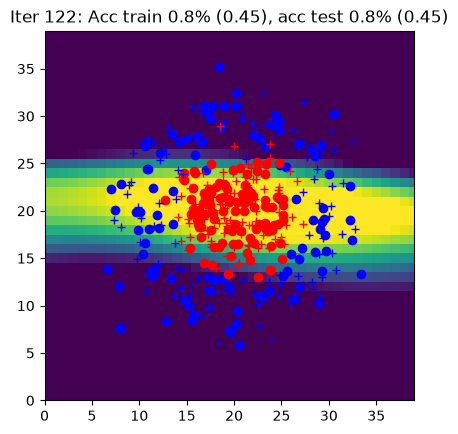

Iter 123: Acc train 0.8% (0.45), acc test 0.8% (0.45)


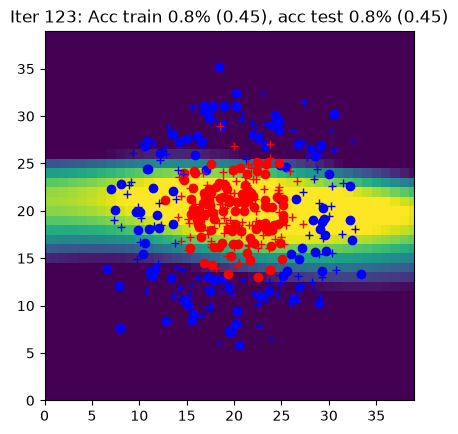

Iter 124: Acc train 0.8% (0.45), acc test 0.8% (0.45)


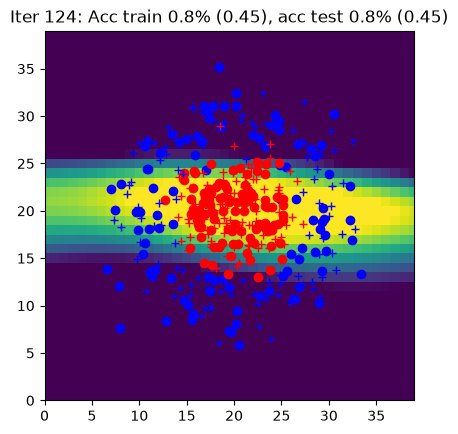

Iter 125: Acc train 0.8% (0.44), acc test 0.8% (0.45)


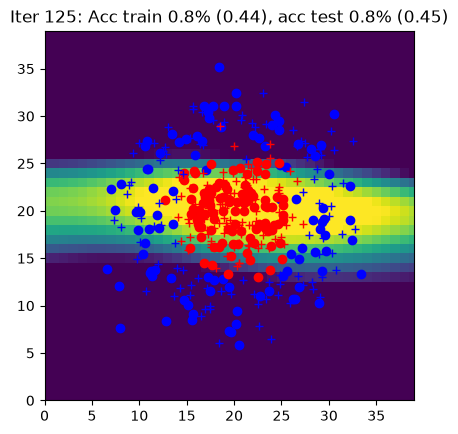

Iter 126: Acc train 0.8% (0.44), acc test 0.8% (0.45)


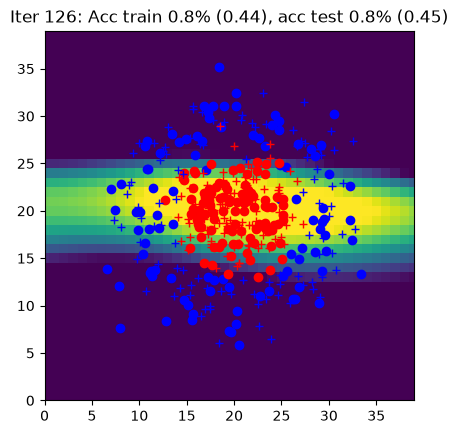

Iter 127: Acc train 0.8% (0.44), acc test 0.8% (0.44)


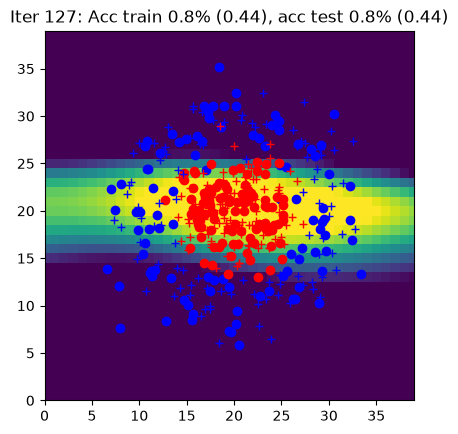

Iter 128: Acc train 0.8% (0.44), acc test 0.8% (0.44)


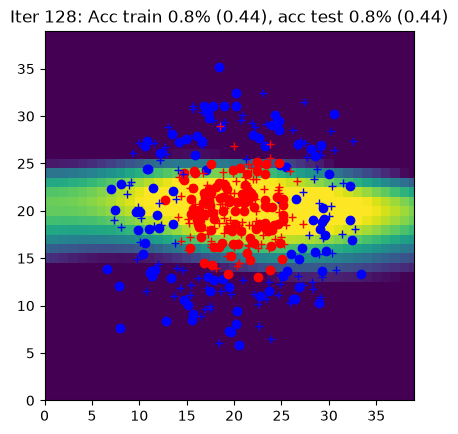

Iter 129: Acc train 0.8% (0.43), acc test 0.8% (0.44)


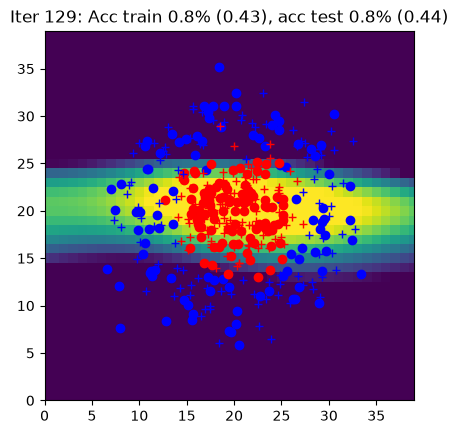

Iter 130: Acc train 0.8% (0.43), acc test 0.8% (0.43)


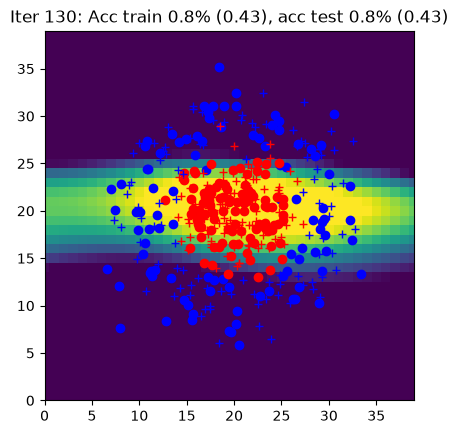

Iter 131: Acc train 0.8% (0.43), acc test 0.8% (0.43)


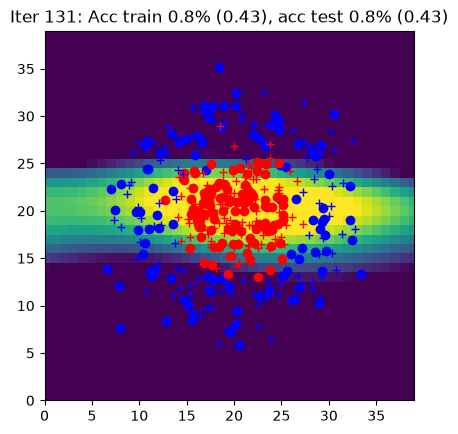

Iter 132: Acc train 0.8% (0.42), acc test 0.8% (0.43)


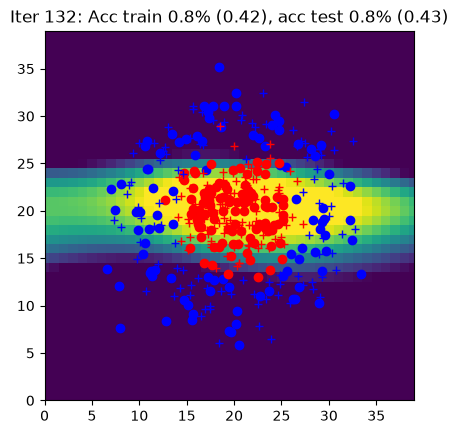

Iter 133: Acc train 0.8% (0.42), acc test 0.8% (0.43)


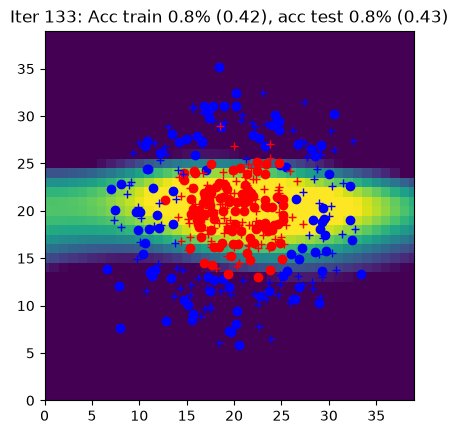

Iter 134: Acc train 0.8% (0.42), acc test 0.8% (0.42)


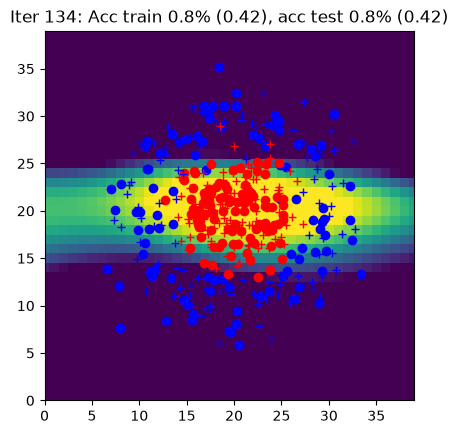

Iter 135: Acc train 0.8% (0.41), acc test 0.8% (0.42)


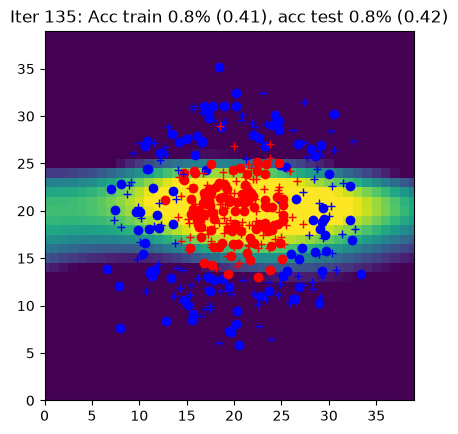

Iter 136: Acc train 0.8% (0.41), acc test 0.8% (0.42)


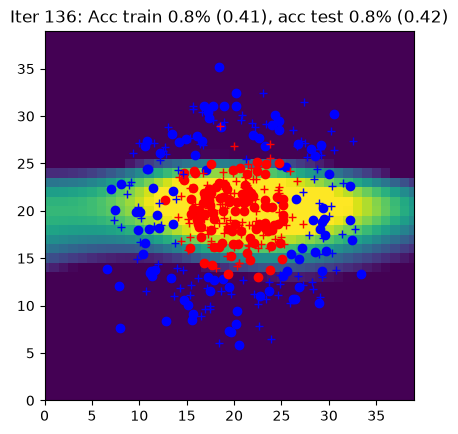

Iter 137: Acc train 0.8% (0.41), acc test 0.8% (0.41)


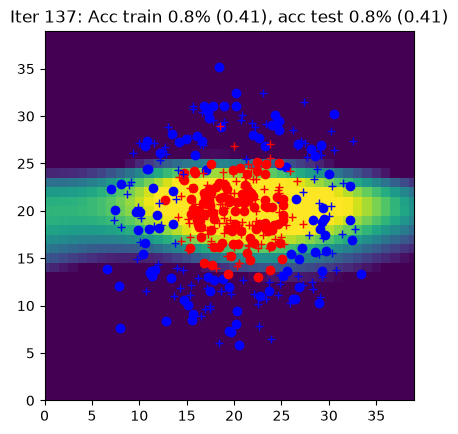

Iter 138: Acc train 0.8% (0.40), acc test 0.8% (0.41)


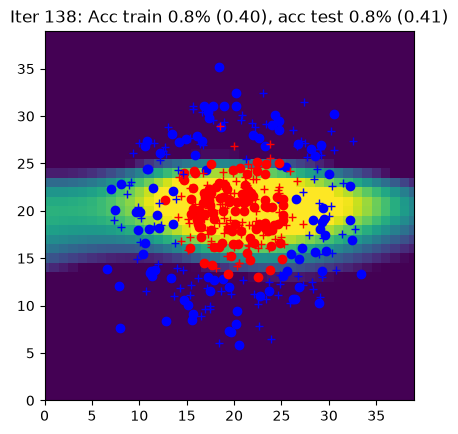

Iter 139: Acc train 0.8% (0.40), acc test 0.8% (0.41)


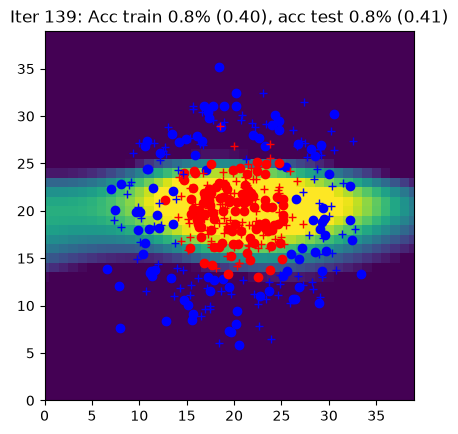

Iter 140: Acc train 0.8% (0.40), acc test 0.8% (0.40)


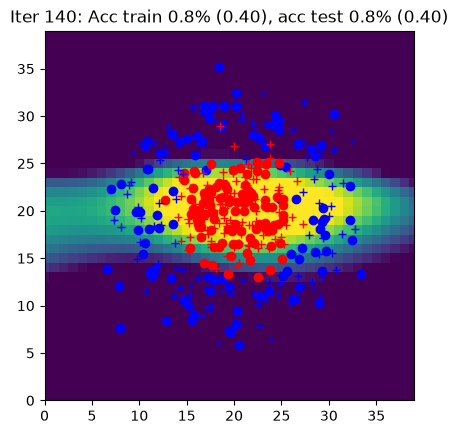

Iter 141: Acc train 0.8% (0.39), acc test 0.8% (0.40)


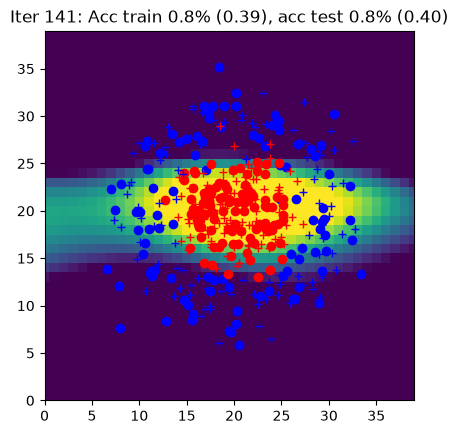

Iter 142: Acc train 0.8% (0.39), acc test 0.8% (0.39)


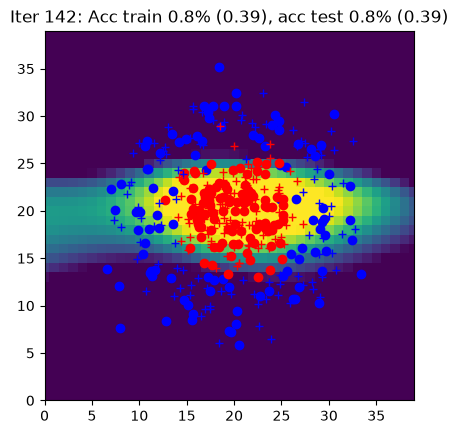

Iter 143: Acc train 0.8% (0.38), acc test 0.8% (0.39)


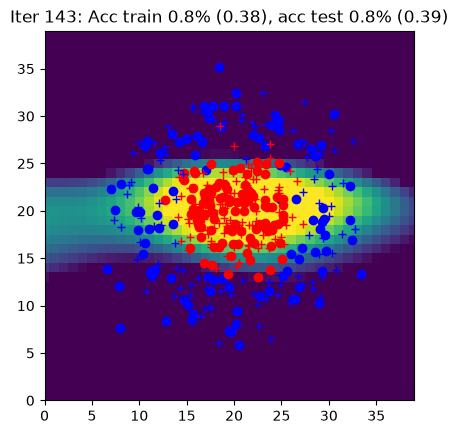

Iter 144: Acc train 0.8% (0.38), acc test 0.8% (0.39)


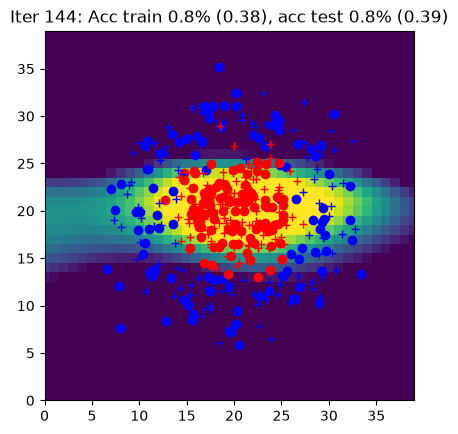

Iter 145: Acc train 0.8% (0.38), acc test 0.8% (0.38)


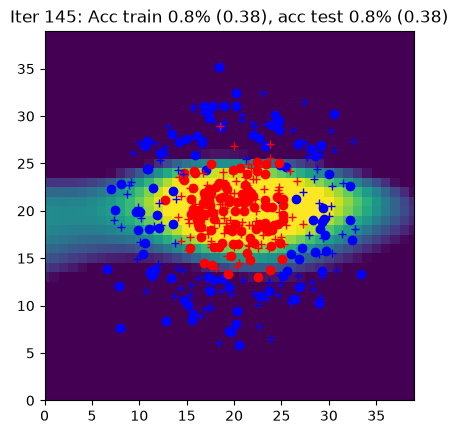

Iter 146: Acc train 0.8% (0.37), acc test 0.9% (0.38)


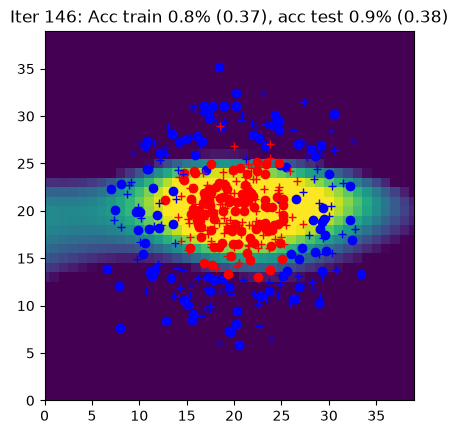

Iter 147: Acc train 0.8% (0.37), acc test 0.9% (0.37)


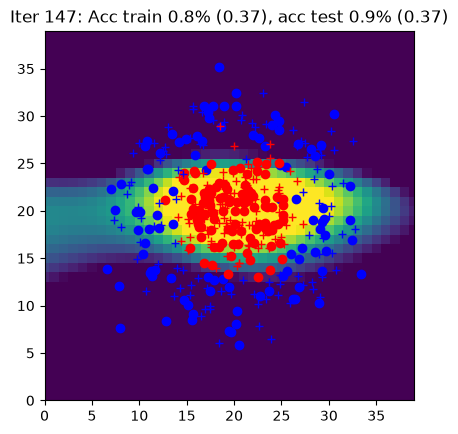

Iter 148: Acc train 0.8% (0.36), acc test 0.9% (0.37)


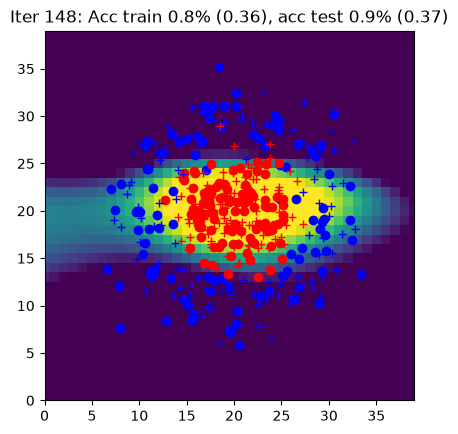

Iter 149: Acc train 0.9% (0.36), acc test 0.9% (0.36)


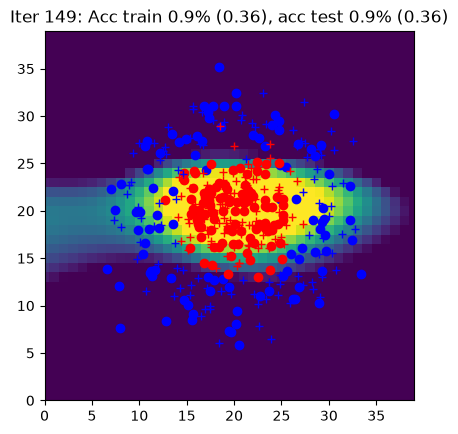

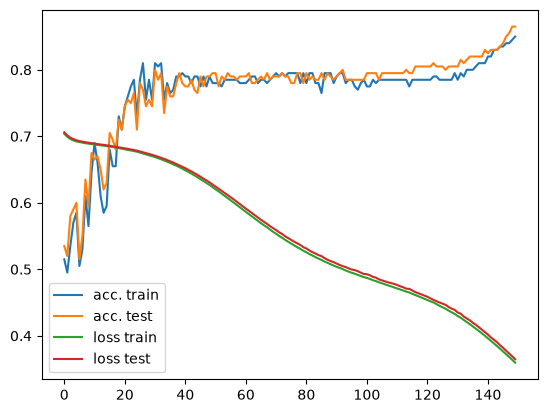

In [93]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

params = init_params(nx, nh, ny)

curves = [[], [], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code here  ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j + 1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: forward, loss_accuracy, backward, sgd
        Yhat, outputs = forward(params, X)
        L, acc = loss_accuracy(Yhat, Y)
        grads = backward(params, outputs, Y)
        params = sgd(params, grads, eta)

    ####################
    ##      END        #
    ####################

    Yhat_train, _ = forward(params, data.Xtrain)
    Yhat_test, _ = forward(params, data.Xtest)
    Ltrain, acctrain = loss_accuracy(Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(Yhat_test, data.Ytest)
    Ygrid, _ = forward(params, data.Xgrid)

    title = "Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})".format(
        iteration, acctrain, Ltrain, acctest, Ltest
    )
    print(title)
    data.plot_data_with_grid(Ygrid, title)

    curves[0].append(acctrain)
    curves[1].append(acctest)
    curves[2].append(Ltrain)
    curves[3].append(Ltest)

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 2 : Simplification of the backward pass with `torch.autograd`



In [94]:
def init_params(nx, nh, ny):
    """
    nx, nh, ny: integers
    out params: dictionnary
    """
    params = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for Wh, Wy, bh, by
    # activaye autograd on the network weights

    params["Wh"] = torch.randn(nh, nx, requires_grad=True)
    params["Wy"] = torch.randn(ny, nh, requires_grad=True)
    params["bh"] = torch.zeros(nh, requires_grad=True)
    params["by"] = torch.zeros(ny, requires_grad=True)

    ####################
    ##      END        #
    ####################
    return params

The function `forward` remains unchanged from previous part.

The function `backward` is no longer used because of "autograd".

In [95]:
def sgd(params, eta):

    #####################
    ## Your code here  ##
    #####################
    # update the network weights
    # warning: use torch.no_grad()
    # and reset to zero the gradient accumulators
    with torch.no_grad():
        params["Wh"] -= eta * params["Wh"].grad
        params["Wy"] -= eta * params["Wy"].grad
        params["bh"] -= eta * params["bh"].grad
        params["by"] -= eta * params["by"].grad

        params["Wh"].grad.zero_()
        params["Wy"].grad.zero_()
        params["bh"].grad.zero_()
        params["by"].grad.zero_()

    ####################
    ##      END        #
    ####################
    return params

## Global learning procedure with autograd

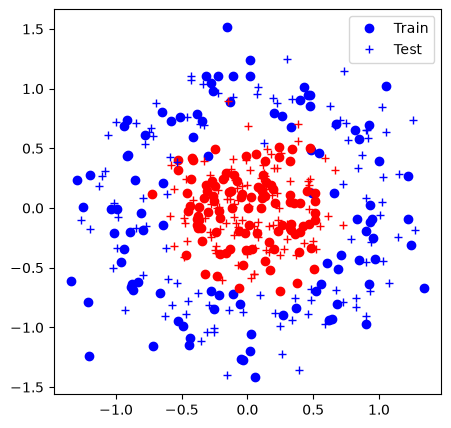

Iter 0: Acc train 0.6% (1.04), acc test 0.6% (1.00)


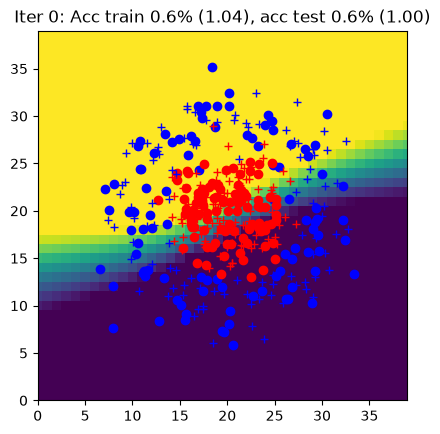

Iter 1: Acc train 0.6% (0.80), acc test 0.5% (0.78)


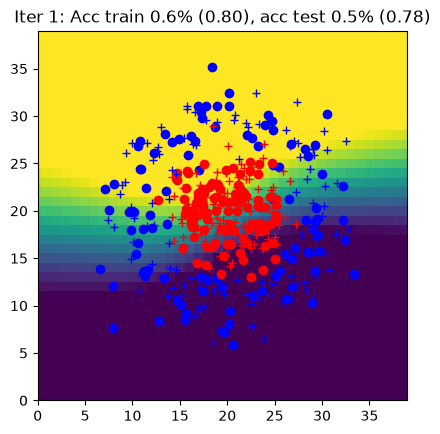

Iter 2: Acc train 0.6% (0.69), acc test 0.6% (0.68)


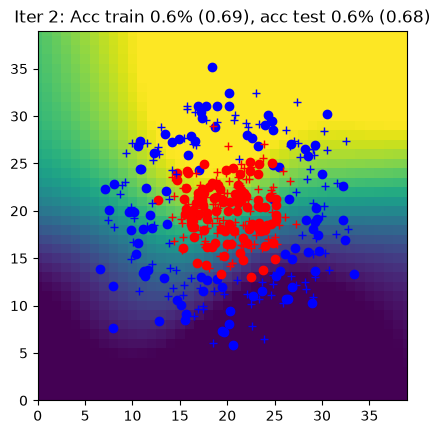

Iter 3: Acc train 0.7% (0.65), acc test 0.7% (0.65)


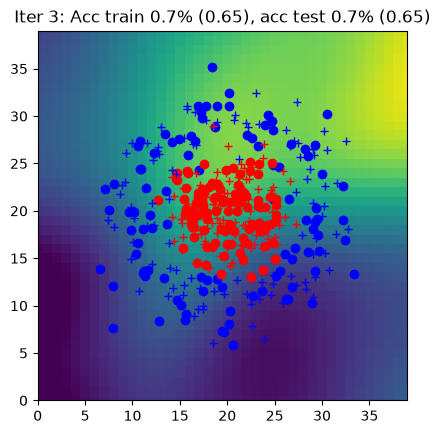

Iter 4: Acc train 0.7% (0.64), acc test 0.8% (0.64)


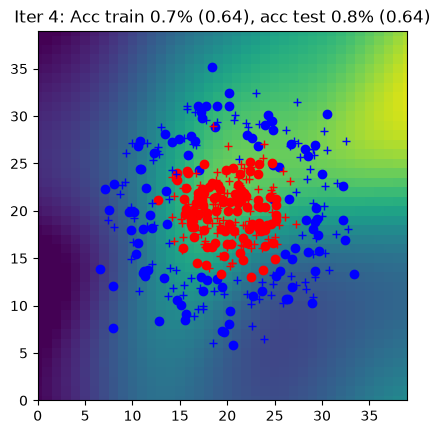

Iter 5: Acc train 0.7% (0.63), acc test 0.7% (0.63)


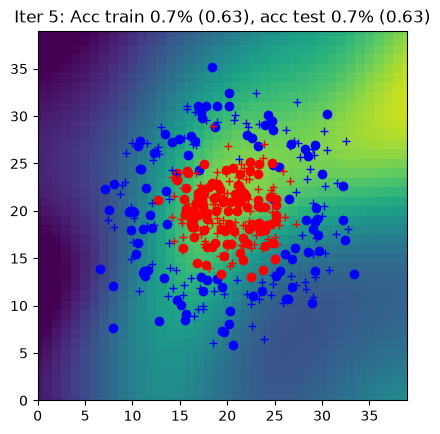

Iter 6: Acc train 0.8% (0.62), acc test 0.7% (0.62)


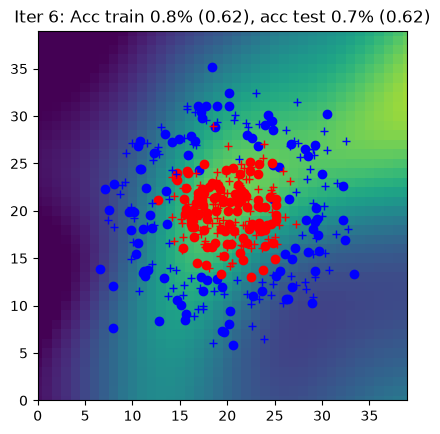

Iter 7: Acc train 0.8% (0.61), acc test 0.8% (0.61)


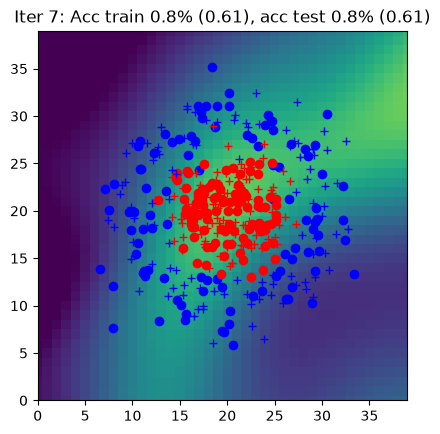

Iter 8: Acc train 0.8% (0.60), acc test 0.8% (0.60)


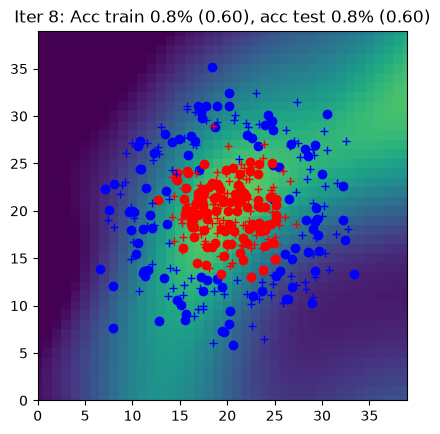

Iter 9: Acc train 0.8% (0.59), acc test 0.8% (0.59)


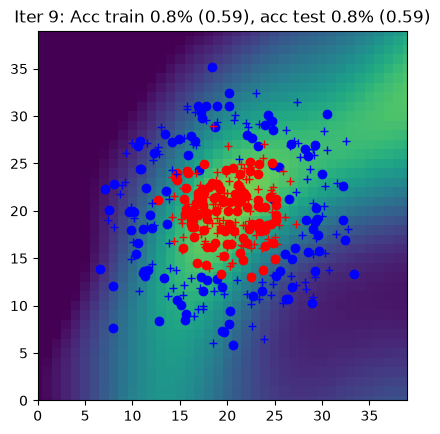

Iter 10: Acc train 0.8% (0.58), acc test 0.8% (0.58)


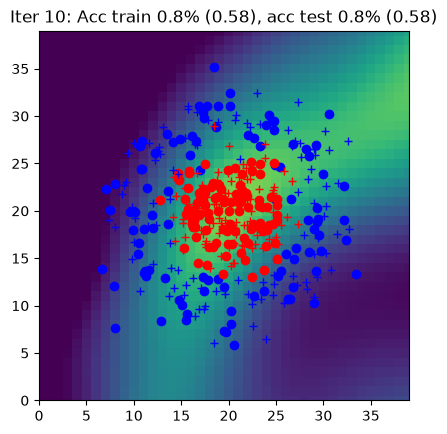

Iter 11: Acc train 0.8% (0.57), acc test 0.8% (0.57)


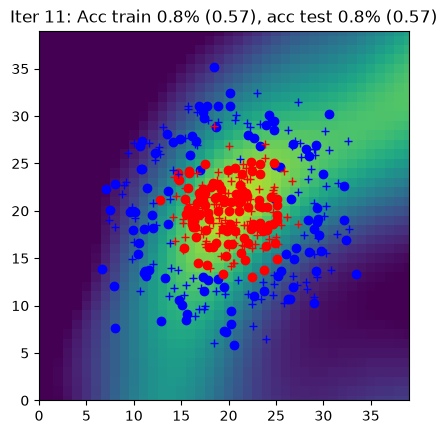

Iter 12: Acc train 0.8% (0.57), acc test 0.8% (0.57)


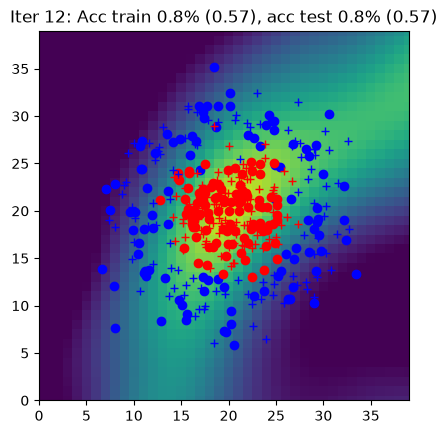

Iter 13: Acc train 0.8% (0.56), acc test 0.8% (0.56)


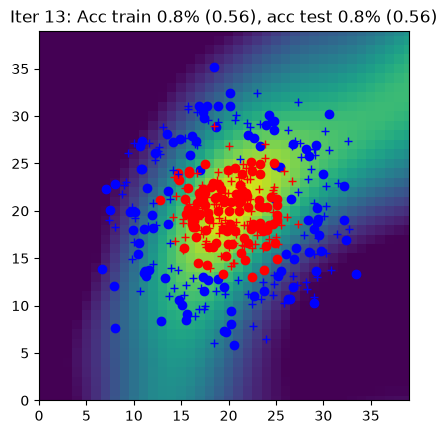

Iter 14: Acc train 0.8% (0.55), acc test 0.8% (0.55)


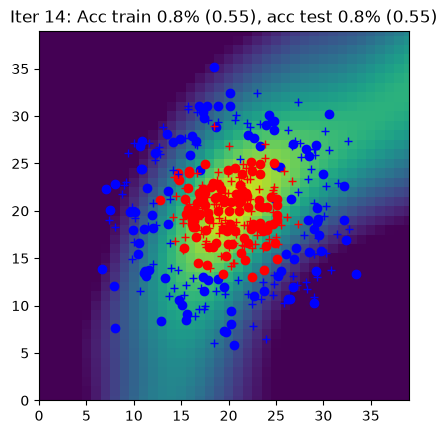

Iter 15: Acc train 0.8% (0.55), acc test 0.8% (0.54)


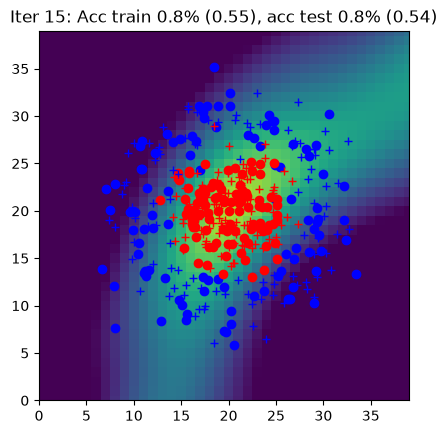

Iter 16: Acc train 0.8% (0.54), acc test 0.8% (0.53)


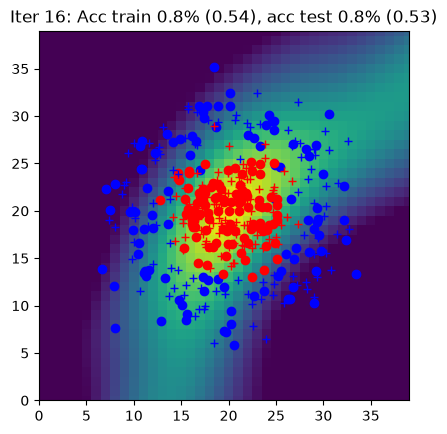

Iter 17: Acc train 0.8% (0.53), acc test 0.8% (0.53)


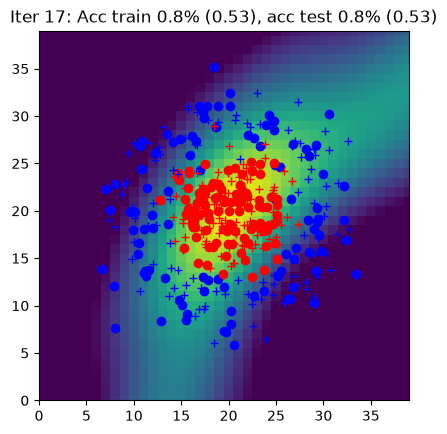

Iter 18: Acc train 0.8% (0.52), acc test 0.8% (0.52)


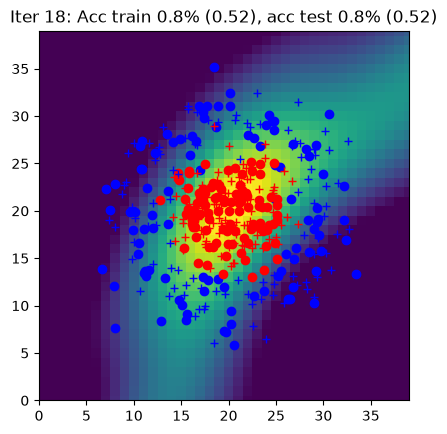

Iter 19: Acc train 0.8% (0.51), acc test 0.8% (0.51)


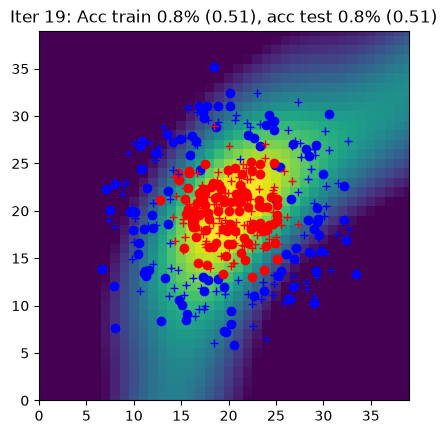

Iter 20: Acc train 0.8% (0.51), acc test 0.8% (0.50)


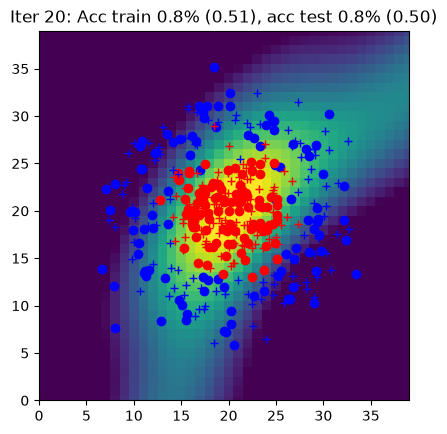

Iter 21: Acc train 0.8% (0.50), acc test 0.8% (0.50)


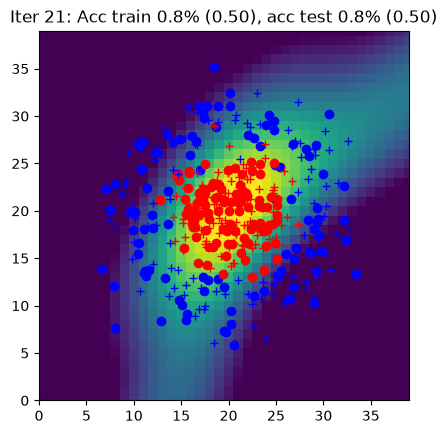

Iter 22: Acc train 0.8% (0.49), acc test 0.8% (0.49)


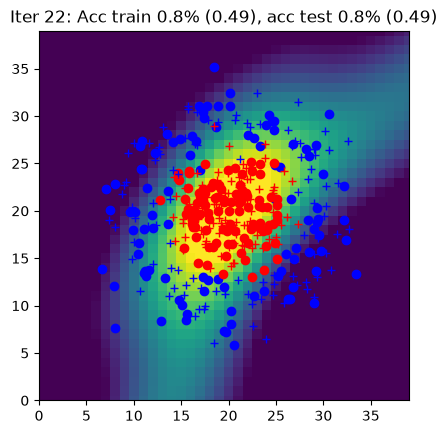

Iter 23: Acc train 0.8% (0.49), acc test 0.8% (0.48)


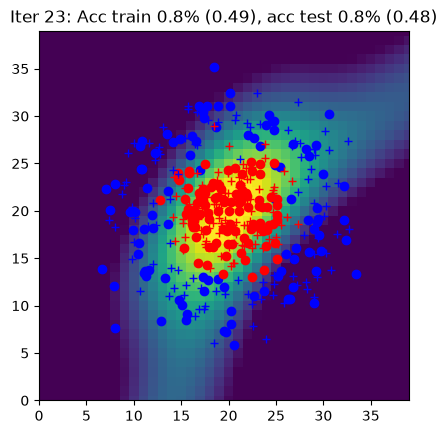

Iter 24: Acc train 0.8% (0.48), acc test 0.8% (0.48)


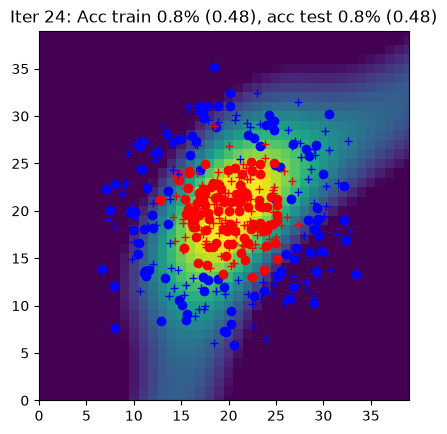

Iter 25: Acc train 0.8% (0.47), acc test 0.8% (0.47)


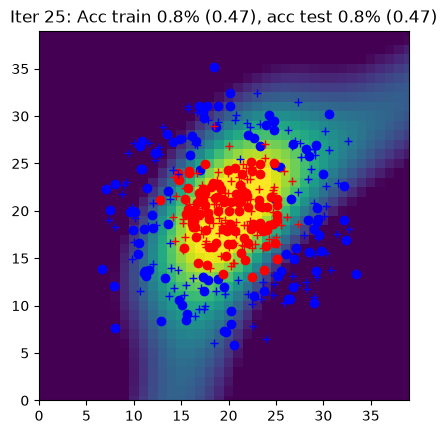

Iter 26: Acc train 0.8% (0.47), acc test 0.8% (0.46)


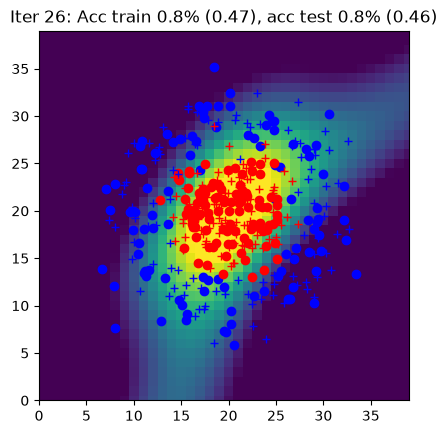

Iter 27: Acc train 0.8% (0.46), acc test 0.8% (0.46)


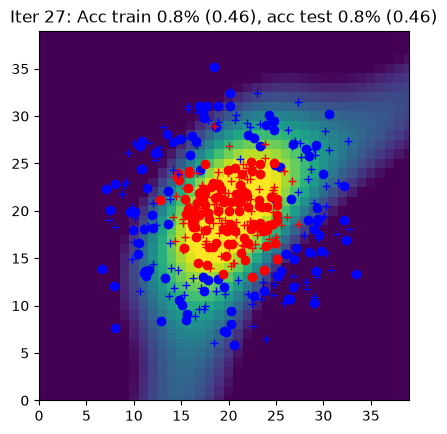

Iter 28: Acc train 0.9% (0.45), acc test 0.8% (0.45)


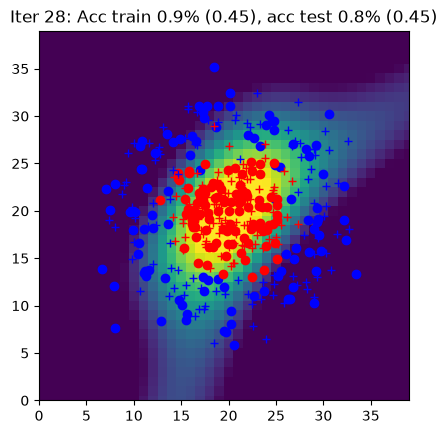

Iter 29: Acc train 0.9% (0.45), acc test 0.9% (0.44)


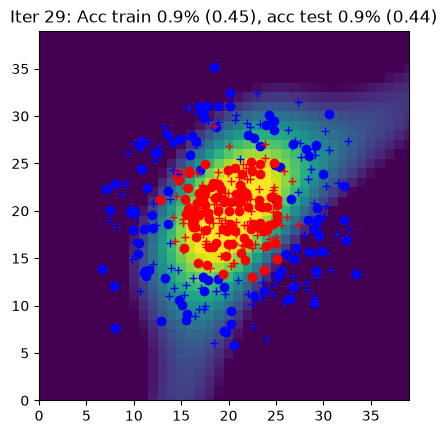

Iter 30: Acc train 0.9% (0.44), acc test 0.9% (0.44)


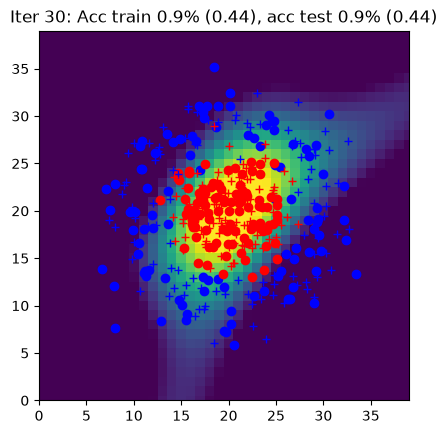

Iter 31: Acc train 0.8% (0.43), acc test 0.8% (0.43)


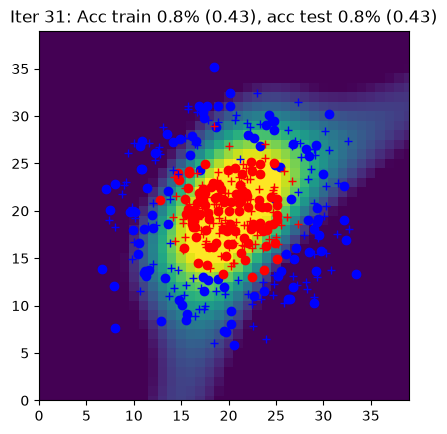

Iter 32: Acc train 0.9% (0.43), acc test 0.9% (0.42)


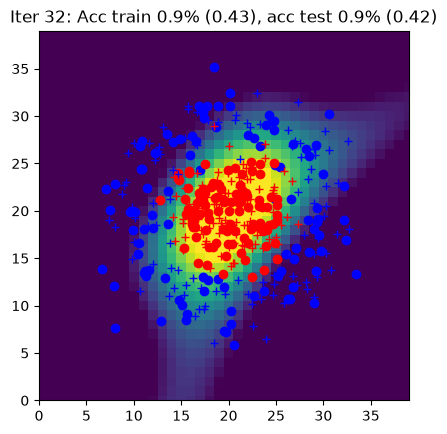

Iter 33: Acc train 0.9% (0.42), acc test 0.9% (0.42)


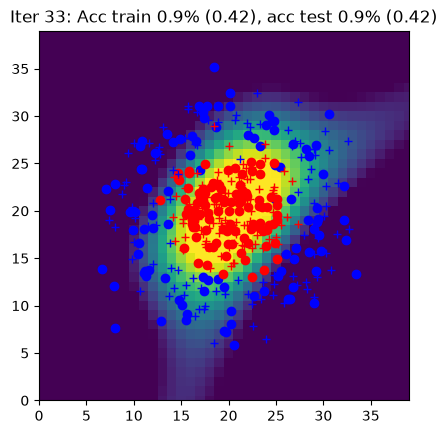

Iter 34: Acc train 0.9% (0.41), acc test 0.9% (0.41)


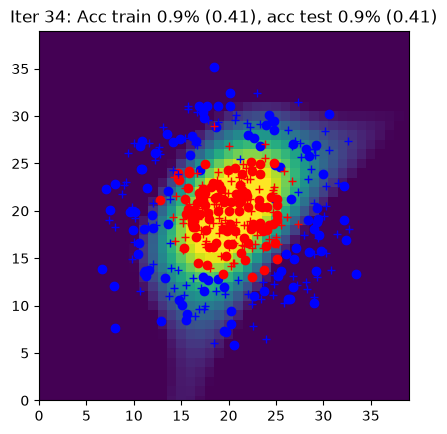

Iter 35: Acc train 0.9% (0.41), acc test 0.9% (0.40)


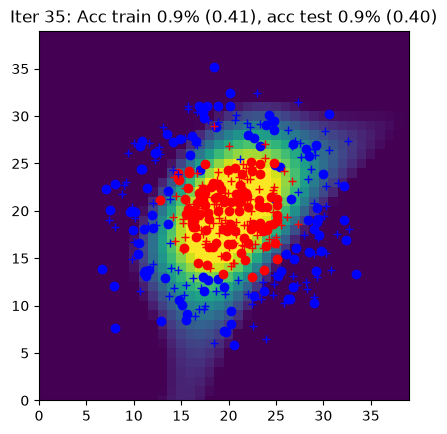

Iter 36: Acc train 0.9% (0.40), acc test 0.9% (0.40)


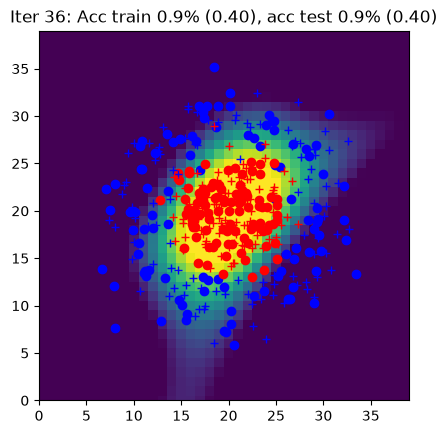

Iter 37: Acc train 0.9% (0.39), acc test 0.9% (0.39)


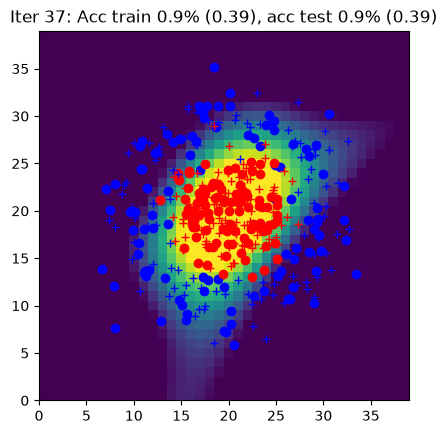

Iter 38: Acc train 0.9% (0.39), acc test 0.9% (0.38)


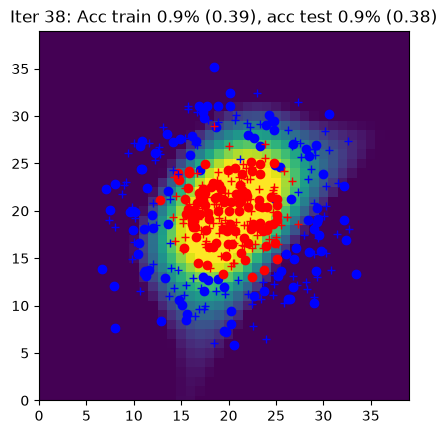

Iter 39: Acc train 0.9% (0.38), acc test 0.9% (0.38)


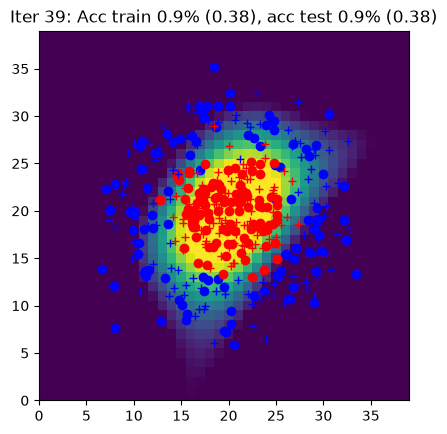

Iter 40: Acc train 0.9% (0.38), acc test 0.9% (0.37)


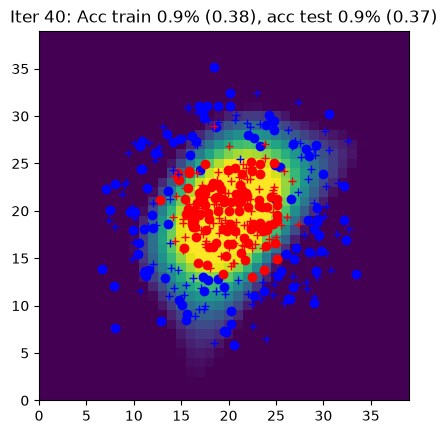

Iter 41: Acc train 0.9% (0.37), acc test 0.9% (0.37)


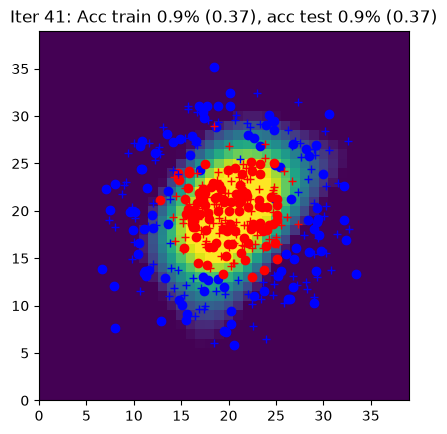

Iter 42: Acc train 0.9% (0.36), acc test 0.9% (0.36)


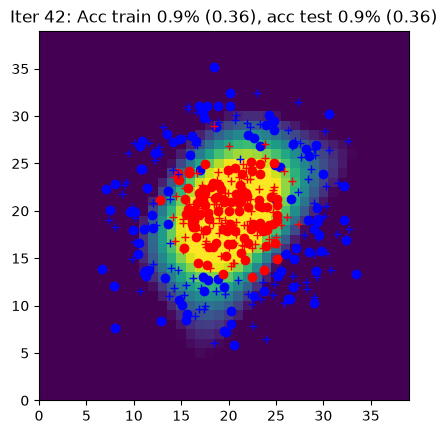

Iter 43: Acc train 0.9% (0.36), acc test 0.9% (0.35)


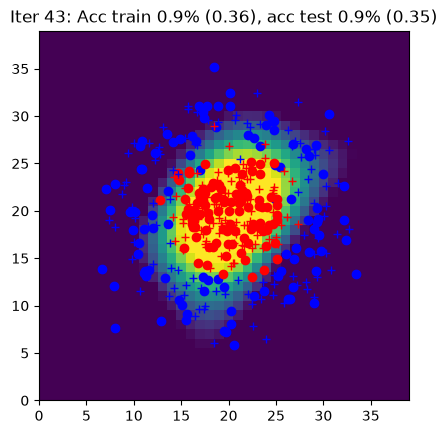

Iter 44: Acc train 0.9% (0.35), acc test 0.9% (0.35)


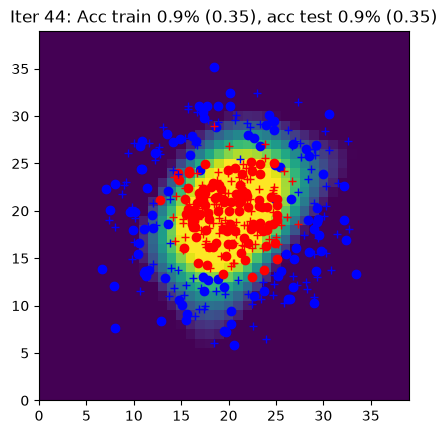

Iter 45: Acc train 0.9% (0.35), acc test 0.9% (0.34)


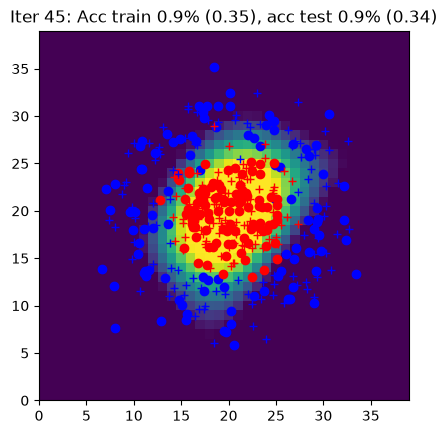

Iter 46: Acc train 0.9% (0.34), acc test 0.9% (0.34)


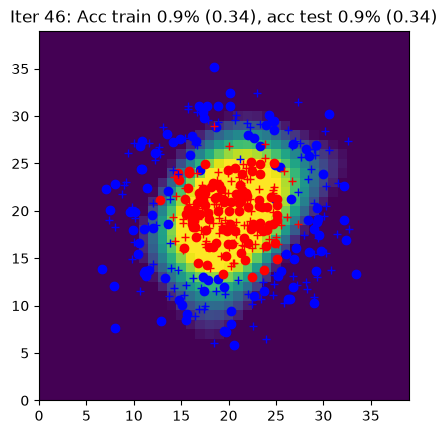

Iter 47: Acc train 0.9% (0.34), acc test 0.9% (0.33)


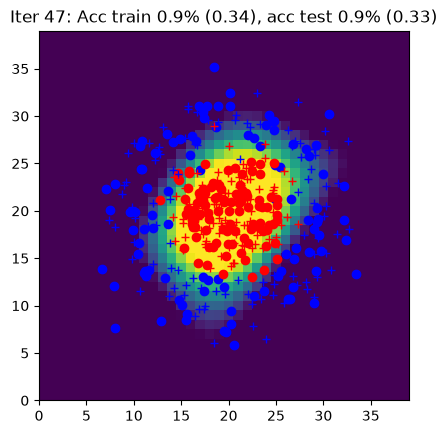

Iter 48: Acc train 0.9% (0.33), acc test 0.9% (0.33)


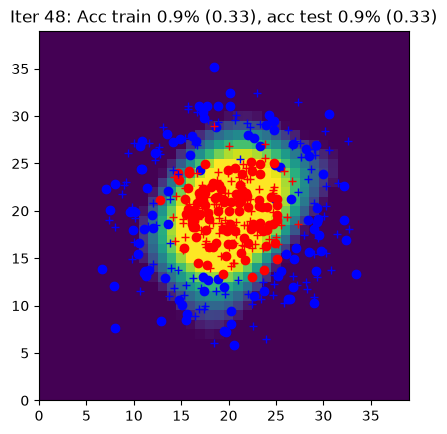

Iter 49: Acc train 0.9% (0.33), acc test 0.9% (0.32)


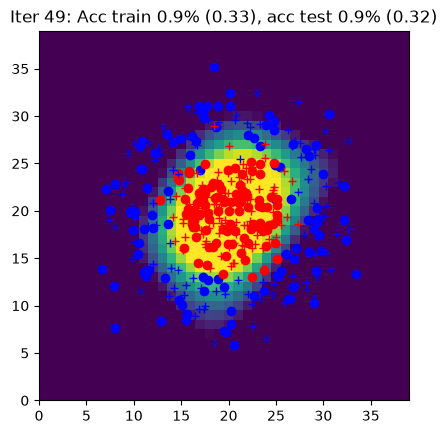

Iter 50: Acc train 0.9% (0.32), acc test 0.9% (0.32)


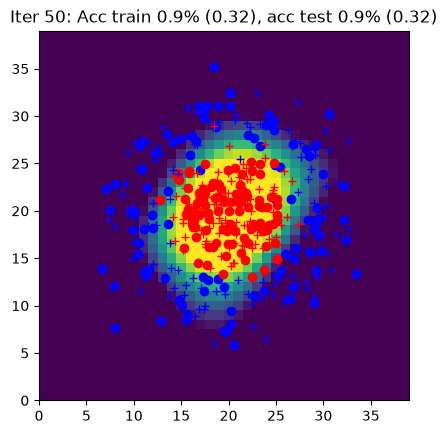

Iter 51: Acc train 0.9% (0.32), acc test 0.9% (0.31)


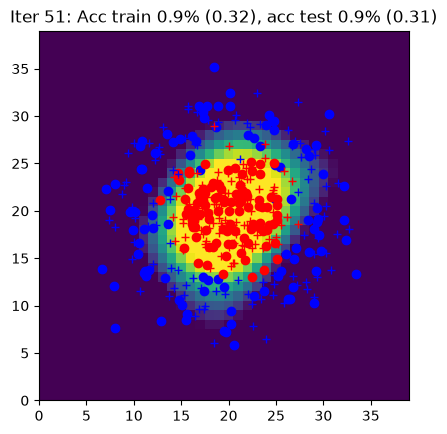

Iter 52: Acc train 0.9% (0.31), acc test 0.9% (0.31)


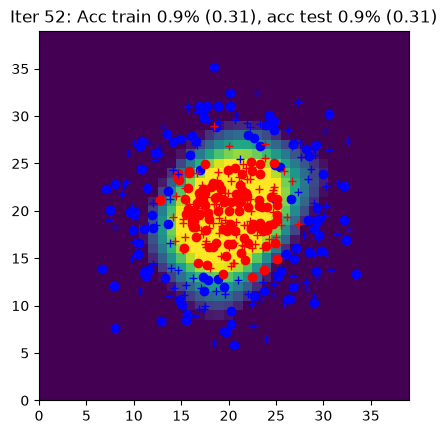

Iter 53: Acc train 0.9% (0.31), acc test 1.0% (0.30)


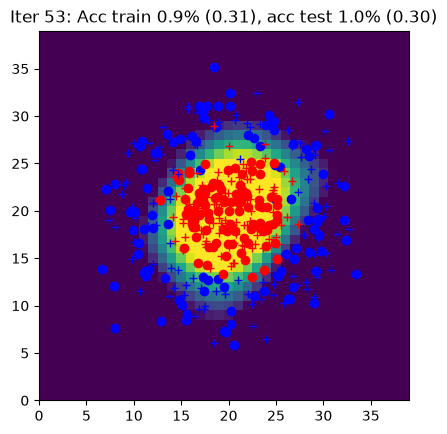

Iter 54: Acc train 0.9% (0.30), acc test 0.9% (0.30)


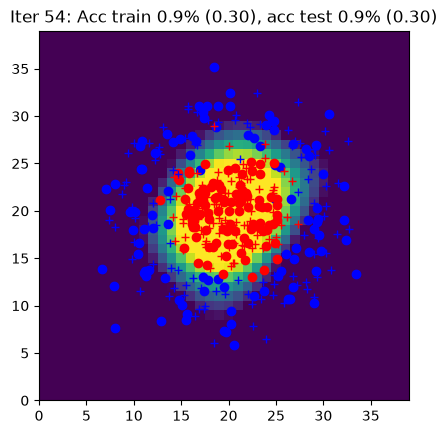

Iter 55: Acc train 0.9% (0.30), acc test 0.9% (0.30)


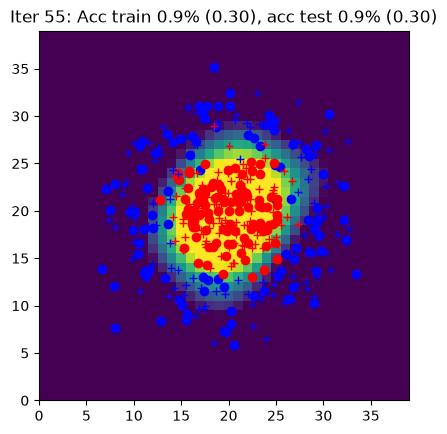

Iter 56: Acc train 0.9% (0.29), acc test 0.9% (0.29)


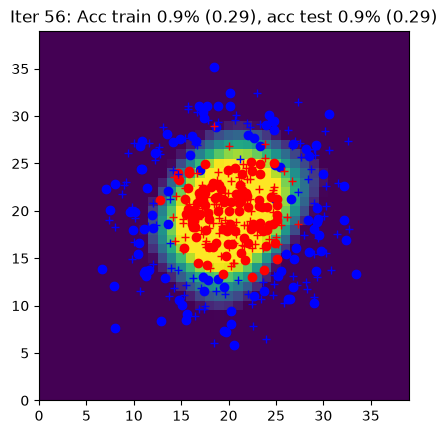

Iter 57: Acc train 0.9% (0.29), acc test 0.9% (0.29)


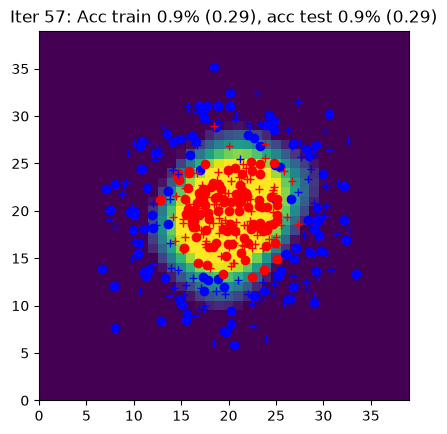

Iter 58: Acc train 0.9% (0.29), acc test 0.9% (0.28)


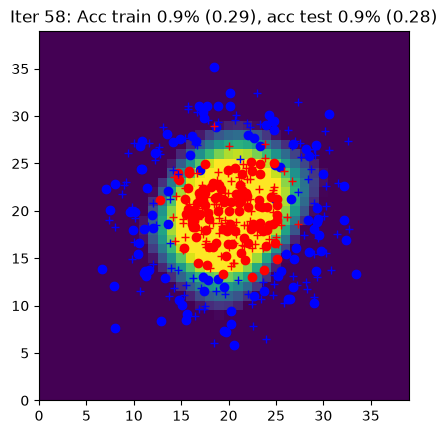

Iter 59: Acc train 0.9% (0.28), acc test 0.9% (0.28)


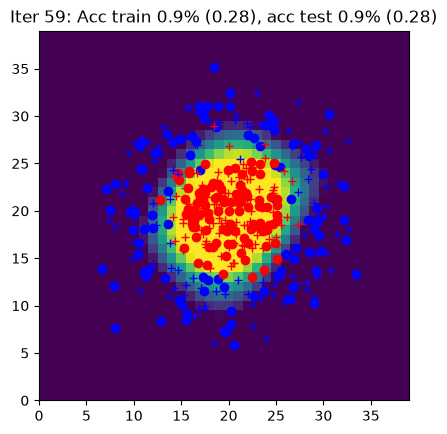

Iter 60: Acc train 0.9% (0.28), acc test 1.0% (0.28)


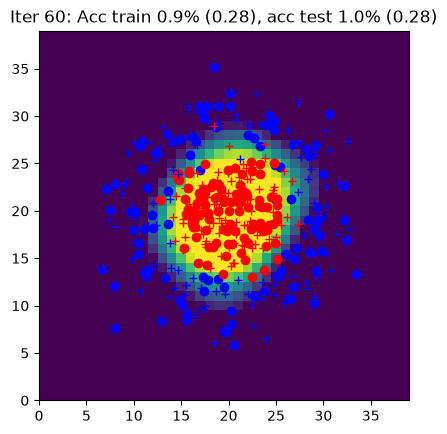

Iter 61: Acc train 0.9% (0.27), acc test 1.0% (0.27)


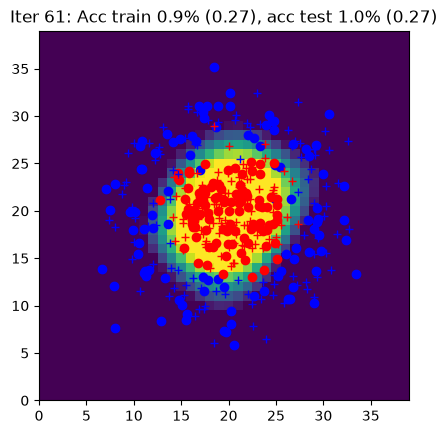

Iter 62: Acc train 0.9% (0.27), acc test 1.0% (0.27)


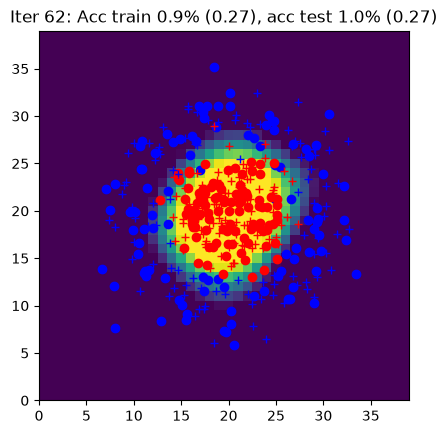

Iter 63: Acc train 0.9% (0.27), acc test 1.0% (0.27)


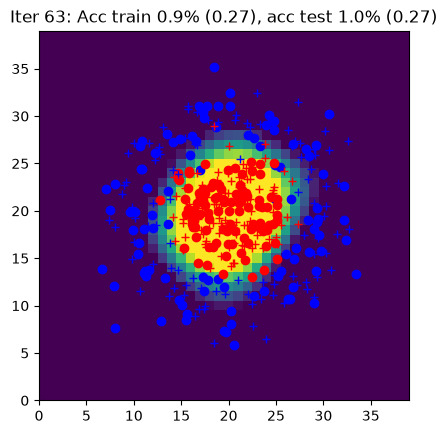

Iter 64: Acc train 0.9% (0.26), acc test 1.0% (0.26)


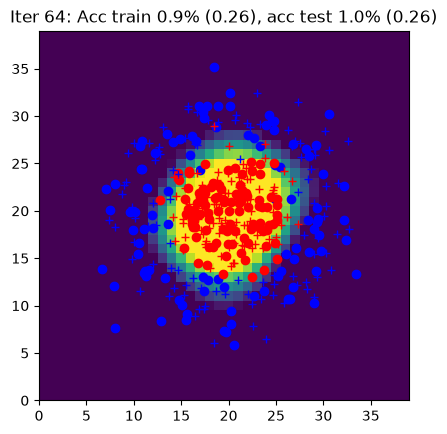

Iter 65: Acc train 0.9% (0.26), acc test 1.0% (0.26)


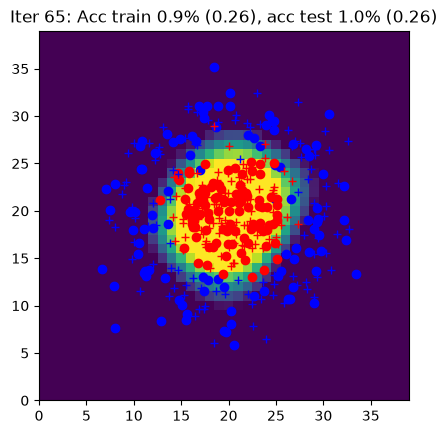

Iter 66: Acc train 0.9% (0.26), acc test 1.0% (0.26)


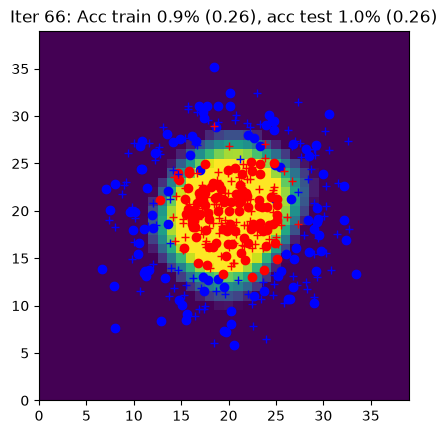

Iter 67: Acc train 0.9% (0.25), acc test 1.0% (0.25)


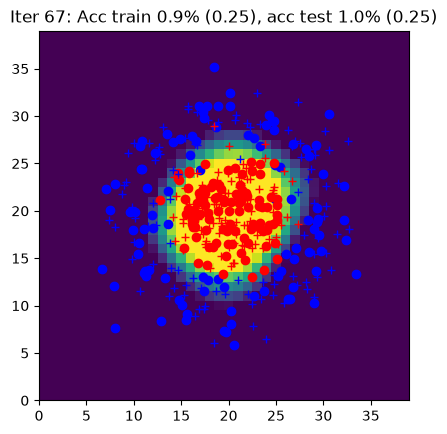

Iter 68: Acc train 0.9% (0.25), acc test 1.0% (0.25)


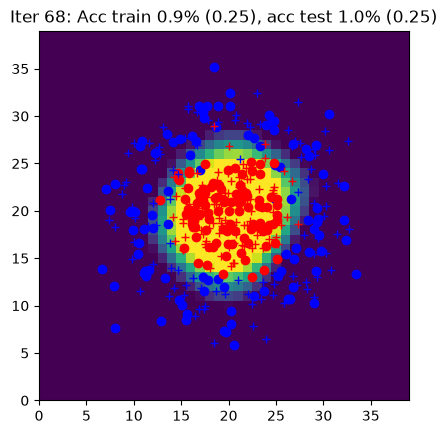

Iter 69: Acc train 0.9% (0.25), acc test 1.0% (0.25)


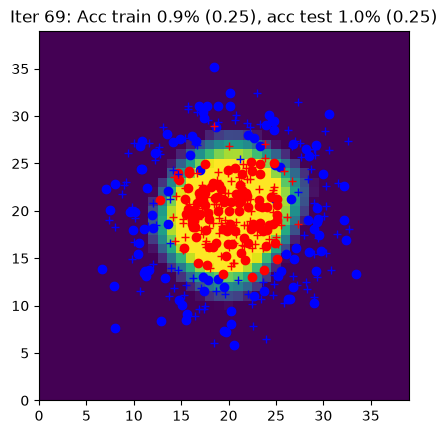

Iter 70: Acc train 0.9% (0.24), acc test 1.0% (0.25)


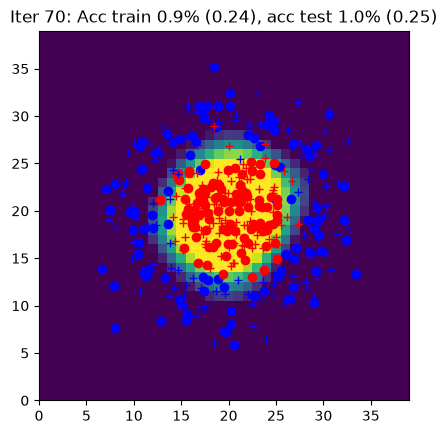

Iter 71: Acc train 0.9% (0.24), acc test 1.0% (0.24)


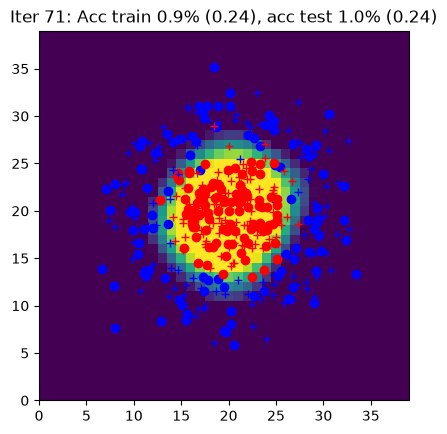

Iter 72: Acc train 0.9% (0.24), acc test 0.9% (0.24)


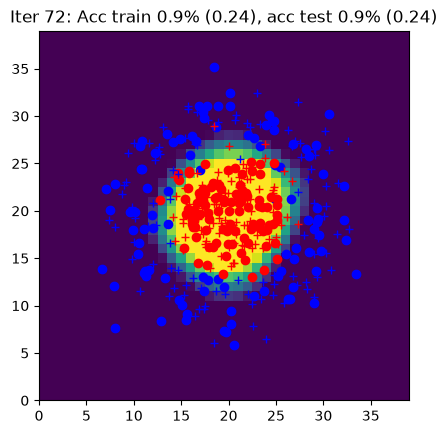

Iter 73: Acc train 0.9% (0.24), acc test 1.0% (0.24)


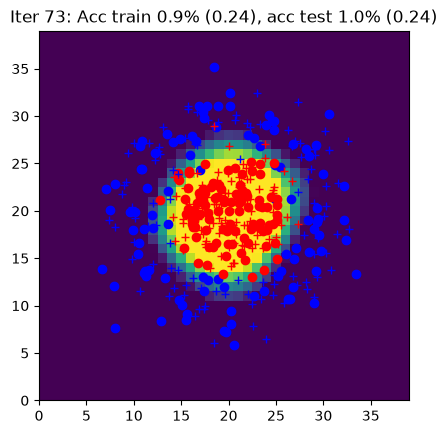

Iter 74: Acc train 0.9% (0.23), acc test 1.0% (0.24)


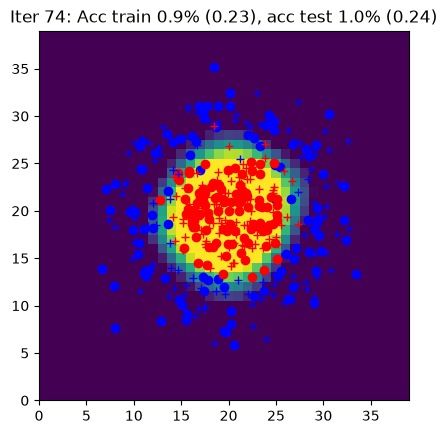

Iter 75: Acc train 0.9% (0.23), acc test 1.0% (0.23)


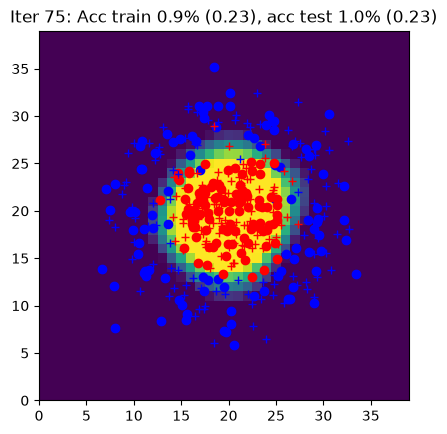

Iter 76: Acc train 0.9% (0.23), acc test 1.0% (0.23)


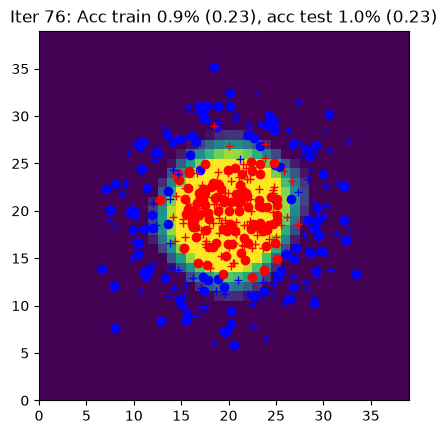

Iter 77: Acc train 0.9% (0.23), acc test 1.0% (0.23)


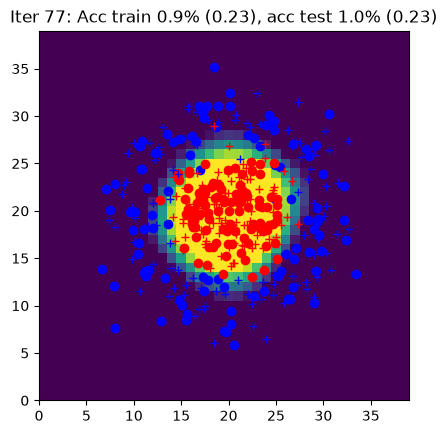

Iter 78: Acc train 0.9% (0.22), acc test 0.9% (0.23)


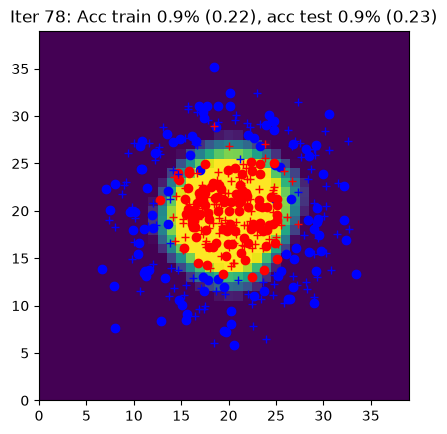

Iter 79: Acc train 0.9% (0.22), acc test 0.9% (0.23)


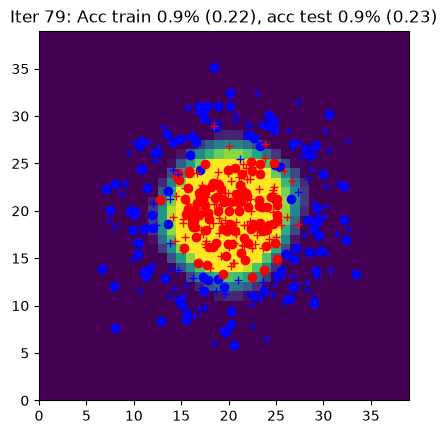

Iter 80: Acc train 0.9% (0.22), acc test 0.9% (0.22)


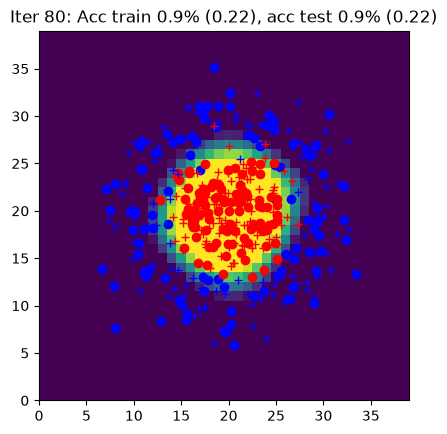

Iter 81: Acc train 0.9% (0.22), acc test 0.9% (0.22)


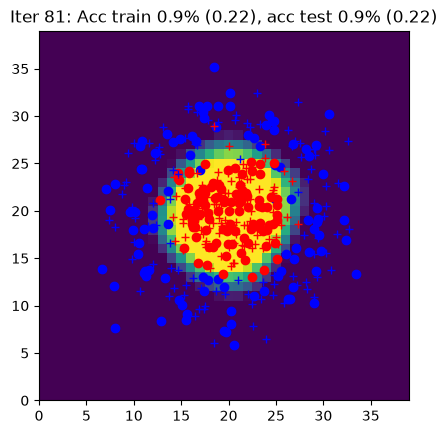

Iter 82: Acc train 0.9% (0.22), acc test 0.9% (0.22)


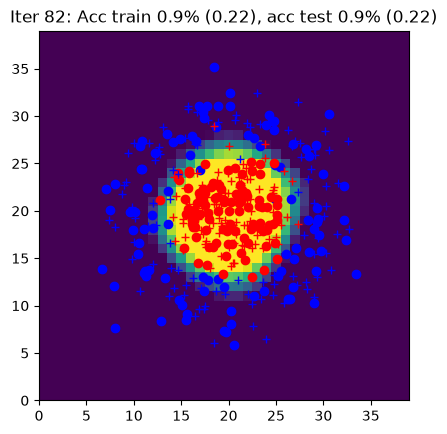

Iter 83: Acc train 0.9% (0.21), acc test 0.9% (0.22)


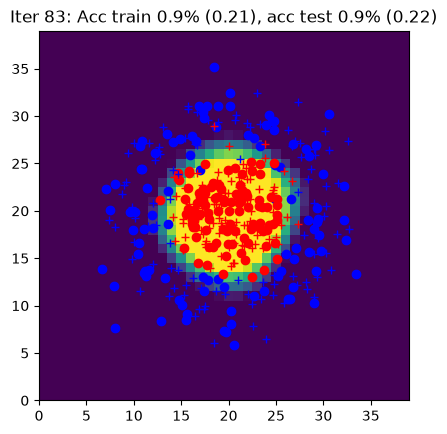

Iter 84: Acc train 0.9% (0.21), acc test 0.9% (0.22)


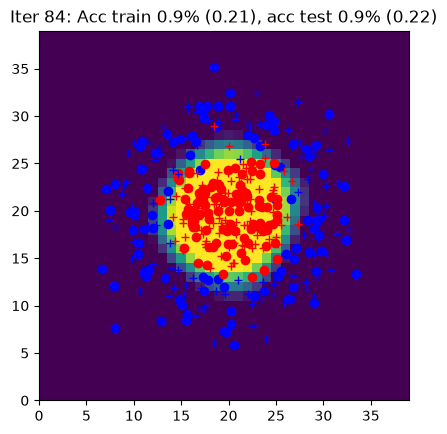

Iter 85: Acc train 0.9% (0.21), acc test 0.9% (0.22)


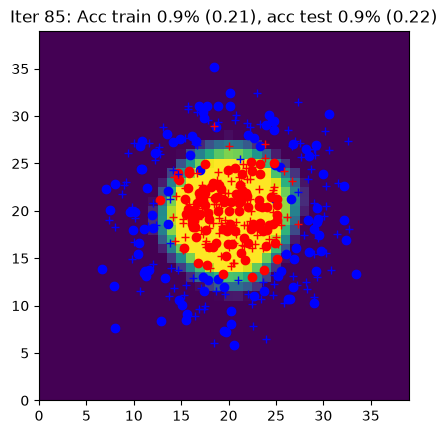

Iter 86: Acc train 0.9% (0.21), acc test 0.9% (0.21)


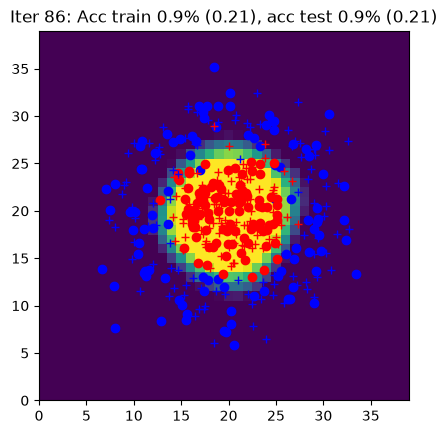

Iter 87: Acc train 0.9% (0.21), acc test 0.9% (0.21)


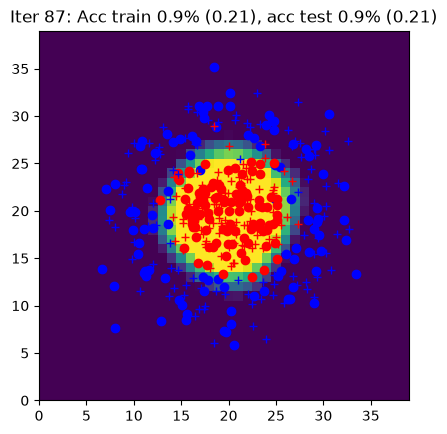

Iter 88: Acc train 0.9% (0.20), acc test 0.9% (0.21)


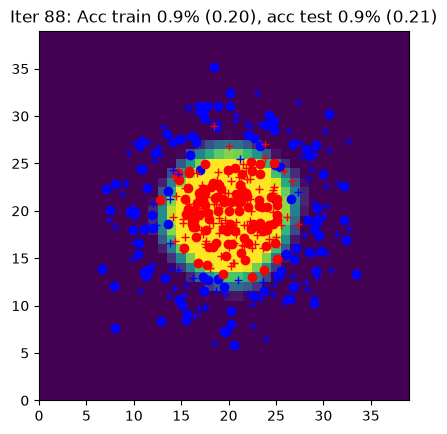

Iter 89: Acc train 0.9% (0.20), acc test 0.9% (0.21)


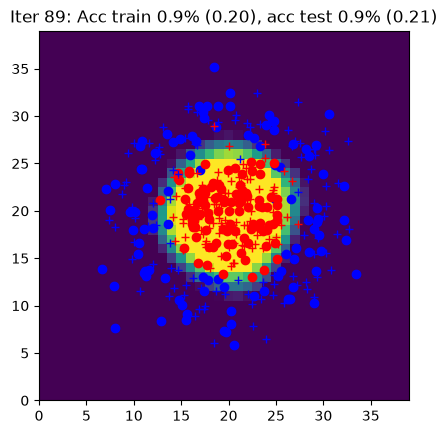

Iter 90: Acc train 1.0% (0.20), acc test 0.9% (0.21)


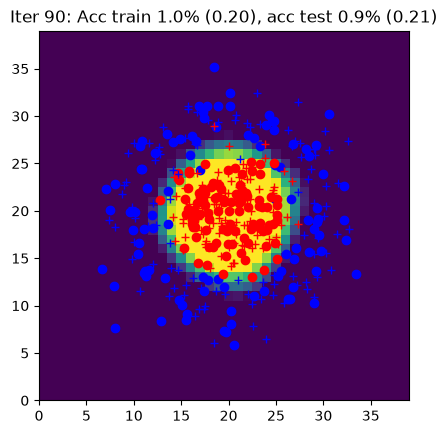

Iter 91: Acc train 1.0% (0.20), acc test 0.9% (0.21)


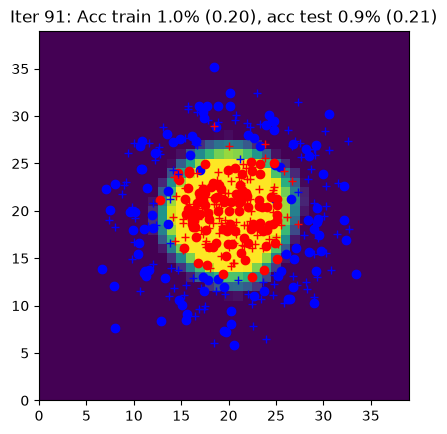

Iter 92: Acc train 0.9% (0.20), acc test 0.9% (0.20)


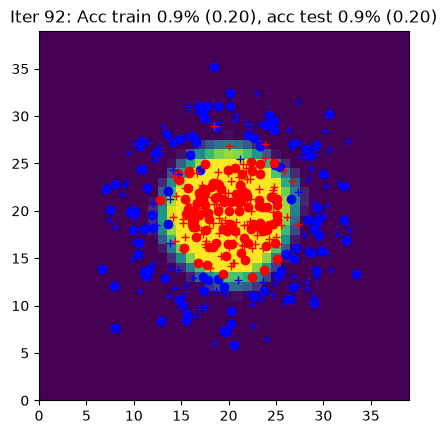

Iter 93: Acc train 0.9% (0.20), acc test 0.9% (0.20)


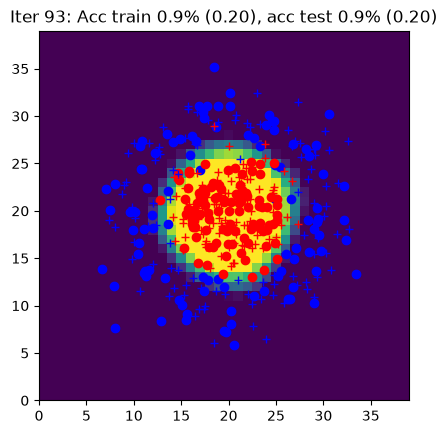

Iter 94: Acc train 0.9% (0.20), acc test 0.9% (0.20)


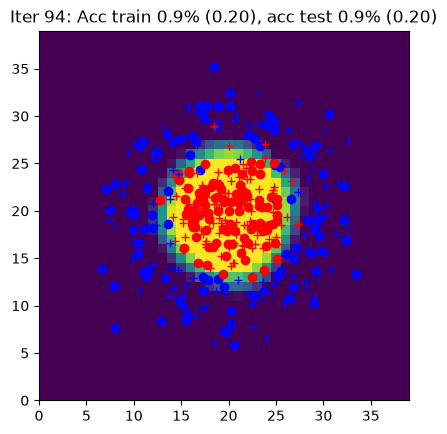

Iter 95: Acc train 1.0% (0.19), acc test 0.9% (0.20)


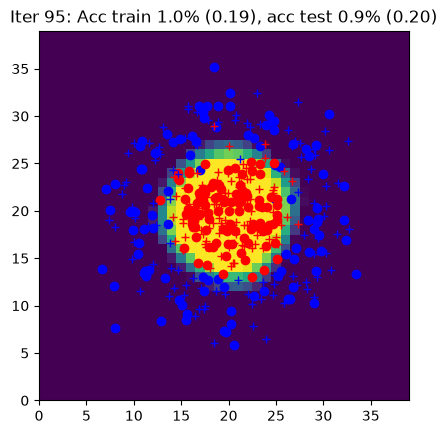

Iter 96: Acc train 1.0% (0.19), acc test 0.9% (0.20)


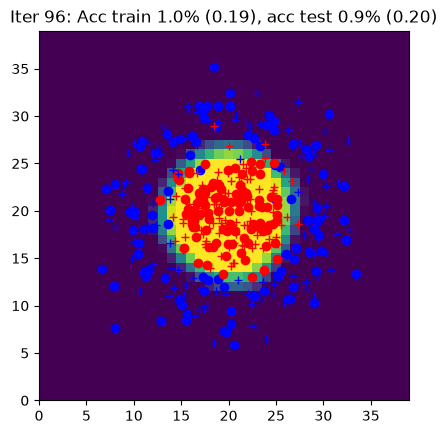

Iter 97: Acc train 0.9% (0.19), acc test 0.9% (0.20)


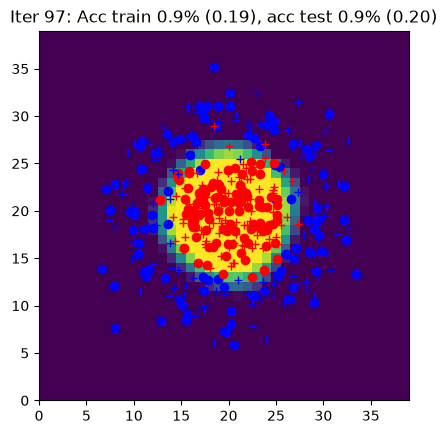

Iter 98: Acc train 1.0% (0.19), acc test 0.9% (0.20)


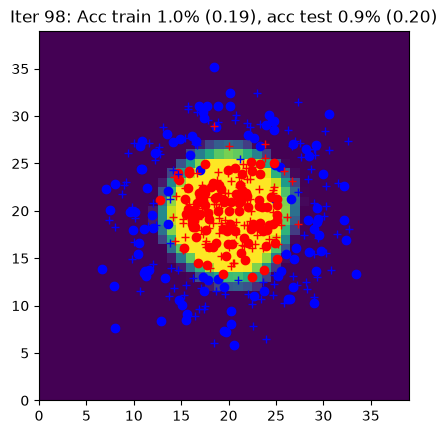

Iter 99: Acc train 1.0% (0.19), acc test 0.9% (0.20)


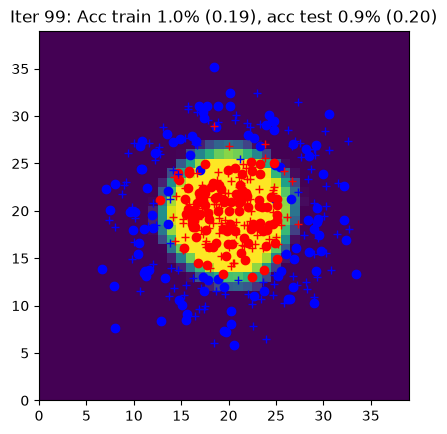

Iter 100: Acc train 1.0% (0.19), acc test 0.9% (0.19)


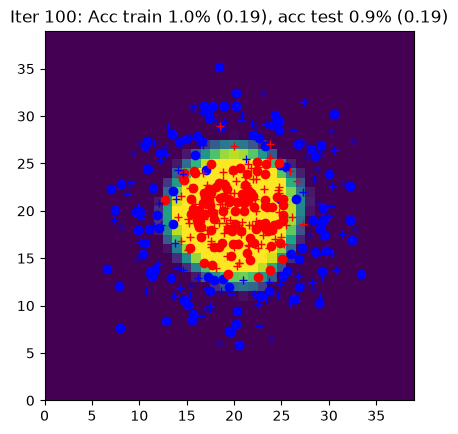

Iter 101: Acc train 1.0% (0.19), acc test 0.9% (0.19)


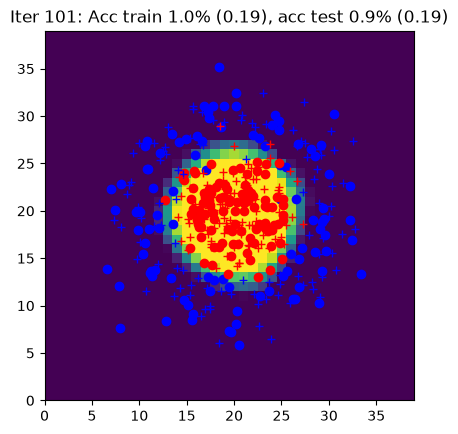

Iter 102: Acc train 1.0% (0.18), acc test 0.9% (0.19)


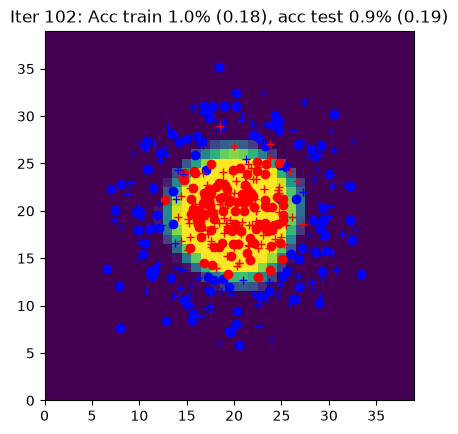

Iter 103: Acc train 1.0% (0.18), acc test 0.9% (0.19)


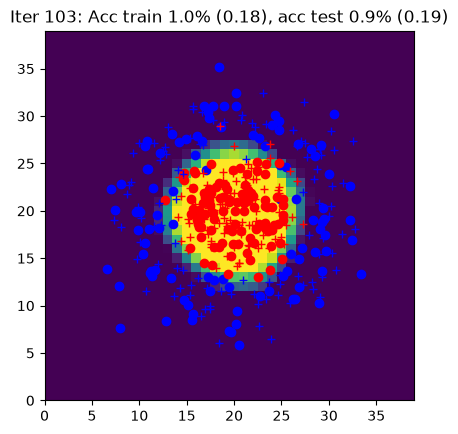

Iter 104: Acc train 1.0% (0.18), acc test 0.9% (0.19)


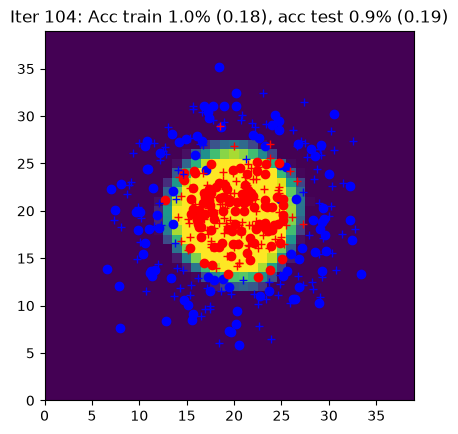

Iter 105: Acc train 1.0% (0.18), acc test 0.9% (0.19)


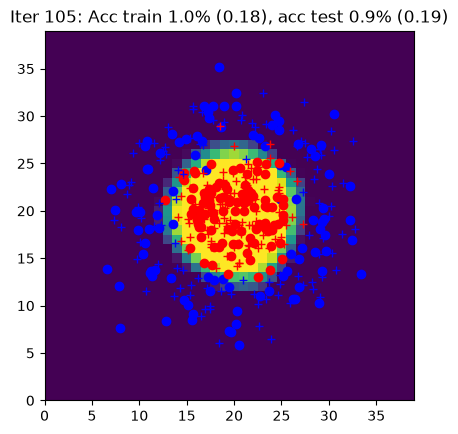

Iter 106: Acc train 1.0% (0.18), acc test 0.9% (0.19)


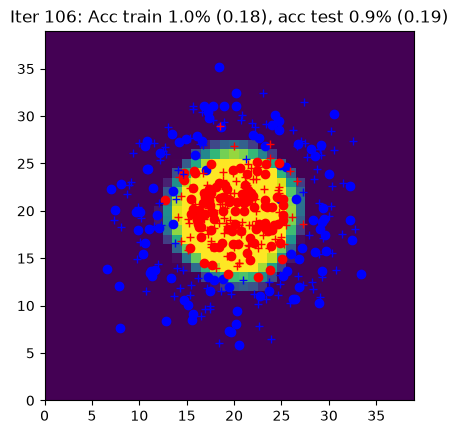

Iter 107: Acc train 1.0% (0.18), acc test 0.9% (0.19)


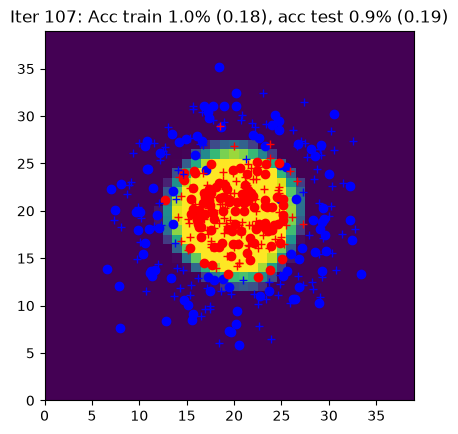

Iter 108: Acc train 1.0% (0.18), acc test 0.9% (0.19)


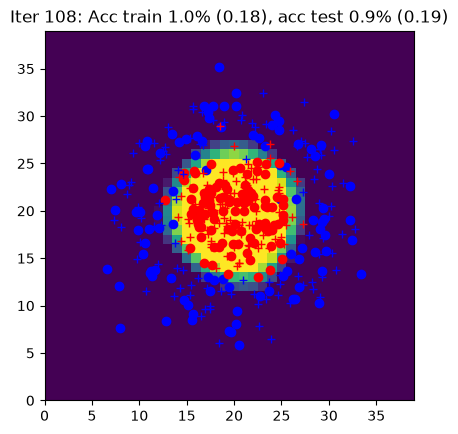

Iter 109: Acc train 1.0% (0.18), acc test 0.9% (0.19)


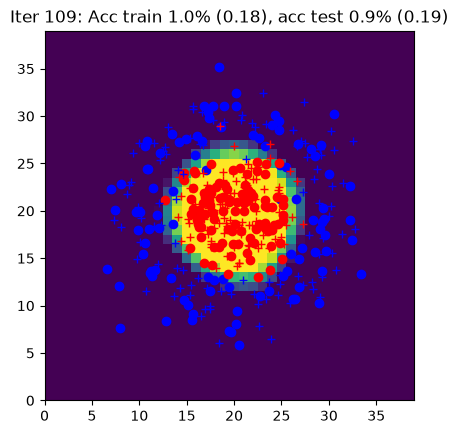

Iter 110: Acc train 1.0% (0.18), acc test 0.9% (0.18)


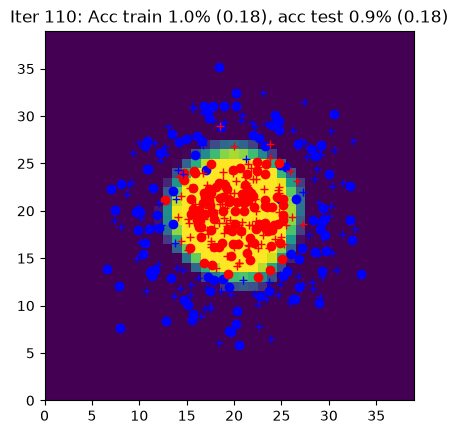

Iter 111: Acc train 1.0% (0.17), acc test 0.9% (0.18)


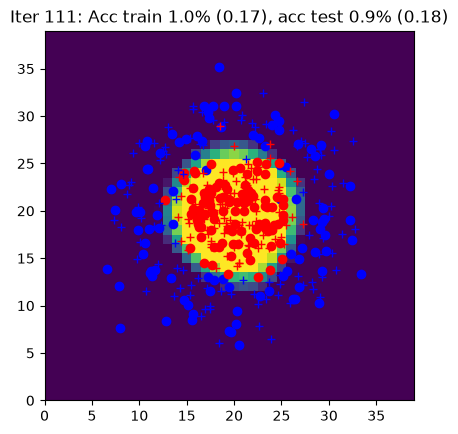

Iter 112: Acc train 1.0% (0.17), acc test 0.9% (0.18)


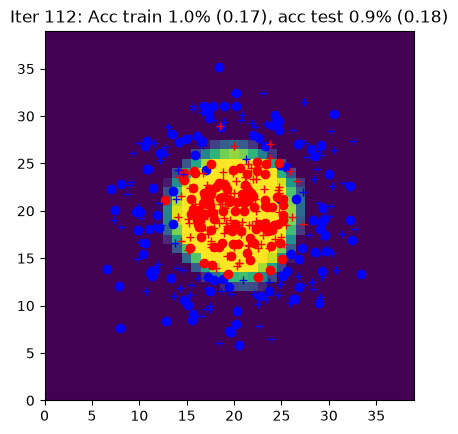

Iter 113: Acc train 1.0% (0.17), acc test 0.9% (0.18)


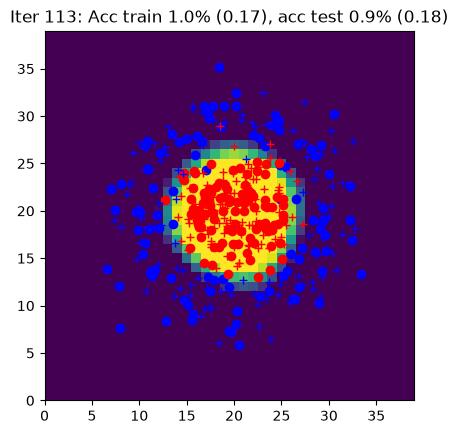

Iter 114: Acc train 1.0% (0.17), acc test 0.9% (0.18)


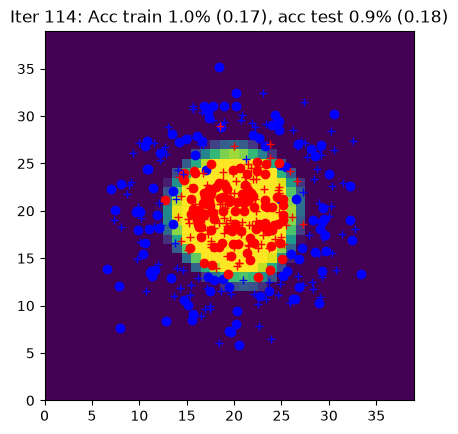

Iter 115: Acc train 1.0% (0.17), acc test 0.9% (0.18)


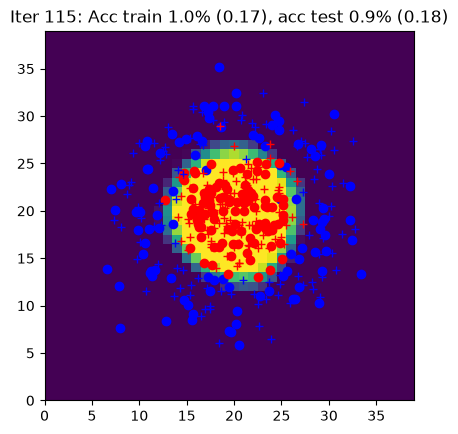

Iter 116: Acc train 1.0% (0.17), acc test 0.9% (0.18)


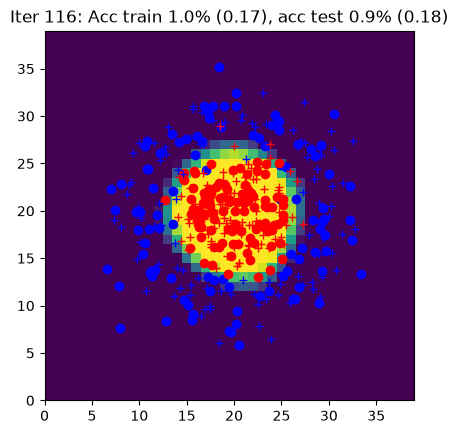

Iter 117: Acc train 1.0% (0.17), acc test 0.9% (0.18)


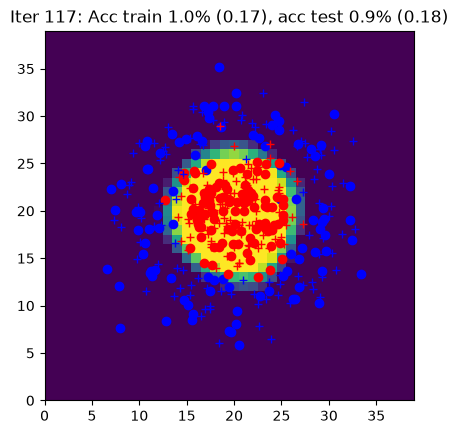

Iter 118: Acc train 1.0% (0.17), acc test 0.9% (0.18)


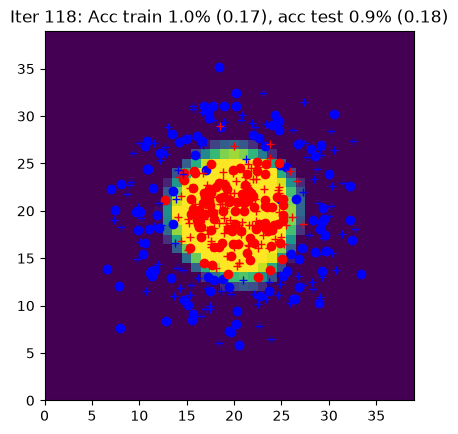

Iter 119: Acc train 1.0% (0.17), acc test 0.9% (0.18)


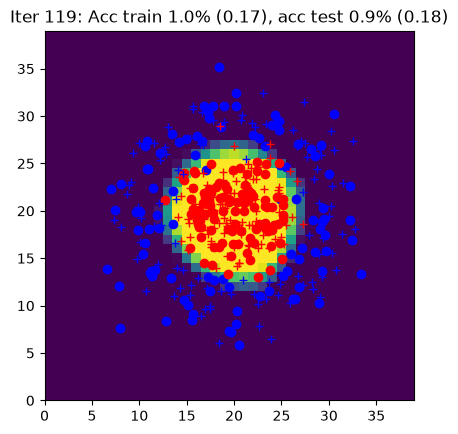

Iter 120: Acc train 1.0% (0.17), acc test 0.9% (0.18)


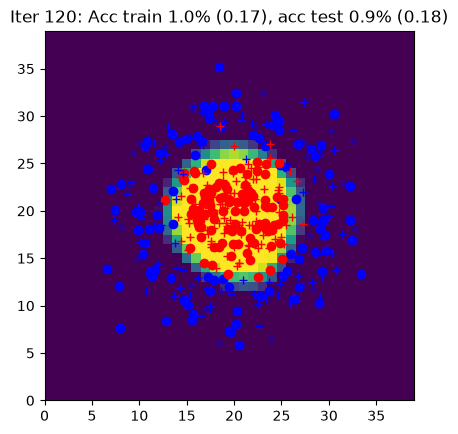

Iter 121: Acc train 1.0% (0.17), acc test 0.9% (0.18)


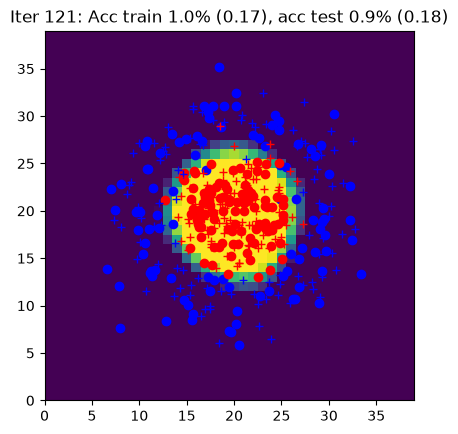

Iter 122: Acc train 1.0% (0.16), acc test 0.9% (0.18)


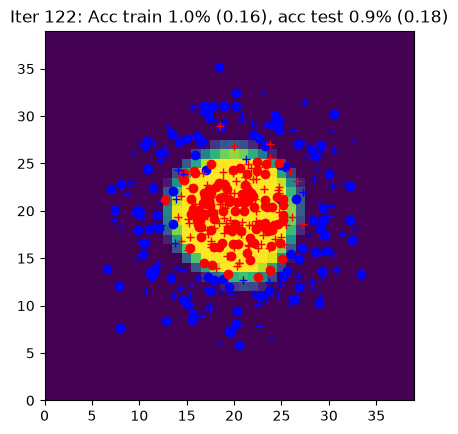

Iter 123: Acc train 1.0% (0.16), acc test 0.9% (0.18)


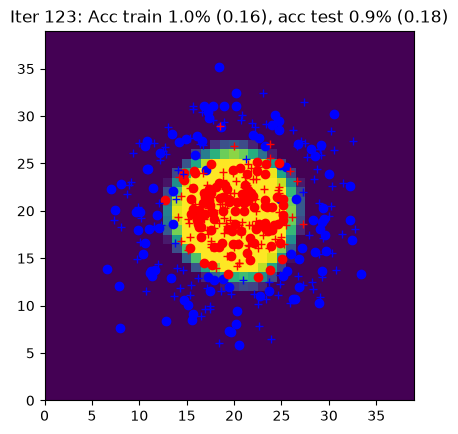

Iter 124: Acc train 1.0% (0.16), acc test 0.9% (0.18)


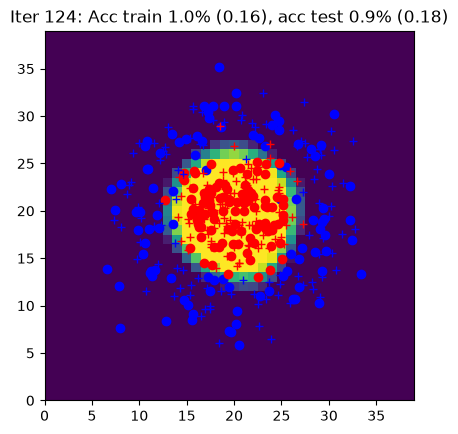

Iter 125: Acc train 1.0% (0.16), acc test 0.9% (0.18)


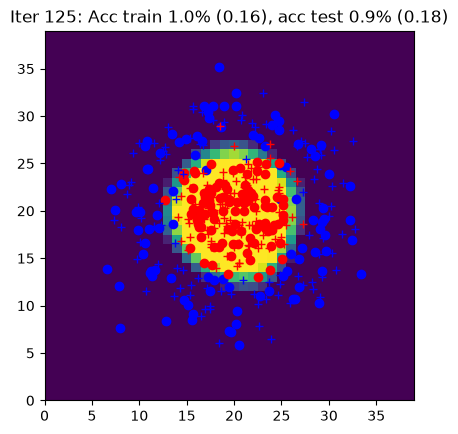

Iter 126: Acc train 1.0% (0.16), acc test 0.9% (0.17)


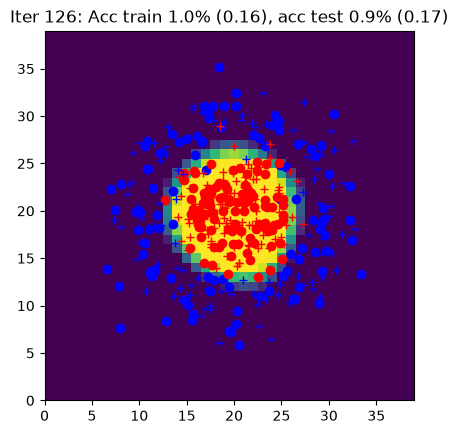

Iter 127: Acc train 1.0% (0.16), acc test 0.9% (0.17)


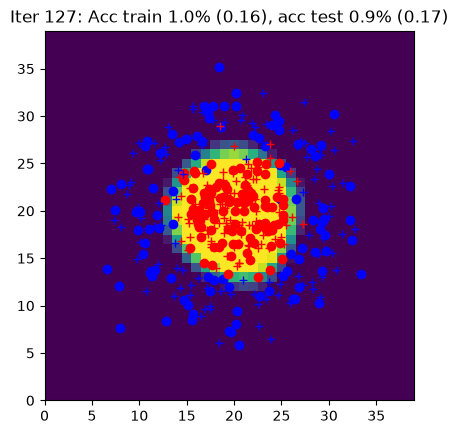

Iter 128: Acc train 1.0% (0.16), acc test 0.9% (0.17)


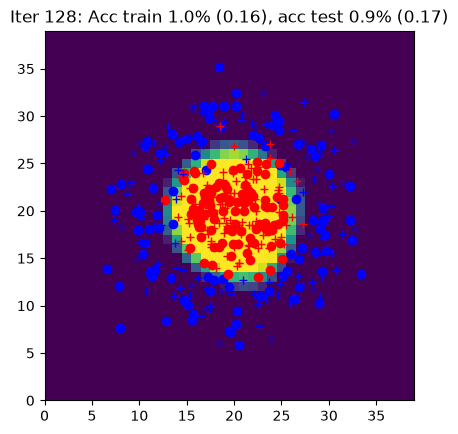

Iter 129: Acc train 1.0% (0.16), acc test 0.9% (0.17)


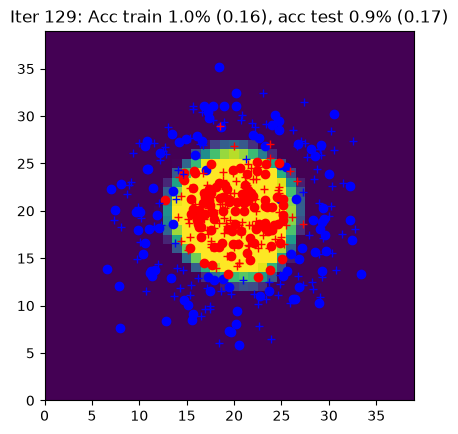

Iter 130: Acc train 1.0% (0.16), acc test 0.9% (0.17)


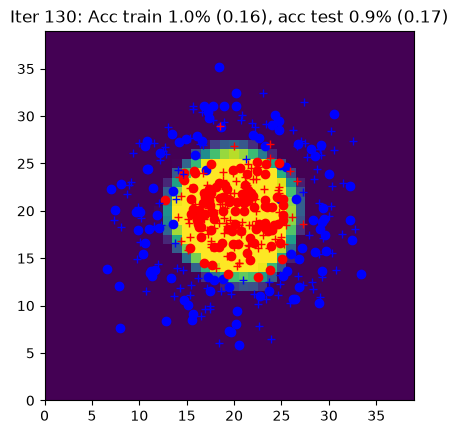

Iter 131: Acc train 1.0% (0.16), acc test 0.9% (0.17)


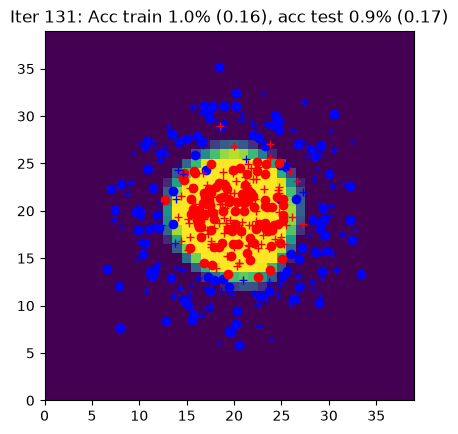

Iter 132: Acc train 1.0% (0.16), acc test 0.9% (0.17)


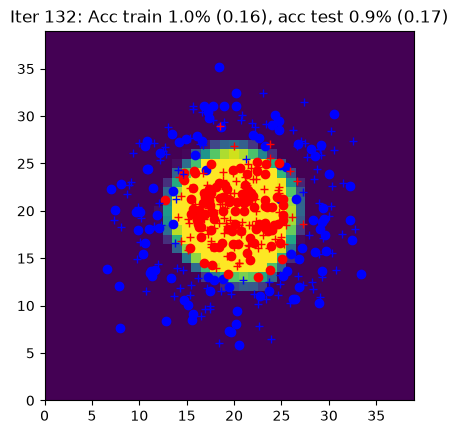

Iter 133: Acc train 1.0% (0.16), acc test 0.9% (0.17)


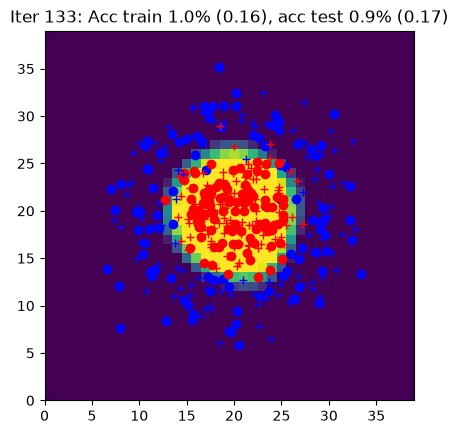

Iter 134: Acc train 1.0% (0.16), acc test 0.9% (0.17)


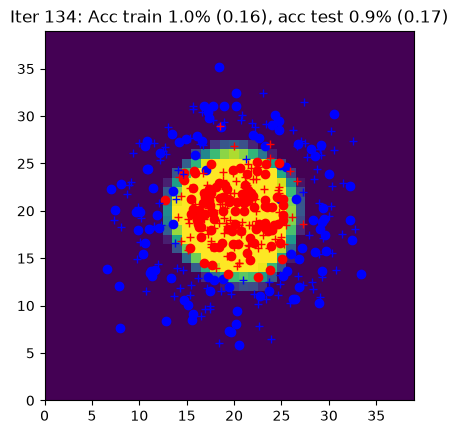

Iter 135: Acc train 1.0% (0.16), acc test 0.9% (0.17)


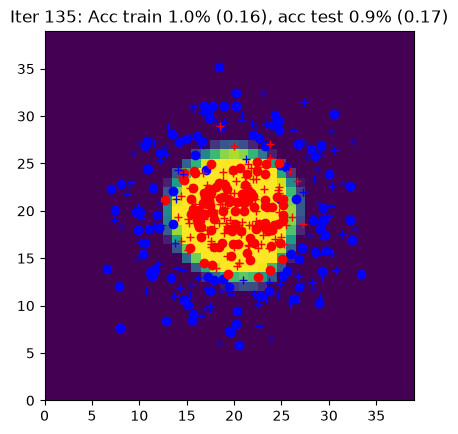

Iter 136: Acc train 1.0% (0.15), acc test 0.9% (0.17)


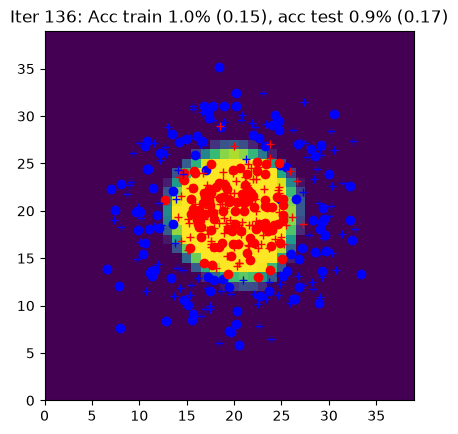

Iter 137: Acc train 1.0% (0.15), acc test 0.9% (0.17)


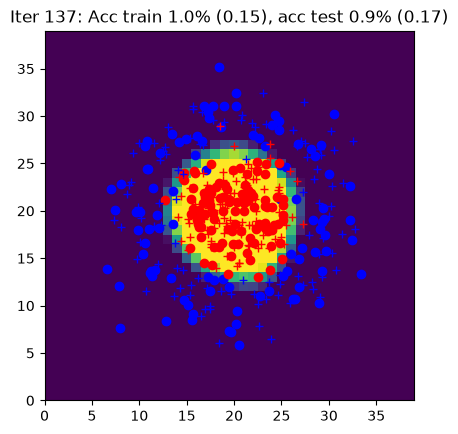

Iter 138: Acc train 1.0% (0.15), acc test 0.9% (0.17)


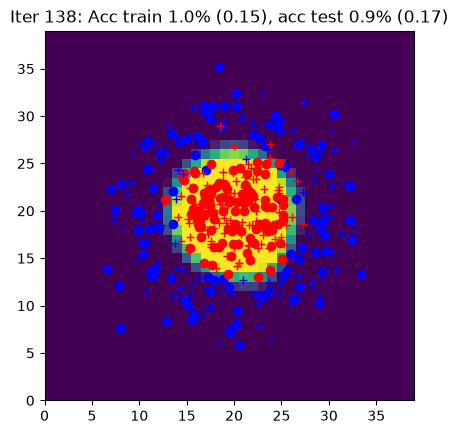

Iter 139: Acc train 1.0% (0.15), acc test 0.9% (0.17)


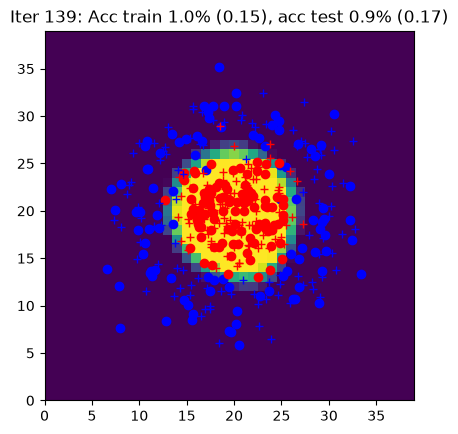

Iter 140: Acc train 1.0% (0.15), acc test 0.9% (0.17)


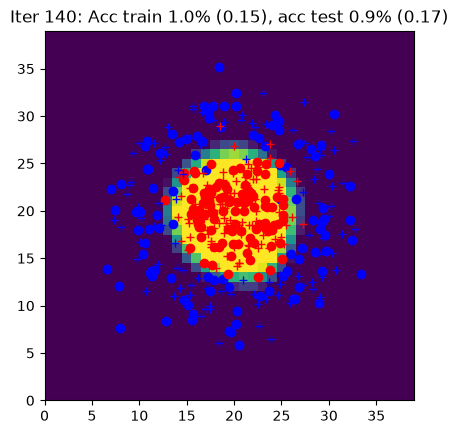

Iter 141: Acc train 1.0% (0.15), acc test 0.9% (0.17)


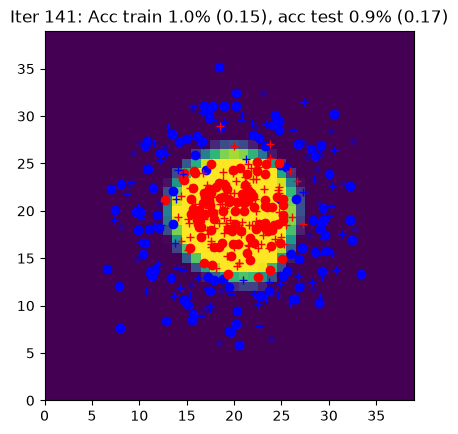

Iter 142: Acc train 1.0% (0.15), acc test 0.9% (0.17)


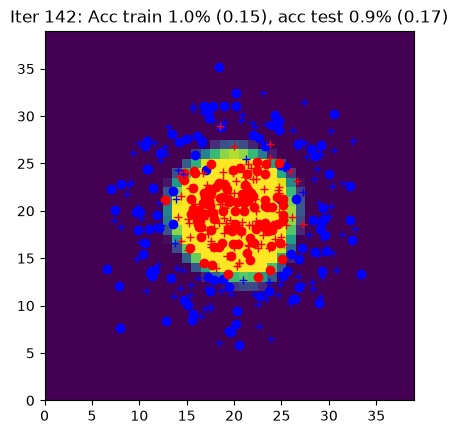

Iter 143: Acc train 1.0% (0.15), acc test 0.9% (0.17)


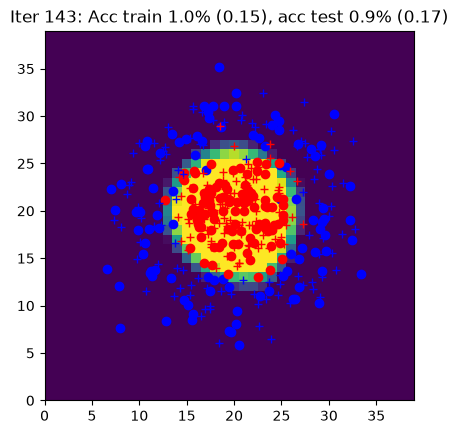

Iter 144: Acc train 1.0% (0.15), acc test 0.9% (0.17)


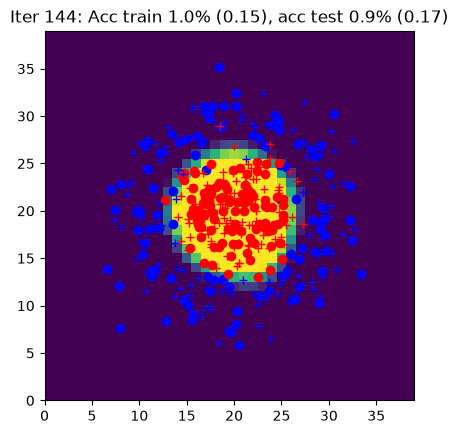

Iter 145: Acc train 1.0% (0.15), acc test 0.9% (0.17)


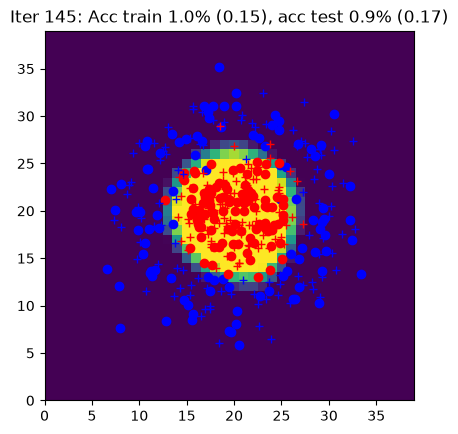

Iter 146: Acc train 1.0% (0.15), acc test 0.9% (0.16)


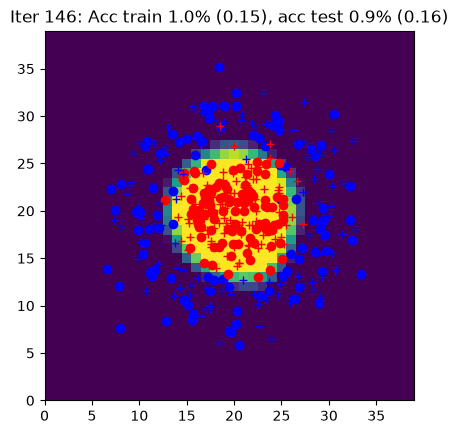

Iter 147: Acc train 1.0% (0.15), acc test 0.9% (0.16)


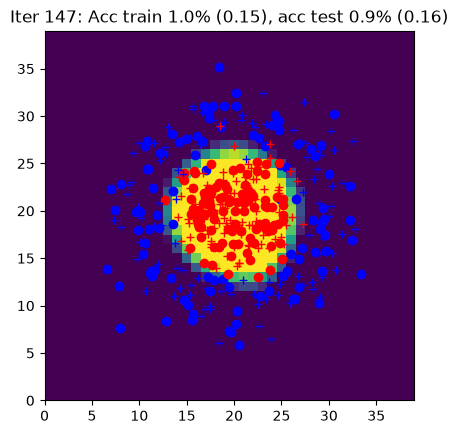

Iter 148: Acc train 1.0% (0.15), acc test 0.9% (0.16)


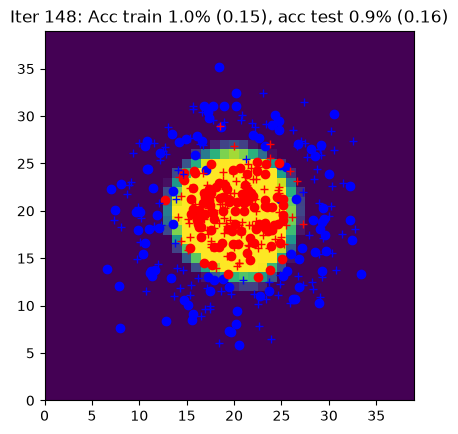

Iter 149: Acc train 1.0% (0.15), acc test 0.9% (0.16)


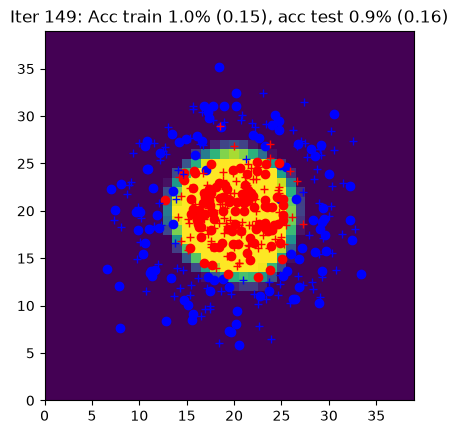

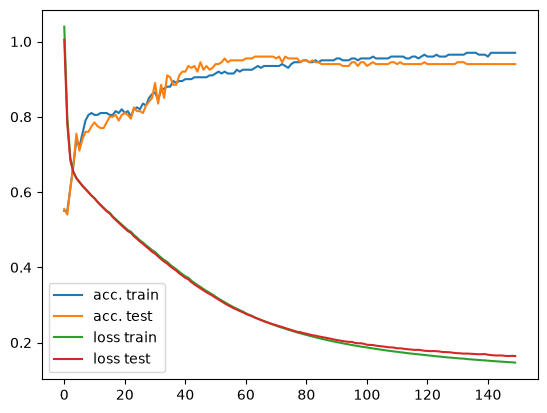

In [96]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

params = init_params(nx, nh, ny)

curves = [[], [], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code here  ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j + 1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: forward, loss_accuracy, sgd
        # and the backward function with autograd
        Yhat, outputs = forward(params, X)
        L, acc = loss_accuracy(Yhat, Y)
        L.backward()
        params = sgd(params, eta)

    ####################
    ##      END        #
    ####################

    Yhat_train, _ = forward(params, data.Xtrain)
    Yhat_test, _ = forward(params, data.Xtest)
    Ltrain, acctrain = loss_accuracy(Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(Yhat_test, data.Ytest)
    Ygrid, _ = forward(params, data.Xgrid)

    title = "Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})".format(
        iteration, acctrain, Ltrain, acctest, Ltest
    )
    print(title)
    # detach() is used to remove the predictions from the computational graph in autograd
    data.plot_data_with_grid(Ygrid.detach(), title)

    curves[0].append(acctrain.item())
    curves[1].append(acctest.item())
    curves[2].append(Ltrain.item())
    curves[3].append(Ltest.item())

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 3 : Simplification of the forward pass with `torch.nn`

`init_params` and `forward` are replaced by the `init_model` function which defines the network architecture and the loss.

In [97]:
def init_model(nx, nh, ny):

    #####################
    ## Your code here  ##
    #####################

    model = torch.nn.Sequential(
        torch.nn.Linear(nx, nh),
        torch.nn.Tanh(),
        torch.nn.Linear(nh, ny),
    )
    loss = torch.nn.CrossEntropyLoss()

    ####################
    ##      END        #
    ####################

    return model, loss

In [98]:
def loss_accuracy(loss, Yhat, Y):

    #####################
    ## Your code here  ##
    #####################
    # call the loss function
    L = 0
    acc = 0

    _, indsY = torch.max(Y, 1)
    _, indsYhat = torch.max(Yhat, 1)

    L = loss(Yhat, indsY)
    acc = torch.mean((indsYhat == indsY).float())

    ####################
    ##      END        #
    ####################

    return L, acc

In [99]:
def sgd(model, eta):

    #####################
    ## Your code here  ##
    #####################
    # update the network weights
    # warning: use torch.no_grad()
    # and reset to zero the gradient accumulators
    with torch.no_grad():
        for param in model.parameters():
            param -= eta * param.grad

    model.zero_grad()

    ####################
    ##      END        #
    ####################
    return model

## Global learning procedure with autograd and `torch.nn`

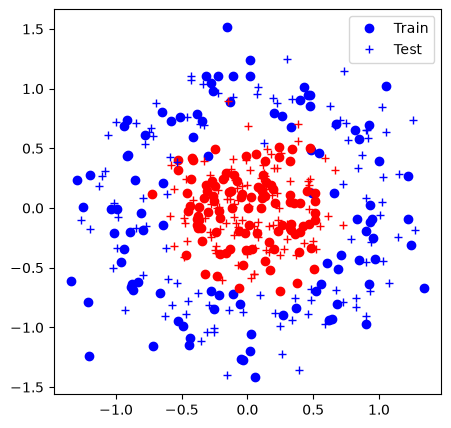

Iter 0: Acc train 0.6% (0.70), acc test 0.7% (0.70)


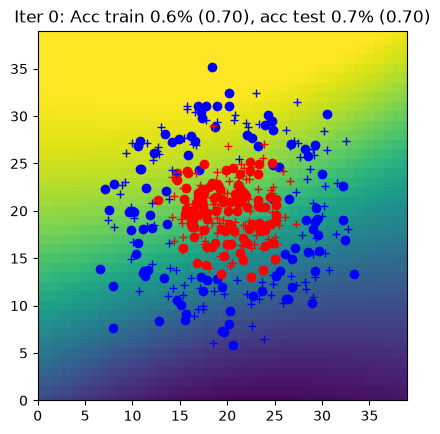

Iter 1: Acc train 0.6% (0.70), acc test 0.6% (0.69)


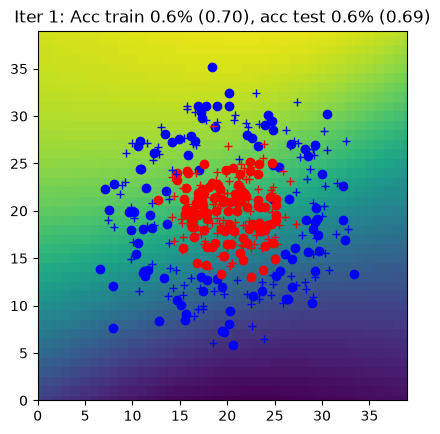

Iter 2: Acc train 0.6% (0.69), acc test 0.6% (0.69)


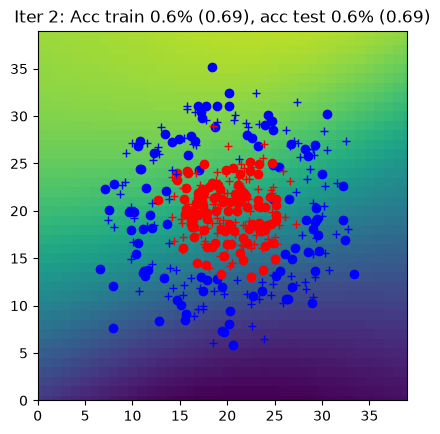

Iter 3: Acc train 0.6% (0.69), acc test 0.6% (0.69)


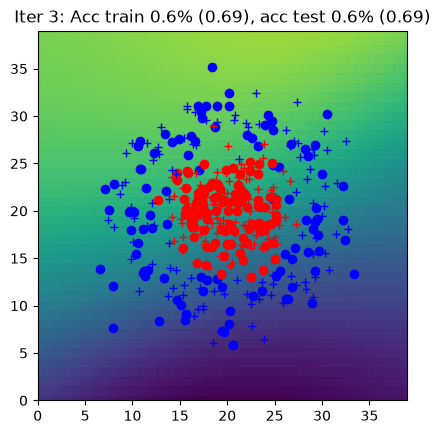

Iter 4: Acc train 0.6% (0.69), acc test 0.6% (0.69)


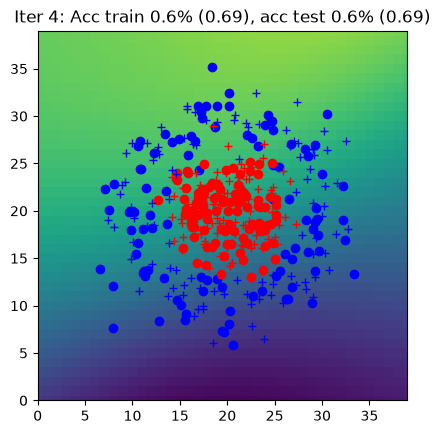

Iter 5: Acc train 0.6% (0.69), acc test 0.6% (0.68)


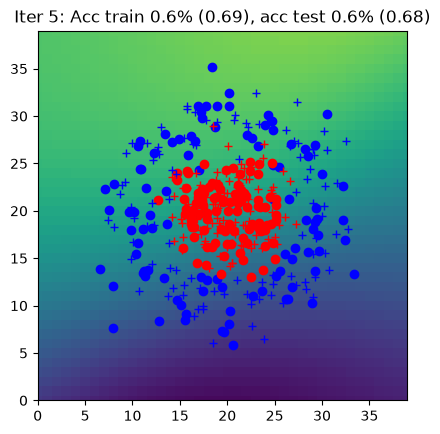

Iter 6: Acc train 0.6% (0.69), acc test 0.6% (0.68)


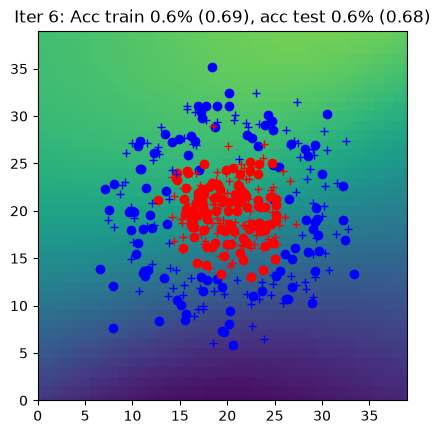

Iter 7: Acc train 0.6% (0.69), acc test 0.6% (0.68)


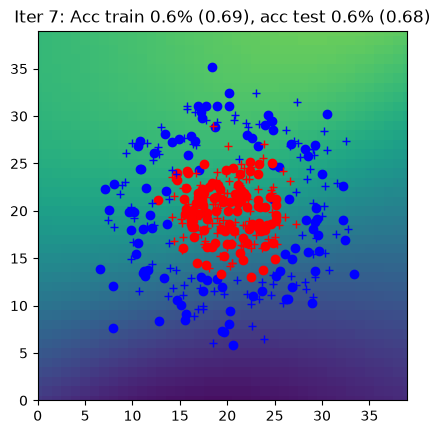

Iter 8: Acc train 0.6% (0.69), acc test 0.6% (0.68)


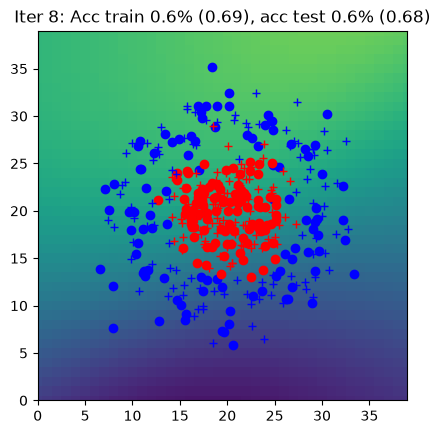

Iter 9: Acc train 0.6% (0.68), acc test 0.6% (0.68)


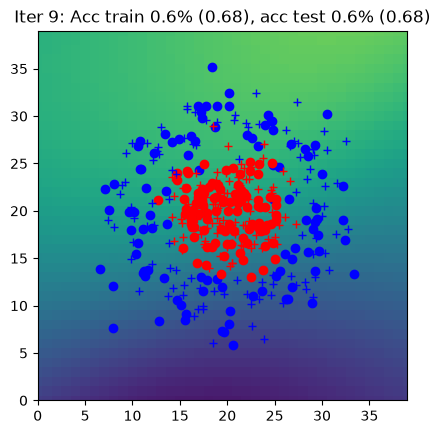

Iter 10: Acc train 0.6% (0.68), acc test 0.6% (0.68)


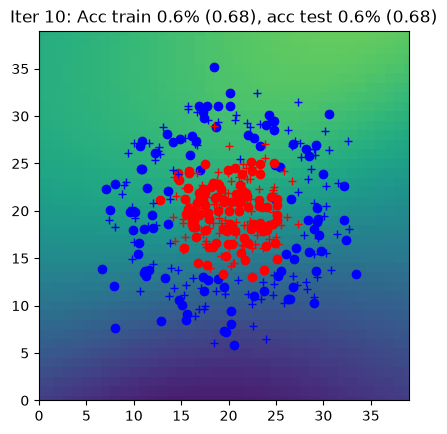

Iter 11: Acc train 0.6% (0.68), acc test 0.6% (0.68)


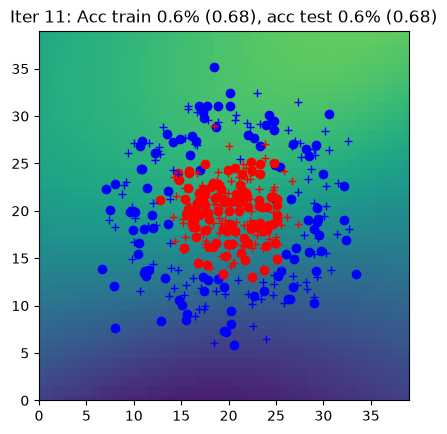

Iter 12: Acc train 0.6% (0.68), acc test 0.6% (0.68)


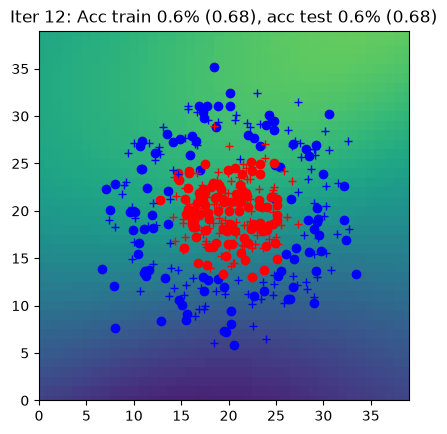

Iter 13: Acc train 0.6% (0.68), acc test 0.6% (0.68)


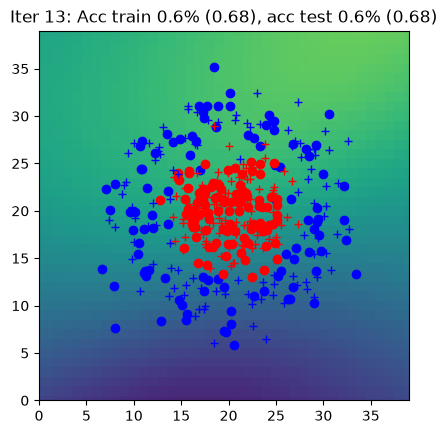

Iter 14: Acc train 0.6% (0.68), acc test 0.6% (0.68)


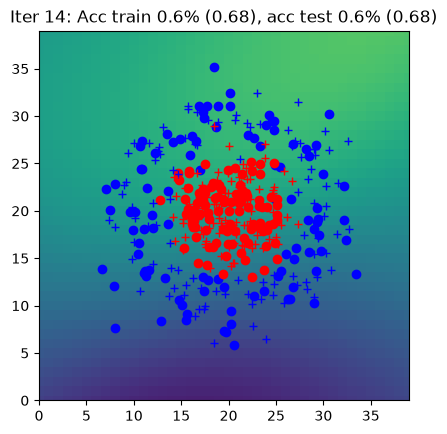

Iter 15: Acc train 0.6% (0.68), acc test 0.6% (0.68)


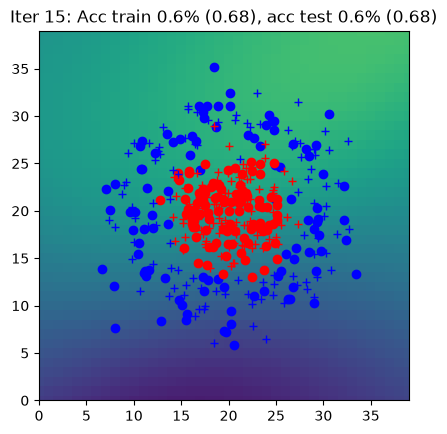

Iter 16: Acc train 0.6% (0.68), acc test 0.6% (0.68)


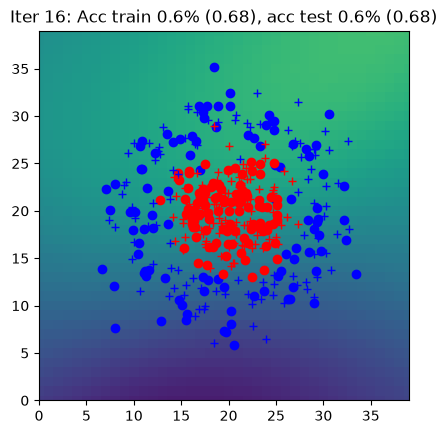

Iter 17: Acc train 0.6% (0.68), acc test 0.6% (0.68)


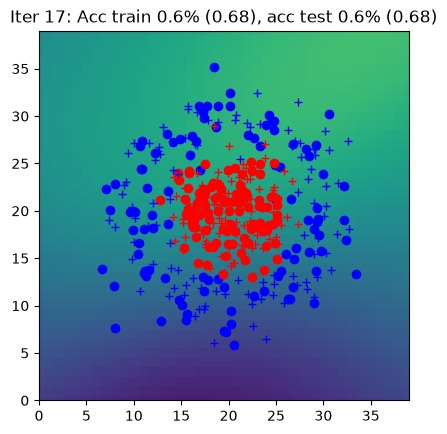

Iter 18: Acc train 0.6% (0.68), acc test 0.6% (0.68)


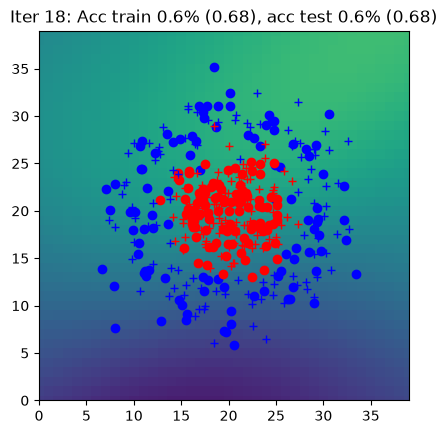

Iter 19: Acc train 0.6% (0.68), acc test 0.6% (0.68)


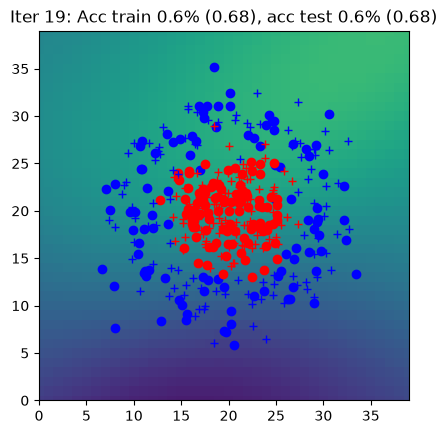

Iter 20: Acc train 0.6% (0.68), acc test 0.6% (0.68)


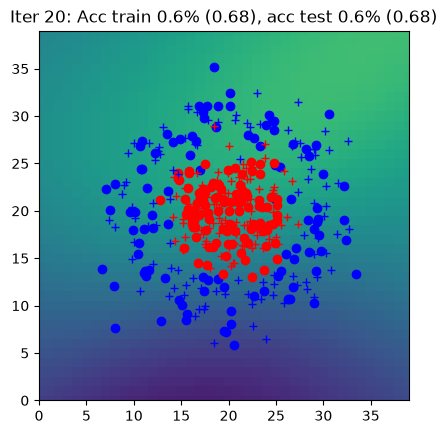

Iter 21: Acc train 0.6% (0.68), acc test 0.6% (0.68)


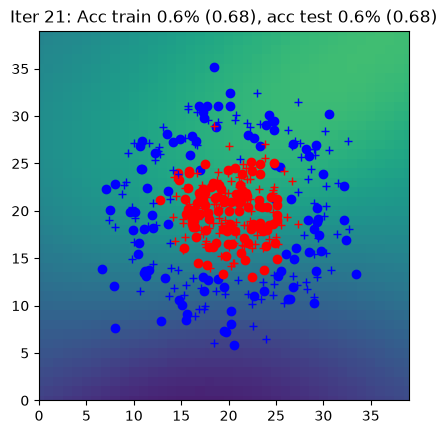

Iter 22: Acc train 0.6% (0.68), acc test 0.6% (0.67)


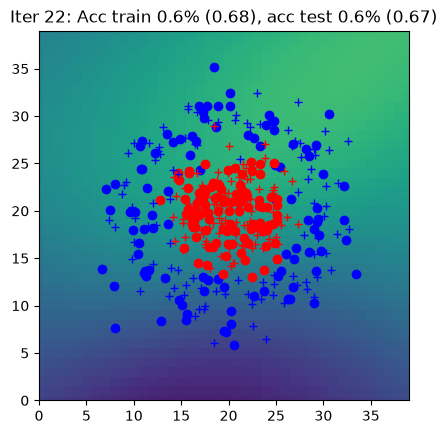

Iter 23: Acc train 0.6% (0.67), acc test 0.6% (0.67)


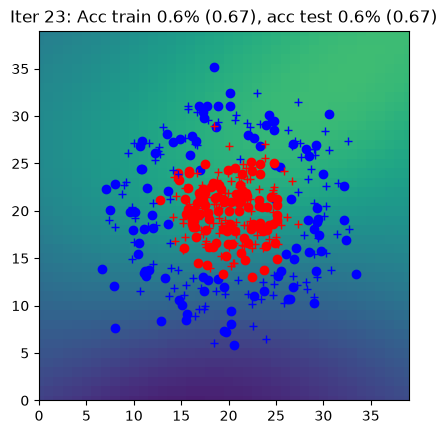

Iter 24: Acc train 0.6% (0.67), acc test 0.6% (0.67)


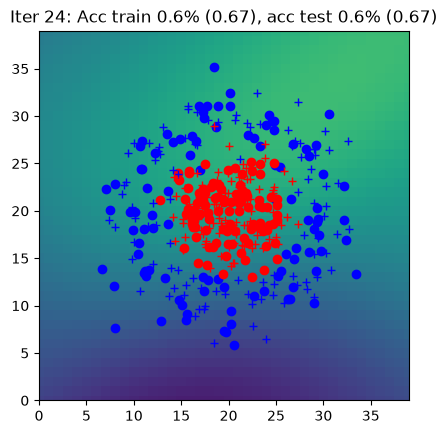

Iter 25: Acc train 0.6% (0.67), acc test 0.6% (0.67)


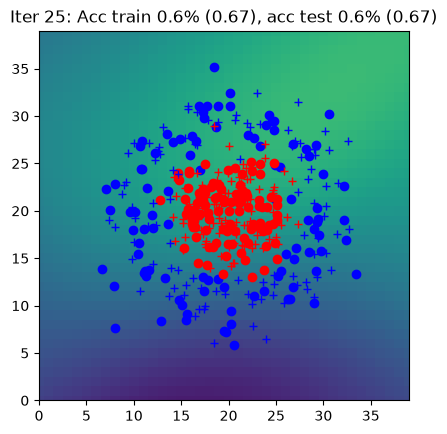

Iter 26: Acc train 0.6% (0.67), acc test 0.6% (0.67)


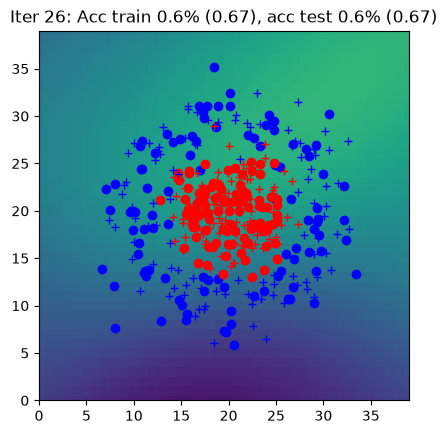

Iter 27: Acc train 0.6% (0.67), acc test 0.6% (0.67)


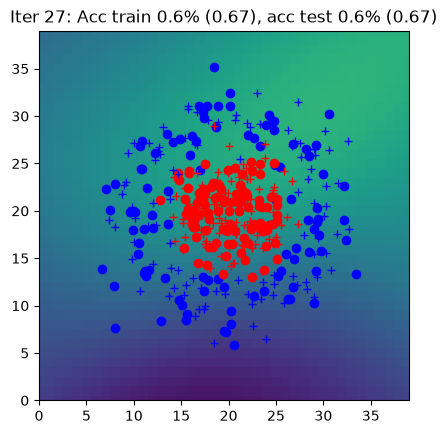

Iter 28: Acc train 0.6% (0.67), acc test 0.6% (0.67)


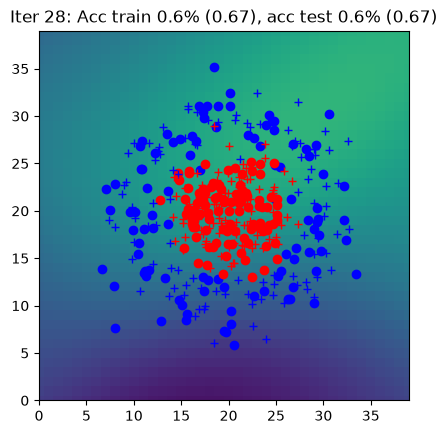

Iter 29: Acc train 0.6% (0.67), acc test 0.6% (0.67)


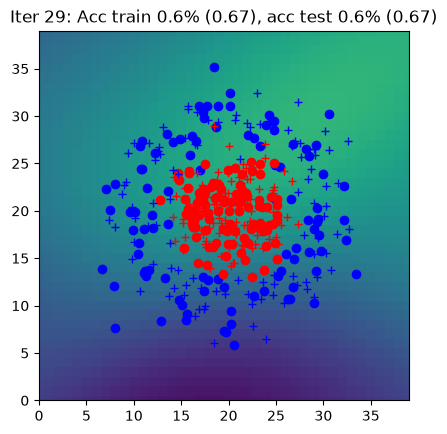

Iter 30: Acc train 0.6% (0.67), acc test 0.7% (0.67)


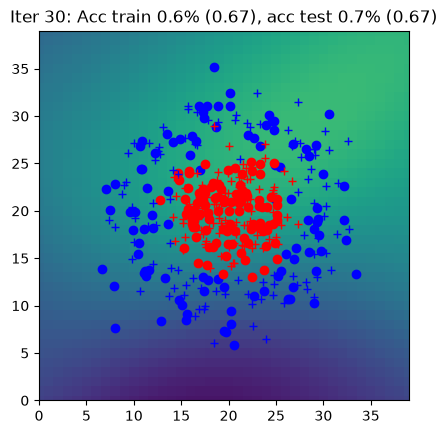

Iter 31: Acc train 0.7% (0.67), acc test 0.7% (0.67)


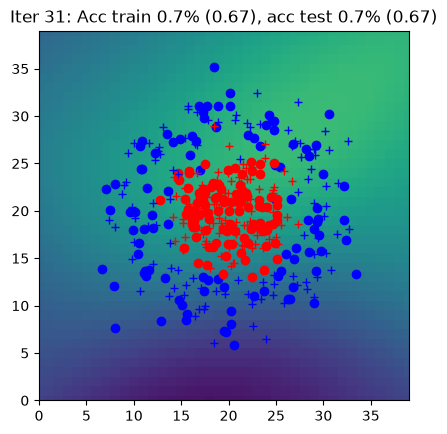

Iter 32: Acc train 0.7% (0.67), acc test 0.7% (0.66)


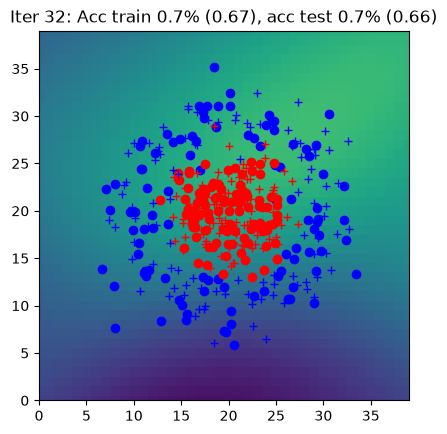

Iter 33: Acc train 0.7% (0.66), acc test 0.7% (0.66)


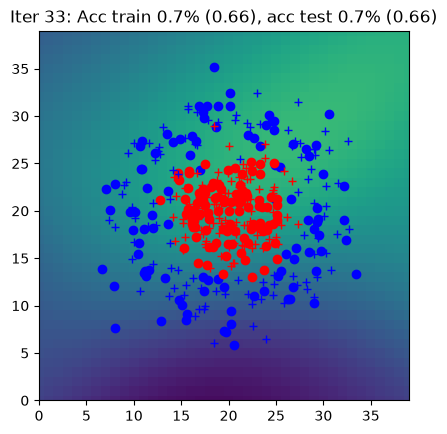

Iter 34: Acc train 0.7% (0.66), acc test 0.7% (0.66)


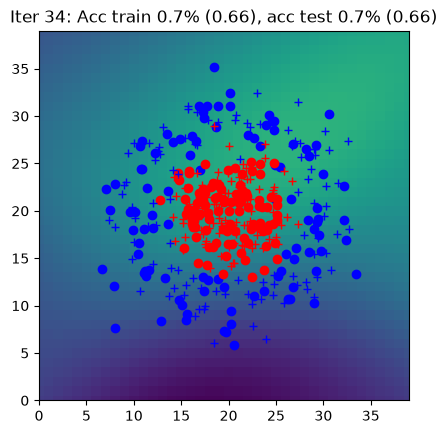

Iter 35: Acc train 0.7% (0.66), acc test 0.7% (0.66)


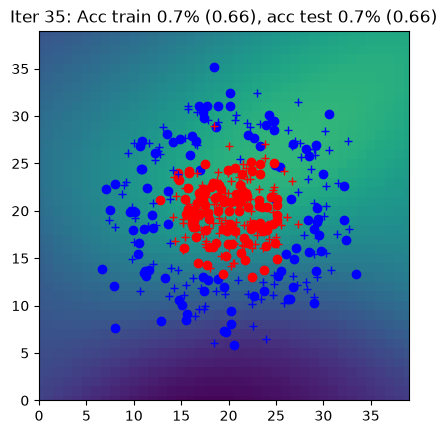

Iter 36: Acc train 0.7% (0.66), acc test 0.7% (0.66)


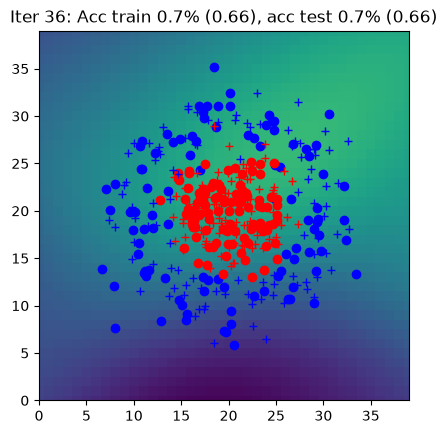

Iter 37: Acc train 0.7% (0.66), acc test 0.7% (0.66)


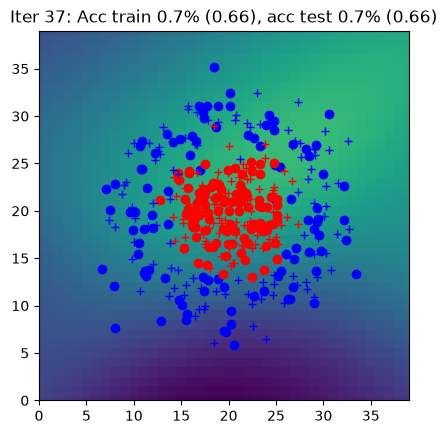

Iter 38: Acc train 0.7% (0.66), acc test 0.7% (0.66)


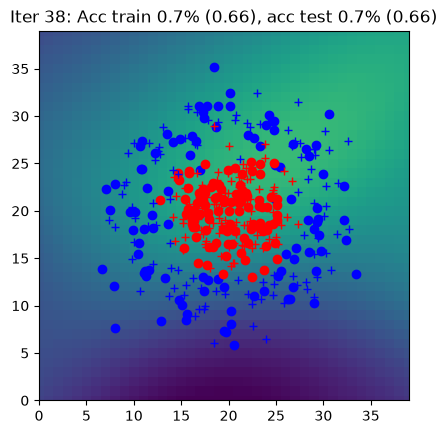

Iter 39: Acc train 0.7% (0.65), acc test 0.7% (0.65)


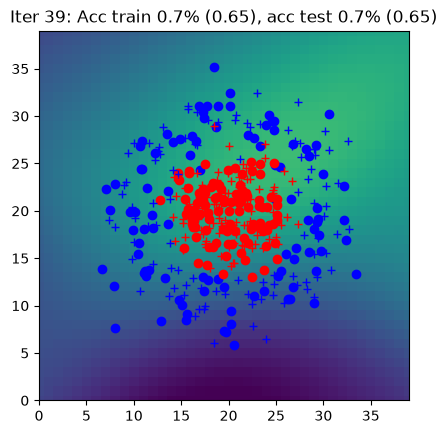

Iter 40: Acc train 0.7% (0.65), acc test 0.7% (0.65)


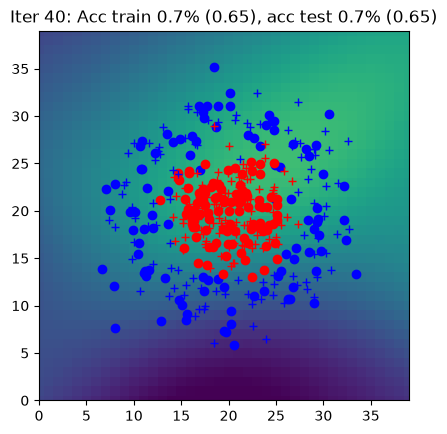

Iter 41: Acc train 0.7% (0.65), acc test 0.7% (0.65)


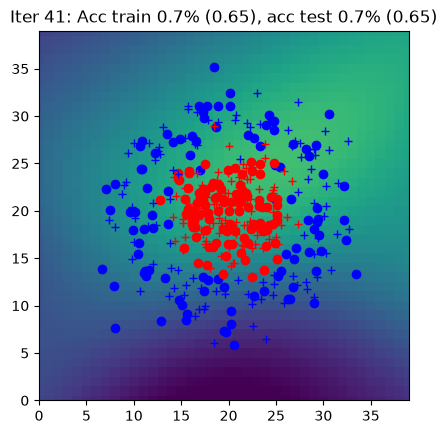

Iter 42: Acc train 0.7% (0.65), acc test 0.7% (0.65)


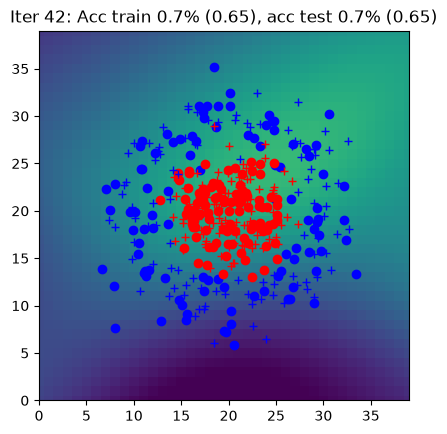

Iter 43: Acc train 0.7% (0.65), acc test 0.7% (0.65)


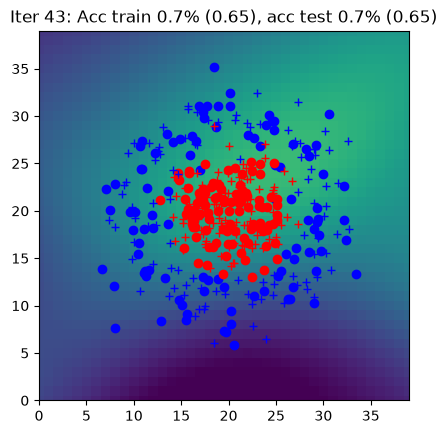

Iter 44: Acc train 0.7% (0.64), acc test 0.7% (0.64)


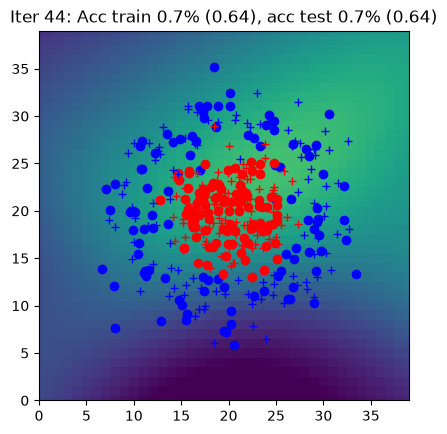

Iter 45: Acc train 0.8% (0.64), acc test 0.7% (0.64)


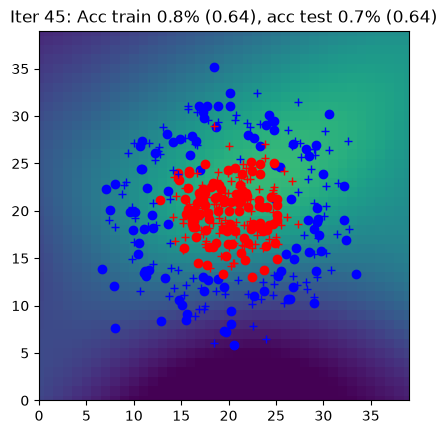

Iter 46: Acc train 0.7% (0.64), acc test 0.7% (0.64)


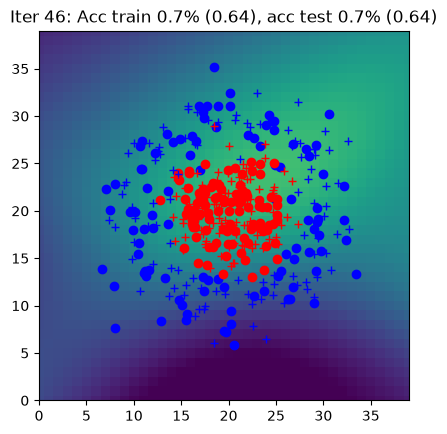

Iter 47: Acc train 0.7% (0.64), acc test 0.7% (0.64)


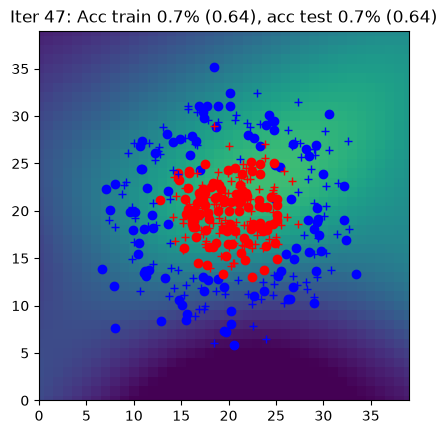

Iter 48: Acc train 0.8% (0.64), acc test 0.8% (0.63)


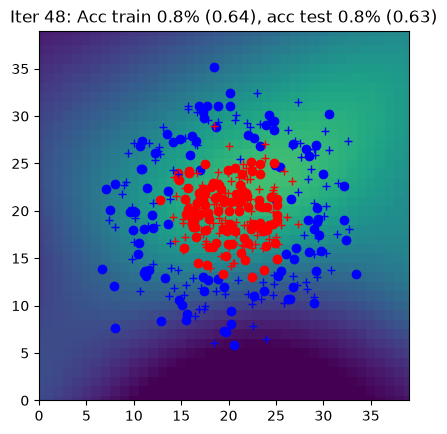

Iter 49: Acc train 0.7% (0.63), acc test 0.7% (0.63)


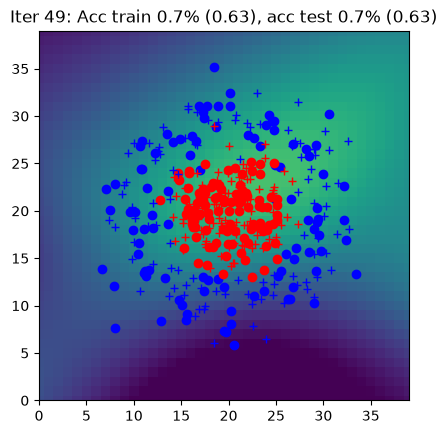

Iter 50: Acc train 0.8% (0.63), acc test 0.8% (0.63)


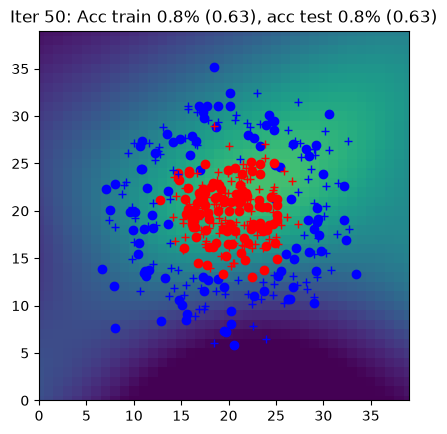

Iter 51: Acc train 0.7% (0.63), acc test 0.7% (0.63)


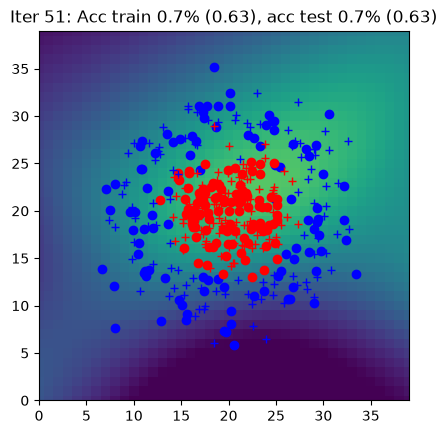

Iter 52: Acc train 0.8% (0.62), acc test 0.8% (0.62)


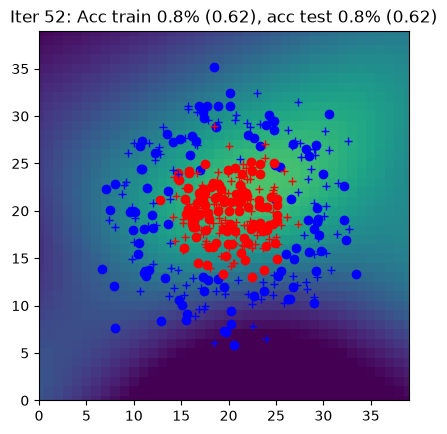

Iter 53: Acc train 0.8% (0.62), acc test 0.8% (0.62)


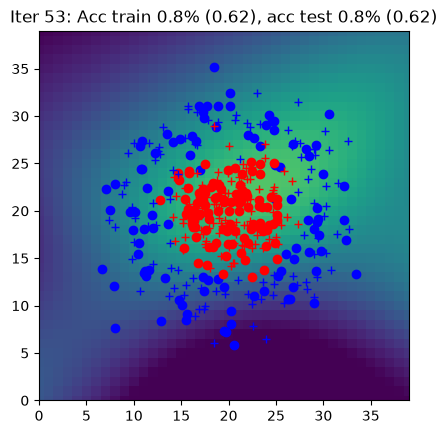

Iter 54: Acc train 0.8% (0.62), acc test 0.8% (0.62)


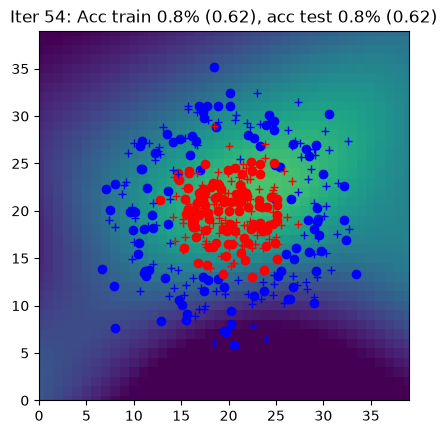

Iter 55: Acc train 0.8% (0.61), acc test 0.8% (0.61)


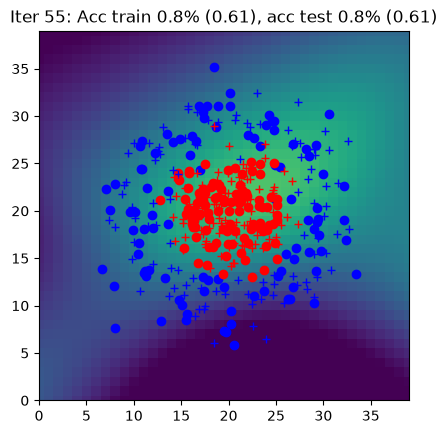

Iter 56: Acc train 0.8% (0.61), acc test 0.8% (0.61)


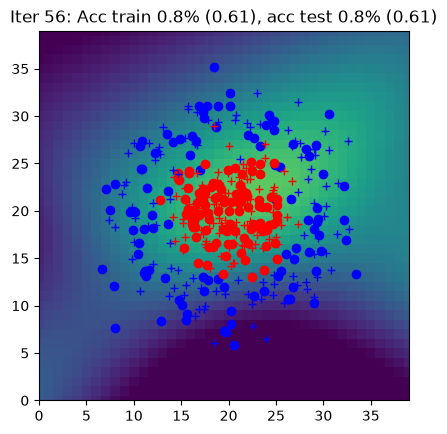

Iter 57: Acc train 0.8% (0.61), acc test 0.8% (0.61)


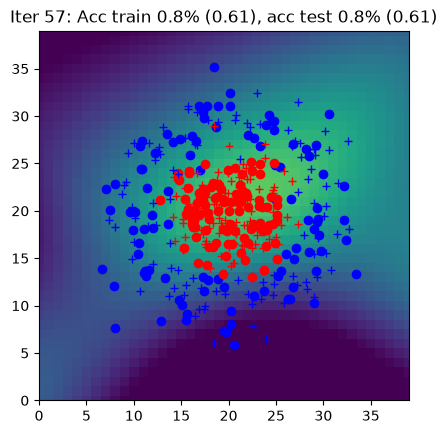

Iter 58: Acc train 0.8% (0.60), acc test 0.8% (0.60)


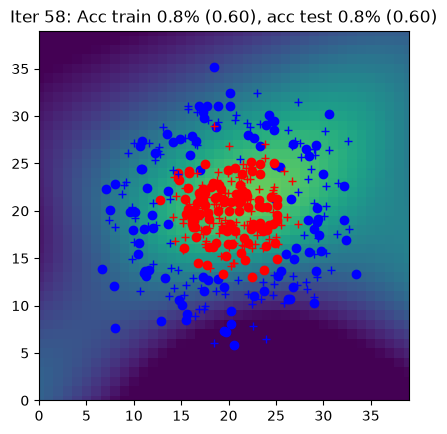

Iter 59: Acc train 0.8% (0.60), acc test 0.8% (0.60)


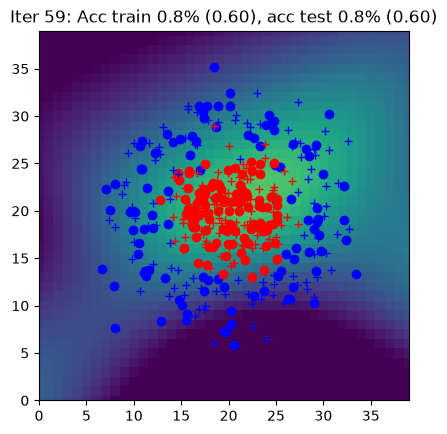

Iter 60: Acc train 0.8% (0.60), acc test 0.8% (0.59)


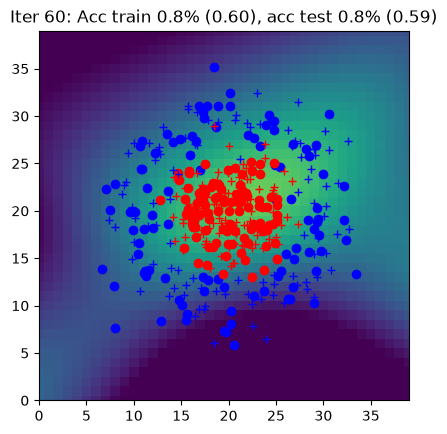

Iter 61: Acc train 0.8% (0.59), acc test 0.8% (0.59)


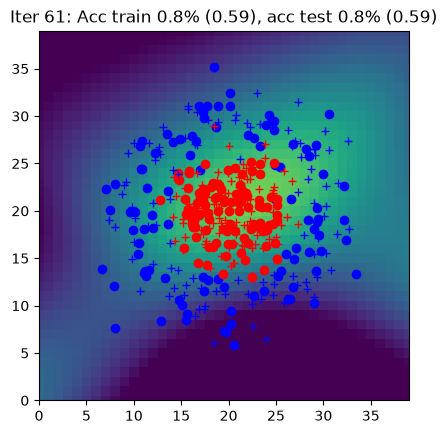

Iter 62: Acc train 0.8% (0.59), acc test 0.8% (0.59)


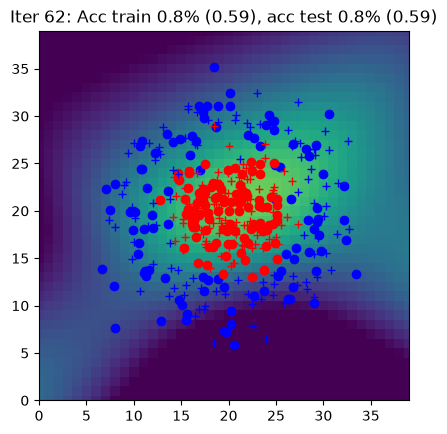

Iter 63: Acc train 0.8% (0.58), acc test 0.8% (0.58)


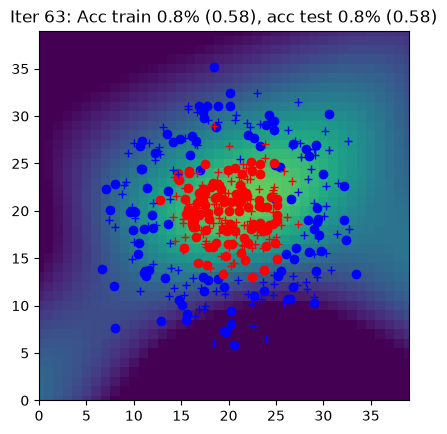

Iter 64: Acc train 0.8% (0.58), acc test 0.8% (0.58)


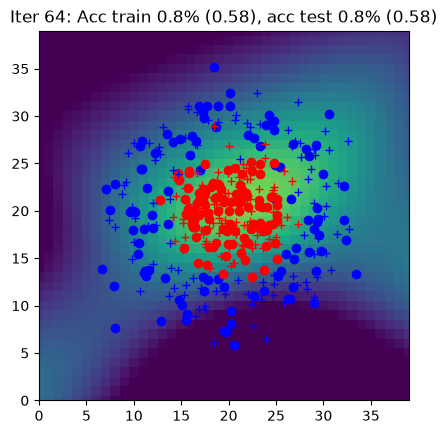

Iter 65: Acc train 0.8% (0.58), acc test 0.8% (0.57)


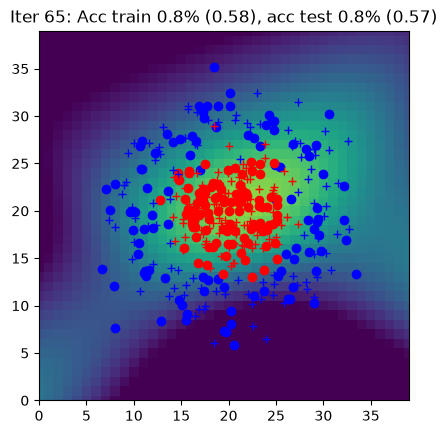

Iter 66: Acc train 0.8% (0.57), acc test 0.8% (0.57)


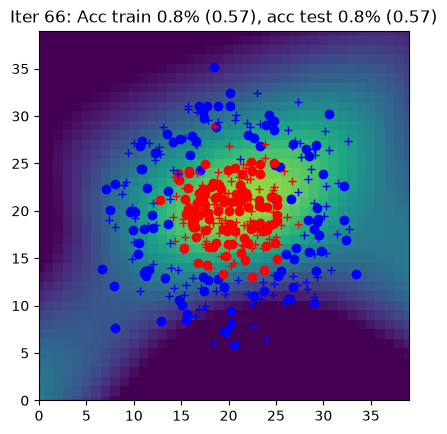

Iter 67: Acc train 0.9% (0.57), acc test 0.8% (0.56)


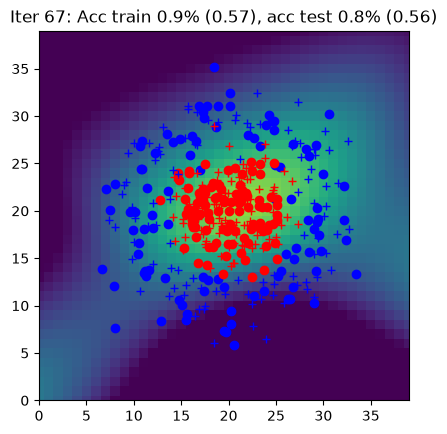

Iter 68: Acc train 0.8% (0.56), acc test 0.8% (0.56)


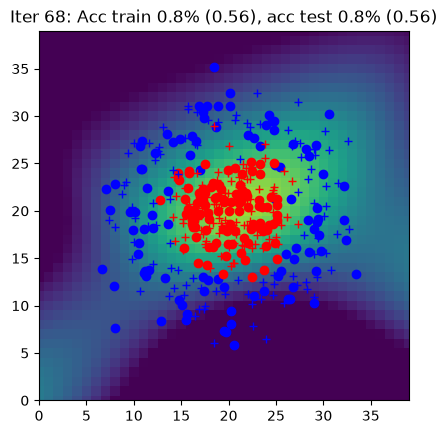

Iter 69: Acc train 0.9% (0.56), acc test 0.9% (0.55)


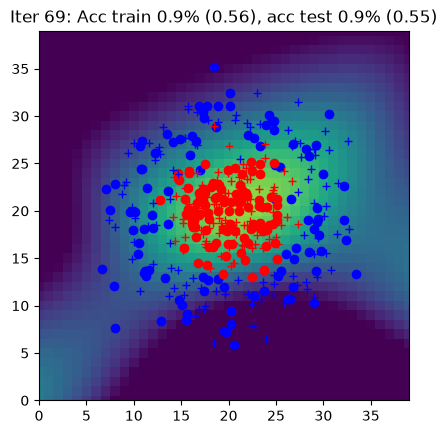

Iter 70: Acc train 0.8% (0.55), acc test 0.9% (0.55)


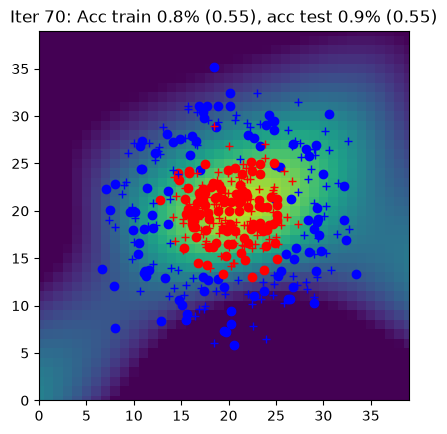

Iter 71: Acc train 0.9% (0.55), acc test 0.9% (0.54)


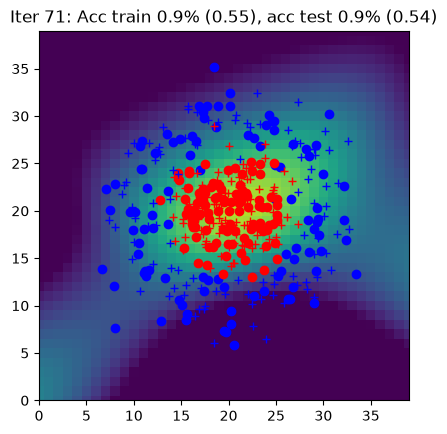

Iter 72: Acc train 0.9% (0.54), acc test 0.9% (0.54)


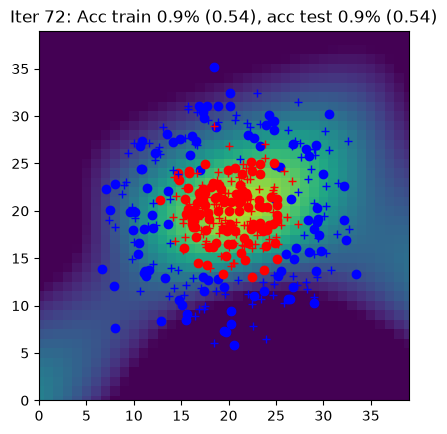

Iter 73: Acc train 0.9% (0.54), acc test 0.9% (0.53)


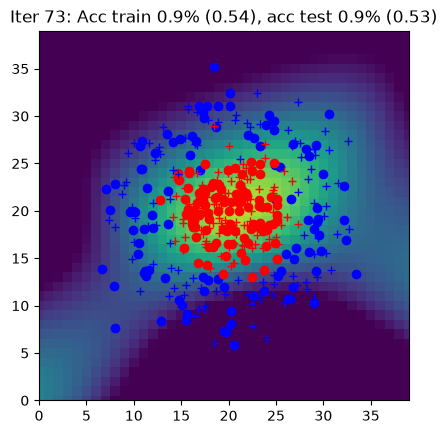

Iter 74: Acc train 0.9% (0.53), acc test 0.9% (0.53)


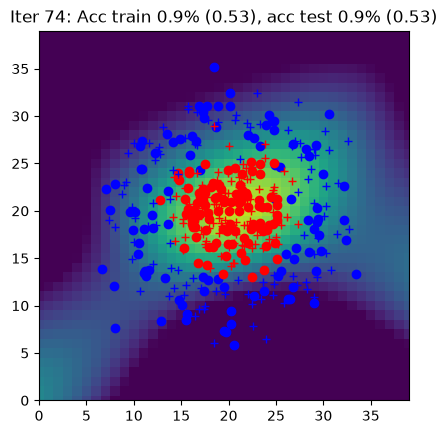

Iter 75: Acc train 0.9% (0.53), acc test 0.9% (0.52)


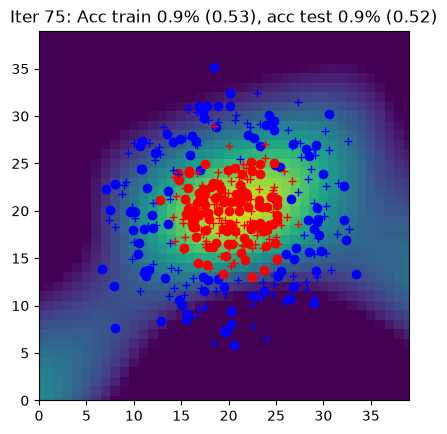

Iter 76: Acc train 0.9% (0.52), acc test 0.9% (0.52)


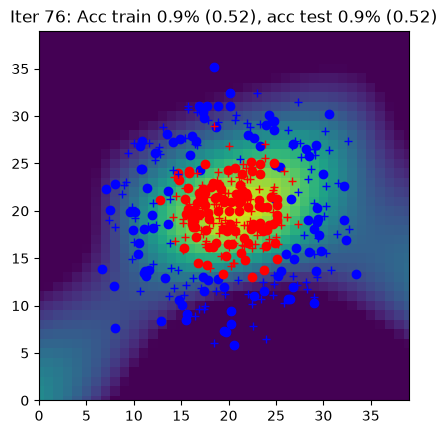

Iter 77: Acc train 0.9% (0.52), acc test 0.9% (0.51)


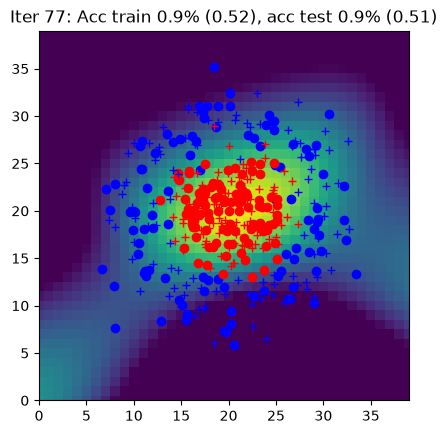

Iter 78: Acc train 0.9% (0.51), acc test 0.9% (0.51)


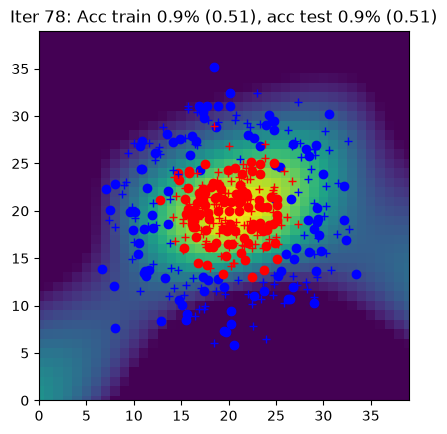

Iter 79: Acc train 0.9% (0.51), acc test 0.9% (0.50)


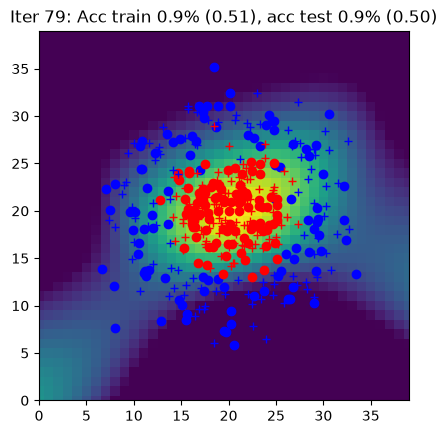

Iter 80: Acc train 0.9% (0.50), acc test 0.9% (0.49)


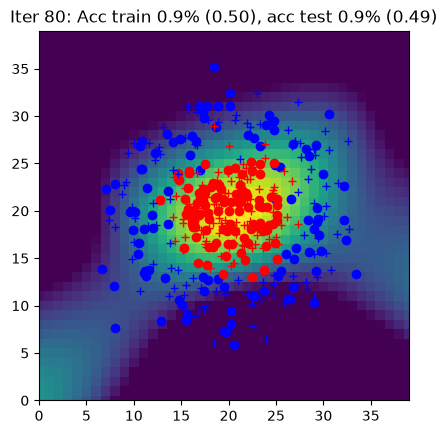

Iter 81: Acc train 0.9% (0.49), acc test 0.9% (0.49)


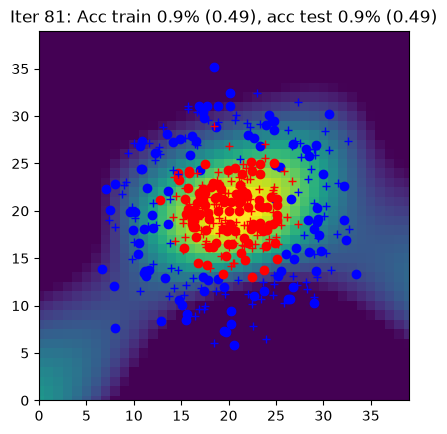

Iter 82: Acc train 0.9% (0.49), acc test 0.9% (0.48)


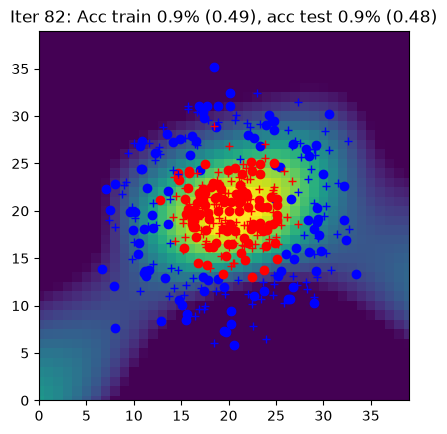

Iter 83: Acc train 0.9% (0.48), acc test 0.9% (0.48)


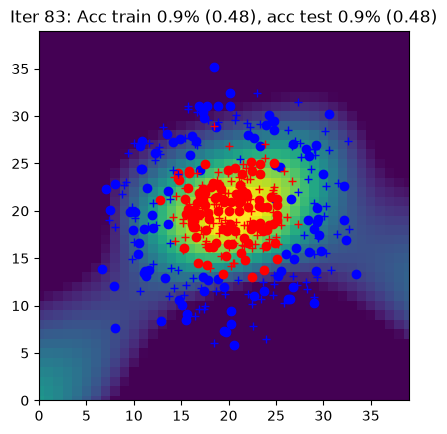

Iter 84: Acc train 0.9% (0.48), acc test 0.9% (0.47)


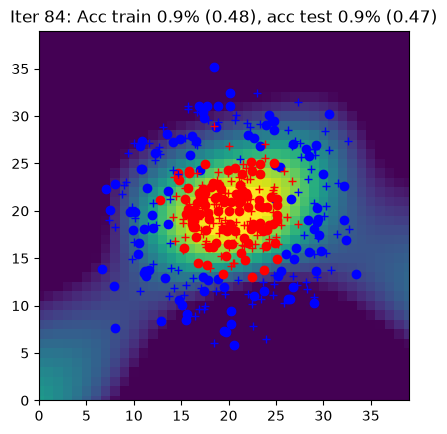

Iter 85: Acc train 0.9% (0.47), acc test 0.9% (0.47)


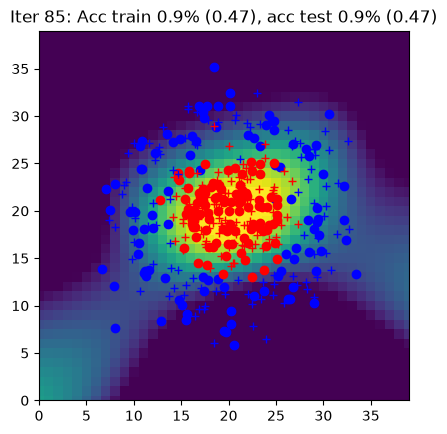

Iter 86: Acc train 0.9% (0.47), acc test 0.9% (0.46)


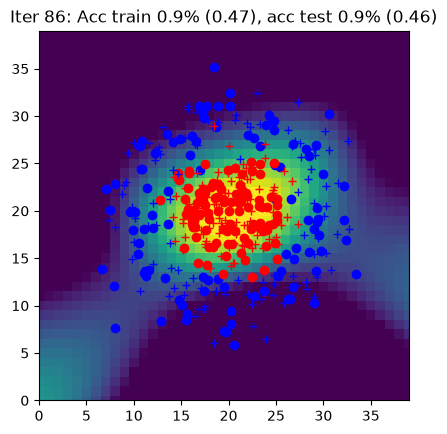

Iter 87: Acc train 0.9% (0.46), acc test 0.9% (0.45)


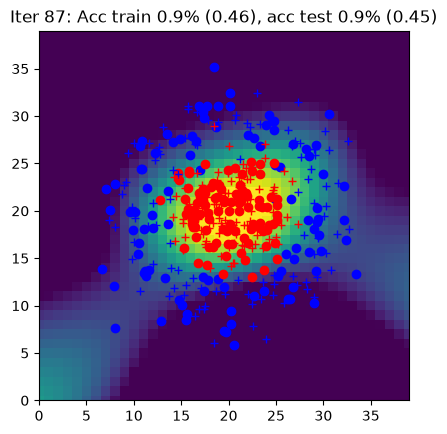

Iter 88: Acc train 0.9% (0.46), acc test 0.9% (0.45)


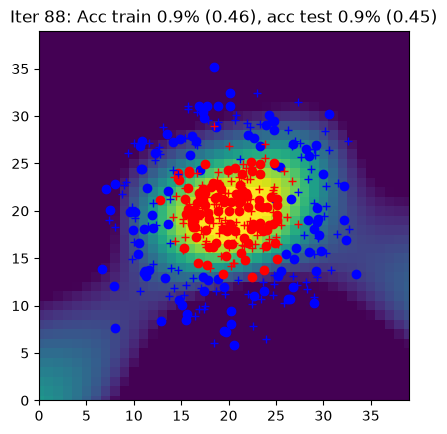

Iter 89: Acc train 0.9% (0.45), acc test 0.9% (0.44)


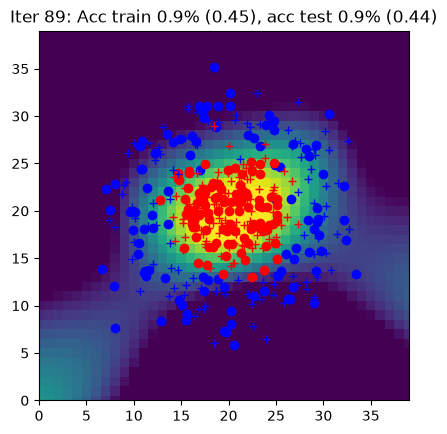

Iter 90: Acc train 0.9% (0.45), acc test 0.9% (0.44)


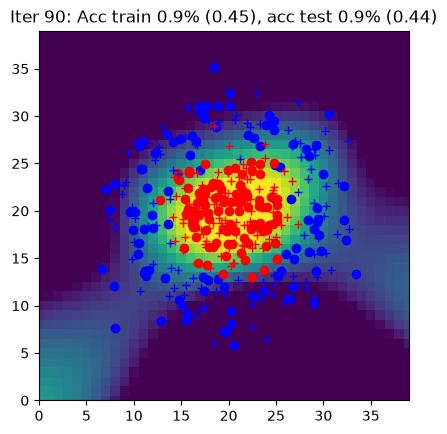

Iter 91: Acc train 0.9% (0.44), acc test 0.9% (0.43)


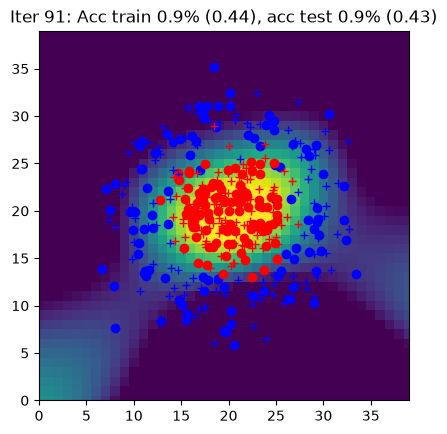

Iter 92: Acc train 0.9% (0.43), acc test 0.9% (0.43)


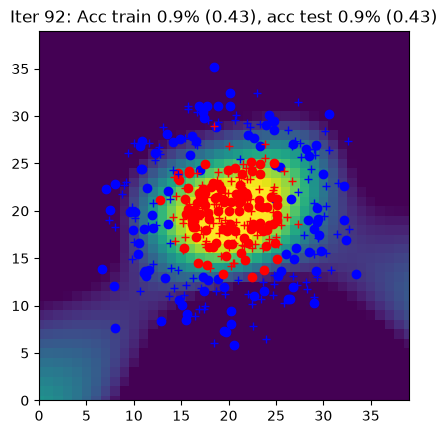

Iter 93: Acc train 0.9% (0.43), acc test 0.9% (0.42)


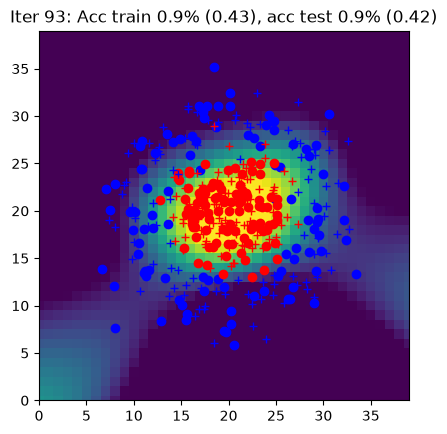

Iter 94: Acc train 0.9% (0.42), acc test 0.9% (0.42)


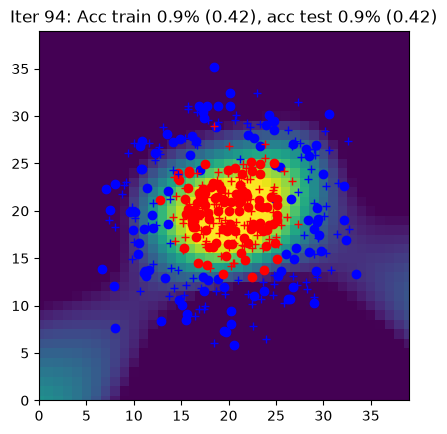

Iter 95: Acc train 0.9% (0.42), acc test 0.9% (0.41)


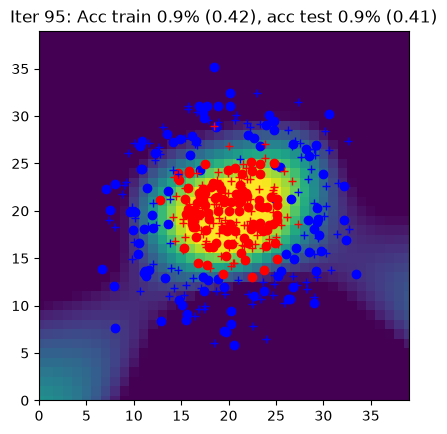

Iter 96: Acc train 0.9% (0.41), acc test 1.0% (0.40)


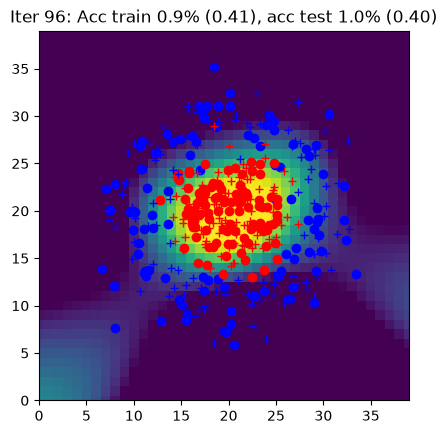

Iter 97: Acc train 0.9% (0.41), acc test 0.9% (0.40)


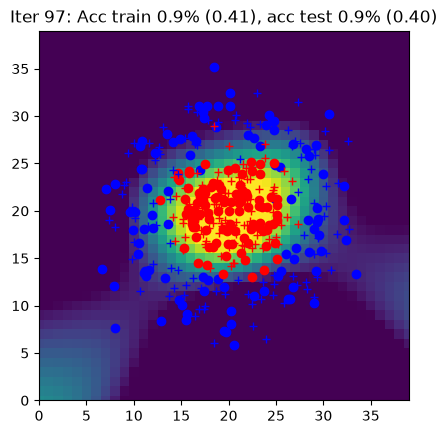

Iter 98: Acc train 0.9% (0.40), acc test 1.0% (0.39)


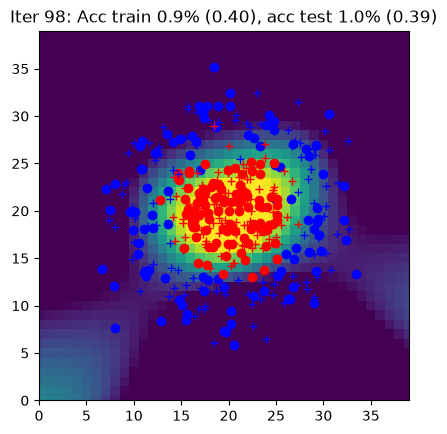

Iter 99: Acc train 0.9% (0.40), acc test 0.9% (0.39)


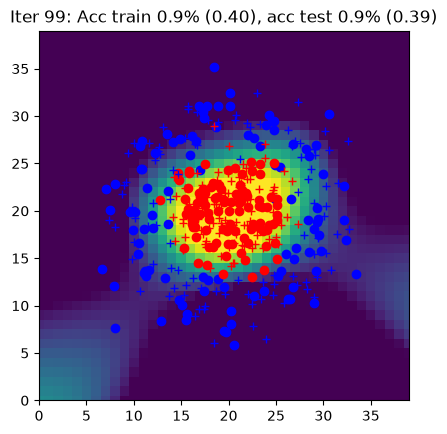

Iter 100: Acc train 0.9% (0.39), acc test 0.9% (0.38)


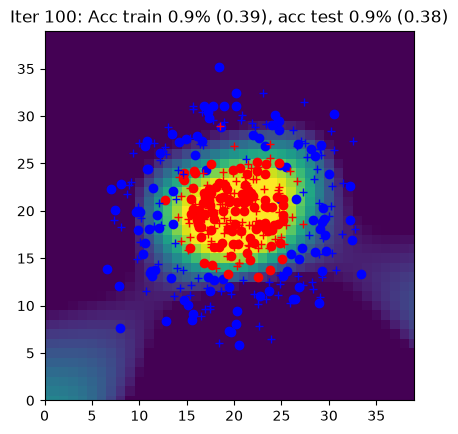

Iter 101: Acc train 0.9% (0.39), acc test 0.9% (0.38)


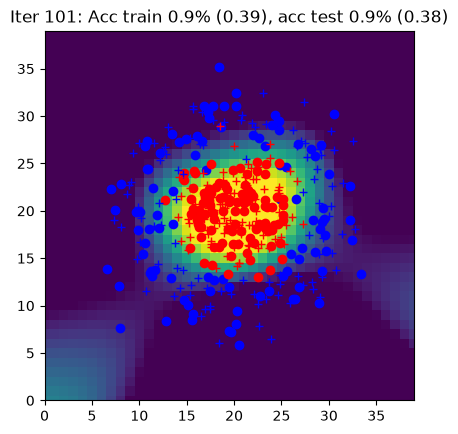

Iter 102: Acc train 0.9% (0.38), acc test 0.9% (0.37)


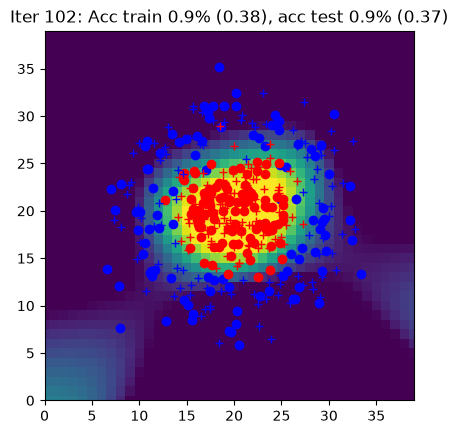

Iter 103: Acc train 0.9% (0.38), acc test 0.9% (0.37)


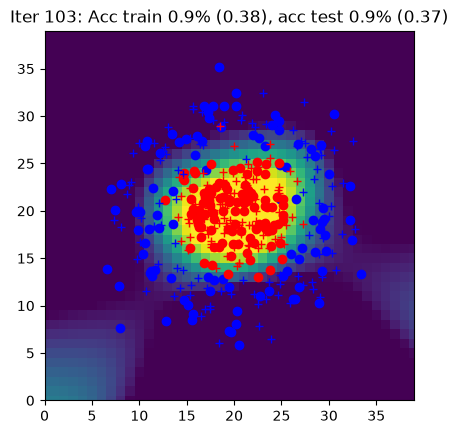

Iter 104: Acc train 0.9% (0.37), acc test 0.9% (0.36)


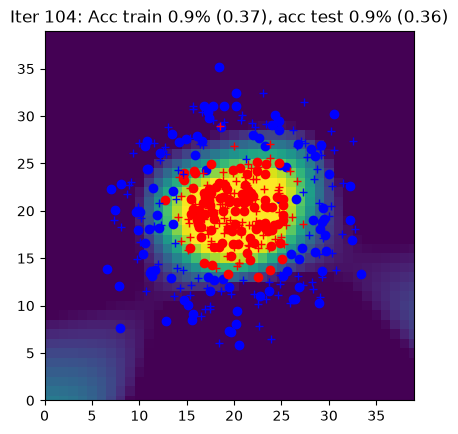

Iter 105: Acc train 0.9% (0.37), acc test 0.9% (0.36)


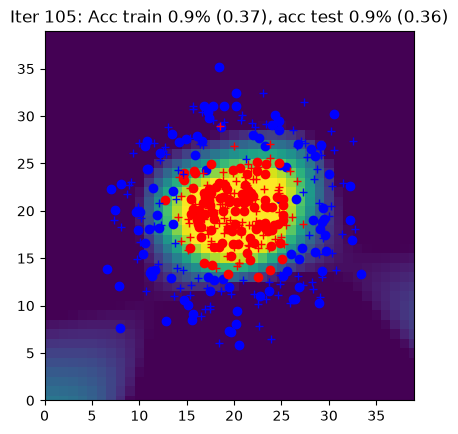

Iter 106: Acc train 0.9% (0.36), acc test 1.0% (0.35)


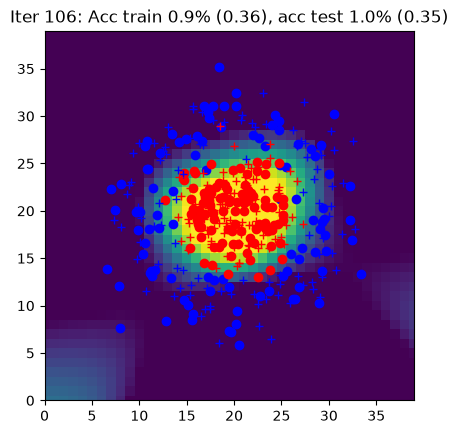

Iter 107: Acc train 0.9% (0.36), acc test 0.9% (0.35)


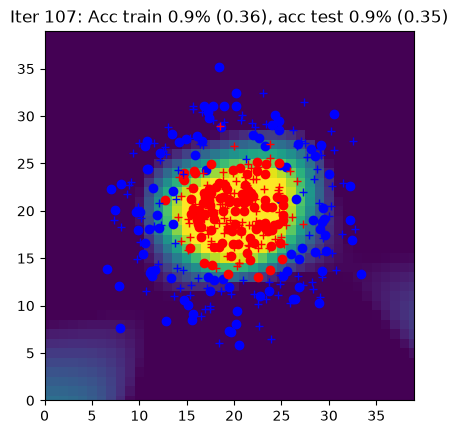

Iter 108: Acc train 0.9% (0.35), acc test 1.0% (0.34)


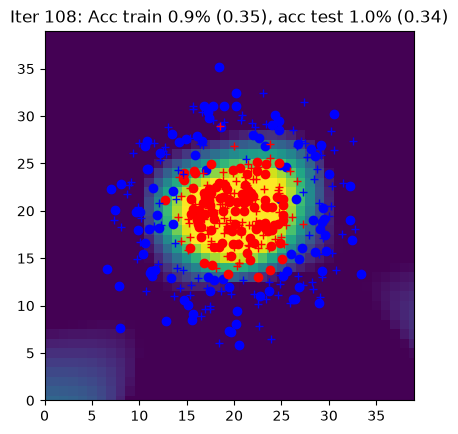

Iter 109: Acc train 0.9% (0.35), acc test 0.9% (0.34)


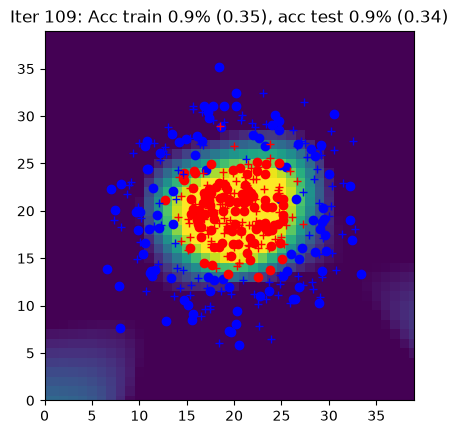

Iter 110: Acc train 0.9% (0.34), acc test 1.0% (0.33)


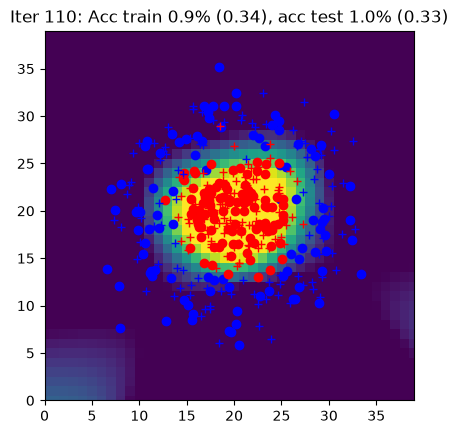

Iter 111: Acc train 0.9% (0.34), acc test 1.0% (0.33)


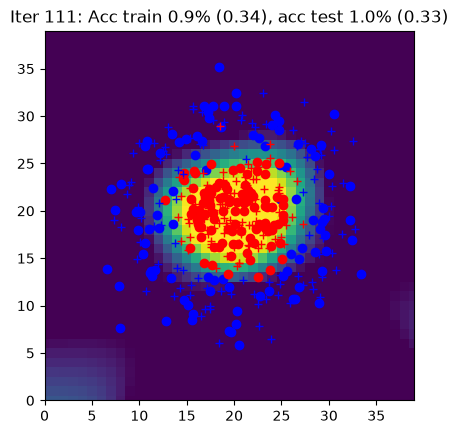

Iter 112: Acc train 0.9% (0.33), acc test 1.0% (0.33)


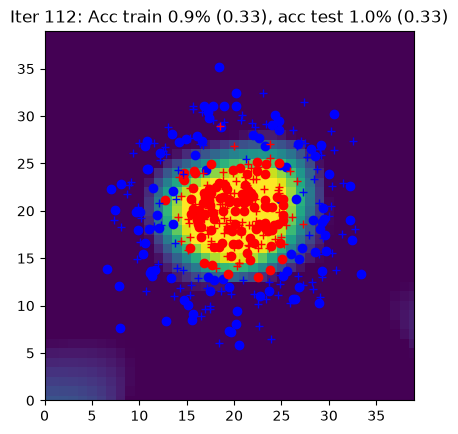

Iter 113: Acc train 0.9% (0.33), acc test 1.0% (0.32)


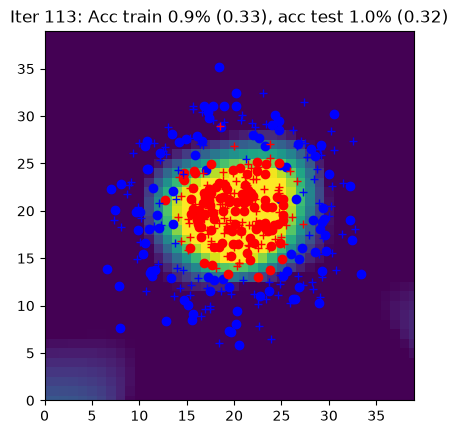

Iter 114: Acc train 0.9% (0.32), acc test 1.0% (0.32)


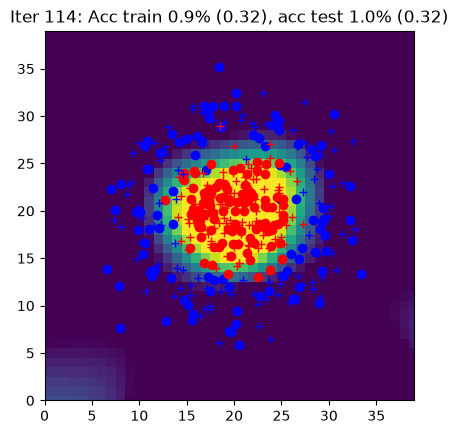

Iter 115: Acc train 0.9% (0.32), acc test 1.0% (0.31)


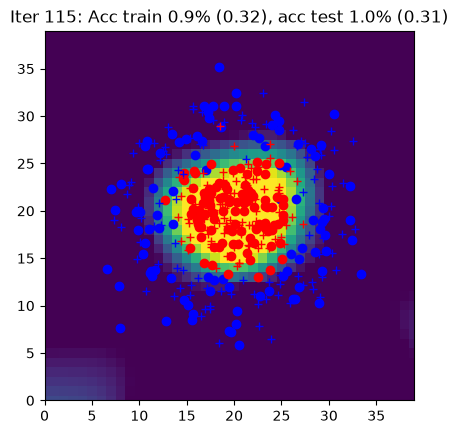

Iter 116: Acc train 0.9% (0.32), acc test 1.0% (0.31)


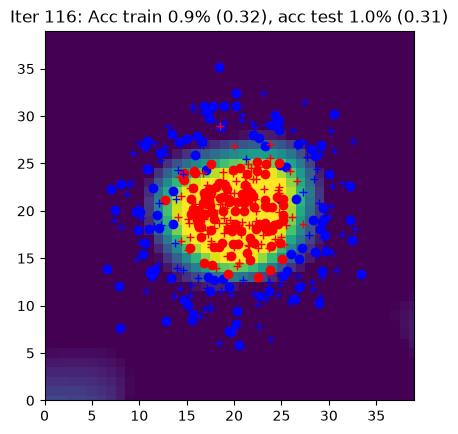

Iter 117: Acc train 0.9% (0.31), acc test 1.0% (0.31)


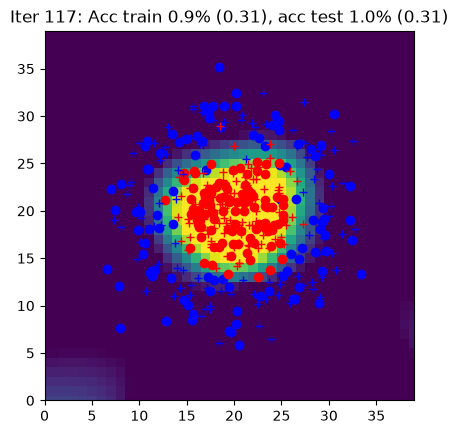

Iter 118: Acc train 0.9% (0.31), acc test 1.0% (0.30)


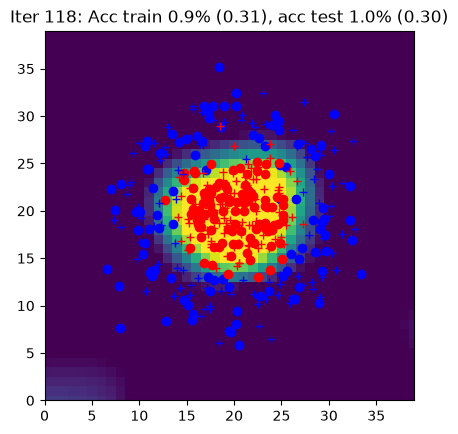

Iter 119: Acc train 0.9% (0.31), acc test 1.0% (0.30)


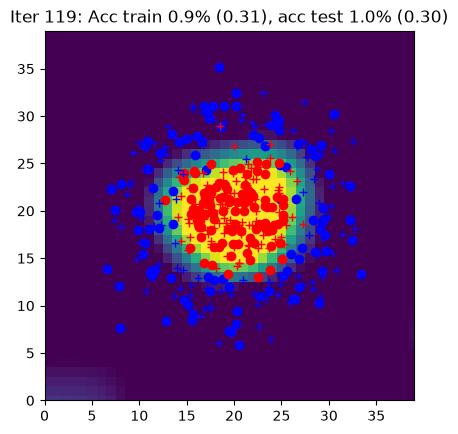

Iter 120: Acc train 0.9% (0.30), acc test 1.0% (0.30)


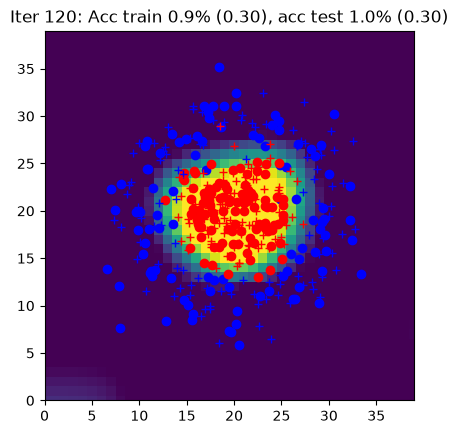

Iter 121: Acc train 0.9% (0.30), acc test 1.0% (0.29)


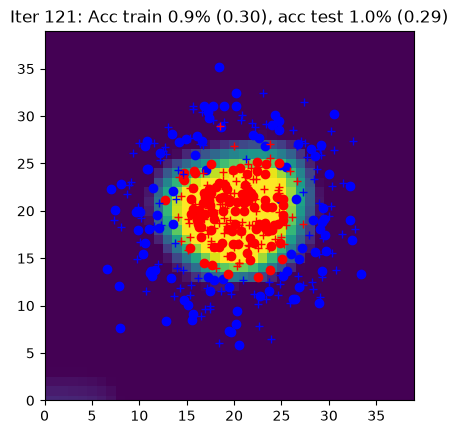

Iter 122: Acc train 0.9% (0.29), acc test 1.0% (0.29)


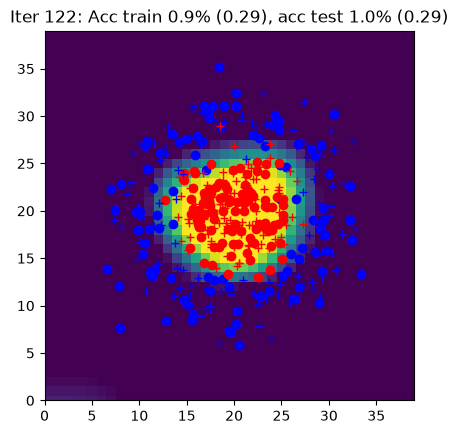

Iter 123: Acc train 0.9% (0.29), acc test 1.0% (0.28)


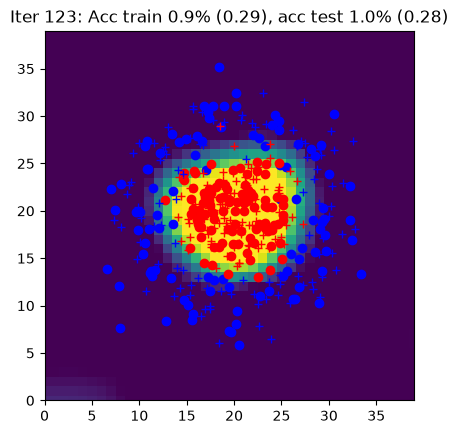

Iter 124: Acc train 0.9% (0.29), acc test 1.0% (0.28)


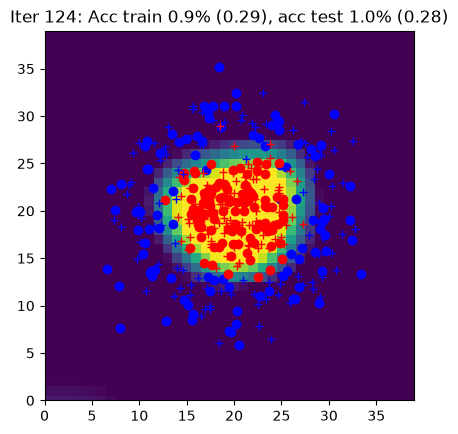

Iter 125: Acc train 0.9% (0.28), acc test 1.0% (0.28)


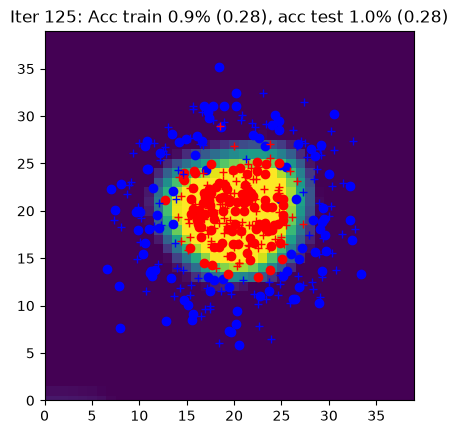

Iter 126: Acc train 0.9% (0.28), acc test 1.0% (0.28)


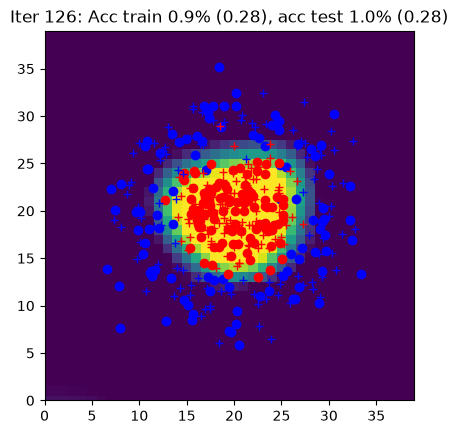

Iter 127: Acc train 0.9% (0.28), acc test 1.0% (0.27)


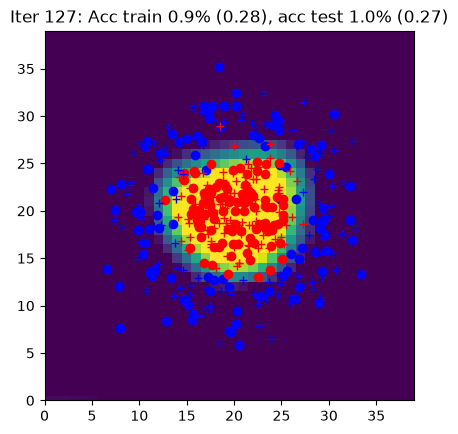

Iter 128: Acc train 0.9% (0.27), acc test 1.0% (0.27)


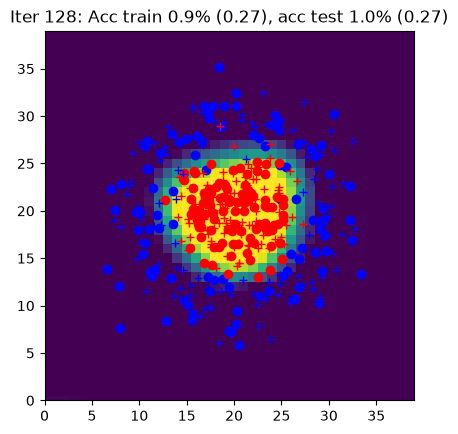

Iter 129: Acc train 0.9% (0.27), acc test 1.0% (0.27)


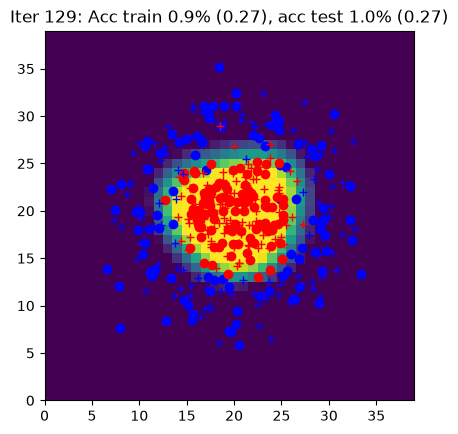

Iter 130: Acc train 0.9% (0.27), acc test 1.0% (0.26)


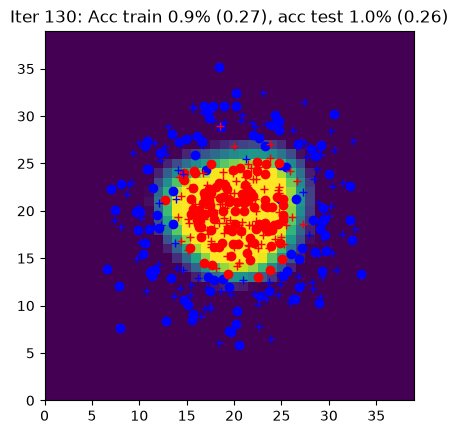

Iter 131: Acc train 0.9% (0.27), acc test 1.0% (0.26)


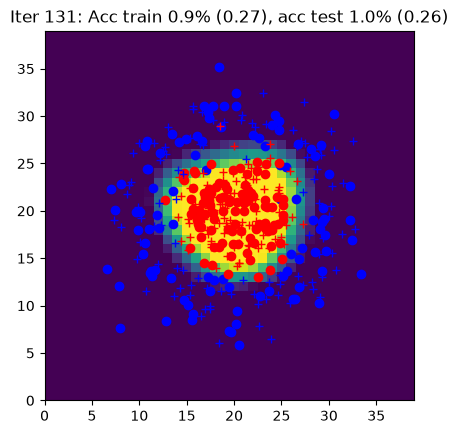

Iter 132: Acc train 0.9% (0.26), acc test 1.0% (0.26)


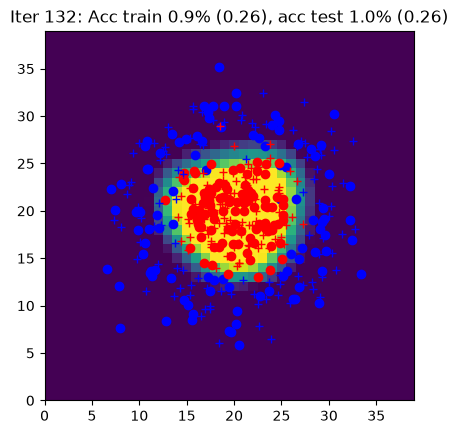

Iter 133: Acc train 0.9% (0.26), acc test 1.0% (0.26)


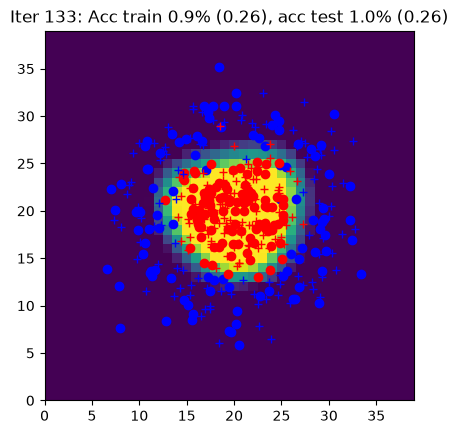

Iter 134: Acc train 0.9% (0.26), acc test 1.0% (0.25)


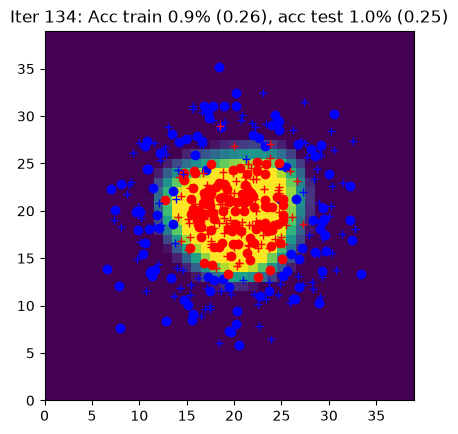

Iter 135: Acc train 1.0% (0.25), acc test 1.0% (0.25)


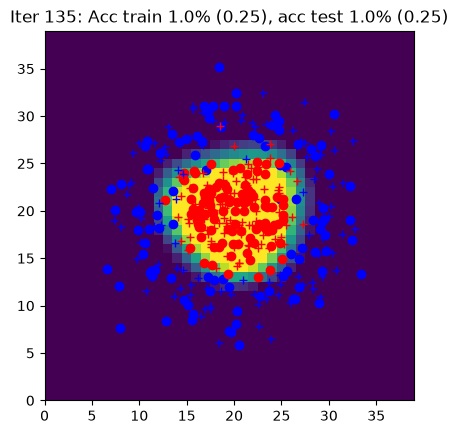

Iter 136: Acc train 0.9% (0.25), acc test 1.0% (0.25)


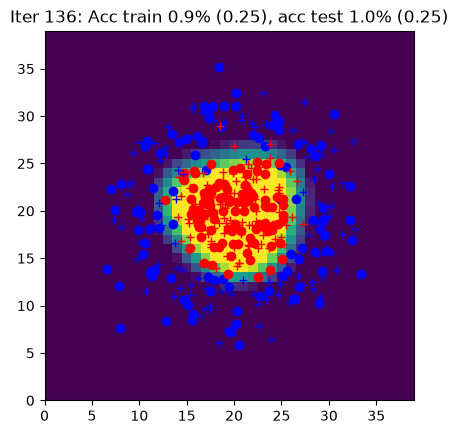

Iter 137: Acc train 1.0% (0.25), acc test 1.0% (0.25)


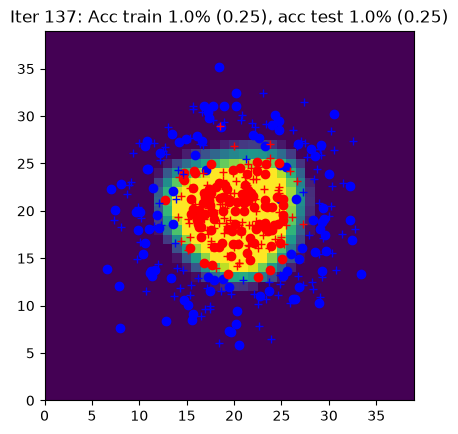

Iter 138: Acc train 0.9% (0.25), acc test 1.0% (0.25)


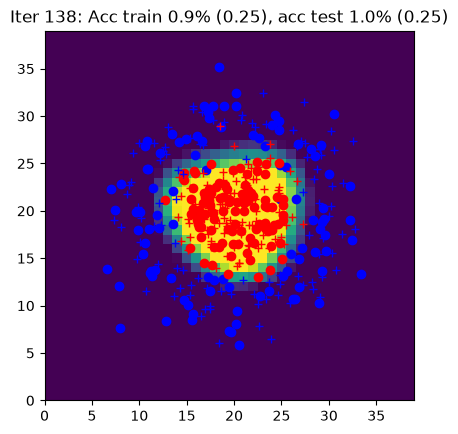

Iter 139: Acc train 0.9% (0.24), acc test 1.0% (0.24)


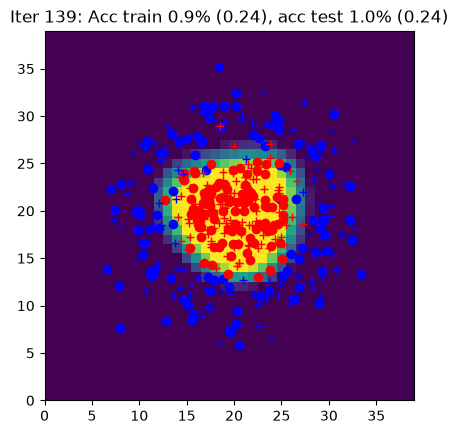

Iter 140: Acc train 1.0% (0.24), acc test 1.0% (0.24)


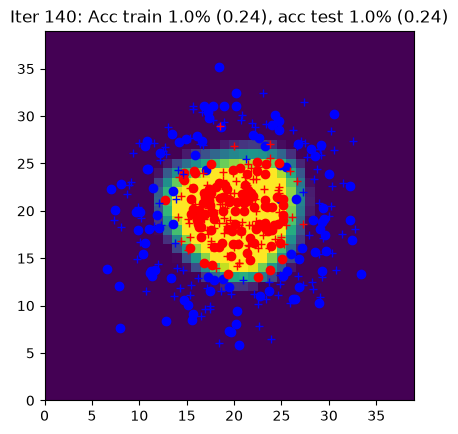

Iter 141: Acc train 1.0% (0.24), acc test 1.0% (0.24)


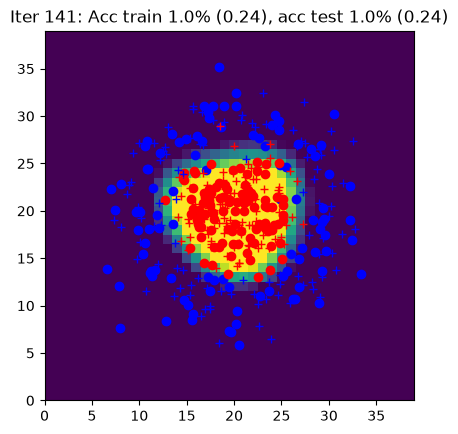

Iter 142: Acc train 1.0% (0.24), acc test 1.0% (0.24)


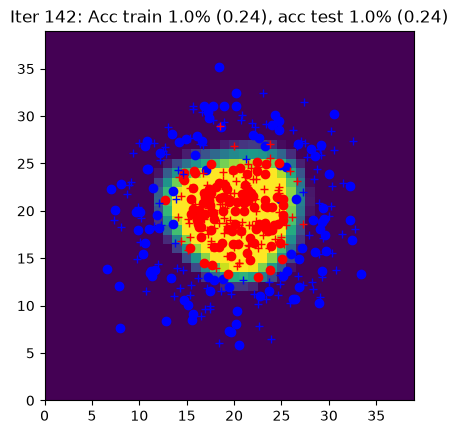

Iter 143: Acc train 1.0% (0.24), acc test 1.0% (0.24)


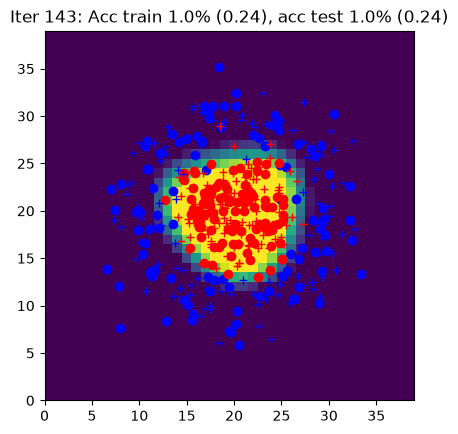

Iter 144: Acc train 1.0% (0.23), acc test 1.0% (0.23)


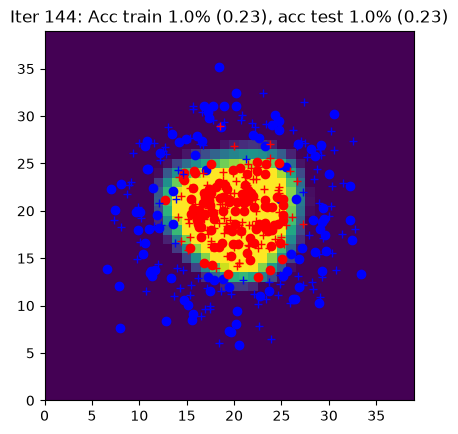

Iter 145: Acc train 1.0% (0.23), acc test 1.0% (0.23)


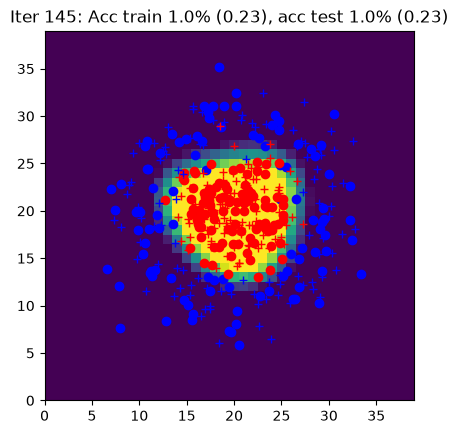

Iter 146: Acc train 1.0% (0.23), acc test 1.0% (0.23)


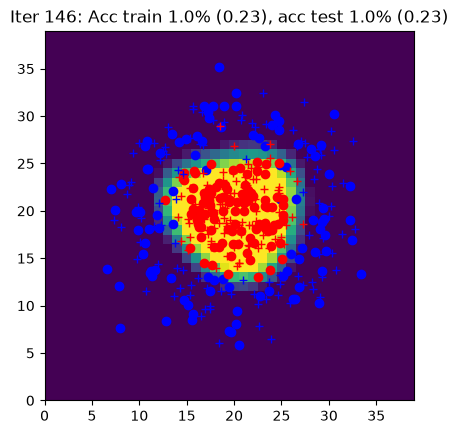

Iter 147: Acc train 1.0% (0.23), acc test 0.9% (0.23)


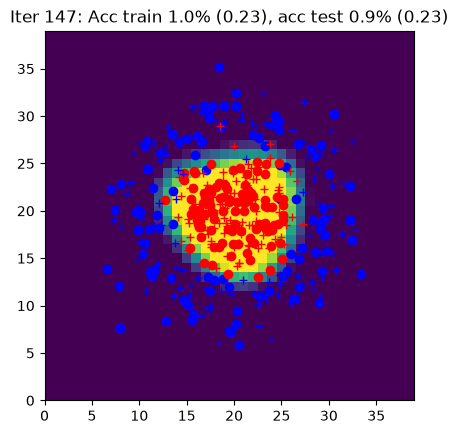

Iter 148: Acc train 1.0% (0.23), acc test 0.9% (0.23)


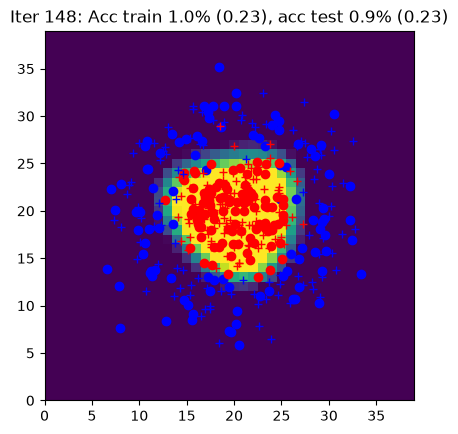

Iter 149: Acc train 1.0% (0.22), acc test 0.9% (0.23)


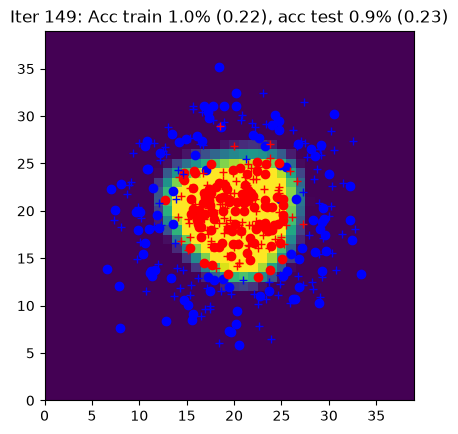

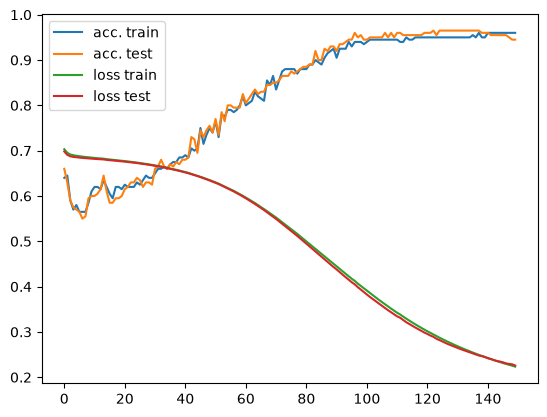

In [100]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

model, loss = init_model(nx, nh, ny)

curves = [[], [], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code here  ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j + 1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: loss_accuracy, sgd
        # the forward with the predict method from the model
        # and the backward function with autograd
        Yhat = model(X)
        L, acc = loss_accuracy(loss, Yhat, Y)
        L.backward()
        model = sgd(model, eta)

    ####################
    ##      END        #
    ####################

    Yhat_train = model(data.Xtrain)
    Yhat_test = model(data.Xtest)
    Ltrain, acctrain = loss_accuracy(loss, Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(loss, Yhat_test, data.Ytest)
    Ygrid = model(data.Xgrid)

    title = "Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})".format(
        iteration, acctrain, Ltrain, acctest, Ltest
    )
    print(title)
    data.plot_data_with_grid(torch.nn.Softmax(dim=1)(Ygrid.detach()), title)

    curves[0].append(acctrain.item())
    curves[1].append(acctest.item())
    curves[2].append(Ltrain.item())
    curves[3].append(Ltest.item())

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 4 : Simplification of the SGD with `torch.optim`

In [101]:
def init_model(nx, nh, ny, eta):

    #####################
    ## Your code here  ##
    #####################
    model = torch.nn.Sequential(
        torch.nn.Linear(nx, nh), torch.nn.Tanh(), torch.nn.Linear(nh, ny)
    )

    loss = torch.nn.CrossEntropyLoss()

    optim = torch.optim.SGD(model.parameters(), lr=eta)

    ####################
    ##      END        #
    ####################

    return model, loss, optim

The `sgd` function is replaced by calling the `optim.zero_grad()` before the backward and `optim.step()` after.

## Algorithme global d'apprentissage (avec autograd, les couches `torch.nn` et `torch.optim`)

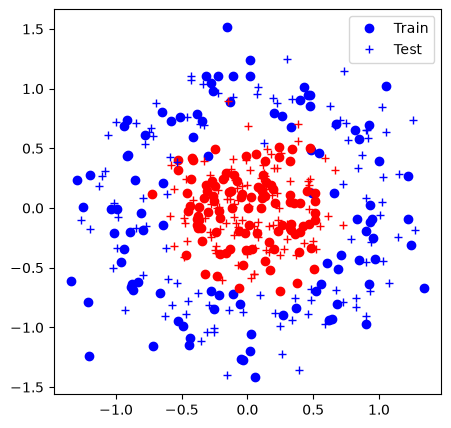

Iter 0: Acc train 0.6% (0.70), acc test 0.6% (0.70)


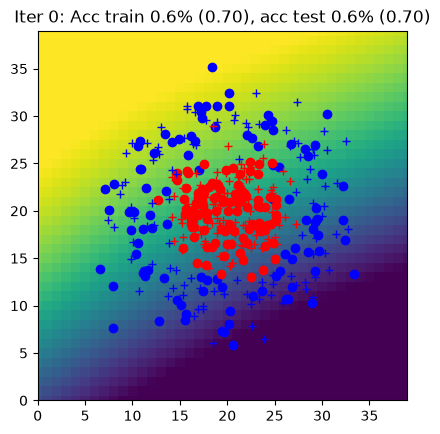

Iter 1: Acc train 0.6% (0.70), acc test 0.6% (0.69)


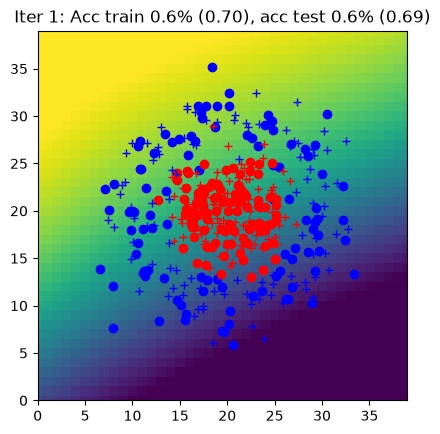

Iter 2: Acc train 0.6% (0.70), acc test 0.6% (0.69)


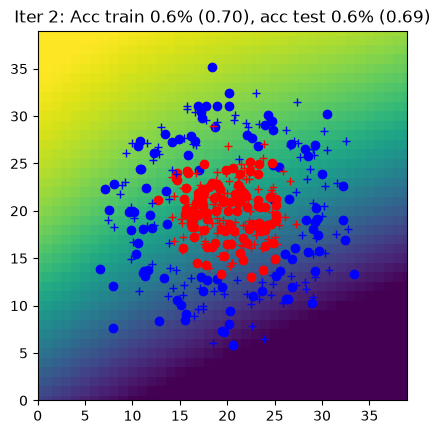

Iter 3: Acc train 0.5% (0.70), acc test 0.5% (0.69)


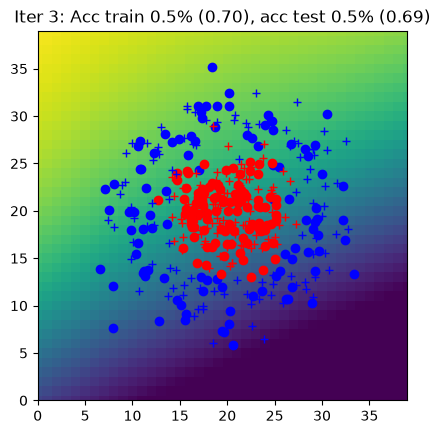

Iter 4: Acc train 0.5% (0.69), acc test 0.5% (0.69)


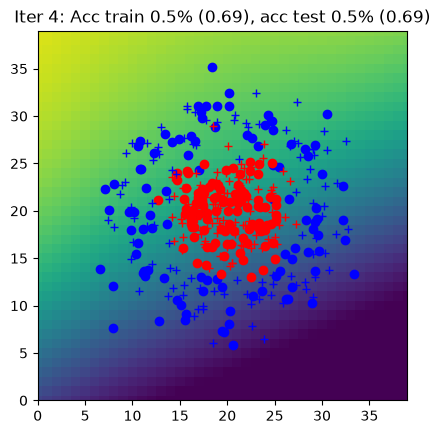

Iter 5: Acc train 0.6% (0.69), acc test 0.6% (0.69)


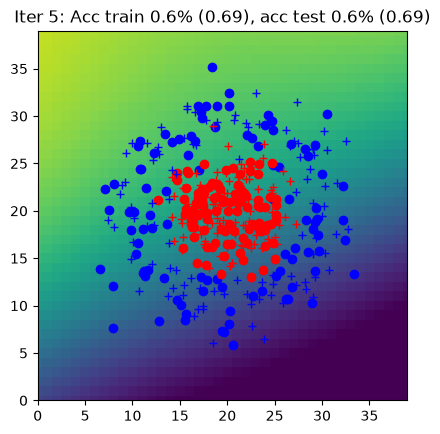

Iter 6: Acc train 0.6% (0.69), acc test 0.6% (0.69)


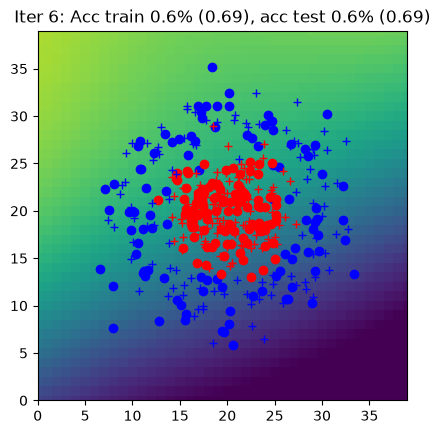

Iter 7: Acc train 0.6% (0.69), acc test 0.6% (0.68)


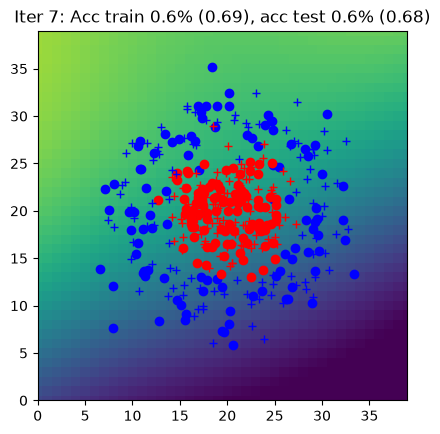

Iter 8: Acc train 0.6% (0.69), acc test 0.6% (0.68)


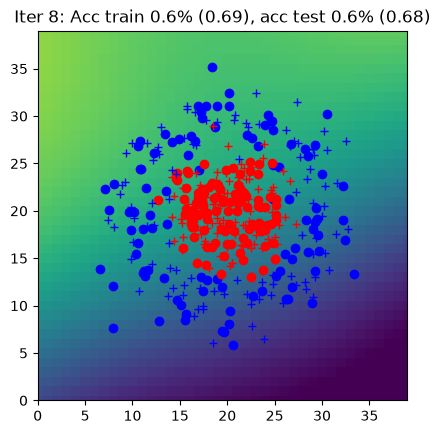

Iter 9: Acc train 0.6% (0.69), acc test 0.6% (0.68)


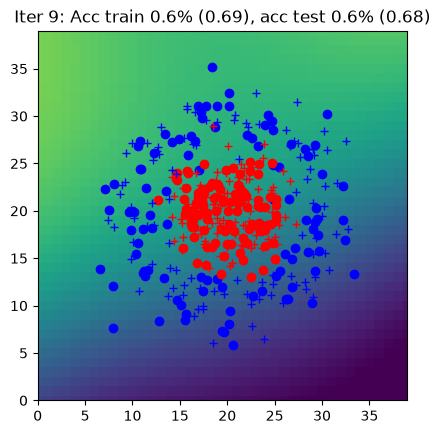

Iter 10: Acc train 0.6% (0.68), acc test 0.6% (0.68)


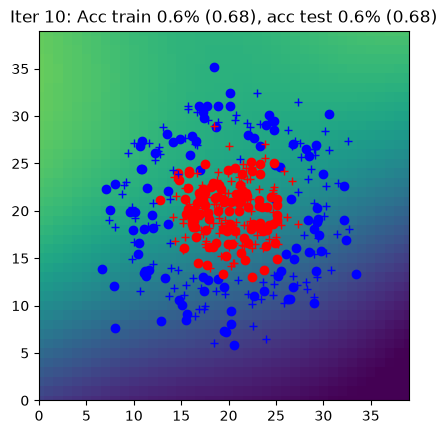

Iter 11: Acc train 0.6% (0.68), acc test 0.6% (0.68)


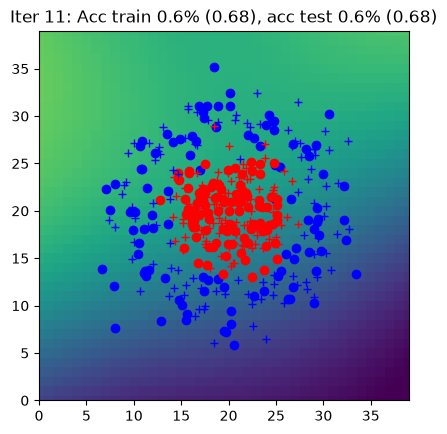

Iter 12: Acc train 0.6% (0.68), acc test 0.6% (0.68)


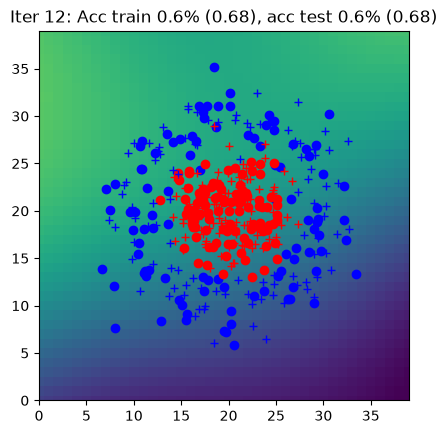

Iter 13: Acc train 0.6% (0.68), acc test 0.6% (0.68)


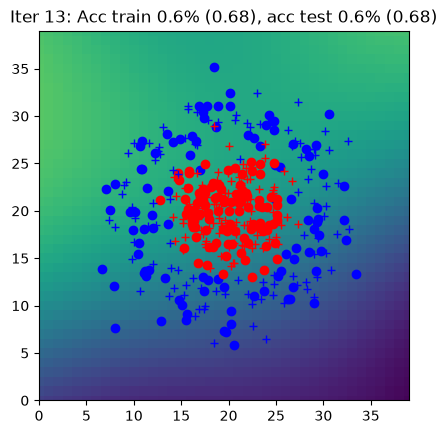

Iter 14: Acc train 0.7% (0.68), acc test 0.6% (0.68)


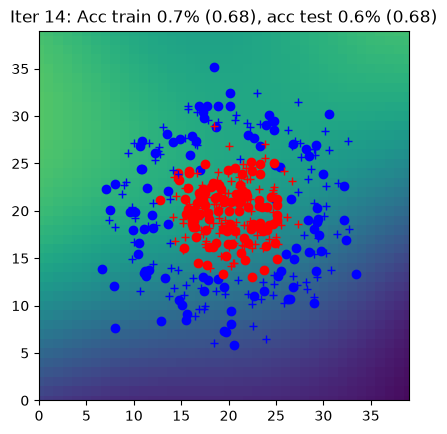

Iter 15: Acc train 0.6% (0.68), acc test 0.6% (0.68)


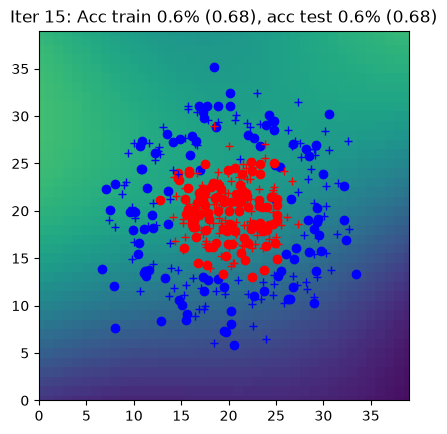

Iter 16: Acc train 0.7% (0.68), acc test 0.6% (0.68)


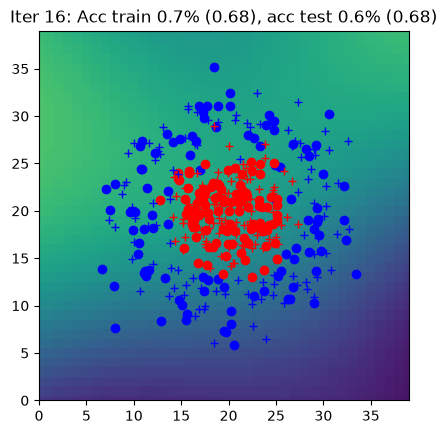

Iter 17: Acc train 0.6% (0.67), acc test 0.6% (0.67)


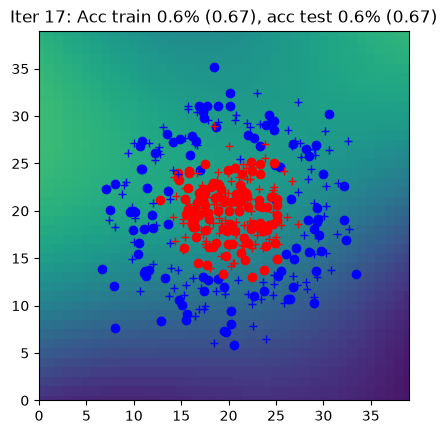

Iter 18: Acc train 0.6% (0.67), acc test 0.6% (0.67)


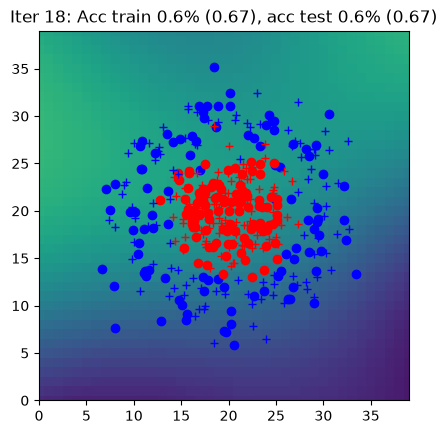

Iter 19: Acc train 0.6% (0.67), acc test 0.6% (0.67)


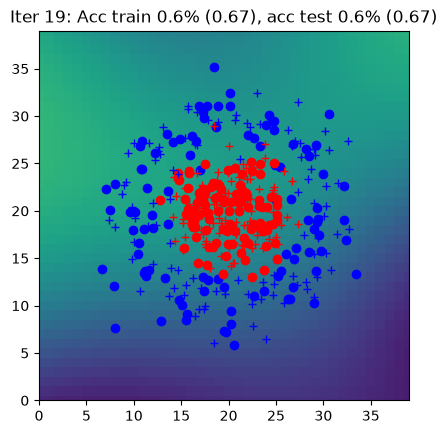

Iter 20: Acc train 0.7% (0.67), acc test 0.7% (0.67)


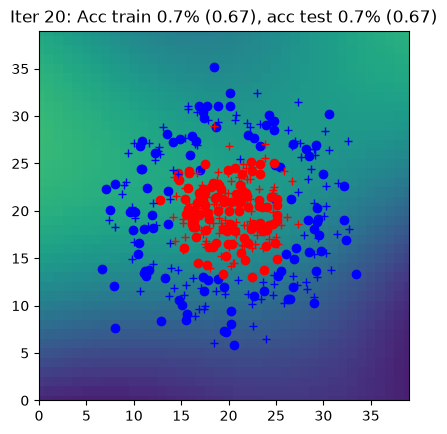

Iter 21: Acc train 0.7% (0.67), acc test 0.7% (0.67)


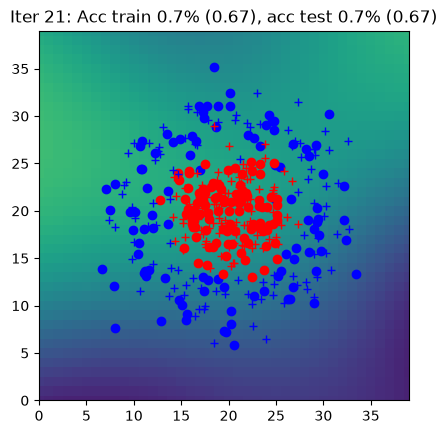

Iter 22: Acc train 0.7% (0.67), acc test 0.7% (0.67)


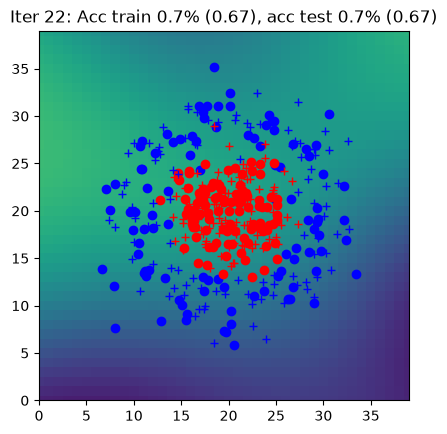

Iter 23: Acc train 0.7% (0.67), acc test 0.7% (0.67)


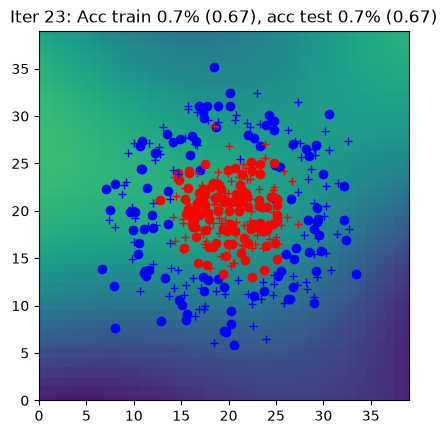

Iter 24: Acc train 0.8% (0.66), acc test 0.8% (0.67)


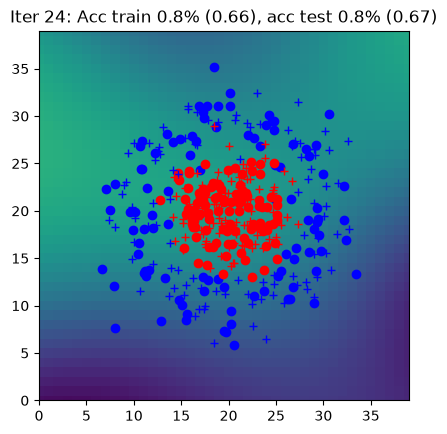

Iter 25: Acc train 0.7% (0.66), acc test 0.7% (0.66)


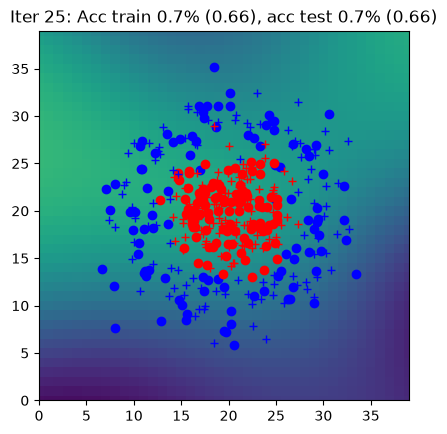

Iter 26: Acc train 0.7% (0.66), acc test 0.7% (0.66)


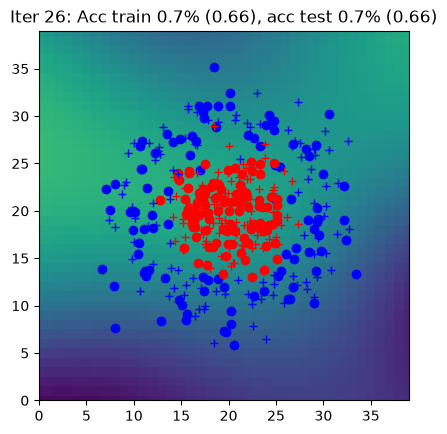

Iter 27: Acc train 0.7% (0.66), acc test 0.7% (0.66)


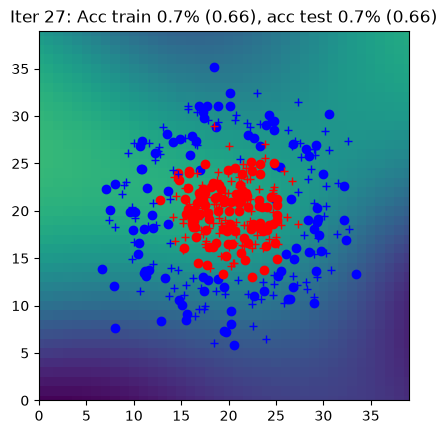

Iter 28: Acc train 0.8% (0.66), acc test 0.8% (0.66)


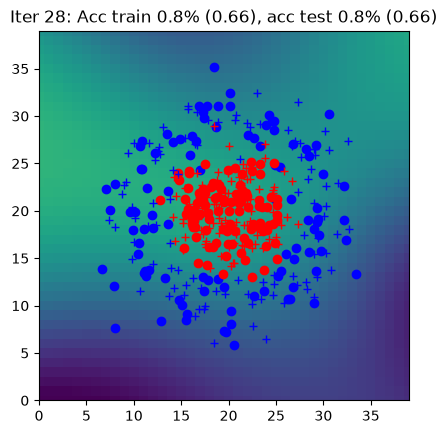

Iter 29: Acc train 0.8% (0.65), acc test 0.8% (0.66)


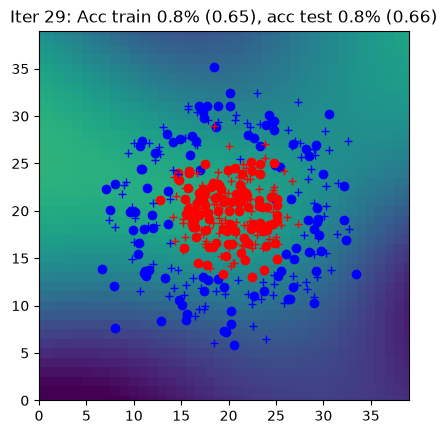

Iter 30: Acc train 0.8% (0.65), acc test 0.8% (0.65)


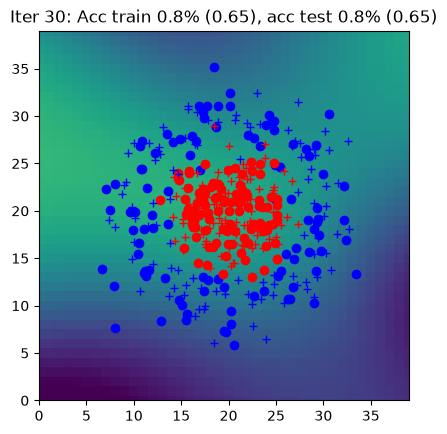

Iter 31: Acc train 0.8% (0.65), acc test 0.8% (0.65)


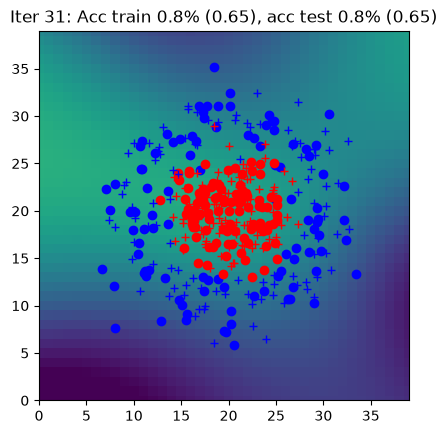

Iter 32: Acc train 0.8% (0.65), acc test 0.8% (0.65)


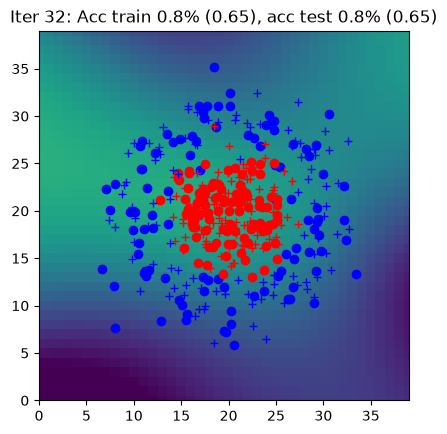

Iter 33: Acc train 0.8% (0.64), acc test 0.8% (0.65)


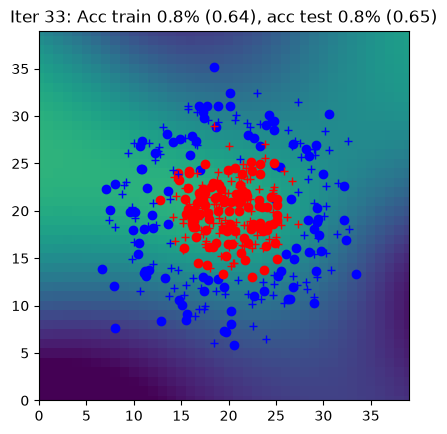

Iter 34: Acc train 0.8% (0.64), acc test 0.8% (0.64)


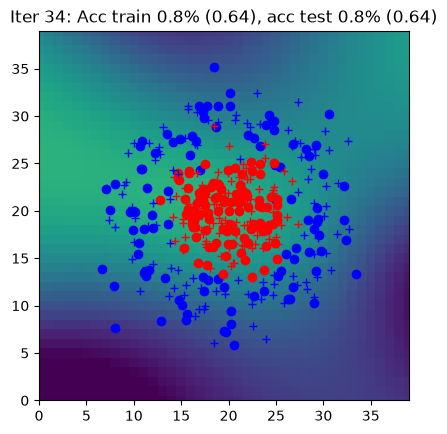

Iter 35: Acc train 0.8% (0.64), acc test 0.8% (0.64)


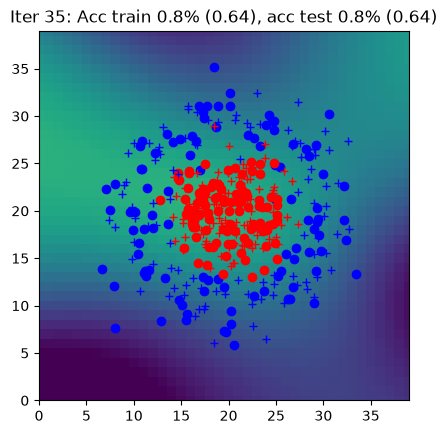

Iter 36: Acc train 0.8% (0.63), acc test 0.8% (0.64)


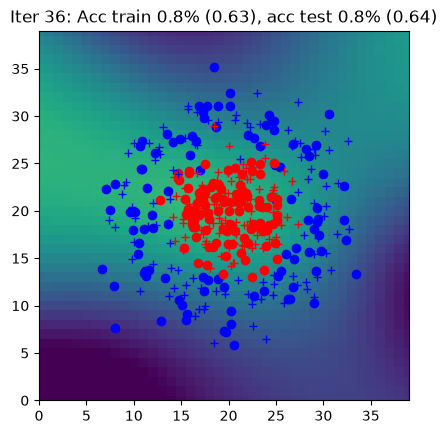

Iter 37: Acc train 0.8% (0.63), acc test 0.8% (0.64)


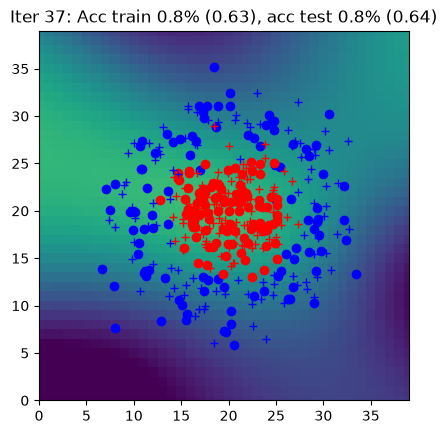

Iter 38: Acc train 0.7% (0.63), acc test 0.8% (0.63)


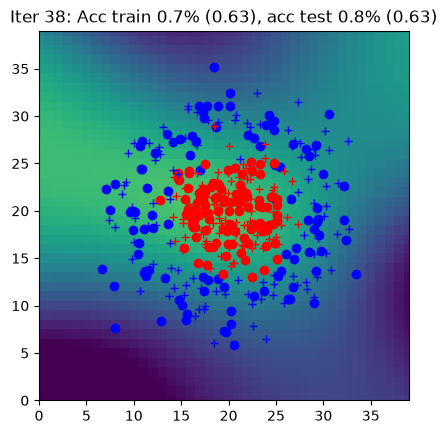

Iter 39: Acc train 0.8% (0.62), acc test 0.8% (0.63)


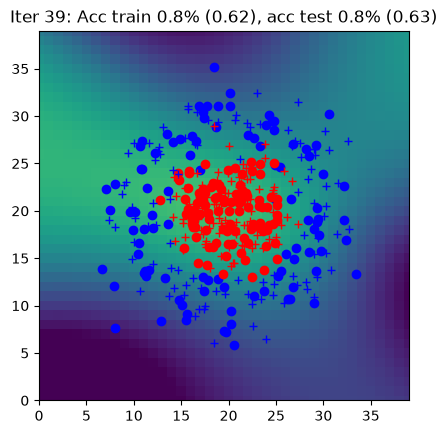

Iter 40: Acc train 0.8% (0.62), acc test 0.8% (0.63)


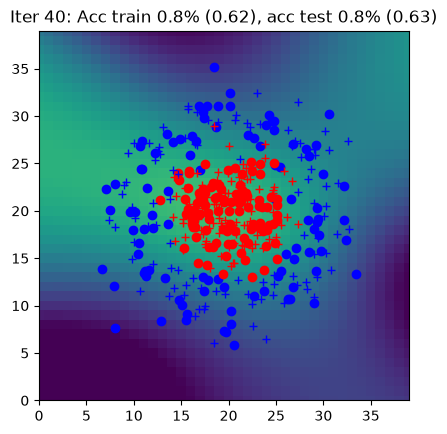

Iter 41: Acc train 0.8% (0.62), acc test 0.8% (0.62)


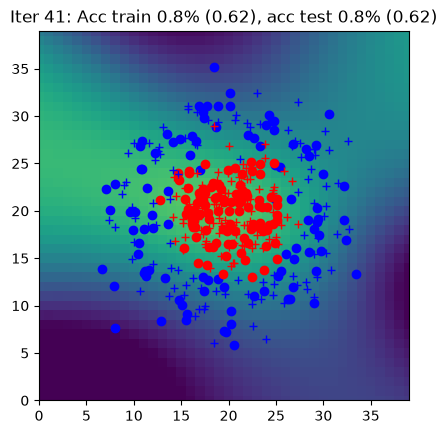

Iter 42: Acc train 0.8% (0.61), acc test 0.8% (0.62)


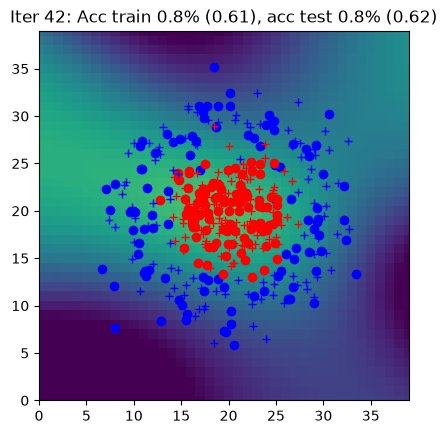

Iter 43: Acc train 0.8% (0.61), acc test 0.8% (0.61)


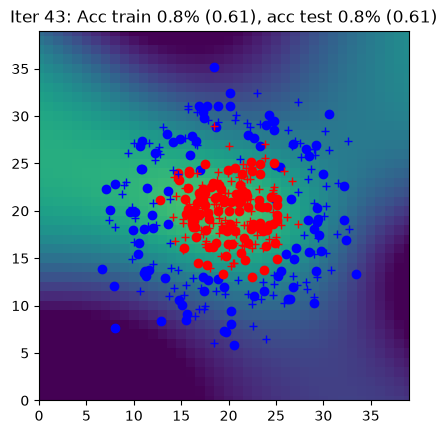

Iter 44: Acc train 0.8% (0.60), acc test 0.8% (0.61)


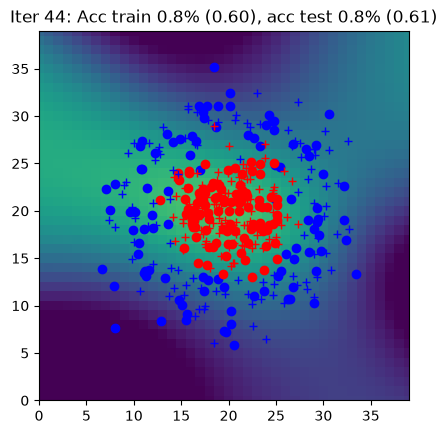

Iter 45: Acc train 0.8% (0.60), acc test 0.8% (0.61)


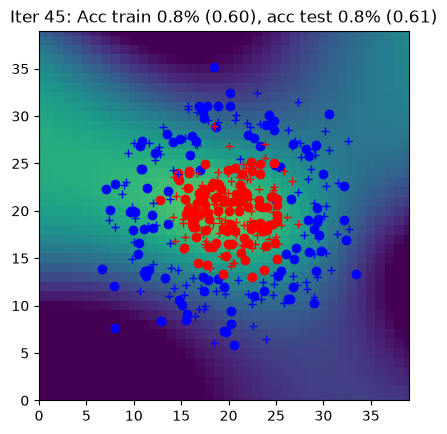

Iter 46: Acc train 0.8% (0.60), acc test 0.9% (0.60)


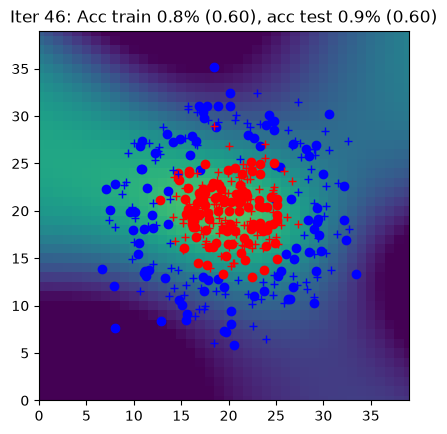

Iter 47: Acc train 0.9% (0.59), acc test 0.9% (0.60)


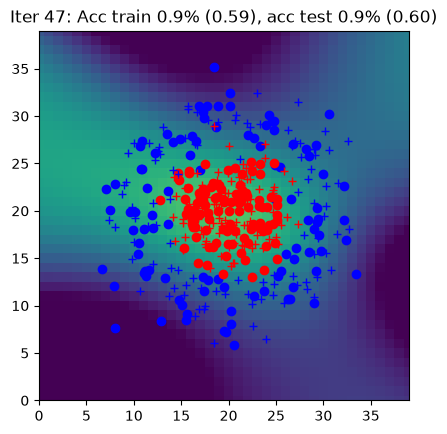

Iter 48: Acc train 0.8% (0.59), acc test 0.8% (0.59)


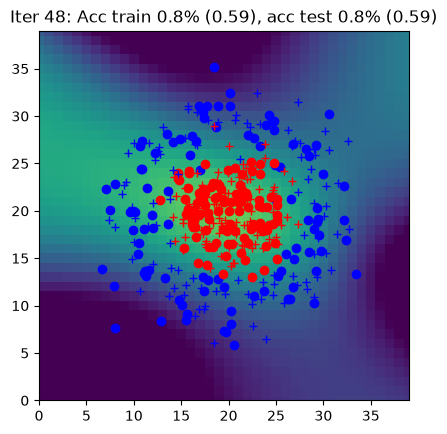

Iter 49: Acc train 0.8% (0.58), acc test 0.8% (0.59)


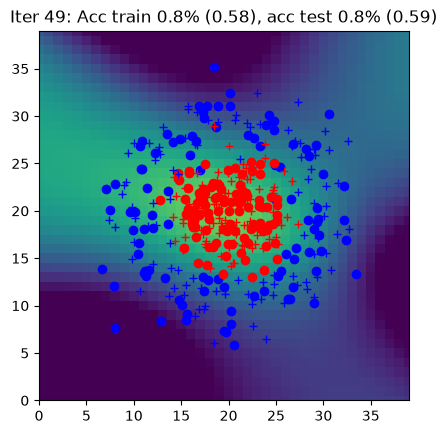

Iter 50: Acc train 0.8% (0.58), acc test 0.8% (0.58)


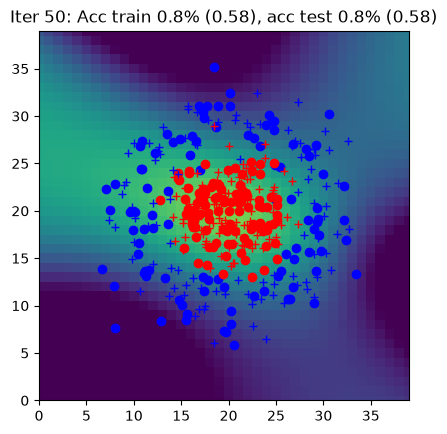

Iter 51: Acc train 0.8% (0.57), acc test 0.8% (0.58)


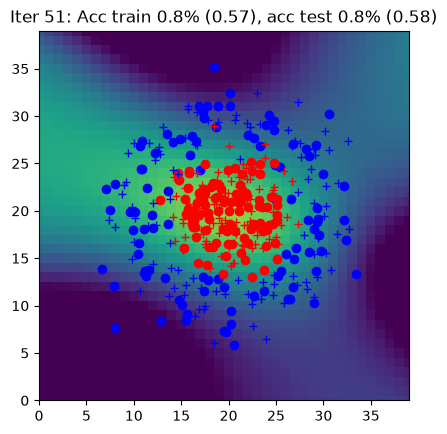

Iter 52: Acc train 0.9% (0.57), acc test 0.9% (0.57)


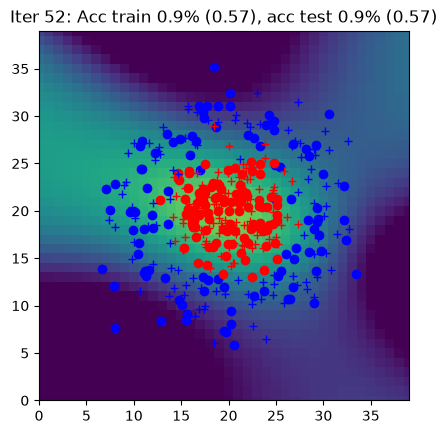

Iter 53: Acc train 0.9% (0.56), acc test 0.9% (0.57)


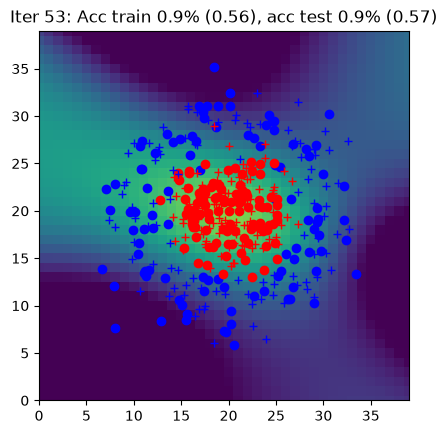

Iter 54: Acc train 0.9% (0.55), acc test 0.9% (0.56)


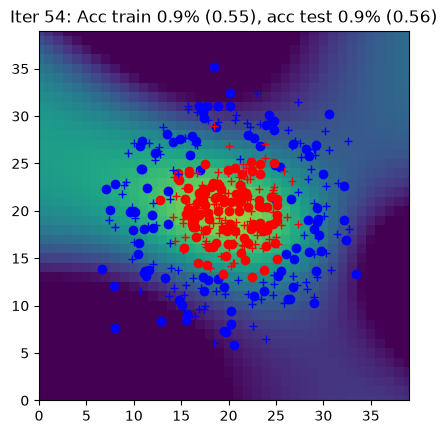

Iter 55: Acc train 0.9% (0.55), acc test 0.9% (0.56)


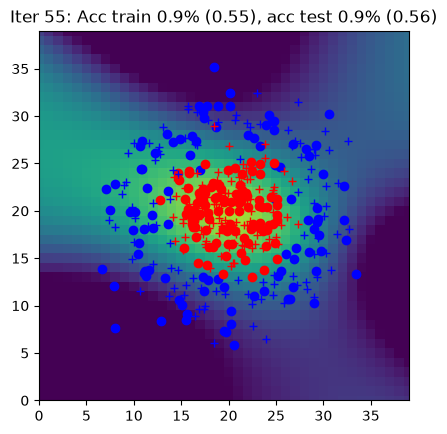

Iter 56: Acc train 0.8% (0.54), acc test 0.8% (0.55)


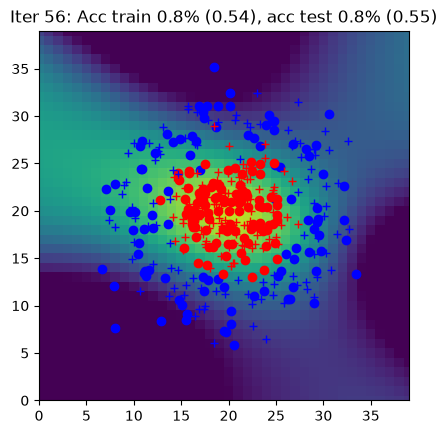

Iter 57: Acc train 0.9% (0.54), acc test 0.9% (0.55)


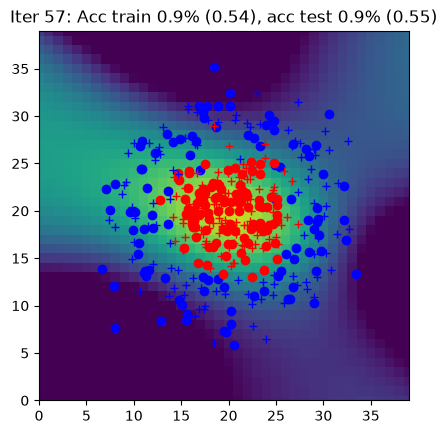

Iter 58: Acc train 0.9% (0.53), acc test 0.9% (0.54)


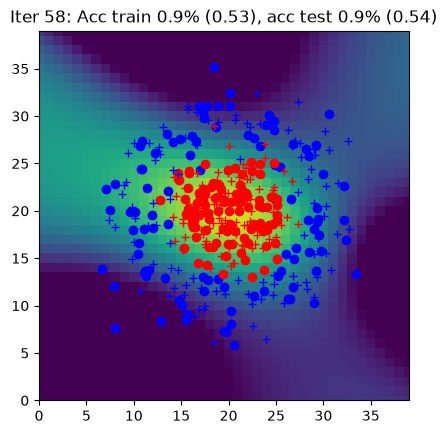

Iter 59: Acc train 0.9% (0.53), acc test 0.9% (0.54)


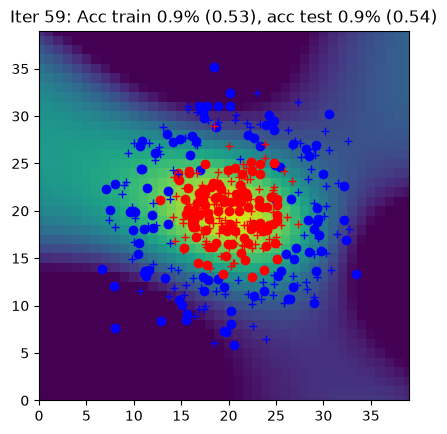

Iter 60: Acc train 0.9% (0.52), acc test 0.9% (0.53)


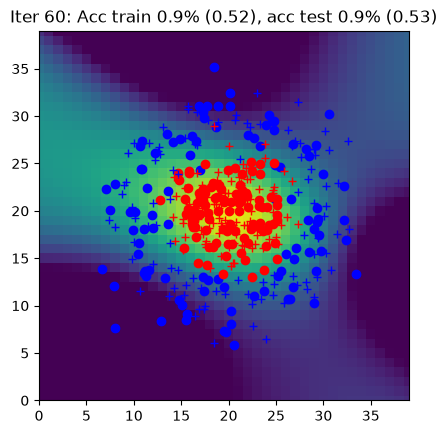

Iter 61: Acc train 0.9% (0.51), acc test 0.9% (0.53)


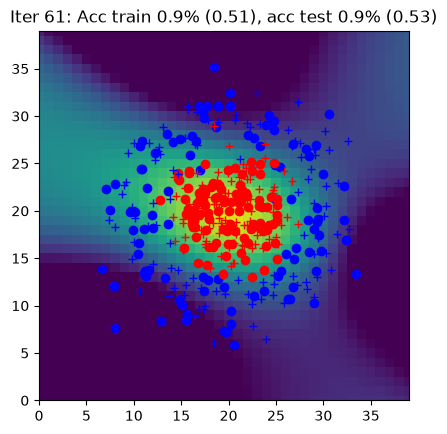

Iter 62: Acc train 0.9% (0.51), acc test 0.9% (0.52)


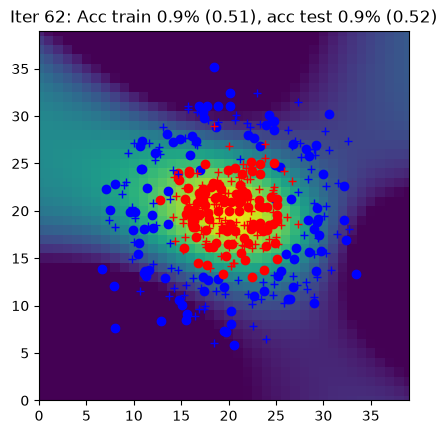

Iter 63: Acc train 0.9% (0.50), acc test 0.9% (0.51)


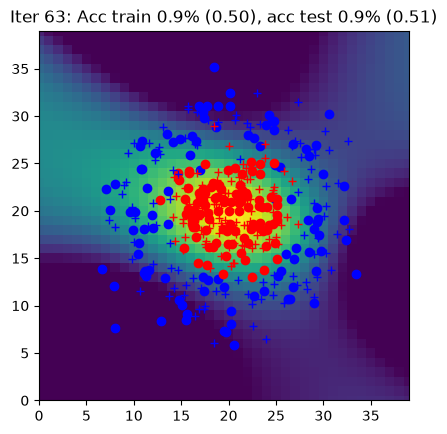

Iter 64: Acc train 0.9% (0.50), acc test 0.9% (0.51)


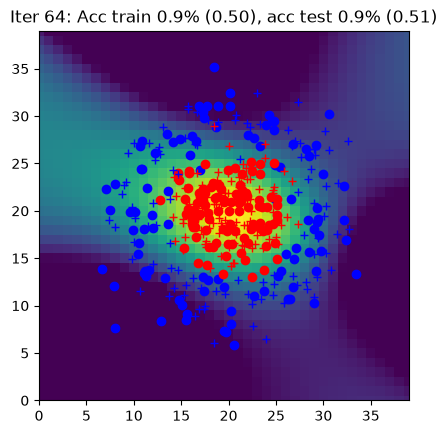

Iter 65: Acc train 0.9% (0.49), acc test 0.9% (0.50)


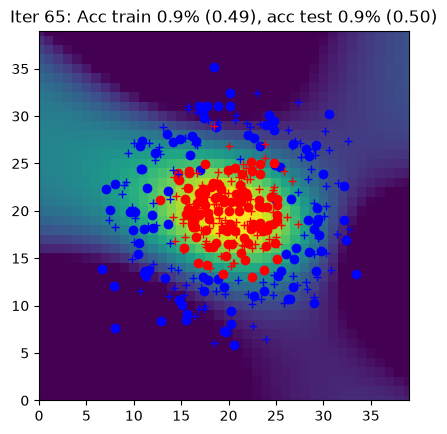

Iter 66: Acc train 0.9% (0.48), acc test 0.9% (0.50)


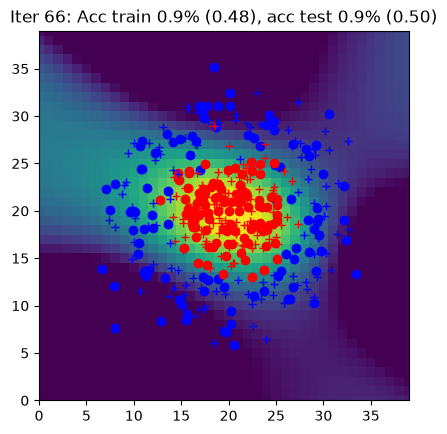

Iter 67: Acc train 0.9% (0.48), acc test 0.9% (0.49)


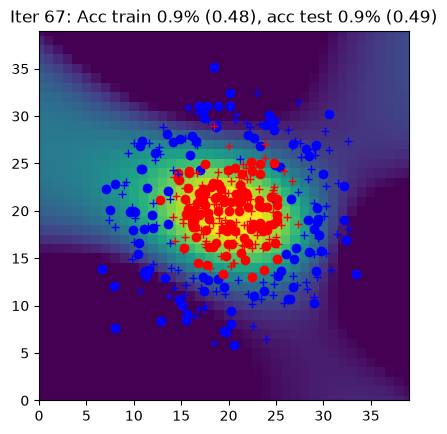

Iter 68: Acc train 0.9% (0.47), acc test 0.9% (0.49)


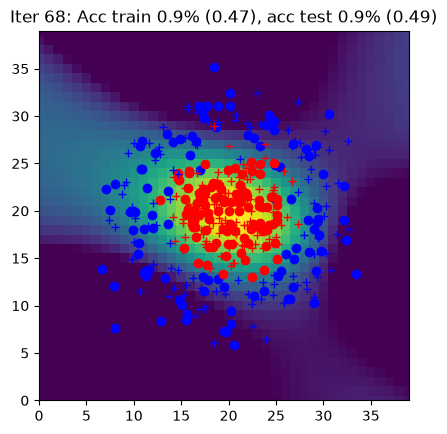

Iter 69: Acc train 0.9% (0.47), acc test 0.9% (0.48)


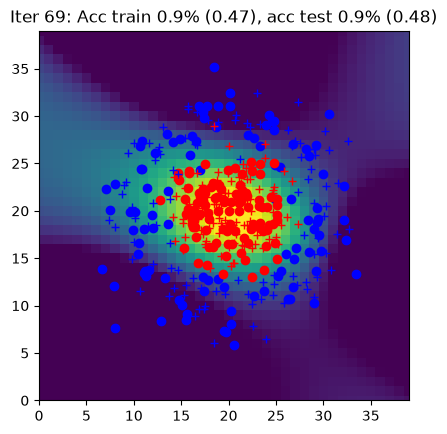

Iter 70: Acc train 0.9% (0.46), acc test 0.9% (0.47)


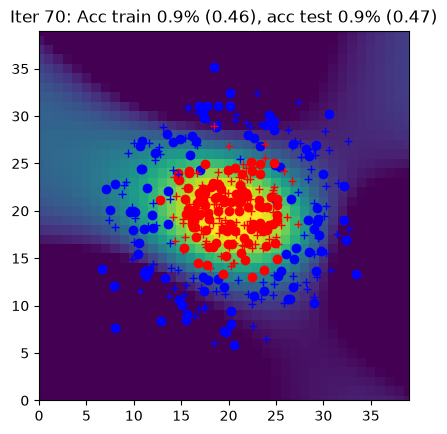

Iter 71: Acc train 0.9% (0.45), acc test 0.9% (0.47)


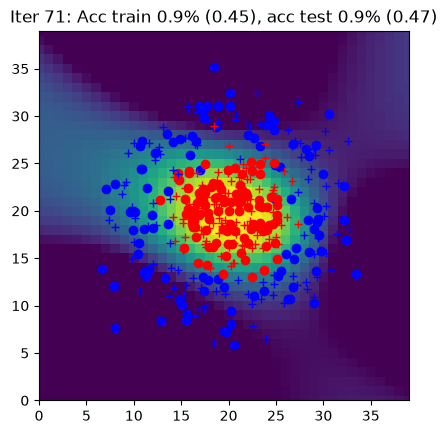

Iter 72: Acc train 0.9% (0.45), acc test 0.9% (0.46)


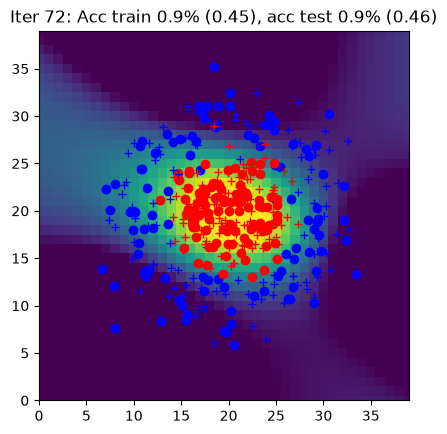

Iter 73: Acc train 0.9% (0.44), acc test 0.9% (0.45)


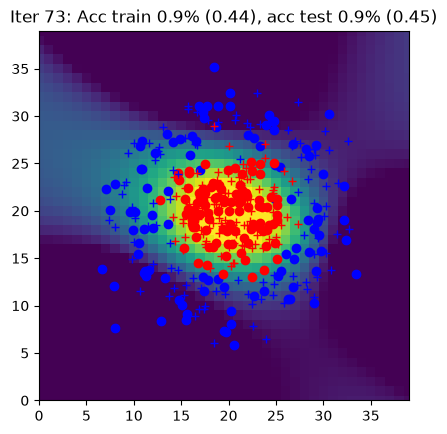

Iter 74: Acc train 0.9% (0.44), acc test 0.9% (0.45)


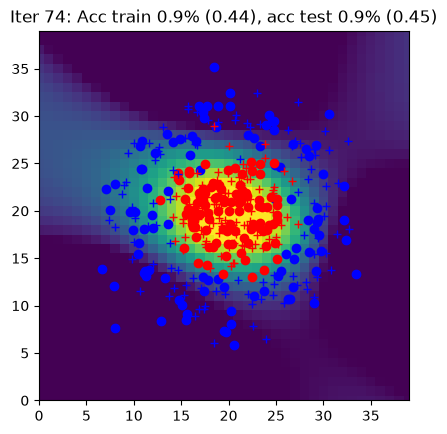

Iter 75: Acc train 0.9% (0.43), acc test 0.9% (0.44)


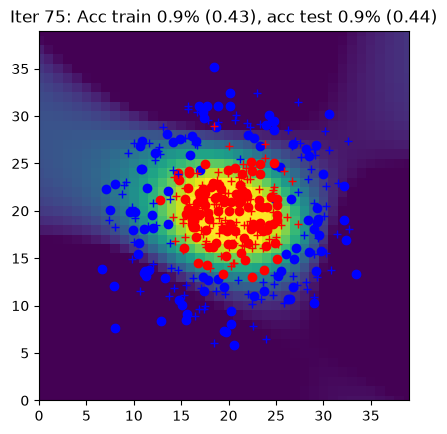

Iter 76: Acc train 0.9% (0.42), acc test 0.9% (0.44)


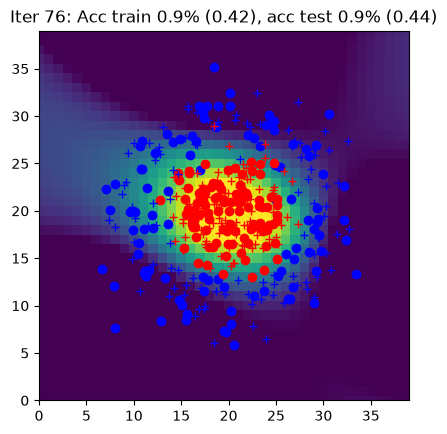

Iter 77: Acc train 0.9% (0.42), acc test 0.9% (0.43)


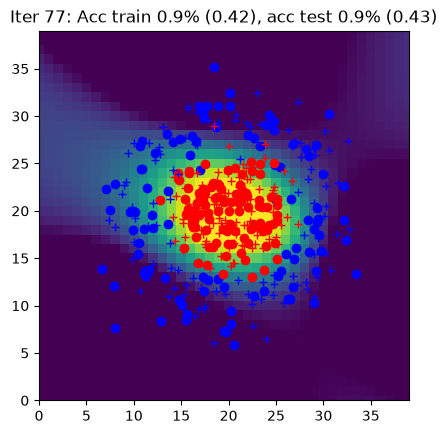

Iter 78: Acc train 0.9% (0.41), acc test 0.9% (0.42)


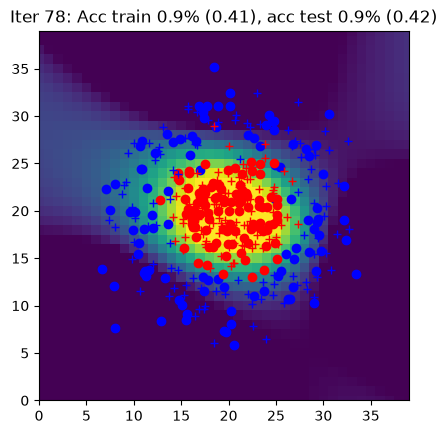

Iter 79: Acc train 0.9% (0.41), acc test 0.9% (0.42)


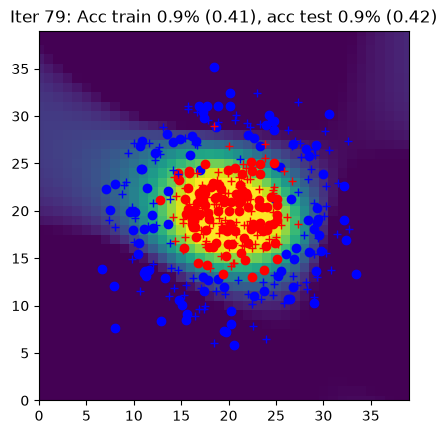

Iter 80: Acc train 0.9% (0.40), acc test 0.9% (0.41)


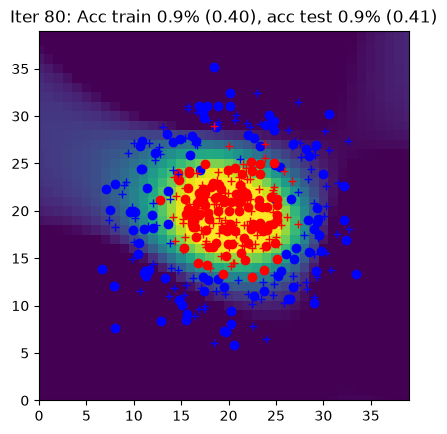

Iter 81: Acc train 0.9% (0.40), acc test 0.9% (0.41)


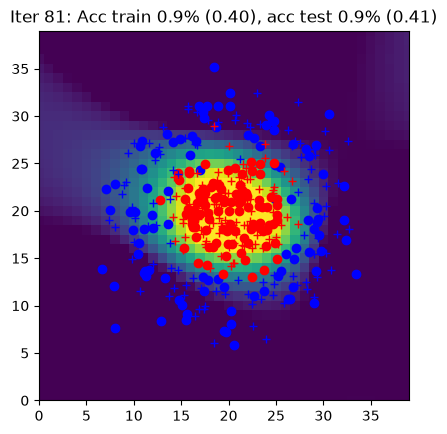

Iter 82: Acc train 0.9% (0.39), acc test 0.9% (0.40)


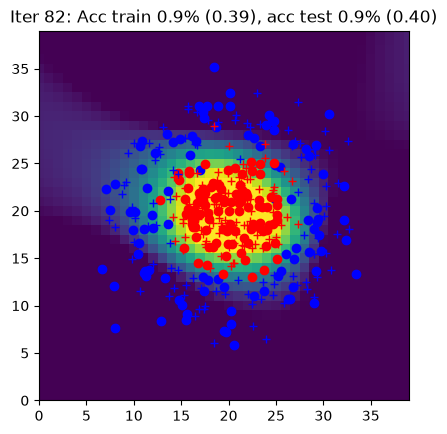

Iter 83: Acc train 0.9% (0.38), acc test 0.9% (0.40)


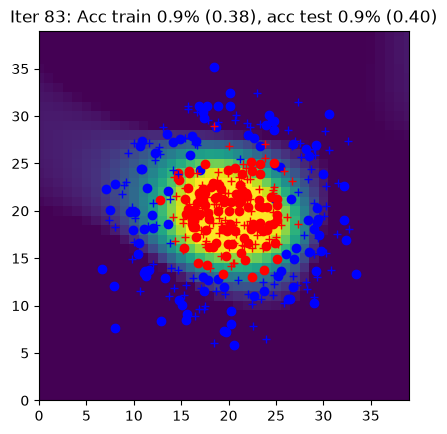

Iter 84: Acc train 0.9% (0.38), acc test 0.9% (0.39)


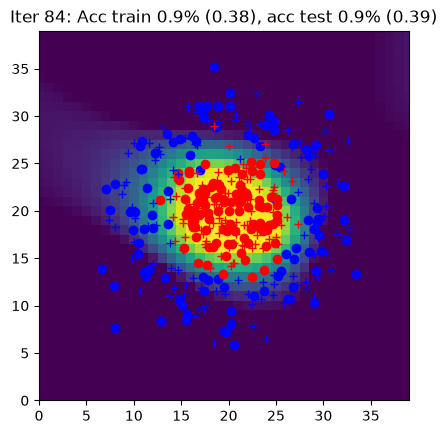

Iter 85: Acc train 0.9% (0.37), acc test 0.9% (0.39)


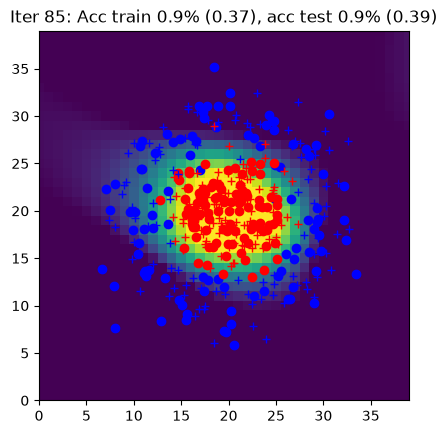

Iter 86: Acc train 0.9% (0.37), acc test 0.9% (0.38)


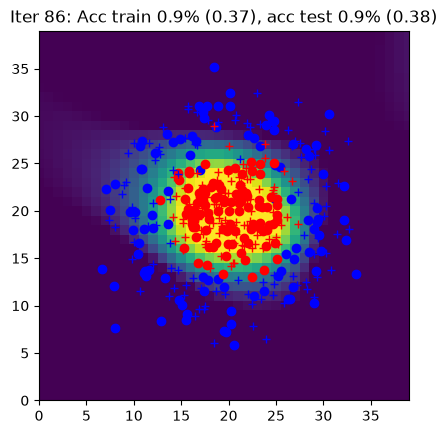

Iter 87: Acc train 0.9% (0.36), acc test 0.9% (0.38)


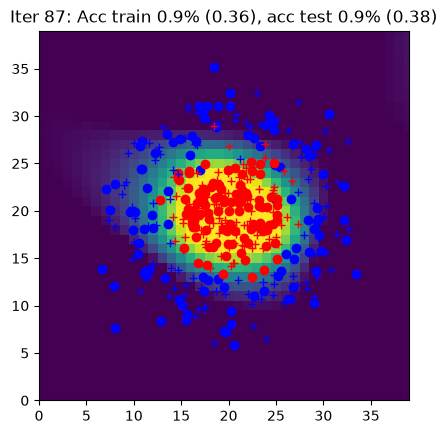

Iter 88: Acc train 0.9% (0.36), acc test 0.9% (0.37)


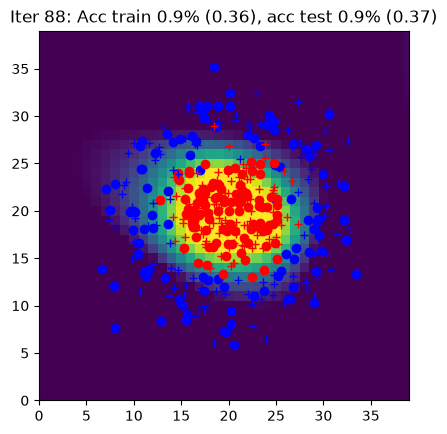

Iter 89: Acc train 0.9% (0.35), acc test 0.9% (0.37)


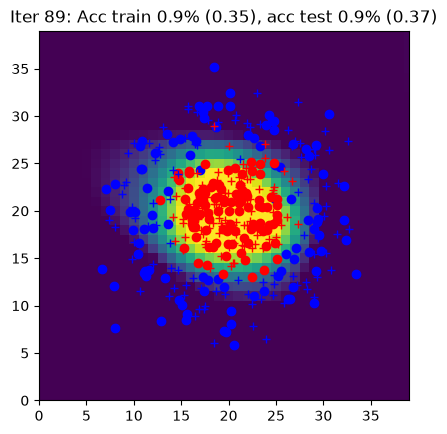

Iter 90: Acc train 0.9% (0.35), acc test 0.9% (0.36)


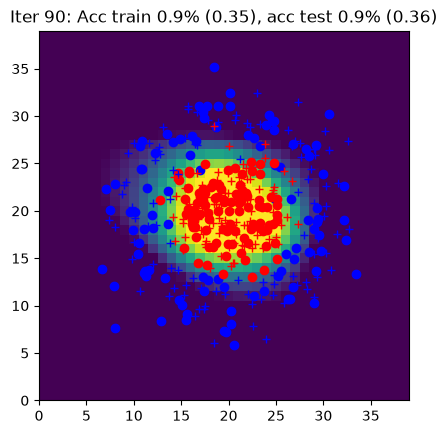

Iter 91: Acc train 0.9% (0.35), acc test 0.9% (0.36)


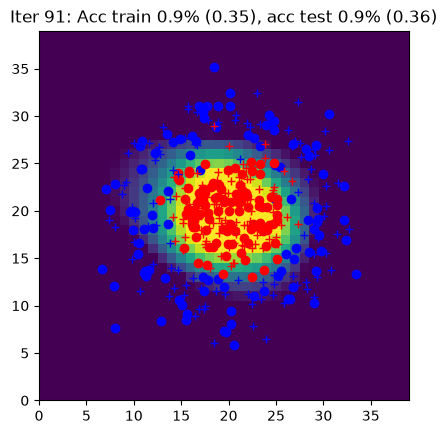

Iter 92: Acc train 0.9% (0.34), acc test 0.9% (0.35)


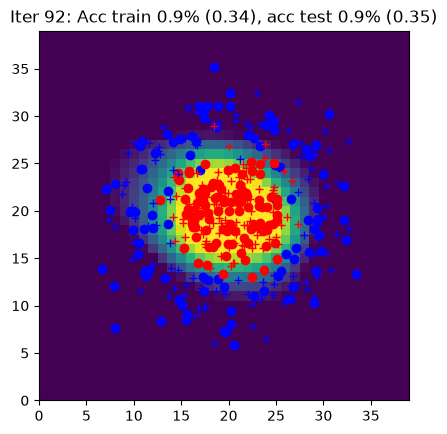

Iter 93: Acc train 0.9% (0.34), acc test 0.9% (0.35)


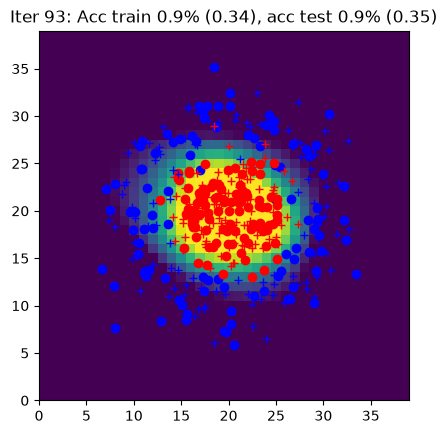

Iter 94: Acc train 0.9% (0.33), acc test 0.9% (0.34)


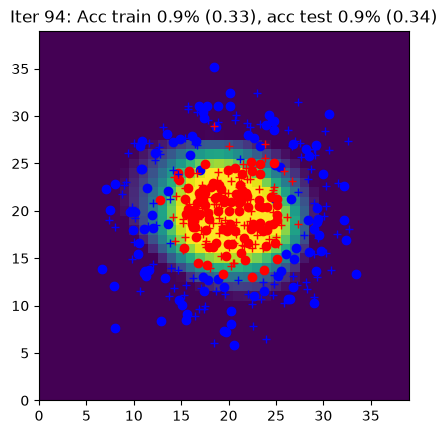

Iter 95: Acc train 0.9% (0.33), acc test 0.9% (0.34)


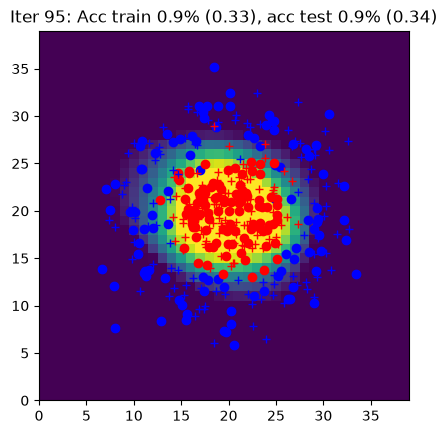

Iter 96: Acc train 0.9% (0.32), acc test 0.9% (0.34)


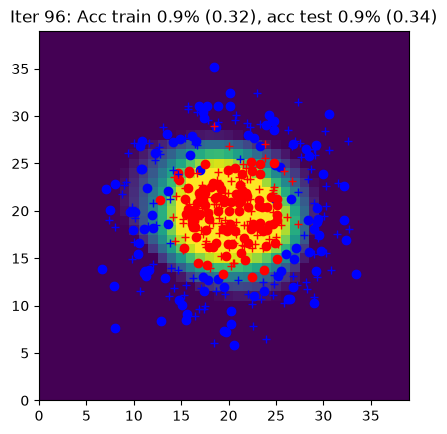

Iter 97: Acc train 0.9% (0.32), acc test 0.9% (0.33)


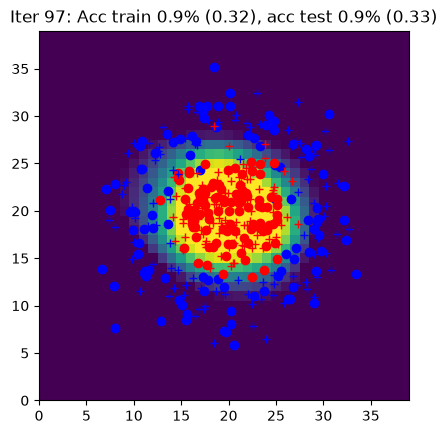

Iter 98: Acc train 0.9% (0.32), acc test 0.9% (0.33)


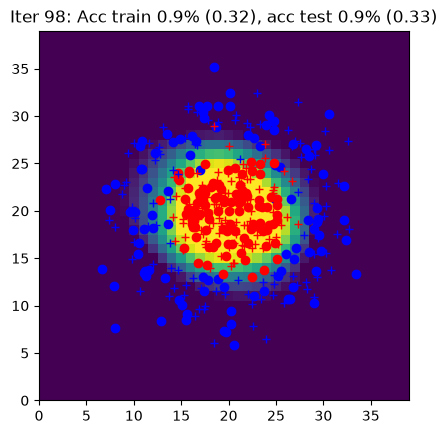

Iter 99: Acc train 0.9% (0.31), acc test 0.9% (0.32)


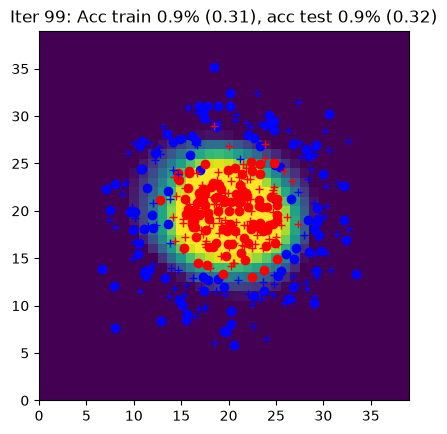

Iter 100: Acc train 0.9% (0.31), acc test 0.9% (0.32)


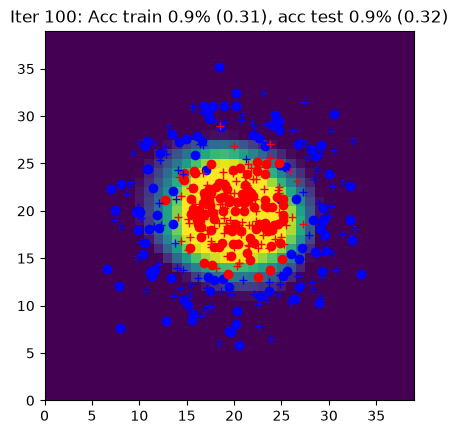

Iter 101: Acc train 0.9% (0.30), acc test 0.9% (0.32)


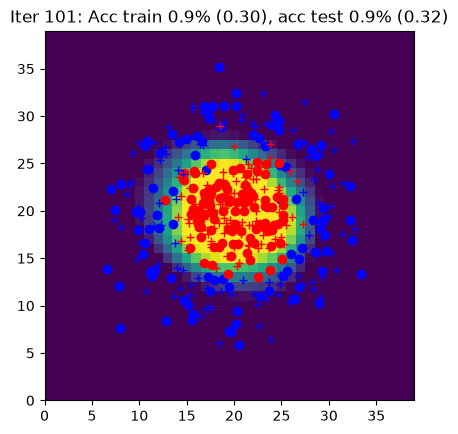

Iter 102: Acc train 0.9% (0.30), acc test 0.9% (0.31)


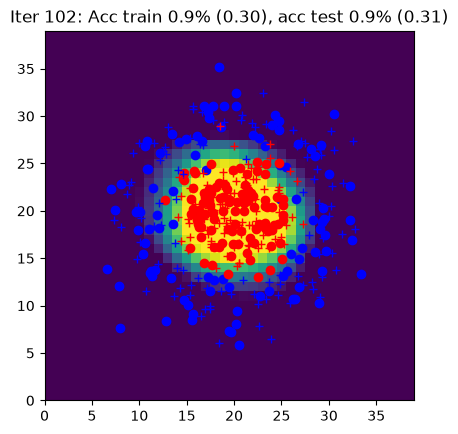

Iter 103: Acc train 0.9% (0.30), acc test 0.9% (0.31)


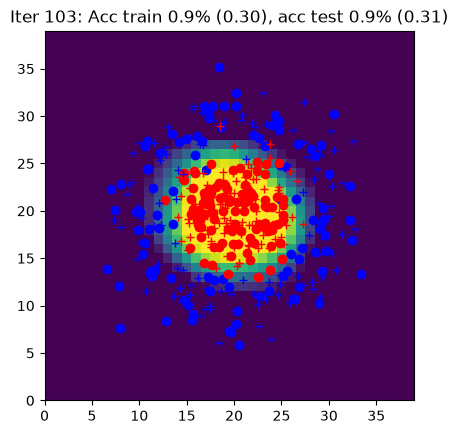

Iter 104: Acc train 0.9% (0.29), acc test 0.9% (0.31)


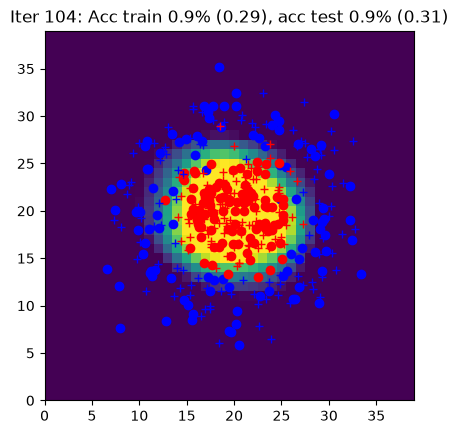

Iter 105: Acc train 0.9% (0.29), acc test 0.9% (0.30)


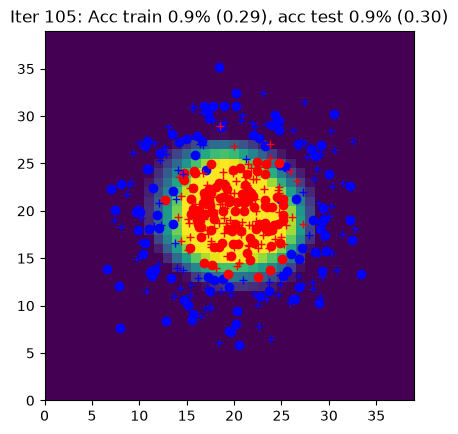

Iter 106: Acc train 0.9% (0.29), acc test 0.9% (0.30)


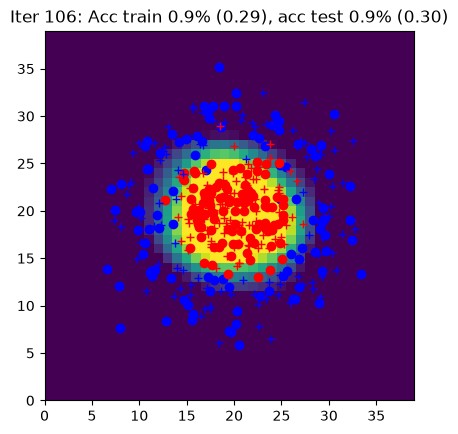

Iter 107: Acc train 1.0% (0.28), acc test 0.9% (0.30)


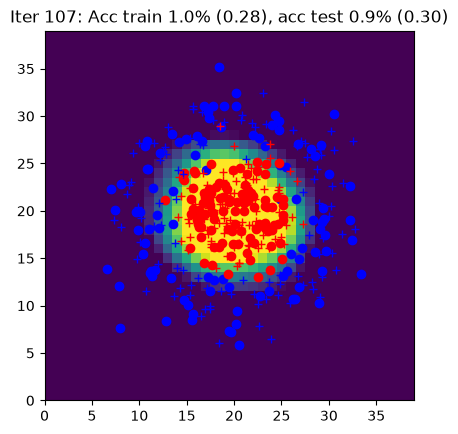

Iter 108: Acc train 0.9% (0.28), acc test 0.9% (0.29)


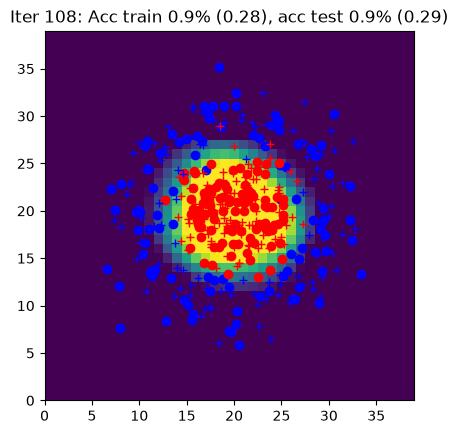

Iter 109: Acc train 1.0% (0.28), acc test 0.9% (0.29)


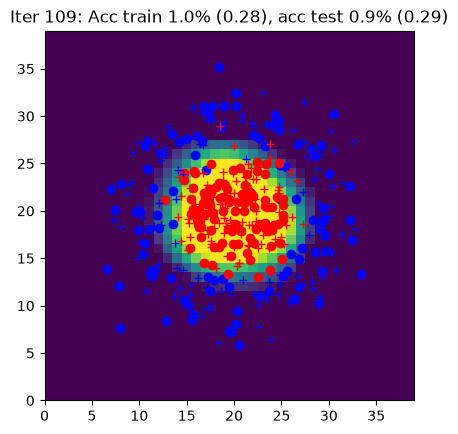

Iter 110: Acc train 1.0% (0.28), acc test 0.9% (0.29)


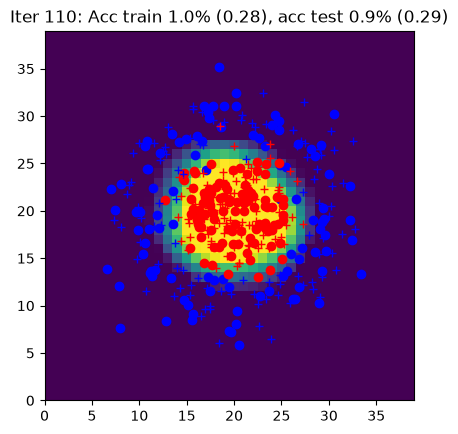

Iter 111: Acc train 1.0% (0.27), acc test 0.9% (0.28)


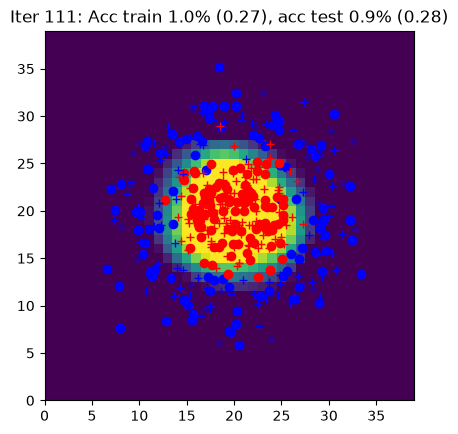

Iter 112: Acc train 1.0% (0.27), acc test 0.9% (0.28)


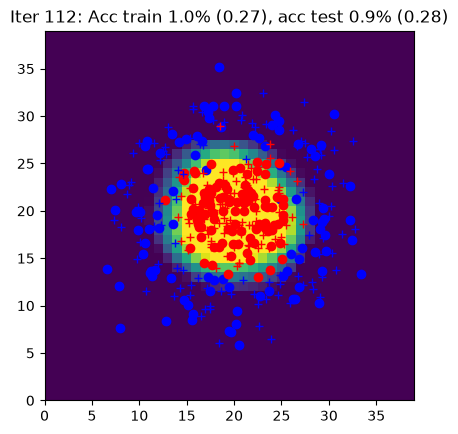

Iter 113: Acc train 1.0% (0.27), acc test 0.9% (0.28)


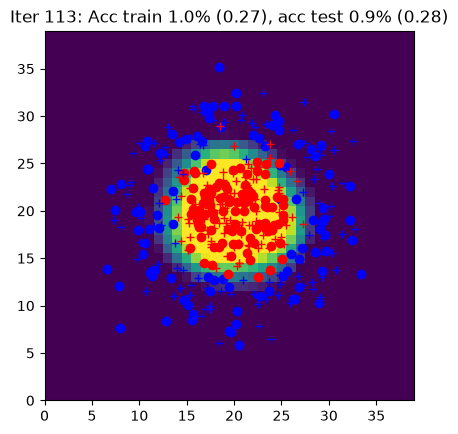

Iter 114: Acc train 1.0% (0.26), acc test 0.9% (0.28)


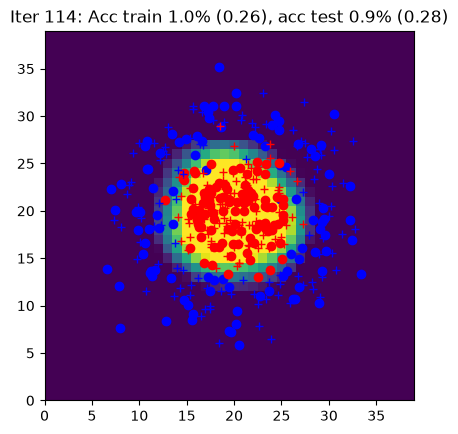

Iter 115: Acc train 0.9% (0.26), acc test 0.9% (0.28)


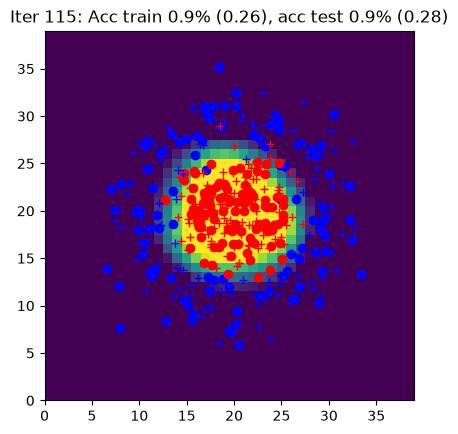

Iter 116: Acc train 0.9% (0.26), acc test 0.9% (0.27)


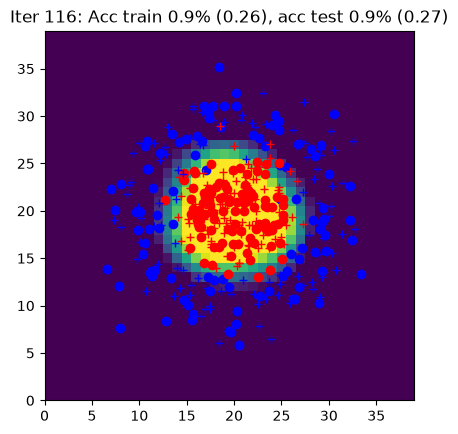

Iter 117: Acc train 1.0% (0.26), acc test 0.9% (0.27)


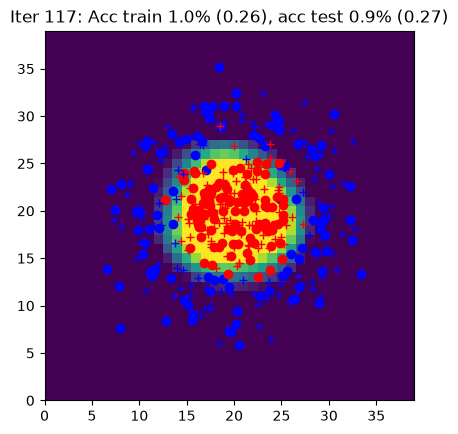

Iter 118: Acc train 1.0% (0.25), acc test 0.9% (0.27)


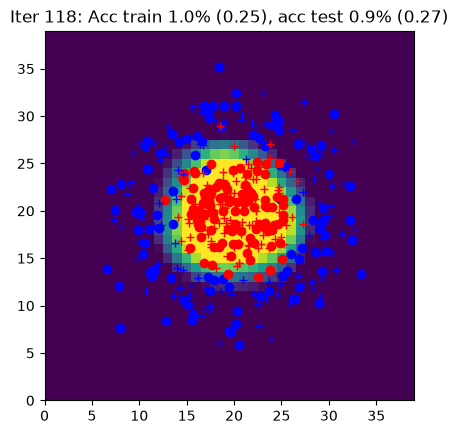

Iter 119: Acc train 1.0% (0.25), acc test 0.9% (0.26)


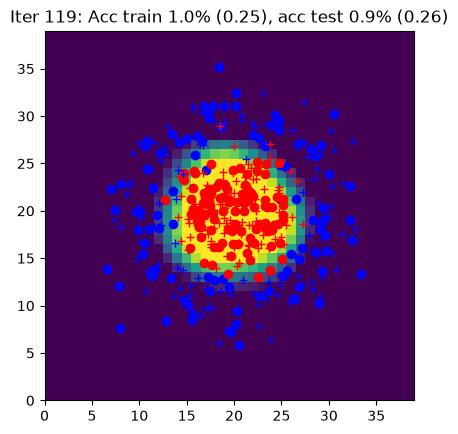

Iter 120: Acc train 1.0% (0.25), acc test 0.9% (0.26)


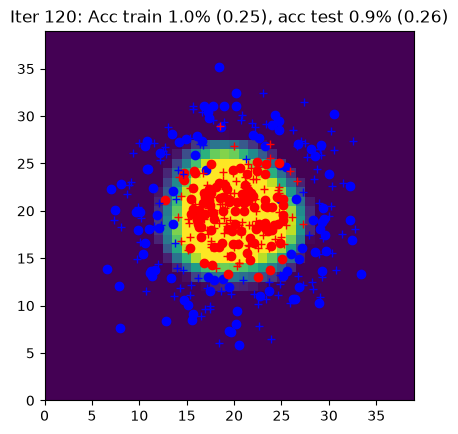

Iter 121: Acc train 1.0% (0.25), acc test 0.9% (0.26)


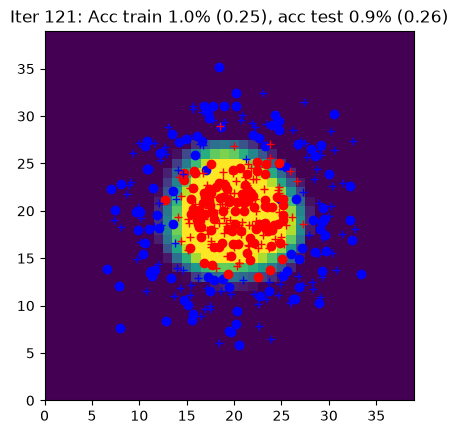

Iter 122: Acc train 0.9% (0.25), acc test 0.9% (0.26)


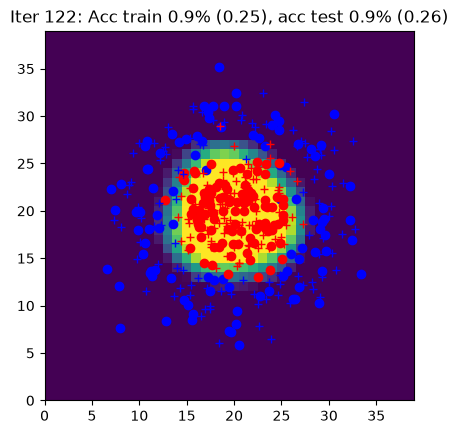

Iter 123: Acc train 1.0% (0.24), acc test 0.9% (0.26)


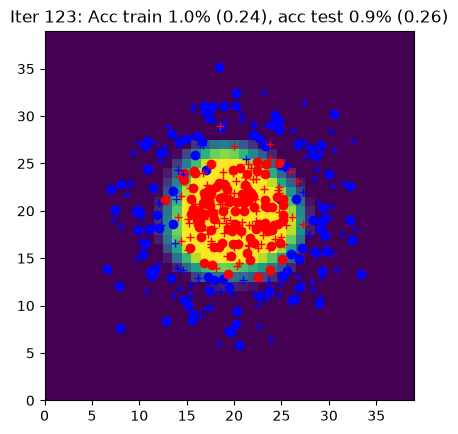

Iter 124: Acc train 1.0% (0.24), acc test 0.9% (0.25)


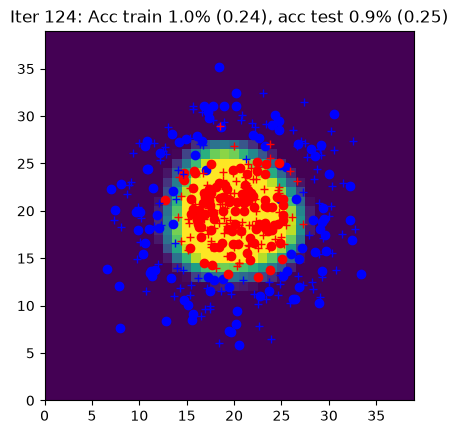

Iter 125: Acc train 0.9% (0.24), acc test 0.9% (0.25)


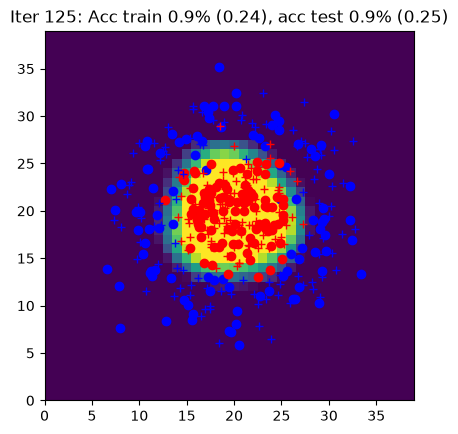

Iter 126: Acc train 0.9% (0.24), acc test 0.9% (0.25)


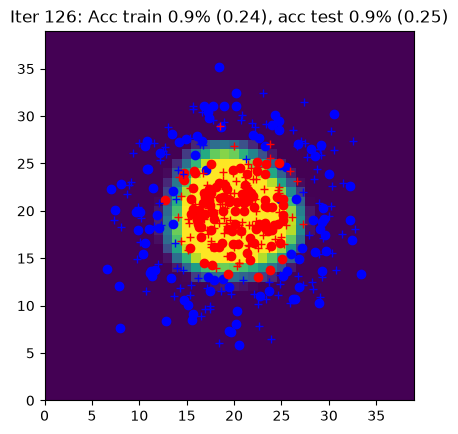

Iter 127: Acc train 1.0% (0.24), acc test 0.9% (0.25)


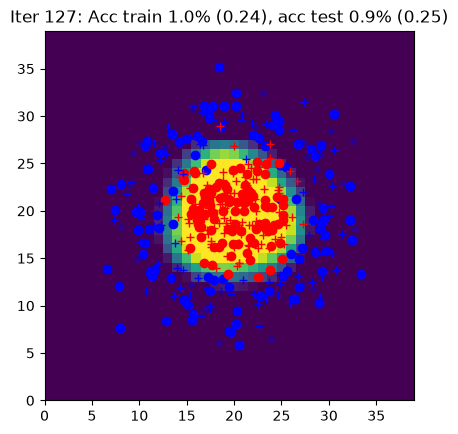

Iter 128: Acc train 0.9% (0.23), acc test 0.9% (0.25)


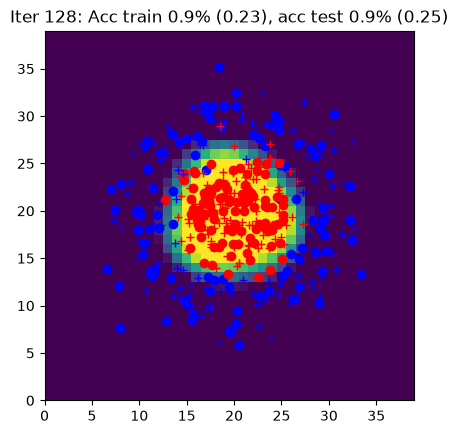

Iter 129: Acc train 1.0% (0.23), acc test 0.9% (0.24)


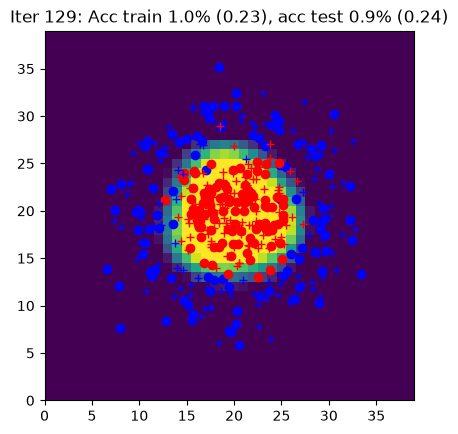

Iter 130: Acc train 1.0% (0.23), acc test 0.9% (0.24)


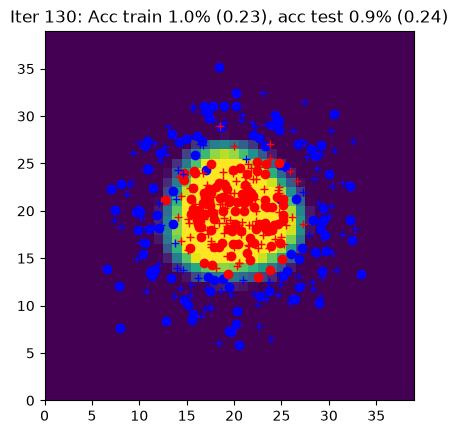

Iter 131: Acc train 1.0% (0.23), acc test 0.9% (0.24)


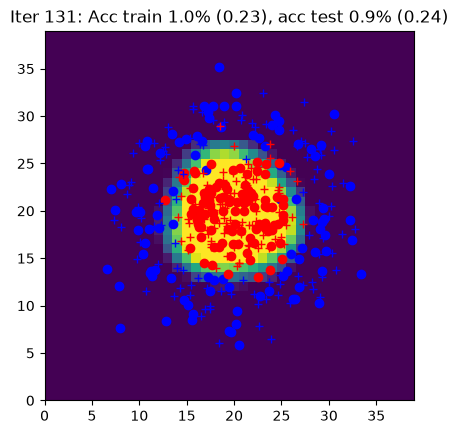

Iter 132: Acc train 0.9% (0.23), acc test 0.9% (0.24)


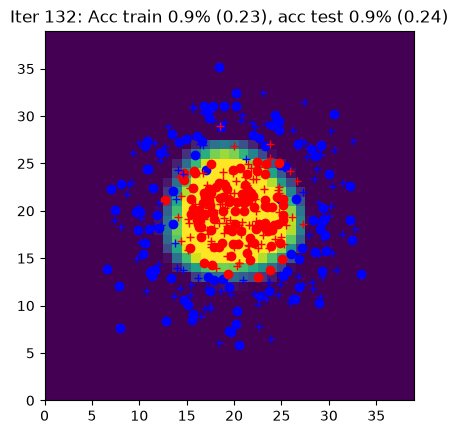

Iter 133: Acc train 1.0% (0.23), acc test 0.9% (0.24)


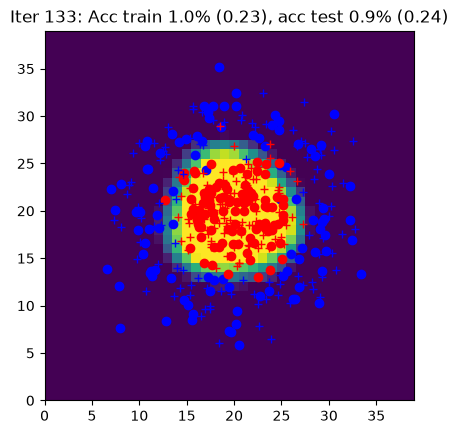

Iter 134: Acc train 0.9% (0.22), acc test 0.9% (0.24)


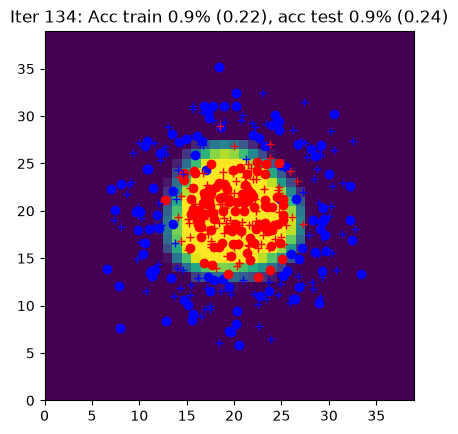

Iter 135: Acc train 1.0% (0.22), acc test 0.9% (0.24)


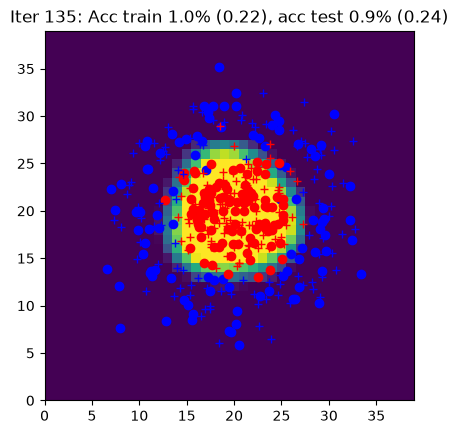

Iter 136: Acc train 1.0% (0.22), acc test 0.9% (0.23)


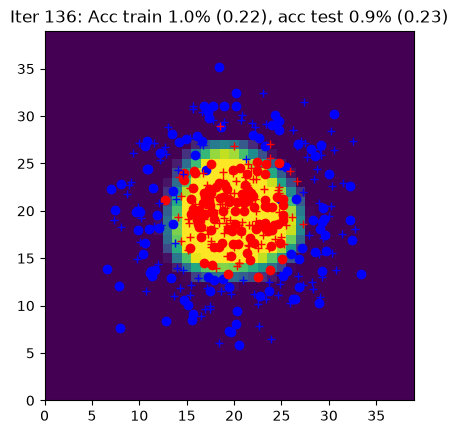

Iter 137: Acc train 0.9% (0.22), acc test 0.9% (0.23)


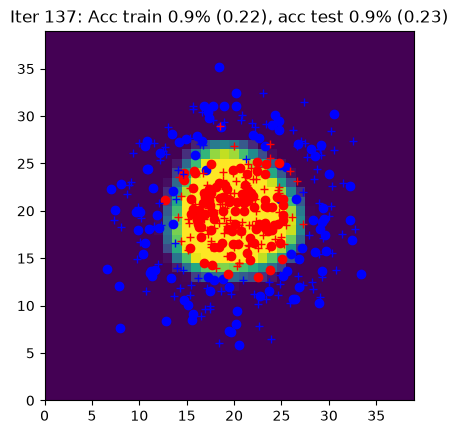

Iter 138: Acc train 1.0% (0.22), acc test 0.9% (0.23)


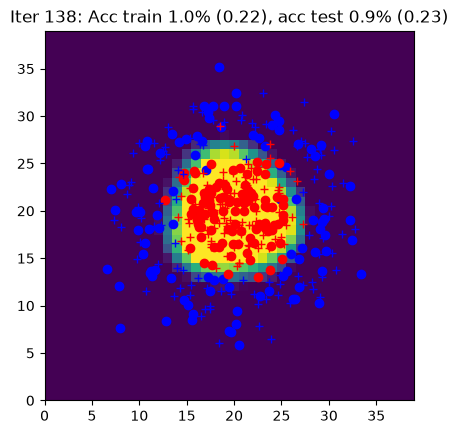

Iter 139: Acc train 0.9% (0.22), acc test 0.9% (0.23)


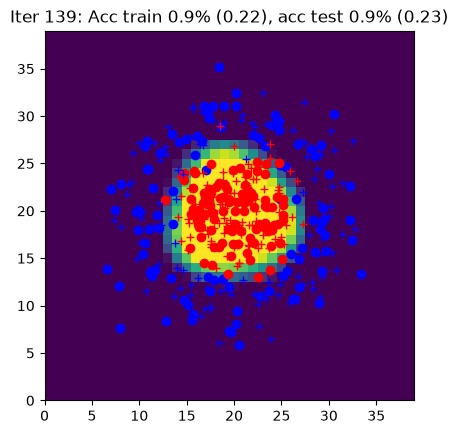

Iter 140: Acc train 0.9% (0.22), acc test 0.9% (0.23)


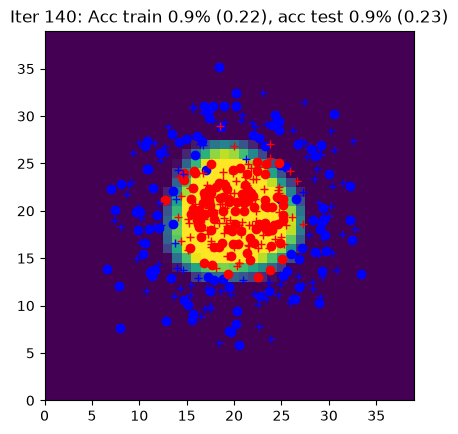

Iter 141: Acc train 1.0% (0.21), acc test 0.9% (0.23)


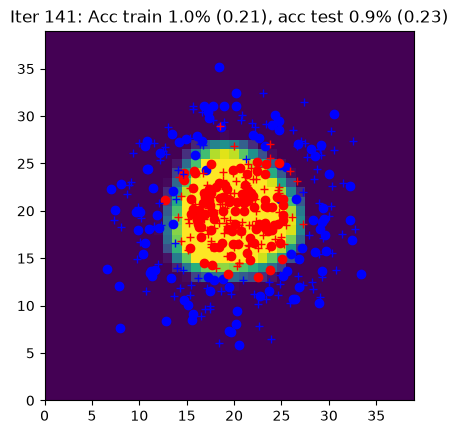

Iter 142: Acc train 1.0% (0.21), acc test 0.9% (0.23)


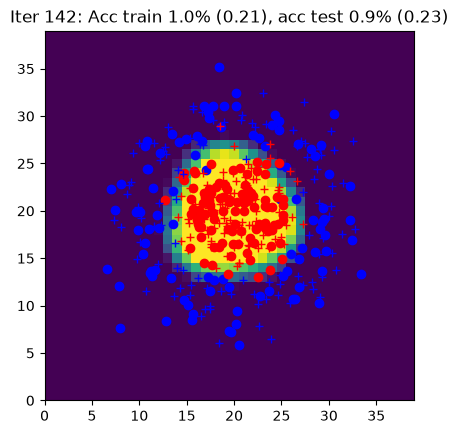

Iter 143: Acc train 0.9% (0.21), acc test 0.9% (0.22)


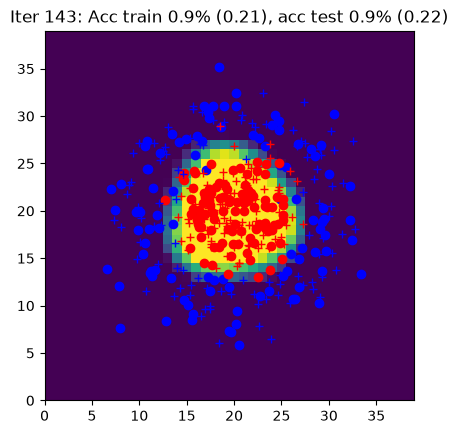

Iter 144: Acc train 0.9% (0.21), acc test 0.9% (0.22)


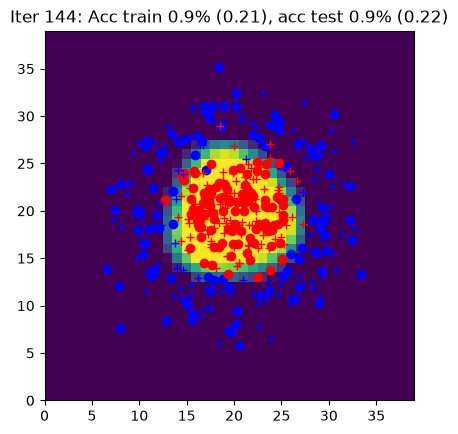

Iter 145: Acc train 0.9% (0.21), acc test 0.9% (0.22)


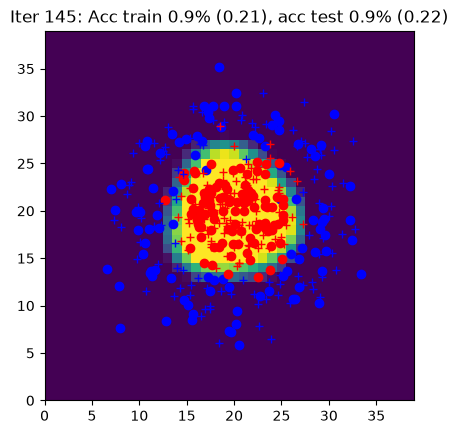

Iter 146: Acc train 0.9% (0.21), acc test 0.9% (0.22)


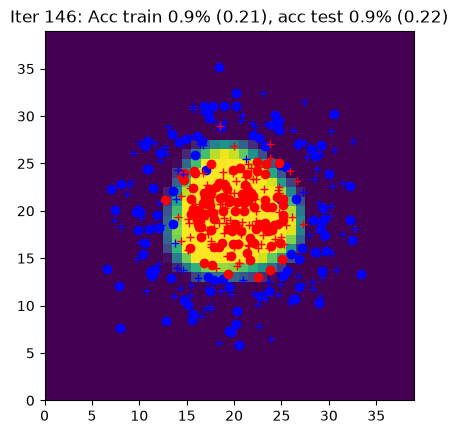

Iter 147: Acc train 1.0% (0.21), acc test 0.9% (0.22)


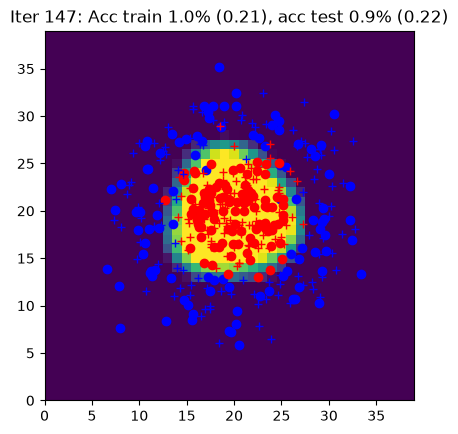

Iter 148: Acc train 1.0% (0.21), acc test 0.9% (0.22)


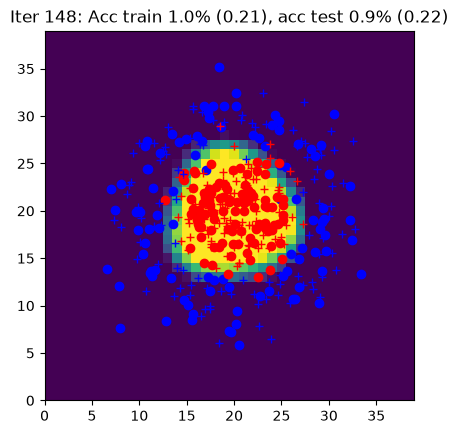

Iter 149: Acc train 1.0% (0.21), acc test 0.9% (0.22)


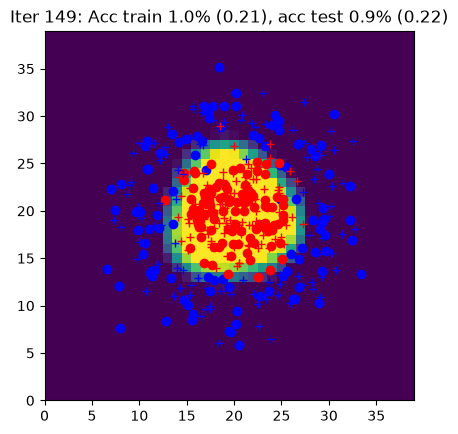

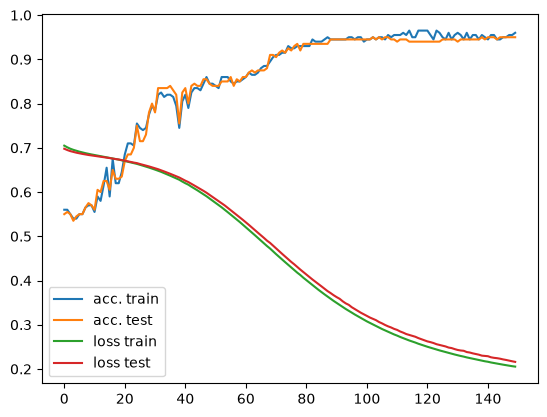

In [102]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

model, loss, optim = init_model(nx, nh, ny, eta)

curves = [[], [], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code  here ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j + 1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: loss_accuracy
        # the forward with the predict method from the model
        # the backward function with autograd
        # and then an optimization step
        Yhat = model(X)
        L, acc = loss_accuracy(loss, Yhat, Y)
        optim.zero_grad()
        L.backward()
        optim.step()

    ####################
    ##      FIN        #
    ####################

    Yhat_train = model(data.Xtrain)
    Yhat_test = model(data.Xtest)
    Ltrain, acctrain = loss_accuracy(loss, Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(loss, Yhat_test, data.Ytest)
    Ygrid = model(data.Xgrid)

    title = "Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})".format(
        iteration, acctrain, Ltrain, acctest, Ltest
    )
    print(title)
    data.plot_data_with_grid(torch.nn.Softmax(dim=1)(Ygrid.detach()), title)

    curves[0].append(acctrain.item())
    curves[1].append(acctest.item())
    curves[2].append(Ltrain.item())
    curves[3].append(Ltest.item())

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 5 : MNIST

Apply the code from previous part code to the MNIST dataset.

In [103]:
# init
data = MNISTData()
N = data.Xtrain.shape[0]
Nbatch = 100
nx = data.Xtrain.shape[1]
nh = 100
ny = data.Ytrain.shape[1]
eta = 0.03

In [104]:
model, loss, optim = init_model(nx, nh, ny, eta)

# epoch
for iteration in range(50):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j + 1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        Yhat = model(X)
        L, acc = loss_accuracy(loss, Yhat, Y)
        optim.zero_grad()
        L.backward()
        optim.step()

    # evaluation
    with torch.no_grad():
        Yhat_train = model(data.Xtrain)
        Yhat_test = model(data.Xtest)

        Ltrain, acctrain = loss_accuracy(loss, Yhat_train, data.Ytrain)

        Ltest, acctest = loss_accuracy(loss, Yhat_test, data.Ytest)

    title = "EPOCH {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})".format(
        iteration,
        acctrain.item() * 100,
        Ltrain.item(),
        acctest.item() * 100,
        Ltest.item(),
    )

    print(title)

EPOCH 0: Acc train 86.8% (0.49), acc test 87.1% (0.48)
EPOCH 1: Acc train 87.2% (0.46), acc test 87.9% (0.44)
EPOCH 2: Acc train 86.8% (0.45), acc test 86.9% (0.44)
EPOCH 3: Acc train 86.9% (0.44), acc test 87.5% (0.42)
EPOCH 4: Acc train 87.8% (0.42), acc test 88.7% (0.39)
EPOCH 5: Acc train 87.7% (0.42), acc test 88.0% (0.40)
EPOCH 6: Acc train 88.0% (0.41), acc test 88.3% (0.39)
EPOCH 7: Acc train 88.7% (0.39), acc test 89.4% (0.37)
EPOCH 8: Acc train 86.9% (0.44), acc test 87.6% (0.42)
EPOCH 9: Acc train 85.6% (0.46), acc test 86.0% (0.46)
EPOCH 10: Acc train 88.7% (0.37), acc test 88.5% (0.37)
EPOCH 11: Acc train 87.1% (0.42), acc test 87.0% (0.42)
EPOCH 12: Acc train 89.1% (0.37), acc test 89.2% (0.36)
EPOCH 13: Acc train 89.2% (0.36), acc test 89.7% (0.36)
EPOCH 14: Acc train 87.6% (0.40), acc test 88.2% (0.39)
EPOCH 15: Acc train 87.5% (0.41), acc test 88.4% (0.38)
EPOCH 16: Acc train 89.3% (0.35), acc test 89.8% (0.35)
EPOCH 17: Acc train 89.3% (0.36), acc test 89.8% (0.35)
EP

# Part 6: Bonus: SVM


Train a SVM model on the Circles dataset.

Ideas :
- First try a linear SVM (sklearn.svm.LinearSVC dans scikit-learn). Does it work well ? Why ?
- Then try more complex kernels (sklearn.svm.SVC). Which one is the best ? why ?
- Does the parameter C of regularization have an impact? Why ?

In [105]:
# data
data = CirclesData()
Xtrain = data.Xtrain.numpy()
Ytrain = data.Ytrain[:, 0].numpy()

Xgrid = data.Xgrid.numpy()

Xtest = data.Xtest.numpy()
Ytest = data.Ytest[:, 0].numpy()


def plot_svm_predictions(data, predictions):
    plt.figure(2)
    plt.clf()
    plt.imshow(np.reshape(predictions, (40, 40)))
    plt.plot(
        data._Xtrain[data._Ytrain[:, 0] == 1, 0] * 10 + 20,
        data._Xtrain[data._Ytrain[:, 0] == 1, 1] * 10 + 20,
        "bo",
        label="Train",
    )
    plt.plot(
        data._Xtrain[data._Ytrain[:, 1] == 1, 0] * 10 + 20,
        data._Xtrain[data._Ytrain[:, 1] == 1, 1] * 10 + 20,
        "ro",
    )
    plt.plot(
        data._Xtest[data._Ytest[:, 0] == 1, 0] * 10 + 20,
        data._Xtest[data._Ytest[:, 0] == 1, 1] * 10 + 20,
        "b+",
        label="Test",
    )
    plt.plot(
        data._Xtest[data._Ytest[:, 1] == 1, 0] * 10 + 20,
        data._Xtest[data._Ytest[:, 1] == 1, 1] * 10 + 20,
        "r+",
    )
    plt.xlim(0, 39)
    plt.ylim(0, 39)
    plt.clim(0.3, 0.7)
    plt.draw()
    plt.pause(1e-3)

In [106]:
import sklearn.svm

############################
### Your code here   #######
### Train the SVM    #######
## See https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
## and https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
############################

svm = sklearn.svm.LinearSVC()
svm.fit(Xtrain, Ytrain)

###########################

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

Accuracy : 53.00


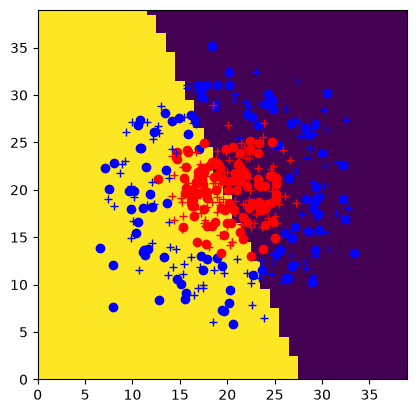

In [107]:
## Print results

Ytest_pred = svm.predict(Xtest)
accuracy = np.sum(Ytest == Ytest_pred) / len(Ytest)
print(f"Accuracy : {100 * accuracy:.2f}")
Ygrid_pred = svm.predict(Xgrid)
plot_svm_predictions(data, Ygrid_pred)

Accuracy : 62.00


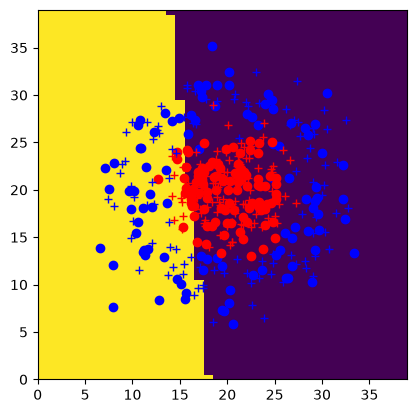

In [108]:
svm = sklearn.svm.SVC(kernel="linear")
svm.fit(Xtrain, Ytrain)

Ytest_pred = svm.predict(Xtest)
accuracy = np.sum(Ytest == Ytest_pred) / len(Ytest)
print(f"Accuracy : {100 * accuracy:.2f}")
Ygrid_pred = svm.predict(Xgrid)
plot_svm_predictions(data, Ygrid_pred)

Accuracy : 54.50


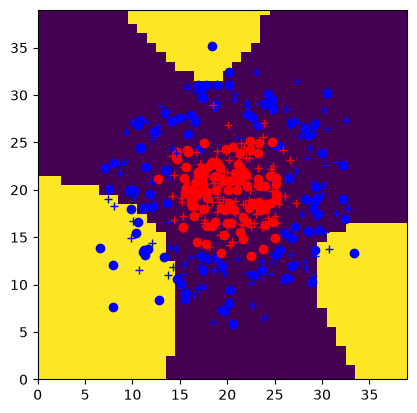

In [109]:
svm = sklearn.svm.SVC(kernel="poly")
svm.fit(Xtrain, Ytrain)

Ytest_pred = svm.predict(Xtest)
accuracy = np.sum(Ytest == Ytest_pred) / len(Ytest)
print(f"Accuracy : {100 * accuracy:.2f}")
Ygrid_pred = svm.predict(Xgrid)
plot_svm_predictions(data, Ygrid_pred)

Accuracy : 65.00


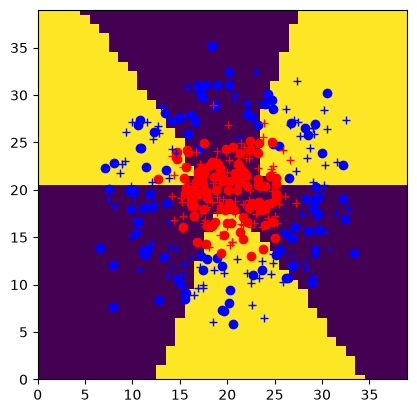

In [110]:
svm = sklearn.svm.SVC(kernel="sigmoid")
svm.fit(Xtrain, Ytrain)

Ytest_pred = svm.predict(Xtest)
accuracy = np.sum(Ytest == Ytest_pred) / len(Ytest)
print(f"Accuracy : {100 * accuracy:.2f}")
Ygrid_pred = svm.predict(Xgrid)
plot_svm_predictions(data, Ygrid_pred)

Accuracy : 94.00


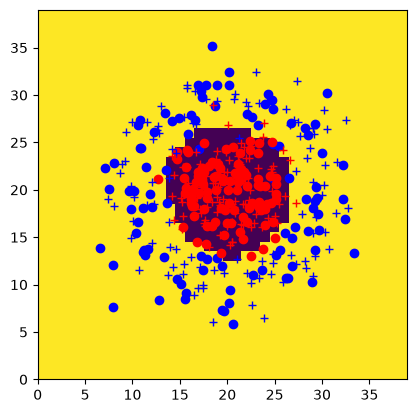

In [111]:
svm = sklearn.svm.SVC(kernel="rbf")
svm.fit(Xtrain, Ytrain)

Ytest_pred = svm.predict(Xtest)
accuracy = np.sum(Ytest == Ytest_pred) / len(Ytest)
print(f"Accuracy : {100 * accuracy:.2f}")
Ygrid_pred = svm.predict(Xgrid)
plot_svm_predictions(data, Ygrid_pred)